In [ ]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

In [ ]:

import torch

print("PyTorch:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
    print("GPU count:", torch.cuda.device_count())
else:
    print("GPU not detected. Check the notebook settings.")


In [ ]:

%cd /kaggle/working

!git clone https://github.com/handw/YOLO-manga-bubble-detector.git



In [ ]:

!git ls-remote https://github.com/handw/YOLO-manga-bubble-detector.git HEAD


In [ ]:
from pathlib import Path

for p in Path("/kaggle/input").rglob("*.zip"):
    print("ZIP found:", p)

In [ ]:
from pathlib import Path

root = Path("/kaggle/input")

print("Does /kaggle/input exist?", root.exists())
print("\nContents of /kaggle/input:")

for p in root.iterdir():
    print("📁" if p.is_dir() else "📄", p.name)

    if p.is_dir():
        for item in list(p.iterdir())[:10]:
            print("   ", item.name)

from pathlib import Path

root = Path("/kaggle/input/datasets/kavyabatra32")

for p in root.rglob("*"):
    if p.is_dir():
        print("📁", p)
    else:
        print("📄", p)

In [ ]:
from pathlib import Path

root = Path("/kaggle/input/datasets/kavyabatra32")

# Find the dataset's key files
for name in ["labels.jsonl", "sequences.json",
             "sample_submission.json", "score.py"]:
    matches = list(root.rglob(name))
    print(f"\n{name}:")
    for p in matches[:5]:
        print(" ", p)

# Find the development and test image folders
print("\nImage folders:")
for p in root.rglob("images"):
    if p.is_dir() and any(x in str(p).lower()
                          for x in ["development", "test"]):
        print(" ", p)

In [ ]:

import json
from pathlib import Path

DATA = Path(
    "/kaggle/input/datasets/kavyabatra32/mangaset/"
    "manga_folder/BYTE ML Task Data"
)

labels_file = DATA / "development" / "labels.jsonl"

print("First 2 label records:\n")

with open(labels_file, "r", encoding="utf-8") as f:
    for i, line in enumerate(f):
        if i == 2:
            break
        record = json.loads(line)
        print(json.dumps(record, indent=2, ensure_ascii=False)[:5000])
        print("\n" + "=" * 50 + "\n")

print("Development sequences:",
      len(list((DATA / "development" / "images").iterdir())))
print("Test sequences:",
      len(list((DATA / "test" / "images").iterdir())))


In [ ]:

import json
from pathlib import Path

DATA = Path(
    "/kaggle/input/datasets/kavyabatra32/mangaset/"
    "manga_folder/BYTE ML Task Data"
)

# Inspect the sequence metadata
with open(DATA / "sequences.json", encoding="utf-8") as f:
    sequences = json.load(f)

print("Sequences metadata type:", type(sequences).__name__)
if isinstance(sequences, dict):
    print("Top-level keys:", list(sequences.keys())[:15])
    print("Sample:", json.dumps(sequences, ensure_ascii=False)[:1800])
elif isinstance(sequences, list):
    print("Number of entries:", len(sequences))
    print("Sample:", json.dumps(sequences[:2], ensure_ascii=False)[:1800])

# Inspect a sample image sequence
for split in ["development", "test"]:
    folders = sorted((DATA / split / "images").iterdir())
    if folders:
        print(f"\n{split} sample:", folders[0].name)
        for img in sorted(folders[0].iterdir()):
            print(" ", img.name, f"{img.stat().st_size / 1024:.1f} KB")


In [ ]:

import torch
from pathlib import Path
import importlib.util

print("CUDA available:", torch.cuda.is_available())
if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

for name in ["inference.py", "models/comictextdetector.pt"]:
    matches = list(
        Path("/kaggle/working").rglob(name)
    )
    print(f"\n{name}:")
    if matches:
        for p in matches[:3]:
            print(" ", p, f"({p.stat().st_size / 1e6:.2f} MB)")
    else:
        print(" Not found in /kaggle/working")

print("\nOCR package availability:")
for package in ["paddleocr", "paddle", "cv2"]:
    print(package, ":", bool(importlib.util.find_spec(package)))


In [ ]:

%pip install -q ultralytics huggingface_hub


In [ ]:

from pathlib import Path
from huggingface_hub import hf_hub_download

MODEL_DIR = Path("/kaggle/working/models")
MODEL_DIR.mkdir(parents=True, exist_ok=True)

weights = hf_hub_download(
    repo_id="ogkalu/comic-speech-bubble-detector-yolov8m",
    filename="comic-speech-bubble-detector.pt",
    local_dir=str(MODEL_DIR),
)

print("Weights downloaded:", weights)
print("Size (MB):", round(Path(weights).stat().st_size / 1e6, 2))


In [ ]:

from pathlib import Path
from ultralytics import YOLO

MODEL_PATH = "/kaggle/working/models/comic-speech-bubble-detector.pt"

model = YOLO(MODEL_PATH)
print("Model loaded successfully!")
print("Class names:", model.names)

DATA = Path(
    "/kaggle/input/datasets/kavyabatra32/mangaset/"
    "manga_folder/BYTE ML Task Data"
)

# Pick one actual development page
page = next(
    (DATA / "development" / "images").glob("*/01.png")
)

print("\nTest page:", page)
results = model.predict(
    source=str(page),
    imgsz=1024,
    conf=0.25,
    verbose=False
)

print("Detections:", len(results[0].boxes))
print("Saved model weights at:", MODEL_PATH)


In [ ]:

from pathlib import Path

pages = sorted((DATA / "development" / "images").glob("*/*.png"))

for page in pages[:5]:
    r = model.predict(
        source=str(page),
        imgsz=1024,
        conf=0.25,
        verbose=False
    )[0]

    counts = {}
    for box in r.boxes:
        name = model.names[int(box.cls.item())]
        counts[name] = counts.get(name, 0) + 1

    print(page.parent.name, page.name, "→", counts)


In [ ]:

from IPython.display import display, Image

result = results[0]
annotated = result.plot()

display(Image(data=__import__("cv2").imencode(
    ".png", annotated
)[1].tobytes()))

print("\nDetection details:")
for box in result.boxes:
    cls_id = int(box.cls.item())
    confidence = float(box.conf.item())
    x1, y1, x2, y2 = map(int, box.xyxy[0].tolist())

    print(
        f"{model.names[cls_id]} | "
        f"confidence={confidence:.2f} | "
        f"box=({x1}, {y1}, {x2}, {y2})"
    )


In [ ]:

from pathlib import Path

pages = sorted((DATA / "development" / "images").glob("*/*.png"))

# Sample pages from different sequences, not just page 1
sample_pages = [p for p in pages if p.name in ("01.png", "02.png", "03.png")]

for page in sample_pages[:9]:
    r = model.predict(
        source=str(page),
        imgsz=1024,
        conf=0.25,
        verbose=False
    )[0]

    counts = {}
    for box in r.boxes:
        name = model.names[int(box.cls.item())]
        counts[name] = counts.get(name, 0) + 1

    print(f"{page.parent.name}/{page.name}: {counts}")


In [ ]:
from pathlib import Path
from PIL import Image
from IPython.display import display
from ultralytics import YOLO

page = DATA / "development" / "images" / "seq_06ec0acde37dffa4" / "01.png"

result = model.predict(
    source=str(page),
    imgsz=1024,
    conf=0.25,
    verbose=False
)[0]

annotated = result.plot()
display(Image.fromarray(annotated[:, :, ::-1]))

In [ ]:
%pip install -q paddleocr paddlepaddle

In [ ]:
import paddle
print("Paddle version:", paddle.__version__)

from paddleocr import PaddleOCR
print("PaddleOCR imported successfully!")

In [ ]:
from paddleocr import PaddleOCR

ocr = PaddleOCR(
    use_doc_orientation_classify=False,
    use_doc_unwarping=False,
    use_textline_orientation=False,
    lang="en"
)

print("OCR model initialized!")

In [ ]:
import cv2
from PIL import Image
from IPython.display import display

page = DATA / "development" / "images" / "seq_06ec0acde37dffa4" / "01.png"

image = cv2.imread(str(page))

result = model.predict(
    source=str(page),
    imgsz=1024,
    conf=0.25,
    verbose=False
)[0]

# Select the highest-confidence detected bubble
boxes = [
    b for b in result.boxes
    if model.names[int(b.cls.item())] == "text_bubble"
]

best = max(boxes, key=lambda b: float(b.conf.item()))
x1, y1, x2, y2 = map(int, best.xyxy[0].tolist())

# Add a small margin around the detected bubble
h, w = image.shape[:2]
pad = 8
x1, y1 = max(0, x1-pad), max(0, y1-pad)
x2, y2 = min(w, x2+pad), min(h, y2+pad)

crop = image[y1:y2, x1:x2]
display(Image.fromarray(cv2.cvtColor(crop, cv2.COLOR_BGR2RGB)))

ocr_result = ocr.predict(crop)

for item in ocr_result:
    print(item)

In [ ]:
from pathlib import Path

DATA = Path(
    "/kaggle/input/datasets/kavyabatra32/mangaset/"
    "manga_folder/BYTE ML Task Data"
)

print("Dataset exists:", DATA.exists())
print("Development folder exists:", (DATA / "development" / "images").exists())

In [ ]:
print("YOLO model loaded:", "model" in globals())
print("OCR initialized:", "ocr" in globals())

In [ ]:
from ultralytics import YOLO

model = YOLO("/kaggle/working/models/comic-speech-bubble-detector.pt")

In [ ]:
%pip install -q ultralytics huggingface_hub

In [ ]:
from pathlib import Path

weights = Path("/kaggle/working/models/comic-speech-bubble-detector.pt")

print("Weights file exists:", weights.exists())

In [ ]:
from pathlib import Path
from huggingface_hub import hf_hub_download

MODEL_DIR = Path("/kaggle/working/models")
MODEL_DIR.mkdir(parents=True, exist_ok=True)

MODEL_PATH = hf_hub_download(
    repo_id="ogkalu/comic-speech-bubble-detector-yolov8m",
    filename="comic-speech-bubble-detector.pt",
    local_dir=str(MODEL_DIR)
)

print("Weights saved at:", MODEL_PATH)
print("File size (MB):", round(Path(MODEL_PATH).stat().st_size / (1024 * 1024), 2))

In [ ]:
from ultralytics import YOLO

model = YOLO(MODEL_PATH)
print("YOLO loaded:", model.names)

In [ ]:
from pathlib import Path

DATA = Path(
    "/kaggle/input/datasets/kavyabatra32/mangaset/"
    "manga_folder/BYTE ML Task Data"
)

print("Dataset exists:", DATA.exists())
print("OCR package available:")

try:
    from paddleocr import PaddleOCR
    print("PaddleOCR imported successfully!")
except Exception as e:
    print(type(e).__name__, e)

In [ ]:
from paddleocr import PaddleOCR

ocr = PaddleOCR(
    use_doc_orientation_classify=False,
    use_doc_unwarping=False,
    use_textline_orientation=False,
    lang="en"
)

print("OCR initialized!")

In [ ]:
import cv2
from PIL import Image
from IPython.display import display

page = DATA / "development" / "images" / "seq_06ec0acde37dffa4" / "01.png"

image = cv2.imread(str(page))

result = model.predict(
    source=str(page),
    imgsz=1024,
    conf=0.25,
    verbose=False
)[0]

boxes = [
    b for b in result.boxes
    if model.names[int(b.cls.item())] == "text_bubble"
]

best = max(boxes, key=lambda b: float(b.conf.item()))
x1, y1, x2, y2 = map(int, best.xyxy[0].tolist())

h, w = image.shape[:2]
pad = 8
x1, y1 = max(0, x1 - pad), max(0, y1 - pad)
x2, y2 = min(w, x2 + pad), min(h, y2 + pad)

crop = image[y1:y2, x1:x2]

display(Image.fromarray(cv2.cvtColor(crop, cv2.COLOR_BGR2RGB)))

ocr_result = ocr.predict(crop)

for item in ocr_result:
    print(item)

In [ ]:
import os

os.environ["FLAGS_use_mkldnn"] = "0"
os.environ["FLAGS_enable_pir_api"] = "0"

print("Inference compatibility flags set.")

In [ ]:
import os

os.environ["FLAGS_use_mkldnn"] = "0"
os.environ["FLAGS_enable_pir_api"] = "0"

print("Inference compatibility flags set.")

In [ ]:
from paddleocr import PaddleOCR

ocr = PaddleOCR(
    use_doc_orientation_classify=False,
    use_doc_unwarping=False,
    use_textline_orientation=False,
    lang="en"
)

ocr_result = ocr.predict(crop)

for item in ocr_result:
    print(item)

In [ ]:
%pip install -q easyocr

In [ ]:
import easyocr
print("EasyOCR imported successfully!")

In [ ]:
reader = easyocr.Reader(["en"], gpu=True)
print("EasyOCR ready!")

In [ ]:
ocr_results = reader.readtext(crop)

for bbox, text, confidence in ocr_results:
    print(f"Text: {text} | Confidence: {confidence:.3f}")

In [ ]:

import cv2
from pathlib import Path
from PIL import Image
from IPython.display import display

# Locate one sample manga page
page = DATA / "development" / "images" / "seq_06ec0acde37dffa4" / "01.png"

# Load the image
image = cv2.imread(str(page))
assert image is not None, f"Could not load image: {page}"

# Detect speech bubbles using our existing YOLO model
result = model.predict(
    source=str(page),
    imgsz=1024,
    conf=0.25,
    verbose=False
)[0]

# Keep only speech-bubble detections
boxes = [
    b for b in result.boxes
    if model.names[int(b.cls.item())] == "text_bubble"
]

assert boxes, "No speech bubbles detected on this page."

# Select the largest detected speech bubble
best = max(
    boxes,
    key=lambda b: (
        float(b.xyxy[0][2] - b.xyxy[0][0]) *
        float(b.xyxy[0][3] - b.xyxy[0][1])
    )
)

x1, y1, x2, y2 = map(int, best.xyxy[0].tolist())

# Add a little padding around the bubble
h, w = image.shape[:2]
pad = 8
x1, y1 = max(0, x1-pad), max(0, y1-pad)
x2, y2 = min(w, x2+pad), min(h, y2+pad)

crop = image[y1:y2, x1:x2]

print("Crop created:", crop.shape)
display(Image.fromarray(cv2.cvtColor(crop, cv2.COLOR_BGR2RGB)))


In [ ]:
%pip install -q ultralytics huggingface_hub

In [ ]:
%pip install -q easyocr

In [ ]:
from pathlib import Path

weights = Path("/kaggle/working/models/comic-speech-bubble-detector.pt")

print("Weights file exists:", weights.exists())

In [ ]:

import cv2
from pathlib import Path
from PIL import Image
from IPython.display import display

# Locate one sample manga page
page = DATA / "development" / "images" / "seq_06ec0acde37dffa4" / "01.png"

# Load the image
image = cv2.imread(str(page))
assert image is not None, f"Could not load image: {page}"

# Detect speech bubbles using our existing YOLO model
result = model.predict(
    source=str(page),
    imgsz=1024,
    conf=0.25,
    verbose=False
)[0]

# Keep only speech-bubble detections
boxes = [
    b for b in result.boxes
    if model.names[int(b.cls.item())] == "text_bubble"
]

assert boxes, "No speech bubbles detected on this page."

# Select the largest detected speech bubble
best = max(
    boxes,
    key=lambda b: (
        float(b.xyxy[0][2] - b.xyxy[0][0]) *
        float(b.xyxy[0][3] - b.xyxy[0][1])
    )
)

x1, y1, x2, y2 = map(int, best.xyxy[0].tolist())

# Add a little padding around the bubble
h, w = image.shape[:2]
pad = 8
x1, y1 = max(0, x1-pad), max(0, y1-pad)
x2, y2 = min(w, x2+pad), min(h, y2+pad)

crop = image[y1:y2, x1:x2]

print("Crop created:", crop.shape)
display(Image.fromarray(cv2.cvtColor(crop, cv2.COLOR_BGR2RGB)))


In [ ]:

from pathlib import Path

DATA = Path(
    "/kaggle/input/datasets/kavyabatra32/mangaset/manga_folder/BYTE ML Task Data"
)

print("Dataset exists:", DATA.exists())
print("Dataset contents:")
print([p.name for p in DATA.iterdir()] if DATA.exists() else "Path not found")


In [ ]:

%pip install -q ultralytics huggingface_hub


In [ ]:

from pathlib import Path
from huggingface_hub import hf_hub_download
from ultralytics import YOLO

MODEL_DIR = Path("/kaggle/working/models")
MODEL_DIR.mkdir(parents=True, exist_ok=True)

MODEL_PATH = hf_hub_download(
    repo_id="ogkalu/comic-speech-bubble-detector-yolov8m",
    filename="comic-speech-bubble-detector.pt",
    local_dir=str(MODEL_DIR)
)

model = YOLO(MODEL_PATH)

print("Detector loaded!")
print("Classes:", model.names)


In [ ]:

import cv2
from PIL import Image
from IPython.display import display

page = DATA / "development" / "images" / "seq_06ec0acde37dffa4" / "01.png"

image = cv2.imread(str(page))
assert image is not None, f"Image not found: {page}"

result = model.predict(
    source=str(page),
    imgsz=1024,
    conf=0.25,
    verbose=False
)[0]

boxes = [
    b for b in result.boxes
    if model.names[int(b.cls.item())] == "text_bubble"
]

assert boxes, "No speech bubbles detected!"

best = max(
    boxes,
    key=lambda b: (
        float(b.xyxy[0][2] - b.xyxy[0][0]) *
        float(b.xyxy[0][3] - b.xyxy[0][1])
    )
)

x1, y1, x2, y2 = map(int, best.xyxy[0].tolist())

h, w = image.shape[:2]
pad = 8
x1, y1 = max(0, x1 - pad), max(0, y1 - pad)
x2, y2 = min(w, x2 + pad), min(h, y2 + pad)

crop = image[y1:y2, x1:x2]

print("Crop created successfully:", crop.shape)
display(Image.fromarray(cv2.cvtColor(crop, cv2.COLOR_BGR2RGB)))


In [ ]:

%pip install -q easyocr


In [ ]:

import easyocr

reader = easyocr.Reader(["en"], gpu=True)
print("EasyOCR is ready!")


In [ ]:

ocr_results = reader.readtext(crop)

for bbox, text, confidence in ocr_results:
    print(f"Text: {text} | Confidence: {confidence:.3f}")


In [ ]:

import cv2
import numpy as np
from PIL import Image
from IPython.display import display

# Convert the bubble crop to grayscale
gray = cv2.cvtColor(crop, cv2.COLOR_BGR2GRAY)

# Enlarge it 3x for small manga lettering
gray = cv2.resize(
    gray, None,
    fx=3, fy=3,
    interpolation=cv2.INTER_CUBIC
)

# Improve contrast
gray = cv2.equalizeHist(gray)

# Add a white border so letters near the edges aren't cut off
processed = cv2.copyMakeBorder(
    gray, 30, 30, 30, 30,
    cv2.BORDER_CONSTANT,
    value=255
)

display(Image.fromarray(processed))


In [ ]:

# Compare original crop and processed crop
original_result = reader.readtext(crop, detail=0, paragraph=True)
processed_result = reader.readtext(processed, detail=0, paragraph=True)

print("ORIGINAL:", original_result)
print("PREPROCESSED:", processed_result)


In [ ]:

%pip install -q pytesseract
!apt-get update -qq && apt-get install -y -qq tesseract-ocr


In [ ]:

import pytesseract
from PIL import Image

# Use the original bubble crop, enlarged for recognition
rgb_crop = cv2.cvtColor(crop, cv2.COLOR_BGR2RGB)
large_crop = cv2.resize(
    rgb_crop, None,
    fx=3, fy=3,
    interpolation=cv2.INTER_CUBIC
)

print(pytesseract.image_to_string(large_crop, config="--psm 6"))


In [ ]:

# Try EasyOCR with paragraph grouping enabled
ocr_results = reader.readtext(
    processed,
    detail=1,
    paragraph=True
)

print(ocr_results)


In [ ]:

import cv2
import pytesseract
from pathlib import Path

# Test pages from three development sequences
test_pages = [
    DATA / "development/images/seq_032cbb4dc8686963/01.png",
    DATA / "development/images/seq_032cbb4dc8686963/02.png",
    DATA / "development/images/seq_06ec0acde37dffa4/01.png",
]

for page in test_pages:
    image = cv2.imread(str(page))
    if image is None:
        print(f"\nCould not load: {page}")
        continue

    result = model.predict(
        source=str(page), imgsz=1024, conf=0.25, verbose=False
    )[0]

    bubbles = [
        b for b in result.boxes
        if model.names[int(b.cls.item())] == "text_bubble"
    ]

    # Sort approximately top-to-bottom for readable inspection
    bubbles.sort(key=lambda b: (
        float(b.xyxy[0][1]), float(b.xyxy[0][0])
    ))

    print(f"\n{'='*65}\nPAGE: {page.parent.name}/{page.name}")
    print(f"Detected bubbles: {len(bubbles)}")

    for i, b in enumerate(bubbles[:4], start=1):
        x1, y1, x2, y2 = map(int, b.xyxy[0].tolist())
        h, w = image.shape[:2]
        pad = 8
        x1, y1 = max(0, x1-pad), max(0, y1-pad)
        x2, y2 = min(w, x2+pad), min(h, y2+pad)

        crop = image[y1:y2, x1:x2]
        enlarged = cv2.resize(
            crop, None, fx=3, fy=3,
            interpolation=cv2.INTER_CUBIC
        )
        text = pytesseract.image_to_string(
            enlarged, config="--psm 6"
        ).strip().replace("\n", " | ")

        print(f"{i}. {text}")


In [ ]:

import sys
import importlib.metadata as md

print("Python:", sys.version)

for package in ["paddlepaddle", "paddleocr", "paddlex", "numpy"]:
    try:
        print(f"{package}: {md.version(package)}")
    except md.PackageNotFoundError:
        print(f"{package}: not installed")


In [ ]:

import paddle
import numpy as np

print("Paddle:", paddle.__version__)
print("NumPy:", np.__version__)
print("Paddle device:", paddle.device.get_device())

x = paddle.to_tensor([1.0, 2.0, 3.0])
print("Tensor test:", x.numpy())


In [ ]:

from PIL import Image, ImageDraw
import numpy as np

img = Image.new("RGB", (800, 200), "white")
draw = ImageDraw.Draw(img)
draw.text((30, 60), "THE FISH WILL BE PREPARED HERE.", fill="black")

test_image = np.array(img)

result = ocr.predict(test_image)
print(result)


In [ ]:

from paddleocr import PaddleOCR

ocr = PaddleOCR(
    use_doc_orientation_classify=False,
    use_doc_unwarping=False,
    use_textline_orientation=False,
    lang="en",
    enable_mkldnn=False
)

print("PaddleOCR initialized with oneDNN disabled!")


In [ ]:

result = ocr.predict(test_image)
print(result)


In [ ]:

from pathlib import Path
from PIL import Image
import matplotlib.pyplot as plt

# Find one development page
page_path = next(
    (DATA / "development" / "images").glob("seq_*/*.png")
)

page = Image.open(page_path).convert("RGB")
detections = model.predict(
    str(page_path),
    imgsz=1024,
    conf=0.25,
    verbose=False
)[0]

print("Page:", page_path.name)
print("Image size:", page.size)
print("Detected regions:", len(detections.boxes))


In [ ]:

import matplotlib.pyplot as plt
from PIL import Image

page_array = __import__("numpy").array(page)

annotated = detections.plot()
plt.figure(figsize=(10, 14))
plt.imshow(annotated[..., ::-1])  # YOLO plots in BGR
plt.axis("off")
plt.title("YOLO text-region detections")
plt.show()

print("Detected boxes:", len(detections.boxes))
print("Class names:", detections.names)


In [ ]:

import numpy as np
from PIL import Image
from IPython.display import display

page_array = np.array(page)
regions = []

for i, box in enumerate(detections.boxes):
    x1, y1, x2, y2 = map(int, box.xyxy[0].cpu().tolist())

    # Keep crop coordinates within image boundaries
    h, w = page_array.shape[:2]
    x1, x2 = max(0, x1), min(w, x2)
    y1, y2 = max(0, y1), min(h, y2)

    if x2 <= x1 or y2 <= y1:
        continue

    crop = page_array[y1:y2, x1:x2]
    result = ocr.predict(crop)

    texts = result[0].get("rec_texts", [])
    scores = result[0].get("rec_scores", [])

    regions.append({
        "box": (x1, y1, x2, y2),
        "text": " ".join(texts),
        "scores": scores
    })

    print(f"Region {i + 1}: {' '.join(texts) or '[No text recognized]'}")
    print("  Confidence:", [round(float(s), 3) for s in scores])

    display(Image.fromarray(crop))


In [ ]:

import json

labels_path = DATA / "development" / "labels.jsonl"

with labels_path.open("r", encoding="utf-8") as f:
    first_label = json.loads(next(f))

print("Label keys:", first_label.keys())
print(json.dumps(first_label, indent=2)[:4000])
print("\nTested page:", page_path)


In [ ]:

import json

target_sequence = page_path.parent.name
print("Target sequence:", target_sequence)

matching_label = None

with labels_path.open("r", encoding="utf-8") as f:
    for line in f:
        record = json.loads(line)
        if record["sequence_id"] == target_sequence:
            matching_label = record
            break

if matching_label is None:
    print("No matching label found!")
else:
    for page_idx, annotations in enumerate(matching_label["pages"], start=1):
        print(f"\nPAGE {page_idx} — {len(annotations)} annotations")
        for item in annotations:
            print(f'[{item["speaker"]}] {item["text"]}')


In [ ]:

import json
import re
import numpy as np
from difflib import SequenceMatcher
from pathlib import Path

target_dir = DATA / "development" / "images" / target_sequence
page_ocr_results = []

def normalize(text):
    text = text.upper().replace("-", " ")
    return re.sub(r"[^A-Z0-9]+", " ", text).strip()

for page_num in range(1, 4):
    image_path = target_dir / f"{page_num:02d}.png"
    image = np.array(Image.open(image_path).convert("RGB"))

    prediction = model.predict(
        str(image_path), imgsz=1024, conf=0.25, verbose=False
    )[0]

    regions = []
    for box in prediction.boxes:
        x1, y1, x2, y2 = map(int, box.xyxy[0].cpu().tolist())
        h, w = image.shape[:2]
        x1, x2 = max(0, x1), min(w, x2)
        y1, y2 = max(0, y1), min(h, y2)

        if x2 <= x1 or y2 <= y1:
            continue

        crop = image[y1:y2, x1:x2]
        result = ocr.predict(crop)[0]
        text = " ".join(result.get("rec_texts", []))
        if text.strip():
            regions.append(text)

    page_ocr_results.append(regions)

with labels_path.open("r", encoding="utf-8") as f:
    label_record = next(
        r for r in map(json.loads, f)
        if r["sequence_id"] == target_sequence
    )

for page_idx, (regions, annotations) in enumerate(
    zip(page_ocr_results, label_record["pages"]), start=1
):
    print(f"\n{'='*18} PAGE {page_idx} {'='*18}")
    print(f"Detected OCR regions: {len(regions)} | Ground-truth lines: {len(annotations)}")

    for item in annotations:
        gt = item["text"]
        best_region = max(
            regions,
            key=lambda r: SequenceMatcher(
                None, normalize(gt), normalize(r)
            ).ratio(),
            default=""
        )
        score = SequenceMatcher(
            None, normalize(gt), normalize(best_region)
        ).ratio()

        print(f"\nGT:  {gt}")
        print(f"OCR: {best_region}")
        print(f"Similarity: {score:.0%} | Speaker: {item['speaker']}")


In [ ]:
print("Dataset:", DATA.exists())
print("YOLO loaded:", "model" in globals())
print("PaddleOCR loaded:", "ocr" in globals())
print("Labels loaded:", labels_path.exists())

In [ ]:

import json
from pathlib import Path

# Load all development annotations
with labels_path.open("r", encoding="utf-8") as f:
    all_labels = [json.loads(line) for line in f if line.strip()]

# Skip the sequence we already inspected
previously_tested = "seq_88c1ad85c0fc1e9a"

validation_records = [
    record for record in all_labels
    if record["sequence_id"] != previously_tested
][:5]

# Verify that all three page images exist
for record in validation_records:
    seq_id = record["sequence_id"]
    seq_dir = DATA / "development" / "images" / seq_id

    pages = [
        seq_dir / f"{i:02d}.png"
        for i in range(1, 4)
    ]

    exists = [p.exists() for p in pages]
    gt_lines = sum(len(page) for page in record["pages"])

    print(
        seq_id,
        "| images:", exists,
        "| annotated lines:", gt_lines
    )

print("\nSequences selected:", len(validation_records))


In [ ]:

from difflib import SequenceMatcher
import numpy as np
from PIL import Image

def normalize(text):
    import re
    text = text.upper().replace("-", " ")
    return re.sub(r"[^A-Z0-9]+", " ", text).strip()

validation_results = []

for record in validation_records:
    seq_id = record["sequence_id"]
    seq_dir = DATA / "development" / "images" / seq_id

    print(f"\nProcessing {seq_id}")

    for page_idx in range(1, 4):
        image_path = seq_dir / f"{page_idx:02d}.png"
        image = np.array(Image.open(image_path).convert("RGB"))

        pred = model.predict(
            str(image_path),
            imgsz=1024,
            conf=0.25,
            verbose=False
        )[0]

        regions = []
        h, w = image.shape[:2]

        for box in pred.boxes:
            x1, y1, x2, y2 = map(
                int, box.xyxy[0].cpu().tolist()
            )
            x1, x2 = max(0, x1), min(w, x2)
            y1, y2 = max(0, y1), min(h, y2)

            if x2 <= x1 or y2 <= y1:
                continue

            crop = image[y1:y2, x1:x2]
            result = ocr.predict(crop)[0]
            text = " ".join(result.get("rec_texts", []))

            if text.strip():
                regions.append(text)

        gt_lines = record["pages"][page_idx - 1]
        validation_results.append({
            "sequence_id": seq_id,
            "page": page_idx,
            "regions": regions,
            "annotations": gt_lines
        })

        print(
            f"  Page {page_idx}: "
            f"{len(regions)} OCR regions, "
            f"{len(gt_lines)} annotated lines"
        )

print("\nOCR run complete!")


In [ ]:

from scipy.optimize import linear_sum_assignment
from difflib import SequenceMatcher
import numpy as np

all_gt = 0
all_regions = 0
matched_75 = 0
matched_50 = 0
similarity_sum = 0.0
similarity_count = 0

for item in validation_results:
    regions = item["regions"]
    annotations = item["annotations"]

    all_gt += len(annotations)
    all_regions += len(regions)

    if not annotations or not regions:
        print(
            item["sequence_id"], f"page {item['page']}:",
            f"{len(annotations)} GT, {len(regions)} OCR regions"
        )
        continue

    scores = np.zeros((len(annotations), len(regions)))

    for i, ann in enumerate(annotations):
        for j, region in enumerate(regions):
            scores[i, j] = SequenceMatcher(
                None,
                normalize(ann["text"]),
                normalize(region)
            ).ratio()

    gt_idx, reg_idx = linear_sum_assignment(-scores)

    sims = [scores[i, j] for i, j in zip(gt_idx, reg_idx)]
    matched_75 += sum(s >= 0.75 for s in sims)
    matched_50 += sum(s >= 0.50 for s in sims)
    similarity_sum += sum(sims)
    similarity_count += len(sims)

print("\n========== VALIDATION SUMMARY ==========")
print("Pages evaluated:", len(validation_results))
print("Ground-truth lines:", all_gt)
print("OCR regions:", all_regions)
print("One-to-one matches with similarity >= 75%:", matched_75)
print("One-to-one matches with similarity >= 50%:", matched_50)
print(
    "Average similarity of assigned pairs:",
    f"{similarity_sum / similarity_count:.1%}"
    if similarity_count else "N/A"
)
print(
    "75% line coverage:",
    f"{matched_75 / all_gt:.1%}" if all_gt else "N/A"
)


In [ ]:

from difflib import SequenceMatcher
from scipy.optimize import linear_sum_assignment
import numpy as np

for item in validation_results:
    regions = item["regions"]
    annotations = item["annotations"]
    seq_id = item["sequence_id"]
    page = item["page"]

    if not annotations:
        if regions:
            print(f"\nOCR text with no annotations — {seq_id}, page {page}:")
            for r in regions:
                print("  OCR:", r)
        continue

    if not regions:
        for ann in annotations:
            print(f"\nMISSED OCR — {seq_id}, page {page}:")
            print("  GT:", ann["text"])
        continue

    scores = np.array([
        [
            SequenceMatcher(
                None,
                normalize(ann["text"]),
                normalize(region)
            ).ratio()
            for region in regions
        ]
        for ann in annotations
    ])

    gt_idx, region_idx = linear_sum_assignment(-scores)
    matched_gt = set()
    matched_regions = set()

    for i, j in zip(gt_idx, region_idx):
        if scores[i, j] >= 0.75:
            matched_gt.add(i)
            matched_regions.add(j)
        else:
            print(f"\nLOW SIMILARITY ({scores[i, j]:.0%}) — {seq_id}, page {page}")
            print("  GT: ", annotations[i]["text"])
            print("  OCR:", regions[j])

    for i, ann in enumerate(annotations):
        if i not in matched_gt:
            print(f"\nUNMATCHED GT — {seq_id}, page {page}:")
            print("  ", ann["text"])

    for j, region in enumerate(regions):
        if j not in matched_regions:
            print(f"\nUNMATCHED OCR — {seq_id}, page {page}:")
            print("  ", region)


In [ ]:

from PIL import Image
import matplotlib.pyplot as plt

seq_id = "seq_2032620aa4e4ac7f"
image_path = DATA / "development" / "images" / seq_id / "01.png"

result = model.predict(
    str(image_path),
    imgsz=1024,
    conf=0.25,
    verbose=False
)[0]

annotated = result.plot()
plt.figure(figsize=(12, 16))
plt.imshow(annotated[:, :, ::-1])
plt.axis("off")
plt.show()

print("Detected regions:", len(result.boxes))


In [ ]:

image_path = DATA / "development" / "images" / "seq_2032620aa4e4ac7f" / "01.png"

for size in [1024, 1536]:
    result = model.predict(
        str(image_path),
        imgsz=size,
        conf=0.15,
        verbose=False
    )[0]

    print(f"\nResolution: {size}")
    print("Detected regions:", len(result.boxes))
    print("Classes:", [
        model.names[int(box.cls[0])]
        for box in result.boxes
    ])


In [ ]:

import matplotlib.pyplot as plt

result = model.predict(
    str(image_path),
    imgsz=1536,
    conf=0.15,
    verbose=False
)[0]

plt.figure(figsize=(10, 14))
plt.imshow(result.plot()[:, :, ::-1])
plt.axis("off")
plt.show()

print("\nDetection details:")
for i, box in enumerate(result.boxes):
    coords = [round(v, 1) for v in box.xyxy[0].cpu().tolist()]
    confidence = round(float(box.conf[0]), 3)
    label = model.names[int(box.cls[0])]
    print(i, label, "confidence:", confidence, "box:", coords)


In [ ]:

from PIL import Image
import matplotlib.pyplot as plt
from ultralytics import YOLO

image_path = DATA / "development" / "images" / "seq_2032620aa4e4ac7f" / "01.png"
image = Image.open(image_path).convert("RGB")

W, H = image.size
tile_size = 640
overlap = 160
step = tile_size - overlap

tiles = []
for y in range(0, H, step):
    for x in range(0, W, step):
        x2 = min(x + tile_size, W)
        y2 = min(y + tile_size, H)
        x1 = max(0, x2 - tile_size)
        y1 = max(0, y2 - tile_size)
        tiles.append((x1, y1, x2, y2))

found = []

for tile_no, (x1, y1, x2, y2) in enumerate(tiles):
    crop = image.crop((x1, y1, x2, y2))
    result = model.predict(
        crop,
        imgsz=1024,
        conf=0.10,
        verbose=False
    )[0]

    for box in result.boxes:
        bx1, by1, bx2, by2 = box.xyxy[0].cpu().tolist()
        found.append({
            "class": model.names[int(box.cls[0])],
            "confidence": round(float(box.conf[0]), 3),
            "box": (
                round(bx1 + x1), round(by1 + y1),
                round(bx2 + x1), round(by2 + y1)
            ),
            "tile": tile_no
        })

print("Image size:", image.size)
print("Tiles tested:", len(tiles))
print("Total detections before duplicate removal:", len(found))

fig, axes = plt.subplots(1, len(tiles), figsize=(4 * len(tiles), 6))
if len(tiles) == 1:
    axes = [axes]

for ax, (x1, y1, x2, y2) in zip(axes, tiles):
    ax.imshow(image.crop((x1, y1, x2, y2)))
    ax.set_title(f"Tile ({x1}, {y1})")
    ax.axis("off")

plt.tight_layout()
plt.show()


In [ ]:

for i, item in enumerate(found):
    x1, y1, x2, y2 = item["box"]
    crop = image.crop((x1, y1, x2, y2))

    result = ocr.predict(crop)[0]
    texts = result.get("rec_texts", [])
    scores = result.get("rec_scores", [])

    print(
        f"{i:02d} | {item['class']} | "
        f"det={item['confidence']:.2f} | "
        f"tile={item['tile']} | "
        f"OCR={' '.join(texts)} | "
        f"OCR scores={[round(float(s), 2) for s in scores]}"
    )


In [ ]:

import numpy as np

for i, item in enumerate(found):
    x1, y1, x2, y2 = item["box"]
    crop = image.crop((x1, y1, x2, y2))

    # Convert PIL image to a NumPy RGB array for PaddleOCR
    crop_array = np.array(crop)

    results = ocr.predict(crop_array)

    if not results:
        print(f"{i:02d} | No OCR result | box={item['box']}")
        continue

    result = results[0]
    texts = result.get("rec_texts", [])
    scores = result.get("rec_scores", [])

    print(
        f"{i:02d} | {item['class']} | "
        f"det={item['confidence']:.2f} | "
        f"tile={item['tile']} | "
        f"OCR={' '.join(texts)} | "
        f"OCR scores={[round(float(s), 2) for s in scores]}"
    )


In [ ]:

from pathlib import Path

score_path = DATA / "score.py"

print("Score script exists:", score_path.exists())

if score_path.exists():
    print("\n" + "=" * 25 + " SCORE.PY " + "=" * 25)
    print(score_path.read_text(encoding="utf-8"))
else:
    print("Could not find score.py at:", score_path)
    print("\nFiles in the dataset directory:")
    for p in DATA.iterdir():
        print(p.name)


In [ ]:

import json
from collections import Counter

labels_path = DATA / "development" / "labels.jsonl"

total_sequences = 0
total_lines = 0
speaker_counts = Counter()
unknown_count = 0
page_line_counts = Counter()

with labels_path.open(encoding="utf-8") as f:
    for line in f:
        if not line.strip():
            continue

        record = json.loads(line)
        total_sequences += 1

        for page_number, page in enumerate(record["pages"], start=1):
            page_line_counts[len(page)] += 1

            for item in page:
                total_lines += 1
                speaker = item["speaker"]
                speaker_counts[speaker] += 1

                if speaker == "UNKNOWN":
                    unknown_count += 1

print("Development sequences:", total_sequences)
print("Annotated lines:", total_lines)
print("Lines with UNKNOWN speaker:", unknown_count)
print("Speaker-label counts:")
for speaker, count in speaker_counts.most_common():
    print(f"  {speaker}: {count}")


In [ ]:

import json

sequences_path = DATA / "sequences.json"

with sequences_path.open(encoding="utf-8") as f:
    sequences = json.load(f)

print("Sequence metadata type:", type(sequences).__name__)

if isinstance(sequences, dict):
    print("Top-level keys:", list(sequences.keys())[:15])
    records = sequences.get("sequences", sequences)
    if isinstance(records, dict):
        records = list(records.values())
else:
    records = sequences

print("Sequence records:", len(records))
print("\nExample record:")
print(json.dumps(records[0], indent=2)[:2500])


In [ ]:

import json
import random
from pathlib import Path

# Read the sequence metadata
sequences_path = DATA / "sequences.json"

with sequences_path.open(encoding="utf-8") as f:
    records = json.load(f)

# Separate the official development and test sequences
dev_ids = sorted(
    row["sequence_id"]
    for row in records
    if row["split"] == "development"
)

test_ids = sorted(
    row["sequence_id"]
    for row in records
    if row["split"] == "test"
)

# Reproducible 64/16 split
rng = random.Random(42)
shuffled = dev_ids.copy()
rng.shuffle(shuffled)

train_ids = sorted(shuffled[:64])
val_ids = sorted(shuffled[64:])

# Save the split so we can reuse it
split_info = {
    "seed": 42,
    "train_sequence_ids": train_ids,
    "validation_sequence_ids": val_ids,
    "official_test_sequence_ids": test_ids,
}

split_path = Path("/kaggle/working/split_info.json")
split_path.write_text(
    json.dumps(split_info, indent=2),
    encoding="utf-8"
)

print("Training sequences:", len(train_ids))
print("Validation sequences:", len(val_ids))
print("Official test sequences:", len(test_ids))
print("Train/validation overlap:", len(set(train_ids) & set(val_ids)))
print("Saved to:", split_path)


In [ ]:

import json
import numpy as np
from PIL import Image
from pathlib import Path

baseline_path = Path("/kaggle/working/validation_baseline.jsonl")
total_regions = 0

with baseline_path.open("w", encoding="utf-8") as out:
    for seq_num, seq_id in enumerate(val_ids, start=1):
        seq_dir = DATA / "development" / "images" / seq_id

        for page_idx in range(1, 4):
            image_path = seq_dir / f"{page_idx:02d}.png"
            image = np.array(
                Image.open(image_path).convert("RGB")
            )
            h, w = image.shape[:2]

            pred = model.predict(
                str(image_path),
                imgsz=1024,
                conf=0.25,
                verbose=False
            )[0]

            regions = []

            for box in pred.boxes:
                x1, y1, x2, y2 = map(
                    int, box.xyxy[0].cpu().tolist()
                )

                x1, x2 = max(0, x1), min(w, x2)
                y1, y2 = max(0, y1), min(h, y2)

                if x2 <= x1 or y2 <= y1:
                    continue

                crop = image[y1:y2, x1:x2]
                result = ocr.predict(crop)[0]
                texts = result.get("rec_texts", [])
                text = " ".join(texts).strip()

                if not text:
                    continue

                regions.append({
                    "bbox": [x1, y1, x2, y2],
                    "text": text,
                    "detection_confidence": float(
                        box.conf[0].cpu().item()
                    )
                })

            # Keep all detected regions; reading order comes later.
            out.write(json.dumps({
                "sequence_id": seq_id,
                "page": page_idx,
                "regions": regions
            }, ensure_ascii=False) + "\n")

            total_regions += len(regions)

        print(f"[{seq_num}/{len(val_ids)}] Finished {seq_id}")

print("\nBaseline extraction complete!")
print("Validation sequences:", len(val_ids))
print("Pages processed:", len(val_ids) * 3)
print("Text regions extracted:", total_regions)
print("Saved to:", baseline_path)


In [ ]:

import json

baseline_path = "/kaggle/working/validation_baseline.jsonl"
labels_path = DATA / "development" / "labels.jsonl"

with open(baseline_path, encoding="utf-8") as f:
    baseline_rows = [json.loads(line) for line in f if line.strip()]

with open(labels_path, encoding="utf-8") as f:
    label_rows = [json.loads(line) for line in f if line.strip()]

print("Baseline pages:", len(baseline_rows))
print("Ground-truth sequences:", len(label_rows))

print("\nBASELINE EXAMPLE")
print(json.dumps(baseline_rows[0], indent=2, ensure_ascii=False)[:2500])

print("\nGROUND-TRUTH EXAMPLE")
print(json.dumps(label_rows[0], indent=2, ensure_ascii=False)[:2500])


In [ ]:

import re
from difflib import SequenceMatcher

def normalize_text(text):
    text = text.upper().replace("-", " ")
    return re.sub(r"[^A-Z0-9]+", " ", text).strip()

# Index annotations by sequence and page
labels_by_id = {
    row["sequence_id"]: row
    for row in label_rows
}

baseline_by_page = {
    (row["sequence_id"], row["page"]): row["regions"]
    for row in baseline_rows
}

for seq_id in val_ids[:3]:
    print(f"\n{'=' * 65}\n{seq_id}")

    gt_record = labels_by_id[seq_id]

    for page_idx, gt_lines in enumerate(gt_record["pages"], start=1):
        regions = baseline_by_page.get((seq_id, page_idx), [])

        print(f"\nPage {page_idx}: {len(gt_lines)} labelled lines, "
              f"{len(regions)} OCR regions")

        # Show the best OCR match for each labelled line
        for gt in gt_lines[:5]:
            gt_text = normalize_text(gt["text"])

            best = max(
                regions,
                key=lambda r: SequenceMatcher(
                    None, gt_text, normalize_text(r["text"])
                ).ratio(),
                default=None
            )

            if best is None:
                print(f"  GT [{gt['speaker']}]: {gt['text']}")
                print("    No OCR regions")
                continue

            similarity = SequenceMatcher(
                None, gt_text, normalize_text(best["text"])
            ).ratio()

            print(f"  GT [{gt['speaker']}]: {gt['text']}")
            print(f"    Best OCR ({similarity:.0%}): {best['text']}")


In [ ]:

from difflib import SequenceMatcher
import re

def norm_align(text):
    text = text.upper().replace("-", " ")
    return re.sub(r"[^A-Z0-9]+", " ", text).strip()

def similarity(a, b):
    return SequenceMatcher(
        None, norm_align(a), norm_align(b)
    ).ratio()

alignment_stats = {
    "strong": 0,
    "medium": 0,
    "weak": 0,
    "unmatched_gt": 0,
    "unmatched_ocr": 0
}

for seq_id in val_ids:
    gt_record = labels_by_id[seq_id]

    for page_idx, gt_lines in enumerate(gt_record["pages"], start=1):
        regions = baseline_by_page.get((seq_id, page_idx), [])

        # Score every possible GT/OCR pair
        pairs = []
        for gi, gt in enumerate(gt_lines):
            for ri, region in enumerate(regions):
                score = similarity(gt["text"], region["text"])
                pairs.append((score, gi, ri))

        # Greedy one-to-one matching, strongest matches first
        pairs.sort(reverse=True)
        used_gt, used_ocr = set(), set()
        matches = {}

        for score, gi, ri in pairs:
            if gi in used_gt or ri in used_ocr:
                continue
            if score < 0.60:
                continue

            used_gt.add(gi)
            used_ocr.add(ri)
            matches[gi] = (ri, score)

        for gi, gt in enumerate(gt_lines):
            if gi not in matches:
                alignment_stats["unmatched_gt"] += 1
                continue

            ri, score = matches[gi]
            if score >= 0.90:
                alignment_stats["strong"] += 1
            elif score >= 0.75:
                alignment_stats["medium"] += 1
            else:
                alignment_stats["weak"] += 1

        alignment_stats["unmatched_ocr"] += len(regions) - len(used_ocr)

print("Alignment summary across validation:")
for name, count in alignment_stats.items():
    print(f"{name}: {count}")


In [ ]:

import json
from collections import Counter

labels_by_id = {
    row["sequence_id"]: row
    for row in label_rows
}

train_stats = Counter()

for seq_id in train_ids:
    record = labels_by_id[seq_id]

    for page in record["pages"]:
        for line in page:
            train_stats["total_lines"] += 1

            if line["speaker"] != "UNKNOWN":
                train_stats["known_speaker_lines"] += 1

            train_stats[f"speaker:{line['speaker']}"] += 1

print("Training sequences:", len(train_ids))
print("Total annotated lines:", train_stats["total_lines"])
print("Lines with known speakers:", train_stats["known_speaker_lines"])
print("UNKNOWN lines:", train_stats["speaker:UNKNOWN"])
print("\nSpeaker distribution:")

for key, count in train_stats.items():
    if key.startswith("speaker:") and key != "speaker:UNKNOWN":
        print(f"  {key.removeprefix('speaker:')}: {count}")


In [ ]:

import json
from pathlib import Path

train_examples = []

for seq_id in train_ids:
    record = labels_by_id[seq_id]

    # Give each sequence its own local speaker vocabulary.
    speakers = sorted({
        line["speaker"]
        for page in record["pages"]
        for line in page
        if line["speaker"] not in ("UNKNOWN", "NARRATION")
    })

    for page_idx, page in enumerate(record["pages"], start=1):
        for line_idx, line in enumerate(page):
            speaker = line["speaker"]

            # Keep narration separate; exclude unknown speaker labels.
            if speaker == "UNKNOWN":
                continue

            train_examples.append({
                "sequence_id": seq_id,
                "page": page_idx,
                "line_index": line_idx,
                "text": line["text"],
                "speaker": speaker,
                "is_narration": speaker == "NARRATION",
                "local_speakers": speakers
            })

output_path = Path("/kaggle/working/train_dialogue_examples.jsonl")

with output_path.open("w", encoding="utf-8") as f:
    for example in train_examples:
        f.write(json.dumps(example, ensure_ascii=False) + "\n")

print("Training examples:", len(train_examples))
print("Sequences represented:", len(set(x["sequence_id"] for x in train_examples)))
print("Saved to:", output_path)
print("\nExample:")
print(json.dumps(train_examples[0], indent=2, ensure_ascii=False))


In [ ]:

represented_ids = {
    example["sequence_id"]
    for example in train_examples
}

missing_ids = sorted(set(train_ids) - represented_ids)

print("Training sequences without examples:", missing_ids)

for seq_id in missing_ids:
    record = labels_by_id[seq_id]
    lines = [
        line
        for page in record["pages"]
        for line in page
    ]

    print("Total annotations:", len(lines))
    print("Speaker counts:", {
        speaker: sum(line["speaker"] == speaker for line in lines)
        for speaker in sorted({line["speaker"] for line in lines})
    })


In [ ]:

import torch
import sklearn

print("PyTorch:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())
print("scikit-learn:", sklearn.__version__)


In [ ]:

from collections import Counter
from itertools import combinations

training_pairs = []

for seq_id in train_ids:
    record = labels_by_id[seq_id]

    lines = [
        line
        for page in record["pages"]
        for line in page
        if line["speaker"] != "UNKNOWN"
        and line["text"].strip()
    ]

    # Compare lines only within the same sequence.
    for a, b in combinations(lines, 2):
        same_speaker = int(a["speaker"] == b["speaker"])

        training_pairs.append({
            "sequence_id": seq_id,
            "text_a": a["text"],
            "text_b": b["text"],
            "speaker_a": a["speaker"],
            "speaker_b": b["speaker"],
            "same_speaker": same_speaker
        })

pair_counts = Counter(p["same_speaker"] for p in training_pairs)

print("Training pairs:", len(training_pairs))
print("Same-speaker pairs:", pair_counts[1])
print("Different-speaker pairs:", pair_counts[0])
print("Sequences represented:", len(set(
    p["sequence_id"] for p in training_pairs
)))
print("Example:", training_pairs[0])


In [ ]:

import re
from difflib import SequenceMatcher

def pair_features(text_a, text_b):
    a = text_a.upper().strip()
    b = text_b.upper().strip()

    words_a = set(re.findall(r"\b[A-Z0-9']+\b", a))
    words_b = set(re.findall(r"\b[A-Z0-9']+\b", b))

    union = words_a | words_b
    intersection = words_a & words_b

    return [
        SequenceMatcher(None, a, b).ratio(),
        len(intersection) / max(len(union), 1),
        len(a),
        len(b),
        abs(len(a) - len(b)),
        len(words_a),
        len(words_b),
        int(a.startswith("(") or a.startswith("[") or
            a.endswith("...")),
        int(b.startswith("(") or b.startswith("[") or
            b.endswith("...")),
    ]

X_preview = pair_features(
    training_pairs[0]["text_a"],
    training_pairs[0]["text_b"]
)

print("Number of features:", len(X_preview))
print("Feature values:", X_preview)


In [ ]:

import numpy as np
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, roc_auc_score
)

# Build feature matrix and labels.
X = np.asarray([
    pair_features(p["text_a"], p["text_b"])
    for p in training_pairs
], dtype=np.float32)

y = np.asarray([
    p["same_speaker"] for p in training_pairs
], dtype=np.int64)

# Split by sequence, never by individual pair.
rng = np.random.RandomState(42)
shuffled_ids = np.array(train_ids.copy())
rng.shuffle(shuffled_ids)

fit_ids = set(shuffled_ids[:51])
eval_ids = set(shuffled_ids[51:])

fit_mask = np.array([
    p["sequence_id"] in fit_ids for p in training_pairs
])
eval_mask = np.array([
    p["sequence_id"] in eval_ids for p in training_pairs
])

speaker_model = make_pipeline(
    StandardScaler(),
    LogisticRegression(
        class_weight="balanced",
        max_iter=2000,
        random_state=42
    )
)

speaker_model.fit(X[fit_mask], y[fit_mask])

pred = speaker_model.predict(X[eval_mask])
prob = speaker_model.predict_proba(X[eval_mask])[:, 1]

print("Fit sequences:", len(fit_ids))
print("Evaluation sequences:", len(eval_ids))
print("Evaluation pairs:", int(eval_mask.sum()))
print("Accuracy:", round(accuracy_score(y[eval_mask], pred), 3))
print("Precision:", round(precision_score(y[eval_mask], pred), 3))
print("Recall:", round(recall_score(y[eval_mask], pred), 3))
print("F1:", round(f1_score(y[eval_mask], pred), 3))
print("ROC-AUC:", round(roc_auc_score(y[eval_mask], prob), 3))


In [ ]:

import json
from pathlib import Path
from PIL import Image
import matplotlib.pyplot as plt

seq_id = train_ids[0]
record = labels_by_id[seq_id]

print("Sequence:", seq_id)
print("\nGround-truth annotations:")
for page_num, page in enumerate(record["pages"], start=1):
    print(f"\nPage {page_num}:")
    for line in page:
        print(f"  [{line['speaker']}] {line['text']}")

image_path = DATA / "development" / "images" / seq_id / "01.png"
display(Image.open(image_path))


In [ ]:

from paddleocr import PaddleOCR

ocr = PaddleOCR(
    use_doc_orientation_classify=False,
    use_doc_unwarping=False,
    use_textline_orientation=False,
    lang="en"
)

print("PaddleOCR initialized successfully!")


In [ ]:

from pathlib import Path
from PIL imNext step: inspect the actual detection outputs
We already have the YOLO detector and PaddleOCR pipeline working. Let's use them to see whether we can automatically generate useful training examples for the visual model.

Run this cell in Kaggle to display the actual first-page detection results:port Image
import matplotlib.pyplot as plt

seq_id = "seq_032cbb4dc8686963"
image_path = (
    DATA / "development" / "images" / seq_id / "01.png"
)

image = Image.open(image_path).convert("RGB")
print("Image size:", image.size)

plt.figure(figsize=(10, 14))
plt.imshow(image)
plt.axis("off")
plt.show()


In [ ]:

from pathlib import Path
from PIL import Image
import matplotlib.pyplot as plt

seq_id = "seq_032cbb4dc8686963"

image_path = DATA / "development" / "images" / seq_id / "01.png"

image = Image.open(image_path).convert("RGB")

print("Image size:", image.size)

plt.figure(figsize=(10, 14))
plt.imshow(image)
plt.axis("off")
plt.show()


In [ ]:

import matplotlib.pyplot as plt
import matplotlib.patches as patches

result = model.predict(
    str(image_path),
    imgsz=1024,
    conf=0.25,
    verbose=False
)[0]

fig, ax = plt.subplots(figsize=(10, 14))
ax.imshow(image)

for i, box in enumerate(result.boxes):
    x1, y1, x2, y2 = map(
        int, box.xyxy[0].cpu().tolist()
    )
    confidence = float(box.conf[0].cpu().item())

    rect = patches.Rectangle(
        (x1, y1),
        x2 - x1,
        y2 - y1,
        linewidth=1.5,
        edgecolor="lime",
        facecolor="none"
    )
    ax.add_patch(rect)
    ax.text(
        x1, max(0, y1 - 5),
        f"{i}: {confidence:.2f}",
        color="black",
        fontsize=8,
        bbox=dict(facecolor="lime", alpha=0.8)
    )

ax.axis("off")
plt.show()

print("Detected regions:", len(result.boxes))


In [ ]:

from paddleocr import PaddleOCR

ocr = PaddleOCR(
    use_doc_orientation_classify=False,
    use_doc_unwarping=False,
    use_textline_orientation=False,
    lang="en",
    enable_mkldnn=False
)

for i, box in enumerate(result.boxes):
    x1, y1, x2, y2 = map(
        int, box.xyxy[0].cpu().tolist()
    )
    confidence = float(box.conf[0].cpu().item())

    crop = image.crop((x1, y1, x2, y2))
    ocr_result = ocr.predict(crop)[0]
    text = " ".join(ocr_result.get("rec_texts", [])).strip()

    print(
        f"Box {i:02d} | "
        f"confidence={confidence:.3f} | "
        f"bbox=({x1},{y1},{x2},{y2}) | "
        f"text={text!r}"
    )


In [ ]:

import numpy as np

for i, box in enumerate(result.boxes):
    x1, y1, x2, y2 = map(
        int, box.xyxy[0].cpu().tolist()
    )
    confidence = float(box.conf[0].cpu().item())

    # Crop using NumPy rather than PIL
    crop = np.array(image)[y1:y2, x1:x2]

    if crop.size == 0:
        print(f"Box {i:02d}: empty crop, skipped")
        continue

    ocr_results = ocr.predict(crop)

    if not ocr_results:
        print(f"Box {i:02d}: no OCR result")
        continue

    text = " ".join(
        ocr_results[0].get("rec_texts", [])
    ).strip()

    print(
        f"Box {i:02d} | "
        f"confidence={confidence:.3f} | "
        f"bbox=({x1},{y1},{x2},{y2}) | "
        f"text={text!r}"
    )


In [ ]:

%pip install -q anime-face-detector


In [ ]:

from anime_face_detector import create_detector

print("Anime face detector imported successfully!")


In [ ]:

import cv2
from anime_face_detector import create_detector

face_detector = create_detector(
    "yolov3",
    device="cuda:0"
)

image_bgr = cv2.imread(str(image_path))
face_results = face_detector(image_bgr)

print("Detected faces:", len(face_results))

for i, face in enumerate(face_results):
    x1, y1, x2, y2, confidence = face["bbox"]
    print(
        f"Face {i}: "
        f"confidence={confidence:.3f}, "
        f"bbox=({x1:.0f}, {y1:.0f}, {x2:.0f}, {y2:.0f})"
    )


In [ ]:

from PIL import Image
import matplotlib.pyplot as plt

image_rgb = Image.open(image_path).convert("RGB")

fig, axes = plt.subplots(
    1, len(face_results),
    figsize=(4 * len(face_results), 5)
)

if len(face_results) == 1:
    axes = [axes]

face_crops = []

for i, face in enumerate(face_results):
    x1, y1, x2, y2, confidence = face["bbox"]
    x1, y1, x2, y2 = map(
        int, [x1, y1, x2, y2]
    )

    crop = image_rgb.crop((x1, y1, x2, y2))
    face_crops.append(crop)

    axes[i].imshow(crop)
    axes[i].set_title(
        f"Face {i} | confidence={confidence:.3f}"
    )
    axes[i].axis("off")

plt.tight_layout()
plt.show()

print("Face crops created:", len(face_crops))


In [ ]:

from pathlib import Path
import json

crop_dir = Path("/kaggle/working/face_training_data")
crop_dir.mkdir(parents=True, exist_ok=True)

# Corrected labels for the three real detector outputs
face_speakers = {
    0: "character1",
    1: "character2",
    2: "character2"
}

manifest = []

for i, crop in enumerate(face_crops):
    speaker = face_speakers[i]
    filename = f"{seq_id}_page1_face{i}.png"
    crop_path = crop_dir / filename
    crop.save(crop_path)

    manifest.append({
        "sequence_id": seq_id,
        "page": 1,
        "face_index": i,
        "speaker": speaker,
        "image_path": str(crop_path)
    })

manifest_path = crop_dir / "manifest.jsonl"

with manifest_path.open("w", encoding="utf-8") as f:
    for item in manifest:
        f.write(json.dumps(item) + "\n")

print("Saved face crops:", len(manifest))
print("Character 1 crops:", sum(
    x["speaker"] == "character1" for x in manifest
))
print("Character 2 crops:", sum(
    x["speaker"] == "character2" for x in manifest
))
print("Manifest:", manifest_path)


In [ ]:

import json
import cv2
from pathlib import Path
from tqdm.auto import tqdm

face_data_dir = Path("/kaggle/working/visual_speaker_data")
face_data_dir.mkdir(parents=True, exist_ok=True)

crop_dir = face_data_dir / "face_crops"
crop_dir.mkdir(parents=True, exist_ok=True)

face_records = []

for train_seq in tqdm(train_ids, desc="Training sequences"):
    for page_num in (1, 2, 3):
        page_path = (
            DATA / "development" / "images"
            / train_seq / f"{page_num:02d}.png"
        )

        if not page_path.exists():
            continue

        img_bgr = cv2.imread(str(page_path))
        detections = face_detector(img_bgr)

        for face_idx, face in enumerate(detections):
            x1, y1, x2, y2, confidence = face["bbox"]
            x1, y1, x2, y2 = map(
                int, [x1, y1, x2, y2]
            )

            h, w = img_bgr.shape[:2]
            x1, x2 = max(0, x1), min(w, x2)
            y1, y2 = max(0, y1), min(h, y2)

            if x2 <= x1 or y2 <= y1:
                continue

            crop = img_bgr[y1:y2, x1:x2]
            filename = (
                f"{train_seq}_p{page_num}_f{face_idx}.jpg"
            )
            crop_path = crop_dir / filename

            if not cv2.imwrite(str(crop_path), crop):
                continue

            face_records.append({
                "sequence_id": train_seq,
                "page": page_num,
                "face_index": face_idx,
                "bbox": [x1, y1, x2, y2],
                "confidence": float(confidence),
                "image_path": str(crop_path)
            })

manifest_path = face_data_dir / "detected_faces.jsonl"

with manifest_path.open("w", encoding="utf-8") as f:
    for item in face_records:
        f.write(json.dumps(item) + "\n")

print("Training sequences:", len(train_ids))
print("Detected face crops:", len(face_records))
print("Sequences with detected faces:", len({
    r["sequence_id"] for r in face_records
}))
print("Saved manifest:", manifest_path)


In [ ]:

import json
from pathlib import Path
from collections import Counter

face_data_dir = Path("/kaggle/working/visual_speaker_data")
manifest_path = face_data_dir / "detected_faces.jsonl"

with manifest_path.open(encoding="utf-8") as f:
    detected_faces = [
        json.loads(line)
        for line in f if line.strip()
    ]

faces_per_sequence = Counter(
    row["sequence_id"] for row in detected_faces
)

print("Total face crops:", len(detected_faces))
print("Training sequences:", len(train_ids))
print("Sequences with faces:", len(faces_per_sequence))
print("Sequences without detected faces:",
      len(set(train_ids) - set(faces_per_sequence)))

print("\nFaces per sequence:")
for seq_id in train_ids[:10]:
    print(seq_id, "→", faces_per_sequence.get(seq_id, 0))

print("\nExample detection:")
if detected_faces:
    print(detected_faces[0])


In [ ]:

import json
from pathlib import Path
from collections import Counter

baseline_path = Path("/kaggle/working/validation_baseline.jsonl")

with baseline_path.open(encoding="utf-8") as f:
    validation_ocr = [
        json.loads(line)
        for line in f if line.strip()
    ]

print("Validation OCR records:", len(validation_ocr))
print("Validation sequences:", len({
    row["sequence_id"] for row in validation_ocr
}))
print("Training sequences:", len(train_ids))

# The validation file should NOT be used as training data.
print(
    "Validation IDs overlap training IDs:",
    len(
        {row["sequence_id"] for row in validation_ocr}
        & set(train_ids)
    )
)


In [ ]:
from pathlib import Path

paths = [
    Path("/kaggle/input/datasets/kavyabatra32/mangaset/manga_folder/BYTE ML Task Data"),
    Path("/kaggle/working/split_info.json"),
    Path("/kaggle/working/visual_speaker_data/detected_faces.jsonl"),
    Path("/kaggle/working/visual_speaker_data/face_crops"),
    Path("/kaggle/working/validation_baseline.jsonl"),
]

for p in paths:
    print(("✅ FOUND  " if p.exists() else "❌ MISSING"), p)
    if p.is_dir() and p.name == "face_crops":
        print("   Face crops saved:", sum(1 for f in p.iterdir() if f.is_file()))

In [ ]:
import json
from pathlib import Path
from sklearn.model_selection import train_test_split

DATA = Path(
    "/kaggle/input/datasets/kavyabatra32/mangaset/manga_folder/BYTE ML Task Data"
)

with (DATA / "sequences.json").open(encoding="utf-8") as f:
    records = json.load(f)

with (DATA / "development/labels.jsonl").open(encoding="utf-8") as f:
    labels = [json.loads(line) for line in f if line.strip()]

dev_ids = sorted({row["sequence_id"] for row in labels})
all_ids = {row["sequence_id"] for row in records}

train_ids, val_ids = train_test_split(
    dev_ids,
    test_size=0.2,
    random_state=42
)

train_ids = sorted(train_ids)
val_ids = sorted(val_ids)

split_info = {
    "train_ids": train_ids,
    "val_ids": val_ids,
    "test_ids": sorted(all_ids - set(dev_ids)),
    "seed": 42
}

split_path = Path("/kaggle/working/split_info.json")
split_path.write_text(json.dumps(split_info, indent=2), encoding="utf-8")

labels_by_id = {row["sequence_id"]: row for row in labels}

print("Development sequences:", len(dev_ids))
print("Training sequences:", len(train_ids))
print("Validation sequences:", len(val_ids))
print("Test sequences:", len(split_info["test_ids"]))
print("Train/validation overlap:", len(set(train_ids) & set(val_ids)))
print("Split saved:", split_path.exists())

In [ ]:
import json
from pathlib import Path
from sklearn.model_selection import train_test_split

DATA = Path(
    "/kaggle/input/datasets/kavyabatra32/mangaset/"
    "manga_folder/BYTE ML Task Data"
)

labels_path = DATA / "development" / "labels.jsonl"

with labels_path.open(encoding="utf-8") as f:
    labels = [json.loads(line) for line in f if line.strip()]

labels_by_id = {r["sequence_id"]: r for r in labels}

dev_image_ids = {
    p.name for p in (DATA / "development" / "images").iterdir()
    if p.is_dir()
}
test_ids = sorted(
    p.name for p in (DATA / "test" / "images").iterdir()
    if p.is_dir()
)

dev_ids = sorted(labels_by_id.keys())

print("Annotated development sequences:", len(dev_ids))
print("Development image folders:", len(dev_image_ids))
print("Test sequences:", len(test_ids))
print("Labels without image folders:", len(set(dev_ids) - dev_image_ids))
print("Image folders without labels:", len(dev_image_ids - set(dev_ids)))

In [ ]:
import json
from pathlib import Path
from sklearn.model_selection import train_test_split

train_ids, val_ids = train_test_split(
    sorted(labels_by_id.keys()),
    test_size=0.2,
    random_state=42
)

train_ids = sorted(train_ids)
val_ids = sorted(val_ids)

split_info = {
    "train_ids": train_ids,
    "val_ids": val_ids,
    "test_ids": test_ids,
    "seed": 42
}

split_path = Path("/kaggle/working/split_info.json")
split_path.write_text(
    json.dumps(split_info, indent=2),
    encoding="utf-8"
)

print("Training:", len(train_ids))
print("Validation:", len(val_ids))
print("Test:", len(test_ids))
print("Overlap:", len(set(train_ids) & set(val_ids)))
print("Saved:", split_path.exists())

In [ ]:
%pip install -q anime-face-detector

import cv2
from anime_face_detector import create_detector

face_detector = create_detector("yolov3", device="cuda:0")
print("Face detector loaded successfully!")

In [ ]:
import cv2
from pathlib import Path

DATA = Path(
    "/kaggle/input/datasets/kavyabatra32/mangaset/"
    "manga_folder/BYTE ML Task Data"
)

# Pick one page from the first training sequence
seq_id = train_ids[0]
image_path = DATA / "development" / "images" / seq_id / "01.png"

image_bgr = cv2.imread(str(image_path))
assert image_bgr is not None, f"Could not read: {image_path}"

face_results = face_detector(image_bgr)

print("Sequence:", seq_id)
print("Image dimensions:", image_bgr.shape)
print("Detected faces:", len(face_results))

for i, face in enumerate(face_results):
    print(i, face.get("bbox"))

In [ ]:
import matplotlib.pyplot as plt
import matplotlib.patches as patches

fig, ax = plt.subplots(figsize=(10, 12))
ax.imshow(cv2.cvtColor(image_bgr, cv2.COLOR_BGR2RGB))

for i, face in enumerate(face_results):
    x1, y1, x2, y2, conf = map(float, face["bbox"])

    # Clip box coordinates to image boundaries
    h, w = image_bgr.shape[:2]
    x1, x2 = max(0, x1), min(w, x2)
    y1, y2 = max(0, y1), min(h, y2)

    rect = patches.Rectangle(
        (x1, y1), x2 - x1, y2 - y1,
        linewidth=2, edgecolor="red", facecolor="none"
    )
    ax.add_patch(rect)
    ax.text(
        x1, max(0, y1 - 5),
        f"{i}: {conf:.2f}",
        color="yellow", fontsize=10,
        bbox=dict(facecolor="black", alpha=0.7)
    )

ax.set_title(f"Face detections — {seq_id}, page 1")
ax.axis("off")
plt.show()

In [ ]:
from pathlib import Path
from PIL import Image

crop_dir = Path("/kaggle/working/face_crop_test")
crop_dir.mkdir(parents=True, exist_ok=True)

h, w = image_bgr.shape[:2]
saved = 0

for i, face in enumerate(face_results):
    x1, y1, x2, y2, conf = map(float, face["bbox"])

    if conf < 0.50:
        continue

    x1 = max(0, min(w, int(x1)))
    x2 = max(0, min(w, int(x2)))
    y1 = max(0, min(h, int(y1)))
    y2 = max(0, min(h, int(y2)))

    if x2 <= x1 or y2 <= y1:
        continue

    crop = cv2.cvtColor(
        image_bgr[y1:y2, x1:x2],
        cv2.COLOR_BGR2RGB
    )

    Image.fromarray(crop).save(crop_dir / f"face_{i}.png")
    print(f"Saved face_{i}.png | confidence={conf:.3f}")
    saved += 1

print("Total saved:", saved)

In [ ]:
import matplotlib.pyplot as plt
from PIL import Image
from pathlib import Path

crop_files = sorted(crop_dir.glob("*.png"))

fig, axes = plt.subplots(
    1, len(crop_files),
    figsize=(4 * len(crop_files), 5)
)

for ax, path in zip(axes, crop_files):
    ax.imshow(Image.open(path))
    ax.set_title(path.name)
    ax.axis("off")

plt.tight_layout()
plt.show()

In [ ]:
import json

for seq_id in train_ids[:2]:
    record = labels_by_id[seq_id]

    print("\nSequence:", seq_id)
    print("Available fields:", list(record.keys()))
    print(json.dumps(record, ensure_ascii=False, indent=2)[:2500])

In [ ]:
from collections import Counter

speaker_counts = Counter()
sequences_per_speaker = Counter()
pages_per_sequence = []

for seq_id in train_ids:
    record = labels_by_id[seq_id]
    seen_speakers = set()

    for page in record["pages"]:
        for line in page:
            speaker = line["speaker"]
            speaker_counts[speaker] += 1
            if speaker not in {"UNKNOWN", "NARRATION"}:
                seen_speakers.add(speaker)

    sequences_per_speaker.update(seen_speakers)
    pages_per_sequence.append(len(record["pages"]))

print("Training sequences:", len(train_ids))
print("Pages per sequence:", Counter(pages_per_sequence))
print("\nDialogue-line counts:")
for speaker, count in speaker_counts.most_common():
    print(f"{speaker}: {count}")

print("\nSequences containing each local speaker ID:")
for speaker, count in sorted(sequences_per_speaker.items()):
    print(f"{speaker}: {count}")

In [ ]:
from collections import Counter

page_speaker_counts = Counter()
sequences_with_speaker_on_multiple_pages = Counter()

for seq_id in train_ids:
    record = labels_by_id[seq_id]
    pages_seen = {}

    for page_idx, page in enumerate(record["pages"]):
        speakers_on_page = set()

        for line in page:
            speaker = line["speaker"]
            if speaker not in {"UNKNOWN", "NARRATION"}:
                page_speaker_counts[(page_idx + 1, speaker)] += 1
                speakers_on_page.add(speaker)

        for speaker in speakers_on_page:
            pages_seen.setdefault(speaker, set()).add(page_idx + 1)

    for speaker, pages in pages_seen.items():
        if len(pages) >= 2:
            sequences_with_speaker_on_multiple_pages[speaker] += 1

print("Dialogue lines by page:")
for page_idx in range(1, 4):
    print(f"\nPage {page_idx}")
    for speaker in sorted(
        {s for p, s in page_speaker_counts if p == page_idx}
    ):
        print(f"  {speaker}: {page_speaker_counts[(page_idx, speaker)]}")

print("\nSequences where each local speaker label occurs on multiple pages:")
for speaker, count in sorted(sequences_with_speaker_on_multiple_pages.items()):
    print(f"{speaker}: {count}")

In [ ]:
import json

seq_id = "seq_06ec0acde37dffa4"
record = labels_by_id[seq_id]

for page_idx, page in enumerate(record["pages"], start=1):
    print(f"\n{'=' * 15} PAGE {page_idx} {'=' * 15}")

    for line_idx, line in enumerate(page, start=1):
        print(
            f"{line_idx:02d}. "
            f"[{line['speaker']}] {line['text']}"
        )

In [ ]:
import cv2
import json
from pathlib import Path
from PIL import Image

DATA = Path(
    "/kaggle/input/datasets/kavyabatra32/mangaset/"
    "manga_folder/BYTE ML Task Data"
)

OUT = Path("/kaggle/working/visual_speaker_data")
CROP_DIR = OUT / "face_crops"
CROP_DIR.mkdir(parents=True, exist_ok=True)

manifest_path = OUT / "detected_faces.jsonl"

CONF_THRESHOLD = 0.50
manifest = []
skipped = 0

for seq_num, seq_id in enumerate(train_ids, start=1):
    for page_num in range(1, 4):
        image_path = (
            DATA / "development" / "images"
            / seq_id / f"{page_num:02d}.png"
        )

        image = cv2.imread(str(image_path))
        if image is None:
            print("Missing image:", image_path)
            skipped += 1
            continue

        h, w = image.shape[:2]
        detections = face_detector(image)

        for face_idx, detection in enumerate(detections):
            x1, y1, x2, y2, conf = map(float, detection["bbox"])

            if conf < CONF_THRESHOLD:
                continue

            x1 = max(0, min(w, int(x1)))
            x2 = max(0, min(w, int(x2)))
            y1 = max(0, min(h, int(y1)))
            y2 = max(0, min(h, int(y2)))

            if x2 <= x1 or y2 <= y1:
                continue

            crop = cv2.cvtColor(
                image[y1:y2, x1:x2],
                cv2.COLOR_BGR2RGB
            )

            crop_name = (
                f"{seq_id}_p{page_num:02d}_f{face_idx:02d}.png"
            )
            crop_path = CROP_DIR / crop_name
            Image.fromarray(crop).save(crop_path)

            manifest.append({
                "sequence_id": seq_id,
                "page": page_num,
                "face_index": face_idx,
                "bbox": [x1, y1, x2, y2],
                "confidence": conf,
                "crop_path": str(crop_path)
            })

    if seq_num % 8 == 0:
        print(f"Processed {seq_num}/{len(train_ids)} training sequences")

with manifest_path.open("w", encoding="utf-8") as f:
    for row in manifest:
        f.write(json.dumps(row) + "\n")

print("\nFinished")
print("Training sequences:", len(train_ids))
print("Face crops saved:", len(manifest))
print("Images skipped:", skipped)
print("Manifest:", manifest_path)

In [ ]:
print("Face detector:", "loaded" if "face_detector" in globals() else "missing")
print("Bubble detector:", "loaded" if "model" in globals() else "missing")
print("PaddleOCR:", "loaded" if "ocr" in globals() else "missing")
print("Face crops:", len(manifest))

In [ ]:
%pip install -q ultralytics huggingface_hub paddleocr paddlepaddle

from pathlib import Path
from huggingface_hub import hf_hub_download
from ultralytics import YOLO

MODEL_DIR = Path("/kaggle/working/models")
MODEL_DIR.mkdir(parents=True, exist_ok=True)

MODEL_PATH = hf_hub_download(
    repo_id="ogkalu/comic-speech-bubble-detector-yolov8m",
    filename="comic-speech-bubble-detector.pt",
    local_dir=str(MODEL_DIR)
)

model = YOLO(MODEL_PATH)
print("Bubble detector restored:", model.names)

In [ ]:
from paddleocr import PaddleOCR

ocr = PaddleOCR(
    use_doc_orientation_classify=False,
    use_doc_unwarping=False,
    use_textline_orientation=False,
    lang="en",
    enable_mkldnn=False
)

print("PaddleOCR initialized with compatibility settings.")

In [ ]:
import cv2
import json
from pathlib import Path

DATA = Path(
    "/kaggle/input/datasets/kavyabatra32/mangaset/"
    "manga_folder/BYTE ML Task Data"
)

OUT = Path("/kaggle/working/visual_speaker_data")
OUT.mkdir(parents=True, exist_ok=True)

results_path = OUT / "training_bubble_ocr.jsonl"

with results_path.open("w", encoding="utf-8") as f:
    for seq_num, seq_id in enumerate(train_ids, start=1):
        for page_num in range(1, 4):
            image_path = (
                DATA / "development" / "images"
                / seq_id / f"{page_num:02d}.png"
            )

            image = cv2.imread(str(image_path))
            if image is None:
                raise FileNotFoundError(image_path)

            h, w = image.shape[:2]

            prediction = model.predict(
                str(image_path),
                imgsz=1024,
                conf=0.25,
                verbose=False
            )[0]

            bubbles = []

            if prediction.boxes is not None:
                for box in prediction.boxes:
                    x1, y1, x2, y2 = map(
                        float, box.xyxy[0].cpu().tolist()
                    )
                    cls_id = int(box.cls[0].item())
                    conf = float(box.conf[0].item())

                    x1 = max(0, min(w, int(x1)))
                    x2 = max(0, min(w, int(x2)))
                    y1 = max(0, min(h, int(y1)))
                    y2 = max(0, min(h, int(y2)))

                    if x2 <= x1 or y2 <= y1:
                        continue

                    crop = image[y1:y2, x1:x2]
                    recognized = ocr.predict(crop)

                    texts = []
                    if recognized:
                        for result in recognized:
                            if isinstance(result, dict):
                                texts.extend(result.get("rec_texts", []))

                    bubbles.append({
                        "bbox": [x1, y1, x2, y2],
                        "class_id": cls_id,
                        "confidence": conf,
                        "texts": texts
                    })

            f.write(json.dumps({
                "sequence_id": seq_id,
                "page": page_num,
                "bubbles": bubbles
            }, ensure_ascii=False) + "\n")

        if seq_num % 8 == 0:
            print(f"Processed {seq_num}/{len(train_ids)} sequences")

print("Saved:", results_path)

In [ ]:
import json
from pathlib import Path
from collections import Counter

path = Path("/kaggle/working/visual_speaker_data/training_bubble_ocr.jsonl")

records = [json.loads(line) for line in path.open(encoding="utf-8")]

print("Pages processed:", len(records))
print("Total detected regions:", sum(len(r["bubbles"]) for r in records))
print("Regions with recognized text:", sum(
    bool(b["texts"])
    for r in records
    for b in r["bubbles"]
))
print("Regions by class:", Counter(
    b["class_id"]
    for r in records
    for b in r["bubbles"]
))
print("\nExample record:")
print(json.dumps(records[0], ensure_ascii=False, indent=2)[:2500])

In [ ]:
import json
import re
import string
from pathlib import Path
from difflib import SequenceMatcher

OUT = Path("/kaggle/working/visual_speaker_data")

def normalize(text):
    text = text.upper()
    text = re.sub(r"[^A-Z0-9']", " ", text)
    return " ".join(text.split())

ocr_by_page = {}
for record in records:
    key = (record["sequence_id"], record["page"])
    ocr_by_page[key] = record["bubbles"]

matches = []
stats = {"pages": 0, "gt_lines": 0, "matched": 0}

for seq_id in train_ids:
    gt_pages = labels_by_id[seq_id]["pages"]

    for page_idx, gt_lines in enumerate(gt_pages, start=1):
        stats["pages"] += 1
        bubbles = ocr_by_page.get((seq_id, page_idx), [])

        bubble_texts = [
            " ".join(b["texts"])
            for b in bubbles
            if b["class_id"] == 0 and b["texts"]
        ]

        for line in gt_lines:
            gt_text = line.get("text", "")
            stats["gt_lines"] += 1
            target = normalize(gt_text)

            best_score = 0
            best_bubble = None

            if target:
                for bubble_idx, detected_text in enumerate(bubble_texts):
                    candidate = normalize(detected_text)
                    score = SequenceMatcher(
                        None, target, candidate
                    ).ratio()

                    if score > best_score:
                        best_score = score
                        best_bubble = bubble_idx

            is_match = best_score >= 0.55
            if is_match:
                stats["matched"] += 1

            matches.append({
                "sequence_id": seq_id,
                "page": page_idx,
                "speaker": line.get("speaker", "UNKNOWN"),
                "ground_truth_text": gt_text,
                "matched_bubble_index": best_bubble if is_match else None,
                "match_score": round(best_score, 3),
                "matched": is_match
            })

match_path = OUT / "ocr_text_matches.jsonl"
with match_path.open("w", encoding="utf-8") as f:
    for row in matches:
        f.write(json.dumps(row, ensure_ascii=False) + "\n")

print("Pages:", stats["pages"])
print("Ground-truth lines:", stats["gt_lines"])
print("Candidate matches:", stats["matched"])
print("Match rate:", round(stats["matched"] / max(stats["gt_lines"], 1), 3))
print("Saved:", match_path)

In [ ]:
from collections import Counter, defaultdict
import json
from pathlib import Path

# Group candidate matches by sequence and page.
groups = defaultdict(list)

for row in matches:
    if row["matched"]:
        key = (row["sequence_id"], row["page"])
        groups[key].append(row)

total = 0
unique_text_matches = 0
reused_bubbles = 0
speaker_counts = Counter()

for key, rows in groups.items():
    bubble_usage = Counter(
        row["matched_bubble_index"] for row in rows
    )

    total += len(rows)
    unique_text_matches += sum(
        bubble_usage[row["matched_bubble_index"]] == 1
        for row in rows
    )
    reused_bubbles += sum(
        count > 1 for count in bubble_usage.values()
    )

    for row in rows:
        speaker_counts[row["speaker"]] += 1

print("Candidate matches:", total)
print("Matches using uniquely assigned bubbles:", unique_text_matches)
print("Pages with reused bubble assignments:", reused_bubbles)
print("\nSpeaker label counts:")
for speaker, count in speaker_counts.most_common():
    print(f"{speaker}: {count}")

In [ ]:
import json
from pathlib import Path
from collections import defaultdict

OUT = Path("/kaggle/working/visual_speaker_data")

faces_by_page = defaultdict(list)
for face in manifest:
    key = (face["sequence_id"], face["page"])
    faces_by_page[key].append(face)

bubbles_by_page = {
    (record["sequence_id"], record["page"]): record["bubbles"]
    for record in records
}

def center(box):
    x1, y1, x2, y2 = box
    return ((x1 + x2) / 2, (y1 + y2) / 2)

def intersection_over_bubble(face_box, bubble_box):
    fx1, fy1, fx2, fy2 = face_box
    bx1, by1, bx2, by2 = bubble_box

    ix = max(0, min(fx2, bx2) - max(fx1, bx1))
    iy = max(0, min(fy2, by2) - max(fy1, by1))
    area = max(1, (bx2 - bx1) * (by2 - by1))
    return (ix * iy) / area

candidates = []

for row in matches:
    if not row["matched"] or row["speaker"] in ("UNKNOWN", "NARRATION"):
        continue

    key = (row["sequence_id"], row["page"])
    bubble_list = bubbles_by_page.get(key, [])
    face_list = faces_by_page.get(key, [])

    idx = row["matched_bubble_index"]
    if idx is None or idx >= len([
        b for b in bubble_list
        if b["class_id"] == 0 and b["texts"]
    ]):
        continue

    speech_bubbles = [
        b for b in bubble_list
        if b["class_id"] == 0 and b["texts"]
    ]
    bubble = speech_bubbles[idx]
    bx, by = center(bubble["bbox"])

    ranked_faces = []
    for face in face_list:
        fx, fy = center(face["bbox"])
        distance = ((fx - bx) ** 2 + (fy - by) ** 2) ** 0.5
        ranked_faces.append({
            "face_index": face["face_index"],
            "distance": round(distance, 2),
            "overlap": round(
                intersection_over_bubble(face["bbox"], bubble["bbox"]), 3
            )
        })

    ranked_faces.sort(key=lambda x: x["distance"])

    candidates.append({
        "sequence_id": row["sequence_id"],
        "page": row["page"],
        "speaker": row["speaker"],
        "text": row["ground_truth_text"],
        "bubble_bbox": bubble["bbox"],
        "face_candidates": ranked_faces[:3]
    })

path = OUT / "face_bubble_candidates.jsonl"
with path.open("w", encoding="utf-8") as f:
    for item in candidates:
        f.write(json.dumps(item, ensure_ascii=False) + "\n")

print("Dialogue examples:", len(candidates))
print("Examples with at least one detected face:",
      sum(bool(x["face_candidates"]) for x in candidates))
print("Saved:", path)

In [ ]:
from collections import defaultdict
from pathlib import Path
import json

OUT = Path("/kaggle/working/visual_speaker_data")

faces_by_sequence = defaultdict(list)
for face in manifest:
    faces_by_sequence[face["sequence_id"]].append(face)

dialogue_by_sequence = defaultdict(list)
for item in candidates:
    dialogue_by_sequence[item["sequence_id"]].append(item)

summary = []
for seq_id in train_ids:
    faces = faces_by_sequence[seq_id]
    dialogue = dialogue_by_sequence[seq_id]

    summary.append({
        "sequence_id": seq_id,
        "detected_faces": len(faces),
        "dialogue_examples": len(dialogue),
        "examples_with_faces": sum(
            bool(item["face_candidates"]) for item in dialogue
        ),
        "distinct_pages_with_faces": len({
            face["page"] for face in faces
        })
    })

summary.sort(key=lambda x: x["detected_faces"], reverse=True)

print("Sequences summarized:", len(summary))
print("\nTop 10 sequences by detected faces:")
for item in summary[:10]:
    print(item)

print("\nSequences with zero detected faces:",
      sum(item["detected_faces"] == 0 for item in summary))

path = OUT / "sequence_face_summary.json"
path.write_text(json.dumps(summary, indent=2), encoding="utf-8")
print("\nSaved:", path)

In [ ]:
from pathlib import Path
from collections import Counter
import json

OUT = Path("/kaggle/working/visual_speaker_data")
crop_dir = OUT / "face_crops"
manifest_path = OUT / "detected_faces.jsonl"

face_rows = [
    json.loads(line)
    for line in manifest_path.read_text(encoding="utf-8").splitlines()
]

existing = [
    row for row in face_rows
    if Path(row["crop_path"]).exists()
]

print("Manifest entries:", len(face_rows))
print("Existing face crops:", len(existing))
print("Missing crops:", len(face_rows) - len(existing))
print("Sequences represented:", len({
    row["sequence_id"] for row in existing
}))
print("Faces per page:", Counter(
    row["page"] for row in existing
))

print("\nExample crop:")
print(existing[0])

In [ ]:
import torch

print("PyTorch:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

%pip install -q timm

In [ ]:
import timm
import torch
from torchvision import transforms

device = "cuda" if torch.cuda.is_available() else "cpu"

model = timm.create_model(
    "efficientnet_b0",
    pretrained=True,
    num_classes=0
).to(device)

model.eval()

transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=(0.485, 0.456, 0.406),
        std=(0.229, 0.224, 0.225)
    )
])

print("Model loaded:", model.__class__.__name__)
print("Device:", device)
print("Embedding dimension:", model.num_features)

In [ ]:
import json
import numpy as np
import torch
from PIL import Image
from pathlib import Path
from torch.utils.data import Dataset, DataLoader

OUT = Path("/kaggle/working/visual_speaker_data")

class FaceCropDataset(Dataset):
    def __init__(self, rows, transform):
        self.rows = rows
        self.transform = transform

    def __len__(self):
        return len(self.rows)

    def __getitem__(self, idx):
        row = self.rows[idx]
        image = Image.open(row["crop_path"]).convert("RGB")
        return self.transform(image), idx

dataset = FaceCropDataset(existing, transform)
loader = DataLoader(
    dataset, batch_size=32, shuffle=False, num_workers=2
)

all_embeddings = np.zeros(
    (len(existing), model.num_features), dtype=np.float32
)

with torch.inference_mode():
    for batch_images, batch_indices in loader:
        batch_images = batch_images.to(device)
        features = model(batch_images)
        features = torch.nn.functional.normalize(features, dim=1)
        all_embeddings[batch_indices.numpy()] = (
            features.cpu().numpy()
        )

np.save(OUT / "face_embeddings.npy", all_embeddings)

with (OUT / "face_embedding_index.jsonl").open(
    "w", encoding="utf-8"
) as f:
    for i, row in enumerate(existing):
        f.write(json.dumps({
            "embedding_index": i,
            **row
        }, ensure_ascii=False) + "\n")

print("Embedding matrix:", all_embeddings.shape)
print("Saved embeddings:", OUT / "face_embeddings.npy")
print("Saved index:", OUT / "face_embedding_index.jsonl")

In [ ]:
from collections import defaultdict, Counter

speaker_examples = defaultdict(Counter)

for seq_id in train_ids:
    for page_num, page in enumerate(labels_by_id[seq_id]["pages"], start=1):
        for line in page:
            speaker = line.get("speaker", "UNKNOWN")
            if speaker not in ("UNKNOWN", "NARRATION"):
                speaker_examples[seq_id][speaker] += 1

eligible = []
for seq_id, counts in speaker_examples.items():
    for speaker, count in counts.items():
        if count >= 2:
            eligible.append((seq_id, speaker, count))

print("Sequences with character dialogue:",
      len(speaker_examples))
print("Sequence-local character identities with >=2 lines:",
      len(eligible))
print("\nExamples:")
for item in eligible[:15]:
    print(item)

In [ ]:
from collections import Counter
import re

def normalize_text(text):
    text = re.sub(r"[^a-z0-9\s']", " ", text.lower())
    return " ".join(text.split())

line_counts = Counter()
unique_lines = Counter()

for seq_id in train_ids:
    seen = set()

    for page in labels_by_id[seq_id]["pages"]:
        for line in page:
            speaker = line.get("speaker", "UNKNOWN")
            text = normalize_text(line.get("text", ""))

            if not text or speaker in ("UNKNOWN", "NARRATION"):
                continue

            line_counts[speaker] += 1
            seen.add((speaker, text))

    for speaker, text in seen:
        unique_lines[speaker] += 1

print("Character dialogue lines:", sum(line_counts.values()))
print("Distinct sequence-local speaker labels:", sum(
    len([
        s for s in {
            line.get("speaker", "UNKNOWN")
            for page in labels_by_id[seq_id]["pages"]
            for line in page
        } if s not in ("UNKNOWN", "NARRATION")
    ])
    for seq_id in train_ids
))
print("\nMost frequent speaker labels:")
for speaker, count in line_counts.most_common():
    print(f"{speaker}: {count} lines, {unique_lines[speaker]} distinct lines")

In [ ]:
from pathlib import Path

score_path = DATA / "score.py"
print(score_path.read_text(encoding="utf-8")[:14000])

In [ ]:
import json
import cv2
from pathlib import Path

OUT = Path("/kaggle/working/visual_speaker_data")
VAL_OUT = OUT / "validation_bubble_ocr.jsonl"

# Keep this split held out.
assert not (set(val_ids) & set(train_ids))

with VAL_OUT.open("w", encoding="utf-8") as f:
    for n, seq_id in enumerate(val_ids, start=1):
        for page_num in range(1, 4):
            image_path = (
                DATA / "development" / "images" /
                seq_id / f"{page_num:02d}.png"
            )
            image = cv2.imread(str(image_path))
            if image is None:
                raise FileNotFoundError(image_path)

            h, w = image.shape[:2]
            pred = bubble_model.predict(
                str(image_path), imgsz=1024,
                conf=0.25, verbose=False
            )[0]

            bubbles = []
            if pred.boxes is not None:
                for box in pred.boxes:
                    cls_id = int(box.cls[0].item())
                    if cls_id != 0:  # speech bubbles only
                        continue

                    x1, y1, x2, y2 = map(
                        int, box.xyxy[0].cpu().tolist()
                    )
                    x1, x2 = max(0, x1), min(w, x2)
                    y1, y2 = max(0, y1), min(h, y2)
                    if x2 <= x1 or y2 <= y1:
                        continue

                    crop = image[y1:y2, x1:x2]
                    recognized = ocr.predict(crop)
                    texts = []
                    if recognized:
                        for result in recognized:
                            if isinstance(result, dict):
                                texts.extend(result.get("rec_texts", []))

                    bubbles.append({
                        "bbox": [x1, y1, x2, y2],
                        "texts": texts
                    })

            # Approximate manga reading order: top-to-bottom,
            # then right-to-left within a similar vertical band.
            bubbles.sort(key=lambda b: (
                b["bbox"][1] // 80,
                -b["bbox"][0]
            ))

            f.write(json.dumps({
                "sequence_id": seq_id,
                "page": page_num,
                "bubbles": bubbles
            }, ensure_ascii=False) + "\n")
        print(f"Processed validation sequence {n}/{len(val_ids)}")

print("Saved:", VAL_OUT)

In [ ]:
from ultralytics import YOLO
from huggingface_hub import hf_hub_download
from pathlib import Path

MODEL_DIR = Path("/kaggle/working/models")
MODEL_DIR.mkdir(parents=True, exist_ok=True)

MODEL_PATH = hf_hub_download(
    repo_id="ogkalu/comic-speech-bubble-detector-yolov8m",
    filename="comic-speech-bubble-detector.pt",
    local_dir=str(MODEL_DIR)
)

bubble_model = YOLO(MODEL_PATH)

print("Bubble detector restored:", bubble_model.names)
print("EfficientNet remains available:", type(model).__name__)

pred = bubble_model.predict(
    str(image_path), imgsz=1024,
    conf=0.25, verbose=False
)[0]

In [ ]:
pred = bubble_model.predict(
    str(image_path), imgsz=1024,
    conf=0.25, verbose=False
)[0]

In [ ]:
import json
from collections import Counter

print("Training sequences:", len(train_ids))
print("Validation sequences:", len(val_ids))

# Inspect one labelled training sequence
sample_id = train_ids[0]
sample = labels_by_id[sample_id]

print("\nSequence ID:", sample_id)
print("Number of pages:", len(sample["pages"]))

for page_num, page in enumerate(sample["pages"], start=1):
    print(f"\nPage {page_num}:")
    for line in page[:5]:
        print(line)

# Summarize annotation labels
speaker_counts = Counter()
line_count = 0

for seq_id in train_ids:
    for page in labels_by_id[seq_id]["pages"]:
        for line in page:
            line_count += 1
            speaker_counts[line["speaker"]] += 1

print("\nTraining dialogue lines:", line_count)
print("Speaker-label counts:", speaker_counts)

In [ ]:
import importlib.util

for package in ["transformers", "datasets", "torch"]:
    print(f"{package}:",
          "available" if importlib.util.find_spec(package)
          else "not installed")
    

In [ ]:
from pathlib import Path

cache = Path("/root/.cache/huggingface/hub")

if cache.exists():
    models = [
        p.name for p in cache.iterdir()
        if p.is_dir() and p.name.startswith("models--")
    ]
    print("Cached Hugging Face models:")
    print("\n".join(models) if models else "No models found")
else:
    print("Hugging Face model cache not found")

In [ ]:
import urllib.request

url = "https://huggingface.co"
try:
    urllib.request.urlopen(url, timeout=5)
    print("Internet access available")
except Exception as e:
    print("Internet access unavailable:", type(e).__name__)

In [ ]:
from transformers import AutoTokenizer, AutoModel

MODEL_NAME = "distilbert-base-uncased"

tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)
encoder = AutoModel.from_pretrained(MODEL_NAME)

print("Tokenizer loaded:", MODEL_NAME)
print("Hidden size:", encoder.config.hidden_size)

In [ ]:
from collections import Counter

training_examples = []

for seq_id in train_ids:
    pages = labels_by_id[seq_id]["pages"]

    # Keep the full three-page context for each sequence
    sequence_lines = []

    for page_num, page in enumerate(pages, start=1):
        for line in page:
            speaker = line["speaker"]
            text = line["text"].strip()

            if not text:
                continue

            sequence_lines.append({
                "sequence_id": seq_id,
                "page": page_num,
                "text": text,
                "speaker": speaker
            })

    training_examples.append({
        "sequence_id": seq_id,
        "lines": sequence_lines
    })

print("Training sequences:", len(training_examples))
print("Total labelled lines:", sum(
    len(seq["lines"]) for seq in training_examples
))
print("Example sequence:", training_examples[0]["sequence_id"])
print("First three lines:")
for line in training_examples[0]["lines"][:3]:
    print(line)

In [ ]:
from collections import Counter

speaker_counts = Counter()
sequence_sizes = []

for seq in training_examples:
    sequence_sizes.append(len(seq["lines"]))
    for line in seq["lines"]:
        speaker_counts[line["speaker"]] += 1

print("Sequences:", len(training_examples))
print("Lines per sequence — min:", min(sequence_sizes),
      "| max:", max(sequence_sizes))
print("NARRATION lines:", speaker_counts["NARRATION"])
print("UNKNOWN lines:", speaker_counts["UNKNOWN"])
print("Character dialogue lines:",
      sum(v for k, v in speaker_counts.items()
          if k not in {"NARRATION", "UNKNOWN"}))
print("Speaker labels:", dict(speaker_counts))

In [ ]:
import random
from itertools import combinations

random.seed(42)

train_pairs = []

for seq in training_examples:
    lines = [
        line for line in seq["lines"]
        if line["speaker"] not in {"NARRATION", "UNKNOWN"}
    ]

    for a, b in combinations(lines, 2):
        same_speaker = int(a["speaker"] == b["speaker"])
        train_pairs.append({
            "sequence_id": seq["sequence_id"],
            "text_a": a["text"],
            "text_b": b["text"],
            "same_speaker": same_speaker
        })

print("Total pairs:", len(train_pairs))
print("Positive pairs:", sum(p["same_speaker"] for p in train_pairs))
print("Negative pairs:", sum(1 - p["same_speaker"] for p in train_pairs))

In [ ]:
import random
from collections import defaultdict

random.seed(42)

pairs_by_class = defaultdict(list)
for pair in train_pairs:
    pairs_by_class[pair["same_speaker"]].append(pair)

n = min(len(pairs_by_class[0]), len(pairs_by_class[1]), 4000)

balanced_pairs = (
    random.sample(pairs_by_class[0], n)
    + random.sample(pairs_by_class[1], n)
)
random.shuffle(balanced_pairs)

print("Balanced training pairs:", len(balanced_pairs))
print("Same-speaker pairs:", sum(p["same_speaker"] for p in balanced_pairs))
print("Different-speaker pairs:", sum(1 - p["same_speaker"] for p in balanced_pairs))
print("Example:", balanced_pairs[0])

In [ ]:
import torch
import torch.nn as nn
from transformers import AutoModel

class SpeakerPairModel(nn.Module):
    def __init__(self, model_name):
        super().__init__()
        self.encoder = AutoModel.from_pretrained(model_name)
        hidden = self.encoder.config.hidden_size
        self.classifier = nn.Sequential(
            nn.Linear(hidden * 3, hidden),
            nn.ReLU(),
            nn.Dropout(0.2),
            nn.Linear(hidden, 2)
        )

    def forward(self, input_ids_a, attention_mask_a,
                input_ids_b, attention_mask_b):
        out_a = self.encoder(
            input_ids=input_ids_a,
            attention_mask=attention_mask_a
        ).last_hidden_state[:, 0, :]

        out_b = self.encoder(
            input_ids=input_ids_b,
            attention_mask=attention_mask_b
        ).last_hidden_state[:, 0, :]

        features = torch.cat(
            [out_a, out_b, torch.abs(out_a - out_b)],
            dim=1
        )
        return self.classifier(features)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
pair_model = SpeakerPairModel(MODEL_NAME).to(device)

print("Model ready on:", device)
print("Trainable parameters:",
      sum(p.numel() for p in pair_model.parameters() if p.requires_grad))

In [ ]:
import torch
from torch.utils.data import Dataset, DataLoader

class PairDataset(Dataset):
    def __init__(self, pairs, tokenizer, max_length=96):
        self.pairs = pairs
        self.tokenizer = tokenizer
        self.max_length = max_length

    def __len__(self):
        return len(self.pairs)

    def __getitem__(self, idx):
        p = self.pairs[idx]

        a = self.tokenizer(
            p["text_a"],
            max_length=self.max_length,
            truncation=True,
            padding="max_length",
            return_tensors="pt"
        )
        b = self.tokenizer(
            p["text_b"],
            max_length=self.max_length,
            truncation=True,
            padding="max_length",
            return_tensors="pt"
        )

        return {
            "input_ids_a": a["input_ids"].squeeze(0),
            "attention_mask_a": a["attention_mask"].squeeze(0),
            "input_ids_b": b["input_ids"].squeeze(0),
            "attention_mask_b": b["attention_mask"].squeeze(0),
            "labels": torch.tensor(p["same_speaker"], dtype=torch.long)
        }

train_dataset = PairDataset(balanced_pairs, tokenizer)
train_loader = DataLoader(
    train_dataset, batch_size=16, shuffle=True
)

batch = next(iter(train_loader))
print("Training pairs:", len(train_dataset))
print("Batch tensor shape:", batch["input_ids_a"].shape)

In [ ]:
import torch
from torch.optim import AdamW

optimizer = AdamW(pair_model.parameters(), lr=2e-5)
criterion = torch.nn.CrossEntropyLoss()

print("Optimizer: AdamW")
print("Learning rate: 2e-5")
print("Loss: CrossEntropyLoss")
print("Batches per epoch:", len(train_loader))
print("Ready to train:", next(pair_model.parameters()).device)

In [ ]:
from itertools import combinations

val_pairs = []

for seq_id in val_ids:
    pages = labels_by_id[seq_id]["pages"]

    lines = [
        line
        for page in pages
        for line in page
        if line["speaker"] not in {"NARRATION", "UNKNOWN"}
        and line["text"].strip()
    ]

    for a, b in combinations(lines, 2):
        val_pairs.append({
            "sequence_id": seq_id,
            "text_a": a["text"].strip(),
            "text_b": b["text"].strip(),
            "same_speaker": int(a["speaker"] == b["speaker"])
        })

print("Validation sequences:", len(val_ids))
print("Validation pairs:", len(val_pairs))
print("Same-speaker pairs:", sum(p["same_speaker"] for p in val_pairs))
print("Different-speaker pairs:", sum(1 - p["same_speaker"] for p in val_pairs))

In [ ]:
import torch
from tqdm.auto import tqdm

pair_model.train()
total_loss = 0.0

for batch in tqdm(train_loader, desc="Fine-tuning epoch 1"):
    batch = {k: v.to(device) for k, v in batch.items()}

    optimizer.zero_grad(set_to_none=True)

    logits = pair_model(
        input_ids_a=batch["input_ids_a"],
        attention_mask_a=batch["attention_mask_a"],
        input_ids_b=batch["input_ids_b"],
        attention_mask_b=batch["attention_mask_b"]
    )

    loss = criterion(logits, batch["labels"])
    loss.backward()

    torch.nn.utils.clip_grad_norm_(
        pair_model.parameters(), max_norm=1.0
    )

    optimizer.step()
    total_loss += loss.item()

print("Mean training loss:", total_loss / len(train_loader))

In [ ]:
import torch
import numpy as np
from sklearn.metrics import (
    accuracy_score,
    precision_recall_fscore_support,
    confusion_matrix
)
from torch.utils.data import DataLoader

val_dataset = PairDataset(val_pairs, tokenizer)
val_loader = DataLoader(val_dataset, batch_size=32, shuffle=False)

pair_model.eval()
all_preds = []
all_labels = []

with torch.no_grad():
    for batch in val_loader:
        labels = batch["labels"].numpy()
        batch = {k: v.to(device) for k, v in batch.items()}

        logits = pair_model(
            input_ids_a=batch["input_ids_a"],
            attention_mask_a=batch["attention_mask_a"],
            input_ids_b=batch["input_ids_b"],
            attention_mask_b=batch["attention_mask_b"]
        )

        preds = logits.argmax(dim=1).cpu().numpy()
        all_preds.extend(preds)
        all_labels.extend(labels)

precision, recall, f1, _ = precision_recall_fscore_support(
    all_labels, all_preds,
    average="binary", zero_division=0
)

print("Validation accuracy:", round(accuracy_score(all_labels, all_preds), 4))
print("Same-speaker precision:", round(precision, 4))
print("Same-speaker recall:", round(recall, 4))
print("Same-speaker F1:", round(f1, 4))
print("Confusion matrix:\n", confusion_matrix(all_labels, all_preds))

In [ ]:
import json
from pathlib import Path

VAL_OUT = Path(
    "/kaggle/working/visual_speaker_data/"
    "validation_bubble_ocr.jsonl"
)

with VAL_OUT.open(encoding="utf-8") as f:
    first_rows = [json.loads(line) for _, line in zip(range(3), f)]

for row in first_rows:
    print(
        row["sequence_id"],
        "page:", row["page"],
        "detected bubbles:", len(row["bubbles"])
    )
    for bubble in row["bubbles"][:3]:
        print("  ", bubble["texts"])

In [ ]:

import json
import cv2
import matplotlib.pyplot as plt
from pathlib import Path
from PIL import Image
import matplotlib.patches as patches

WORK = Path("/kaggle/working/visual_speaker_data")

# Load existing bubble/OCR detections and face detections
with open(WORK / "training_bubble_ocr.jsonl", encoding="utf-8") as f:
    bubble_rows = [json.loads(line) for line in f]

with open(WORK / "detected_faces.jsonl", encoding="utf-8") as f:
    face_rows = [json.loads(line) for line in f]

# Choose the first training page that has both types of detections
chosen = None
for b in bubble_rows:
    matching_faces = [
        r for r in face_rows
        if r["sequence_id"] == b["sequence_id"]
        and r["page"] == b["page"]
    ]
    if b.get("bubbles") and matching_faces:
        chosen = (b, matching_faces)
        break

if chosen is None:
    print("No page with both bubble and face detections was found.")
else:
    b, faces = chosen
    seq_id, page_num = b["sequence_id"], b["page"]
    img_path = (
        DATA / "development" / "images" /
        seq_id / f"{int(page_num):02d}.png"
    )

    img = Image.open(img_path).convert("RGB")
    fig, ax = plt.subplots(figsize=(12, 14))
    ax.imshow(img)

    # Green = speech bubbles; orange = free text
    for bubble in b["bubbles"]:
        x1, y1, x2, y2 = bubble["bbox"]
        color = "lime" if bubble.get("class_id") == 0 else "cyan"
        ax.add_patch(patches.Rectangle(
            (x1, y1), x2 - x1, y2 - y1,
            linewidth=2, edgecolor=color, facecolor="none"
        ))
        text = " ".join(bubble.get("texts", []))
        ax.text(
            x1, max(0, y1 - 5), text[:45],
            color="black", fontsize=8,
            bbox=dict(facecolor=color, alpha=0.75, pad=2)
        )

    # Red = detected faces
    for face in faces:
        x1, y1, x2, y2 = face["bbox"]
        ax.add_patch(patches.Rectangle(
            (x1, y1), x2 - x1, y2 - y1,
            linewidth=2, edgecolor="red", facecolor="none"
        ))

    ax.set_title(f"{seq_id} — page {page_num}\nGreen: speech bubble | Cyan: free text | Red: face")
    ax.axis("off")
    plt.show()


In [ ]:

import json
import torch
import numpy as np
from pathlib import Path
from PIL import Image
from transformers import AutoImageProcessor, AutoModel

WORK = Path("/kaggle/working/visual_speaker_data")
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"

with open(WORK / "detected_faces.jsonl", encoding="utf-8") as f:
    face_rows = [json.loads(line) for line in f]

print("Face crops:", len(face_rows))
print("Device:", DEVICE)

MODEL_NAME = "facebook/dinov2-small"
processor = AutoImageProcessor.from_pretrained(MODEL_NAME)
dino = AutoModel.from_pretrained(MODEL_NAME).to(DEVICE)
dino.eval()

embeddings = []

with torch.no_grad():
    for i, row in enumerate(face_rows):
        crop_path = Path(row["crop_path"])
        image = Image.open(crop_path).convert("RGB")
        inputs = processor(images=image, return_tensors="pt")
        inputs = {k: v.to(DEVICE) for k, v in inputs.items()}

        output = dino(**inputs)
        vector = output.last_hidden_state[:, 0, :]
        vector = torch.nn.functional.normalize(vector, p=2, dim=1)

        embeddings.append(vector.cpu().numpy()[0])

        if (i + 1) % 50 == 0:
            print(f"Processed {i + 1}/{len(face_rows)}")

embeddings = np.asarray(embeddings, dtype=np.float32)

np.save(WORK / "dinov2_face_embeddings.npy", embeddings)

print("Embedding shape:", embeddings.shape)
print("Saved DINOv2 embeddings.")


In [ ]:

import json
import numpy as np
from pathlib import Path
from collections import defaultdict

WORK = Path("/kaggle/working/visual_speaker_data")

with open(WORK / "face_embedding_index.jsonl", encoding="utf-8") as f:
    efficientnet_rows = [json.loads(line) for line in f]

with open(WORK / "detected_faces.jsonl", encoding="utf-8") as f:
    face_rows = [json.loads(line) for line in f]

efficientnet = np.load(WORK / "face_embeddings.npy")
dinov2 = np.load(WORK / "dinov2_face_embeddings.npy")

print("EfficientNet:", efficientnet.shape)
print("DINOv2:", dinov2.shape)
print("Face metadata:", len(face_rows))

# Check whether both embedding arrays align with face metadata.
print("EfficientNet metadata matches:",
      len(efficientnet_rows) == len(face_rows))
print("Embedding counts match:", 
      len(efficientnet) == len(face_rows) == len(dinov2))

# Count sequences containing faces on multiple pages.
pages_by_sequence = defaultdict(set)
for row in face_rows:
    pages_by_sequence[row["sequence_id"]].add(row["page"])

multi_page_sequences = {
    seq: pages for seq, pages in pages_by_sequence.items()
    if len(pages) >= 2
}

print("Sequences with faces on multiple pages:",
      len(multi_page_sequences))
print("Example sequences:",
      list(multi_page_sequences.items())[:5])


In [ ]:

import numpy as np
from collections import defaultdict
from itertools import combinations

# Metadata order matches both embedding arrays.
groups = defaultdict(list)

for i, row in enumerate(face_rows):
    groups[row["sequence_id"]].append(i)

def cosine_similarity(a, b):
    a = a / (np.linalg.norm(a) + 1e-12)
    b = b / (np.linalg.norm(b) + 1e-12)
    return float(np.dot(a, b))

# Compare face pairs within sequences, including across different pages.
pairs = []

for seq_id, indices in groups.items():
    for i, j in combinations(indices, 2):
        if face_rows[i]["page"] != face_rows[j]["page"]:
            pairs.append((i, j))

def similarity_summary(embeddings, pairs):
    scores = [cosine_similarity(embeddings[i], embeddings[j])
              for i, j in pairs]
    if not scores:
        return None
    return {
        "pairs": len(scores),
        "mean_cosine": round(float(np.mean(scores)), 4),
        "median_cosine": round(float(np.median(scores)), 4),
    }

print("Cross-page face pairs:", len(pairs))
print("EfficientNet:", similarity_summary(efficientnet, pairs))
print("DINOv2:", similarity_summary(dinov2, pairs))


In [ ]:
import numpy as np
from itertools import combinations

# Normalize embeddings for cosine similarity
dino_norm = dinov2 / (
    np.linalg.norm(dinov2, axis=1, keepdims=True) + 1e-12
)

# Collect face pairs from the same sequence, on different pages
candidate_pairs = []

for seq_id, indices in groups.items():
    for i, j in combinations(indices, 2):
        if face_rows[i]["page"] != face_rows[j]["page"]:
            score = float(dino_norm[i] @ dino_norm[j])
            candidate_pairs.append((score, i, j))

# Display the 12 most similar cross-page pairs
candidate_pairs.sort(reverse=True)

print("Top 12 DINOv2 cross-page face matches:\n")
for rank, (score, i, j) in enumerate(candidate_pairs[:12], 1):
    a, b = face_rows[i], face_rows[j]
    print(
        f"{rank}. similarity={score:.4f} | "
        f"{a['sequence_id']} | "
        f"page {a['page']} face {a['face_index']} ↔ "
        f"page {b['page']} face {b['face_index']}"
    )


In [ ]:
import matplotlib.pyplot as plt
from PIL import Image
from pathlib import Path
import json

# Load face metadata and locate the saved face crops
manifest_path = Path("/kaggle/working/visual_speaker_data/detected_faces.jsonl")

with open(manifest_path, "r") as f:
    manifest_rows = [json.loads(line) for line in f if line.strip()]

# Map (sequence, page, face_index) to crop path
crop_lookup = {}
for row in manifest_rows:
    key = (row["sequence_id"], row["page"], row["face_index"])
    crop_lookup[key] = row["crop_path"]

top_pairs = candidate_pairs[:12]

fig, axes = plt.subplots(len(top_pairs), 2, figsize=(8, 3 * len(top_pairs)))

for rank, (score, i, j) in enumerate(top_pairs):
    a, b = face_rows[i], face_rows[j]

    for col, row in enumerate((a, b)):
        key = (row["sequence_id"], row["page"], row["face_index"])
        path = Path(crop_lookup[key])

        if not path.exists():
            path = Path("/kaggle/working/visual_speaker_data") / path

        ax = axes[rank, col]
        if path.exists():
            ax.imshow(Image.open(path).convert("RGB"))
        ax.axis("off")
        ax.set_title(
            f"Page {row['page']} · Face {row['face_index']}",
            fontsize=9
        )

    axes[rank, 0].set_ylabel(
        f"Pair {rank + 1}\ncos={score:.3f}",
        fontsize=9
    )

plt.tight_layout()
plt.show()

In [ ]:
from pathlib import Path
import subprocess
import json

WORK = Path("/kaggle/working")
DATA = Path(
    "/kaggle/input/datasets/kavyabatra32/mangaset/"
    "manga_folder/BYTE ML Task Data"
)

# Locate the existing validation references and predictions
candidates = [
    WORK / "val_references.jsonl",
    WORK / "visual_speaker_data" / "val_references.jsonl",
]
references = next((p for p in candidates if p.exists()), None)

predictions = WORK / "validation_predictions.jsonl"
scorer = DATA / "score.py"

print("Scorer exists:", scorer.exists())
print("Predictions exist:", predictions.exists())
print("References:", references)

if references is None:
    print("\nReference file not found in the expected locations.")
    print("JSONL files in working directory:")
    for p in WORK.rglob("*.jsonl"):
        print(p)
elif not predictions.exists():
    print("\nValidation predictions are missing.")
else:
    result = subprocess.run(
        [
            "python", str(scorer),
            "--references", str(references),
            "--predictions", str(predictions),
            "--output", str(WORK / "validation_scores.json"),
        ],
        capture_output=True,
        text=True,
    )
    print(result.stdout)
    if result.stderr:
        print(result.stderr)
    print("Exit code:", result.returncode)

    score_file = WORK / "validation_scores.json"
    if score_file.exists():
        print("\nSaved scores:")
        print(json.dumps(json.loads(score_file.read_text()), indent=2))

In [ ]:
from pathlib import Path
import json

DATA = Path(
    "/kaggle/input/datasets/kavyabatra32/mangaset/"
    "manga_folder/BYTE ML Task Data"
)
WORK = Path("/kaggle/working")

# Inspect the dataset's actual label format
labels_path = DATA / "development" / "labels.jsonl"

print("Labels exist:", labels_path.exists())
print("Split info exists:", (WORK / "split_info.json").exists())

with open(labels_path, "r", encoding="utf-8") as f:
    first_label = json.loads(next(f))

print("\nExample label keys:", list(first_label.keys()))
print("Example sequence ID:", first_label.get("sequence_id"))
print("Number of pages:", len(first_label.get("pages", [])))

if (WORK / "split_info.json").exists():
    split_info = json.loads((WORK / "split_info.json").read_text())
    print("\nSplit info keys:", list(split_info.keys()))
    print(json.dumps(split_info, indent=2)[:2000])

In [ ]:
from pathlib import Path
import json
from collections import Counter

DATA = Path(
    "/kaggle/input/datasets/kavyabatra32/mangaset/"
    "manga_folder/BYTE ML Task Data"
)
WORK = Path("/kaggle/working")
VIS = WORK / "visual_speaker_data"

# Load original ground-truth labels
labels_path = DATA / "development" / "labels.jsonl"
with open(labels_path, encoding="utf-8") as f:
    labels = {
        row["sequence_id"]: row
        for row in (json.loads(line) for line in f if line.strip())
    }

# Reuse the exact existing split
split = json.loads((WORK / "split_info.json").read_text())
val_ids = split["val_ids"]

# Save references in the format expected by the scorer
references_path = WORK / "val_references.jsonl"
with open(references_path, "w", encoding="utf-8") as f:
    for seq_id in val_ids:
        f.write(json.dumps(labels[seq_id], ensure_ascii=False) + "\n")

# Inspect existing validation OCR results
ocr_path = VIS / "validation_bubble_ocr.jsonl"
with open(ocr_path, encoding="utf-8") as f:
    ocr_rows = [
        json.loads(line) for line in f if line.strip()
    ]

ocr_counts = Counter(row.get("sequence_id") for row in ocr_rows)

print("Validation references saved:", references_path)
print("Reference sequences:", len(val_ids))
print("Validation OCR rows:", len(ocr_rows))
print("Validation sequences represented in OCR:", len(ocr_counts))
print("Validation sequences missing OCR:")
print([sid for sid in val_ids if sid not in ocr_counts])
print("Example OCR row:")
print(json.dumps(ocr_rows[0], ensure_ascii=False, indent=2)[:1500])

In [ ]:
from pathlib import Path
from collections import defaultdict
import json
import subprocess

WORK = Path("/kaggle/working")
VIS = WORK / "visual_speaker_data"
DATA = Path(
    "/kaggle/input/datasets/kavyabatra32/mangaset/"
    "manga_folder/BYTE ML Task Data"
)

# Load OCR output
ocr_path = VIS / "validation_bubble_ocr.jsonl"
ocr_rows = [
    json.loads(line)
    for line in ocr_path.read_text(encoding="utf-8").splitlines()
    if line.strip()
]

by_sequence = defaultdict(dict)
for row in ocr_rows:
    by_sequence[row["sequence_id"]][int(row["page"])] = row

split = json.loads((WORK / "split_info.json").read_text())
val_ids = split["val_ids"]

predictions_path = WORK / "validation_predictions.jsonl"

with predictions_path.open("w", encoding="utf-8") as f:
    for seq_id in val_ids:
        pages = []

        for page_num in (1, 2, 3):
            row = by_sequence[seq_id][page_num]
            bubbles = row.get("bubbles", [])

            # Approximate English manga order: top-to-bottom,
            # then right-to-left within each row.
            bubbles = sorted(
                bubbles,
                key=lambda b: (
                    int(b["bbox"][1]) // 80,
                    -int(b["bbox"][0])
                )
            )

            page_lines = []
            for bubble in bubbles:
                text = " ".join(
                    str(t).strip()
                    for t in bubble.get("texts", [])
                    if str(t).strip()
                ).strip()

                if text:
                    page_lines.append({
                        "speaker": "UNKNOWN",
                        "text": text
                    })

            pages.append(page_lines)

        f.write(json.dumps({
            "sequence_id": seq_id,
            "pages": pages
        }, ensure_ascii=False) + "\n")

print("Predictions saved:", predictions_path)
print("Sequences:", len(val_ids))

# Run official scorer
result = subprocess.run(
    [
        "python", str(DATA / "score.py"),
        "--references", str(WORK / "val_references.jsonl"),
        "--predictions", str(predictions_path),
        "--output", str(WORK / "validation_scores.json"),
    ],
    capture_output=True,
    text=True
)

print("\nScorer output:\n", result.stdout)
if result.stderr:
    print("\nScorer messages:\n", result.stderr)

score_path = WORK / "validation_scores.json"
if result.returncode == 0 and score_path.exists():
    print("\nScores:")
    print(json.dumps(json.loads(score_path.read_text()), indent=2))
else:
    print("Scorer exit code:", result.returncode)

In [ ]:
from pathlib import Path
import os, collections

DATA = Path("/kaggle/input/datasets/kavyabatra32/mangaset/manga_folder/BYTE ML Task Data")

# 1. Folder structure (first 3 levels, max 8 entries per folder)
def tree(p, depth=0, max_depth=3):
    if depth > max_depth: return
    items = sorted(p.iterdir())
    for it in items[:8]:
        print("  " * depth + it.name + ("/" if it.is_dir() else ""))
        if it.is_dir(): tree(it, depth + 1, max_depth)
    if len(items) > 8:
        print("  " * depth + f"... (+{len(items) - 8} more)")

tree(DATA)

# 2. File counts by extension
ext = collections.Counter(f.suffix for f in DATA.rglob("*") if f.is_file())
print("\nFile types:", dict(ext))

# 3. First lines of every label/metadata file
for f in DATA.rglob("*"):
    if f.suffix in {".jsonl", ".json", ".csv", ".txt"}:
        print(f"\n=== {f.relative_to(DATA)} ({f.stat().st_size} bytes) ===")
        with open(f, encoding="utf-8") as fh:
            for _ in range(2):
                print(fh.readline()[:1500])

In [ ]:
import json, collections
print((DATA/"score.py").read_text())
print("\n--- sequences.json (start) ---")
print((DATA/"sequences.json").read_text()[:1500])

rows = [json.loads(l) for l in open(DATA/"development"/"labels.jsonl", encoding="utf-8")]
spk, n_chars = collections.Counter(), []
for r in rows:
    ids = [d["speaker"] for p in r["pages"] for d in p]
    spk.update(ids)
    n_chars.append(len({i for i in ids if i != "UNKNOWN"}))
total = sum(spk.values())
print("\nsequences:", len(rows), "| entries:", total)
print("UNKNOWN share:", round(spk["UNKNOWN"] / total, 3))
print("characters per sequence:", sorted(collections.Counter(n_chars).items()))
print("empty pages:", sum(1 for r in rows for p in r["pages"] if not p), "of", 3 * len(rows))

# is every sequence numbered by order of first appearance?
bad = 0
for r in rows:
    seen = []
    for p in r["pages"]:
        for d in p:
            if d["speaker"] != "UNKNOWN" and d["speaker"] not in seen:
                seen.append(d["speaker"])
    if seen != [f"character{i+1}" for i in range(len(seen))]:
        bad += 1
print("sequences NOT numbered by first appearance:", bad)

# how much does cross-page tracking matter?
multi = tot = 0
for r in rows:
    pages_of = collections.defaultdict(set)
    for i, p in enumerate(r["pages"]):
        for d in p:
            if d["speaker"] != "UNKNOWN":
                pages_of[d["speaker"]].add(i)
    tot += len(pages_of)
    multi += sum(len(v) > 1 for v in pages_of.values())
print(f"characters appearing on more than one page: {multi}/{tot}")

In [ ]:
import sys
sys.path.insert(0, str(DATA))
import score

refs_all = score.load_jsonl(DATA/"development"/"labels.jsonl", reference=True)

def evaluate_preds(preds, ids=None):
    """preds: {sequence_id: [page1, page2, page3]}, each page a list of {"speaker", "text"}"""
    ids = ids or list(preds)
    rep = score.evaluate({k: refs_all[k] for k in ids}, {k: preds[k] for k in ids})
    return rep["macro"], rep

# Sanity check of my reading of the scorer: gold text, one speaker label for everything
one_speaker = {k: [[{"speaker": "A", "text": d["text"]} for d in p] for p in pages]
               for k, pages in refs_all.items()}
macro, _ = evaluate_preds(one_speaker)
print(macro)   # text scores should be ~1.0; speaker_accuracy_on_matched should land near 0.55

print("NARRATION lines:", sum(d["speaker"] == "NARRATION"
      for pages in refs_all.values() for p in pages for d in p))

In [ ]:


from difflib import SequenceMatcher
import collections

# How many development sequences contain narration?
n_narr = sum(
    any(
        d["speaker"] == "NARRATION"
        for page in item["pages"]
        for d in page
    )
    for item in labels_by_id.values()
)

print("Sequences with NARRATION:", n_narr, "of", len(labels_by_id))


def gold_for_bubbles(bubbles, gold_page, min_ratio=0.5):
    """
    bubbles: list of dicts with 'text' and 'cls'
    gold_page: ground-truth dialogue entries for one page

    Adds 'gold_speaker', 'match', or 'NO_MATCH'.
    """
    out = []

    for bubble in bubbles:
        text = score.norm(bubble["text"])
        best_speaker = "NO_MATCH"
        best_ratio = min_ratio

        for gold in gold_page:
            ratio = SequenceMatcher(
                None,
                text,
                score.norm(gold["text"])
            ).ratio()

            if ratio > best_ratio:
                best_speaker = gold["speaker"] or "UNKNOWN"
                best_ratio = ratio

        out.append({
            **bubble,
            "gold_speaker": best_speaker,
            "match": round(best_ratio, 2)
        })

    return out


def kind(speaker):
    if speaker in ("NARRATION", "UNKNOWN", "NO_MATCH"):
        return speaker
    return "character"


# all_bubbles should map each sequence ID to its 3 pages of OCR detections.
# Example: all_bubbles[seq_id] = [page1_bubbles, page2_bubbles, page3_bubbles]

table = collections.Counter()

for seq_id, pages in all_bubbles.items():
    # labels_by_id stores each sequence as a dictionary containing "pages".
    if seq_id not in labels_by_id:
        continue

    gold_pages = labels_by_id[seq_id]["pages"]

    for page_bubbles, gold_page in zip(pages, gold_pages):
        for bubble in gold_for_bubbles(page_bubbles, gold_page):
            table[
                (bubble.get("cls", "UNKNOWN"),
                 kind(bubble["gold_speaker"]))
            ] += 1

for key, count in sorted(table.items()):
    print(key, count)


In [ ]:

import cv2
from pathlib import Path

def run_pipeline(img_path, conf=0.25):
    img = cv2.imread(str(img_path))

    if img is None:
        raise FileNotFoundError(f"Could not read image: {img_path}")

    # Detect speech bubbles and free text
    result = bubble_model(img, conf=conf, verbose=False)[0]

    bubbles = []

    for detection in result.boxes:
        x1, y1, x2, y2 = map(int, detection.xyxy[0].tolist())

        # Keep crop coordinates within image bounds
        h, w = img.shape[:2]
        x1, y1 = max(0, x1), max(0, y1)
        x2, y2 = min(w, x2), min(h, y2)

        if x2 <= x1 or y2 <= y1:
            continue

        crop = img[y1:y2, x1:x2]

        # PaddleOCR 3.x
        ocr_results = ocr.predict(crop)
        text_parts = []

        for item in ocr_results or []:
            if isinstance(item, dict):
                text_parts.extend(item.get("rec_texts", []))

        text = " ".join(
            str(part).strip()
            for part in text_parts
            if str(part).strip()
        )

        bubbles.append({
            "box": (x1, y1, x2, y2),
            "cls": result.names[int(detection.cls.item())],
            "text": text,
        })

    return bubbles


# Use the first 20 development sequences for this diagnostic run
dev_ids = sorted(labels_by_id.keys())[:20]

all_bubbles = {
    sid: [
        run_pipeline(
            DATA / "development" / "images" / sid / f"0{i}.png"
        )
        for i in (1, 2, 3)
    ]
    for sid in dev_ids
}

print("Sequences processed:", len(all_bubbles))
print("Pages processed:", sum(len(pages) for pages in all_bubbles.values()))
print("Example detection:", all_bubbles[dev_ids[0]][0][:3])


In [1]:

from pathlib import Path
import json

VIS = Path("/kaggle/working/visual_speaker_data")
path = VIS / "face_bubble_candidates.jsonl"

with path.open(encoding="utf-8") as f:
    row = json.loads(next(line for line in f if line.strip()))

print("Candidate record keys:", list(row.keys()))
print(json.dumps(row, indent=2, ensure_ascii=False)[:5000])

print("\nDINOv2 embedding index example:")
index_path = VIS / "face_embedding_index.jsonl"

with index_path.open(encoding="utf-8") as f:
    face_row = json.loads(next(line for line in f if line.strip()))

print(json.dumps(face_row, indent=2, ensure_ascii=False)[:2000])


FileNotFoundError: [Errno 2] No such file or directory: '/kaggle/working/visual_speaker_data/face_bubble_candidates.jsonl'

In [3]:
from pathlib import Path

WORK = Path("/kaggle/working")
VIS = WORK / "visual_speaker_data"

print("Working directory exists:", WORK.exists())
print("Visual speaker directory exists:", VIS.exists())

if VIS.exists():
    print("\nFiles currently in visual_speaker_data:")
    for p in sorted(VIS.iterdir()):
        print(f"{'FILE' if p.is_file() else 'DIR '}  {p.name}")
else:
    print("\nSearching for the missing file elsewhere in /kaggle/working...")
    for p in WORK.rglob("face_bubble_candidates.jsonl"):
        print(p)

Working directory exists: True
Visual speaker directory exists: False

Searching for the missing file elsewhere in /kaggle/working...


In [5]:
from pathlib import Path

WORK = Path("/kaggle/working")

check = [
    "cache",
    "cache/bubbles",
    "cache/faces",
    "val_references.jsonl",
    "split_info.json",
    "split_used.json",
    "validation_predictions.jsonl",
    "validation_scores.json",
    "models/keep_model_train_only.joblib",
    "models/pair_model_train_only.joblib",
]

for rel in check:
    p = WORK / rel
    if p.is_dir():
        contents = list(p.iterdir())
        print(f"DIR  {rel}: {len(contents)} items")
    else:
        print(f"{'FOUND' if p.is_file() else 'MISSING'}  {rel}")

MISSING  cache
MISSING  cache/bubbles
MISSING  cache/faces
MISSING  val_references.jsonl
MISSING  split_info.json
MISSING  split_used.json
MISSING  validation_predictions.jsonl
MISSING  validation_scores.json
MISSING  models/keep_model_train_only.joblib
MISSING  models/pair_model_train_only.joblib


In [2]:
from pathlib import Path

DATA = Path(
    "/kaggle/input/datasets/kavyabatra32/mangaset/"
    "manga_folder/BYTE ML Task Data"
)

WORK = Path("/kaggle/working")

print("Dataset exists:", DATA.exists())
print("Working directory exists:", WORK.exists())

for rel in [
    "sequences.json",
    "score.py",
    "sample_submission.jsonl",
    "development/labels.jsonl",
    "development/images",
    "test/images",
]:
    p = DATA / rel

    if p.is_dir():
        print(f"DIR      {rel}: {len(list(p.iterdir()))} items")
    else:
        print(f"{'FOUND' if p.is_file() else 'MISSING':8} {rel}")

Dataset exists: True
Working directory exists: True
FOUND    sequences.json
FOUND    score.py
FOUND    sample_submission.jsonl
FOUND    development/labels.jsonl
DIR      development/images: 80 items
DIR      test/images: 15 items


In [3]:
import json
from pathlib import Path

DATA = Path(
    "/kaggle/input/datasets/kavyabatra32/mangaset/"
    "manga_folder/BYTE ML Task Data"
)

labels_path = DATA / "development" / "labels.jsonl"

with labels_path.open(encoding="utf-8") as f:
    first_lines = [line.strip() for line in f if line.strip()][:2]

print("Number of sample label records:", len(first_lines))

for i, line in enumerate(first_lines, start=1):
    record = json.loads(line)
    print(f"\n--- Record {i} ---")
    print("Top-level keys:", list(record.keys()))
    print(json.dumps(record, indent=2, ensure_ascii=False)[:2500])

print("\n--- Sequence metadata ---")
with (DATA / "sequences.json").open(encoding="utf-8") as f:
    sequences = json.load(f)

print("Metadata type:", type(sequences).__name__)

if isinstance(sequences, dict):
    print("Top-level keys:", list(sequences.keys())[:20])
elif isinstance(sequences, list):
    print("Number of entries:", len(sequences))
    if sequences:
        print("First entry:", json.dumps(sequences[0], indent=2, ensure_ascii=False)[:1500])

Number of sample label records: 2

--- Record 1 ---
Top-level keys: ['sequence_id', 'pages']
{
  "sequence_id": "seq_2032620aa4e4ac7f",
  "pages": [
    [
      {
        "speaker": "character1",
        "text": "HUH? DOES KOMABA SEEM DIFFERENT THAN USUAL?"
      },
      {
        "speaker": "character2",
        "text": "HE'S DOING REALLY WELL. IT LOOKS LIKE HE'S BEEN WORKING HARD FOR THE FALL TOURNAMENT."
      },
      {
        "speaker": "UNKNOWN",
        "text": "THAT'S THE WAY!"
      },
      {
        "speaker": "character1",
        "text": "NO, THAT'S NOT IT. IT'S LIKE HE'S..."
      },
      {
        "speaker": "character1",
        "text": "OUT FOR BLOOD."
      }
    ],
    [],
    [
      {
        "speaker": "UNKNOWN",
        "text": "WOAH!!"
      },
      {
        "speaker": "character3",
        "text": "OKAWA-SENPAI, YOU LOOK SO COOL!"
      },
      {
        "speaker": "character4",
        "text": "RIGHT HERE! THIS IS WHERE IT HAPPENS!"
      },
      {
    

In [4]:
import json
import random
from pathlib import Path

DATA = Path(
    "/kaggle/input/datasets/kavyabatra32/mangaset/"
    "manga_folder/BYTE ML Task Data"
)
WORK = Path("/kaggle/working")
WORK.mkdir(parents=True, exist_ok=True)

with (DATA / "sequences.json").open(encoding="utf-8") as f:
    metadata = json.load(f)

dev_ids = sorted(
    item["sequence_id"]
    for item in metadata
    if item["split"] == "development"
)

test_ids = sorted(
    item["sequence_id"]
    for item in metadata
    if item["split"] == "test"
)

assert len(dev_ids) == 80, f"Expected 80 dev sequences, found {len(dev_ids)}"
assert len(test_ids) == 15, f"Expected 15 test sequences, found {len(test_ids)}"

rng = random.Random(42)
shuffled_ids = dev_ids.copy()
rng.shuffle(shuffled_ids)

val_ids = sorted(shuffled_ids[:16])
train_ids = sorted(shuffled_ids[16:])

split = {
    "seed": 42,
    "train_ids": train_ids,
    "val_ids": val_ids,
    "test_ids": test_ids,
}

split_path = WORK / "split_info.json"
with split_path.open("w", encoding="utf-8") as f:
    json.dump(split, f, indent=2)

print("Train sequences:", len(train_ids))
print("Validation sequences:", len(val_ids))
print("Test sequences:", len(test_ids))
print("Overlap between train and validation:", len(set(train_ids) & set(val_ids)))
print("Saved split to:", split_path)
print("\nValidation IDs:")
for sid in val_ids:
    print(sid)

Train sequences: 64
Validation sequences: 16
Test sequences: 15
Overlap between train and validation: 0
Saved split to: /kaggle/working/split_info.json

Validation IDs:
seq_2032620aa4e4ac7f
seq_45c9871f52e99417
seq_5f9ee35846b7e635
seq_84541a1f4b159018
seq_952f154fb1505883
seq_96839890d69d7698
seq_a3bd36201a0cd61b
seq_b136f32c2233b97c
seq_b8b5563330fdc89d
seq_b9b5a9ad9a64ced9
seq_d749b853cf795b6a
seq_d8afceb0e8f9122d
seq_da71f7a842c91090
seq_de542b63e6b19bc2
seq_e8b4f75454f9491f
seq_f7f9d9dbf5b05cb5


In [5]:
import json
from pathlib import Path

DATA = Path(
    "/kaggle/input/datasets/kavyabatra32/mangaset/"
    "manga_folder/BYTE ML Task Data"
)
WORK = Path("/kaggle/working")

with (WORK / "split_info.json").open(encoding="utf-8") as f:
    split = json.load(f)

val_ids = set(split["val_ids"])

labels_path = DATA / "development" / "labels.jsonl"
val_records = []

with labels_path.open(encoding="utf-8") as f:
    for line in f:
        if not line.strip():
            continue

        record = json.loads(line)
        if record["sequence_id"] in val_ids:
            val_records.append(record)

found_ids = {r["sequence_id"] for r in val_records}

assert found_ids == val_ids, (
    f"Missing validation labels: {sorted(val_ids - found_ids)}"
)
assert all(len(r["pages"]) == 3 for r in val_records), (
    "Expected exactly three pages per validation sequence."
)

val_records.sort(key=lambda r: r["sequence_id"])

val_path = WORK / "val_references.jsonl"
with val_path.open("w", encoding="utf-8") as f:
    for record in val_records:
        f.write(json.dumps(record, ensure_ascii=False) + "\n")

print("Validation reference records:", len(val_records))
print("Pages per record:", sorted({len(r["pages"]) for r in val_records}))
print("Saved to:", val_path)
print("\nExample sequence:", val_records[0]["sequence_id"])
print("Dialogue counts per page:", [len(page) for page in val_records[0]["pages"]])

Validation reference records: 16
Pages per record: [3]
Saved to: /kaggle/working/val_references.jsonl

Example sequence: seq_2032620aa4e4ac7f
Dialogue counts per page: [5, 0, 6]


In [8]:
from pathlib import Path
import inspect
import sys

DATA = Path(
    "/kaggle/input/datasets/kavyabatra32/mangaset/"
    "manga_folder/BYTE ML Task Data"
)
WORK = Path("/kaggle/working")

CACHE = WORK / "cache"
BUBBLE_CACHE = CACHE / "bubbles"
FACE_CACHE = CACHE / "faces"
VIS = WORK / "visual_speaker_data"
MODELS = WORK / "models"

for directory in [
    CACHE,
    BUBBLE_CACHE,
    FACE_CACHE,
    VIS,
    MODELS,
]:
    directory.mkdir(parents=True, exist_ok=True)

print("Workspace folders created:")
for directory in [CACHE, BUBBLE_CACHE, FACE_CACHE, VIS, MODELS]:
    print(" ", directory)

# Load the official scoring module.
sys.path.insert(0, str(DATA))
import score

print("\nScoring module:", score.__file__)
print("\nScoring functions:")
for name, obj in inspect.getmembers(score, inspect.isfunction):
    if not name.startswith("_"):
        try:
            signature = inspect.signature(obj)
        except (TypeError, ValueError):
            signature = "(signature unavailable)"
        print(f"  {name}{signature}")

print("\nSubmission template:")
with (DATA / "sample_submission.jsonl").open(encoding="utf-8") as f:
    for line in f:
        if line.strip():
            print(line[:1500])
            break

Workspace folders created:
  /kaggle/working/cache
  /kaggle/working/cache/bubbles
  /kaggle/working/cache/faces
  /kaggle/working/visual_speaker_data
  /kaggle/working/models

Scoring module: /kaggle/input/datasets/kavyabatra32/mangaset/manga_folder/BYTE ML Task Data/score.py

Scoring functions:
  align_tokens(gold, predicted)
  best_mapping(pairs)
  distance(a, b)
  evaluate(references, predictions, pages=3)
  load_jsonl(path, *, reference=False, pages=3)
  lru_cache(maxsize=128, typed=False)
  main()
  no_duplicate_keys(pairs)
  norm(text)
  score_sequence(gold_pages, predicted_pages)
  tokens(rows)

Submission template:
{"sequence_id":"seq_6b18300406fa878f","pages":[[],[],[]]}



In [9]:
import json
from pathlib import Path

WORK = Path("/kaggle/working")

# Load validation references using the official scorer.
references = score.load_jsonl(
    str(WORK / "val_references.jsonl"),
    reference=True,
)

print("Reference sequences loaded:", len(references))

# Build empty predictions with the required three-page structure.
predictions = [
    {
        "sequence_id": sid,
        "pages": [[], [], []],
    }
    for sid in sorted(
        record["sequence_id"]
        for record in json.loads("[]")
    )
]

Reference sequences loaded: 16


In [10]:
import inspect

print("=== load_jsonl ===")
print(inspect.getsource(score.load_jsonl))

print("\n=== evaluate ===")
print(inspect.getsource(score.evaluate))

print("\n=== score_sequence ===")
print(inspect.getsource(score.score_sequence))

=== load_jsonl ===
def load_jsonl(path, *, reference=False, pages=3):
    result = {}
    for line_number, line in enumerate(Path(path).read_text(encoding="utf-8").splitlines(), 1):
        if not line.strip():
            continue
        try:
            row = json.loads(line, object_pairs_hook=no_duplicate_keys)
            if not isinstance(row, dict) or set(row) != {"sequence_id", "pages"}:
                raise ValueError("Expected exactly sequence_id and pages")
            sequence_id = row["sequence_id"]
            if not isinstance(sequence_id, str) or not sequence_id.strip() or sequence_id != sequence_id.strip():
                raise ValueError("sequence_id must be a nonempty, trimmed string")
            if sequence_id in result:
                raise ValueError(f"Duplicate sequence_id: {sequence_id}")
            if not isinstance(row["pages"], list) or len(row["pages"]) != pages:
                raise ValueError(f"pages must be a list of exactly {pages} lists")
        

In [11]:
import json
from pathlib import Path

WORK = Path("/kaggle/working")

references = score.load_jsonl(
    WORK / "val_references.jsonl",
    reference=True,
)

predictions = {
    sid: [[], [], []]
    for sid in references
}

baseline = score.evaluate(references, predictions)

output_path = WORK / "baseline_scores.json"
with output_path.open("w", encoding="utf-8") as f:
    json.dump(baseline, f, indent=2)

print("Validation sequences:", len(references))
print("\nBaseline macro scores:")
for metric, value in baseline["macro"].items():
    print(f"{metric}: {value}")

print("\nMissing sequences:", baseline["missing_sequences"])
print("Saved scores to:", output_path)

Validation sequences: 16

Baseline macro scores:
text_order_score: 0.0
balanced_joint_f1: 0.0
speaker_accuracy_on_matched: 0.0
joint_f1: 0.0
matched_token_coverage: 0.0

Missing sequences: []
Saved scores to: /kaggle/working/baseline_scores.json


In [13]:
import sys
import importlib.metadata as metadata
import torch

print("Python:", sys.version.split()[0])
print("PyTorch:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
    print("CUDA version:", torch.version.cuda)

print("\nRelevant package versions:")
packages = [
    "ultralytics",
    "paddleocr",
    "paddlepaddle",
    "transformers",
    "tokenizers",
    "sentencepiece",
    "timm",
    "opencv-python",
    "scikit-learn",
    "joblib",
]

for package in packages:
    try:
        print(f"{package}: {metadata.version(package)}")
    except metadata.PackageNotFoundError:
        print(f"{package}: NOT INSTALLED")

Python: 3.13.15
PyTorch: 2.11.0+cu128
CUDA available: True
GPU: Tesla T4
CUDA version: 12.8

Relevant package versions:
ultralytics: NOT INSTALLED
paddleocr: NOT INSTALLED
paddlepaddle: NOT INSTALLED
transformers: 5.16.1
tokenizers: 0.23.1
sentencepiece: 0.2.2
timm: 1.0.29
opencv-python: 4.14.0.94
scikit-learn: 1.6.1
joblib: 1.6.0


In [14]:
%pip install -q ultralytics paddleocr paddlepaddle

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 46.9/46.9 kB 971.7 kB/s eta 0:00:00 0:00:01
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 80.7/80.7 kB 3.5 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 43.6/43.6 kB 2.1 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 62.4/62.4 kB 2.3 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 47.9/47.9 kB 2.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 19.0 MB/s eta 0:00:0000:0100:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 146.8/146.8 kB 7.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 194.8/194.8 MB 10.1 MB/s eta 0:00:0000:0100:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 65.5/65.5 kB 2.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.2/2.2 MB 69.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 759.5/759.5 kB 23.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 68.7/68.7 MB 29.4 MB/s eta 0:00:00:00:0100:01
   ━━━━

In [15]:
import importlib.metadata as metadata

for package in ["ultralytics", "paddleocr", "paddlepaddle"]:
    try:
        print(f"{package}: {metadata.version(package)}")
    except metadata.PackageNotFoundError:
        print(f"{package}: NOT INSTALLED")

print("\nTesting imports...")

try:
    from ultralytics import YOLO
    print("YOLO import: OK")
except Exception as e:
    print("YOLO import FAILED:", repr(e))

try:
    import paddle
    print("Paddle import: OK")
    print("Paddle version:", paddle.__version__)
except Exception as e:
    print("Paddle import FAILED:", repr(e))

try:
    from paddleocr import PaddleOCR
    print("PaddleOCR import: OK")
except Exception as e:
    print("PaddleOCR import FAILED:", repr(e))

ultralytics: 8.4.177
paddleocr: 3.7.0
paddlepaddle: 3.3.1

Testing imports...
Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings.
YOLO import: OK


/usr/local/lib/python3.13/dist-packages/paddle/utils/cpp_extension/extension_utils.py:712: UserWarning: No ccache found. Please be aware that recompiling all source files may be required. You can download and install ccache from: https://github.com/ccache/ccache/blob/master/doc/INSTALL.md
  warnings.warn(warning_message)


Paddle import: OK
Paddle version: 3.3.1
PaddleOCR import: OK


In [16]:
from pathlib import Path

from paddleocr import PaddleOCR
print("PaddleOCR import: OK")

DATA = Path(
    "/kaggle/input/datasets/kavyabatra32/mangaset/"
    "manga_folder/BYTE ML Task Data"
)

print("\nSearching for detector weights...")
for root in [
    Path("/kaggle/input"),
    Path("/kaggle/working"),
]:
    matches = list(root.rglob("*.pt")) + list(root.rglob("*.onnx"))
    print(f"\nUnder {root}:")
    if matches:
        for p in matches[:30]:
            print(p)
    else:
        print("No .pt or .onnx files found.")

PaddleOCR import: OK

Searching for detector weights...

Under /kaggle/input:
No .pt or .onnx files found.

Under /kaggle/working:
No .pt or .onnx files found.


In [17]:
from pathlib import Path
import hashlib
import shutil

from huggingface_hub import hf_hub_download

WORK = Path("/kaggle/working")
MODELS = WORK / "models"
MODELS.mkdir(parents=True, exist_ok=True)

model_path = MODELS / "comic-speech-bubble-detector.pt"

if not model_path.exists() or model_path.stat().st_size < 10_000_000:
    print("Downloading pretrained speech-bubble detector...")

    downloaded_path = hf_hub_download(
        repo_id="ogkalu/comic-speech-bubble-detector-yolov8m",
        filename="comic-speech-bubble-detector.pt",
        cache_dir=str(WORK / "hf_cache"),
    )

    shutil.copy2(downloaded_path, model_path)
else:
    print("Existing detector file found; reusing it.")

sha256 = hashlib.sha256()

with model_path.open("rb") as f:
    for chunk in iter(lambda: f.read(1024 * 1024), b""):
        sha256.update(chunk)

actual_sha256 = sha256.hexdigest()
expected_sha256 = (
    "10bc9f702698148e079fb4462a6b910f"
    "cd69753e04838b54087ef91d5633097b"
)

print("\nModel path:", model_path)
print(f"File size: {model_path.stat().st_size / (1024**2):.2f} MB")
print("SHA-256:", actual_sha256)
print("Checksum verified:", actual_sha256 == expected_sha256)

assert model_path.stat().st_size > 10_000_000, (
    "The downloaded model file appears incomplete."
)
assert actual_sha256 == expected_sha256, (
    "The file checksum differs from the published model checksum."
)

[2026-10-13 18:42:54,861] [    INFO] _client.py:1025 - HTTP Request: GET https://huggingface.co/api/agent-harnesses "HTTP/1.1 200 OK"
[2026-10-13 18:42:54,903] [    INFO] _client.py:1025 - HTTP Request: HEAD https://huggingface.co/ogkalu/comic-speech-bubble-detector-yolov8m/resolve/main/comic-speech-bubble-detector.pt "HTTP/1.1 302 Found"


[2026-10-13 18:42:55,005] [    INFO] _client.py:1025 - HTTP Request: GET https://huggingface.co/api/models/ogkalu/comic-speech-bubble-detector-yolov8m/xet-read-token/21d5af0a9c69bb522b9968d6cc915f898d71a264 "HTTP/1.1 200 OK"


comic-speech-bubble-detector.pt: reconstructing file:   0%|          |  0.00B / 52.1MB            

comic-speech-bubble-detector.pt: downloading bytes:           |  0.00B            


Model path: /kaggle/working/models/comic-speech-bubble-detector.pt
File size: 49.67 MB
SHA-256: 10bc9f702698148e079fb4462a6b910fcd69753e04838b54087ef91d5633097b
Checksum verified: True


Image: 01.png
Image dimensions (height, width): (1300, 915)
Detector class names: {0: 'text_bubble', 1: 'text_free'}
Total detections: 6
Detections by class: {'text_bubble': 5, 'text_free': 1}

First five detections (x1, y1, x2, y2, confidence, class):
[499.0, 907.1, 606.3, 1160.7] 0.92 text_bubble
[763.5, 327.0, 878.1, 517.6] 0.915 text_bubble
[790.6, 841.2, 878.7, 1023.3] 0.903 text_bubble
[424.9, 429.9, 530.3, 667.3] 0.903 text_bubble
[499.0, 370.1, 587.4, 610.5] 0.863 text_bubble


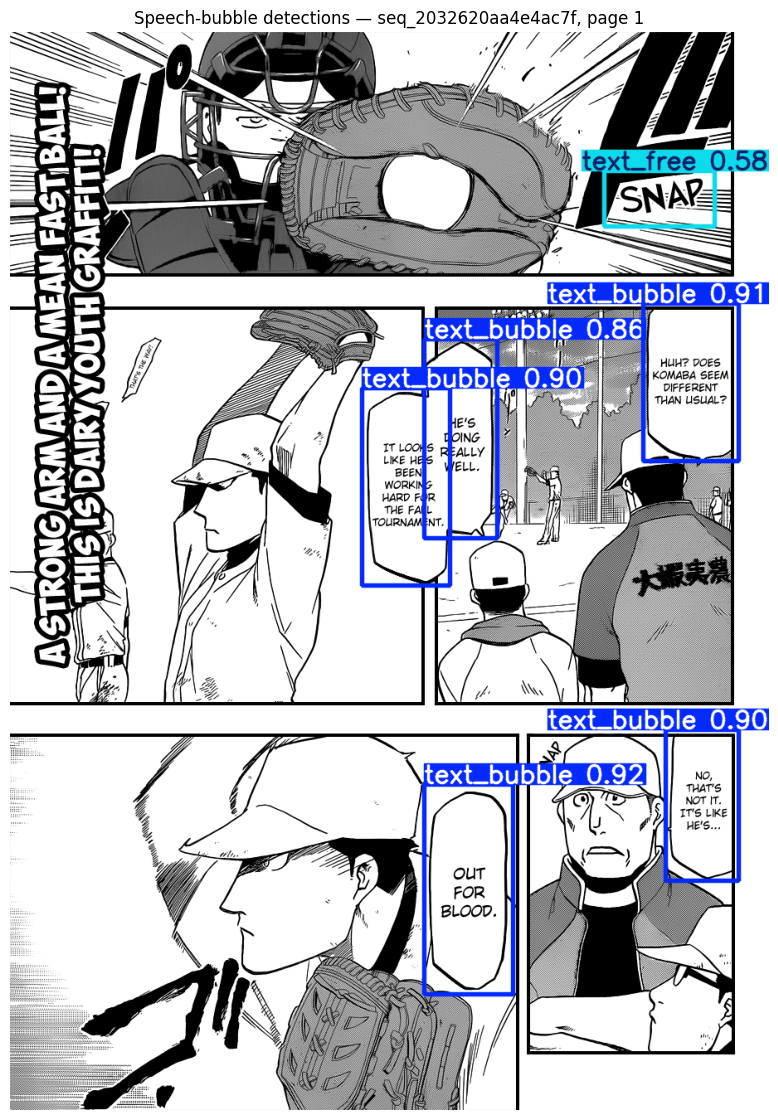

In [18]:
from pathlib import Path
from collections import Counter

import cv2
import matplotlib.pyplot as plt
from ultralytics import YOLO

DATA = Path(
    "/kaggle/input/datasets/kavyabatra32/mangaset/"
    "manga_folder/BYTE ML Task Data"
)
MODEL_PATH = Path(
    "/kaggle/working/models/comic-speech-bubble-detector.pt"
)

seq_id = "seq_2032620aa4e4ac7f"
image_path = DATA / "development" / "images" / seq_id / "01.png"

assert MODEL_PATH.exists(), f"Model missing: {MODEL_PATH}"
assert image_path.exists(), f"Image missing: {image_path}"

# Load the pretrained detector.
detector = YOLO(str(MODEL_PATH))

# Run inference on just one page.
results = detector.predict(
    source=str(image_path),
    conf=0.25,
    imgsz=640,
    verbose=False,
)

result = results[0]

print("Image:", image_path.name)
print("Image dimensions (height, width):", result.orig_shape)
print("Detector class names:", result.names)
print("Total detections:", len(result.boxes))

if len(result.boxes):
    class_counts = Counter(
        result.names[int(cls)]
        for cls in result.boxes.cls.tolist()
    )
    print("Detections by class:", dict(class_counts))

    print("\nFirst five detections (x1, y1, x2, y2, confidence, class):")
    for box in result.boxes[:5]:
        xyxy = [round(float(v), 1) for v in box.xyxy[0].tolist()]
        confidence = round(float(box.conf[0]), 3)
        class_id = int(box.cls[0])
        print(xyxy, confidence, result.names[class_id])

# Display the annotated page.
annotated = result.plot()

plt.figure(figsize=(10, 14))
plt.imshow(cv2.cvtColor(annotated, cv2.COLOR_BGR2RGB))
plt.title(f"Speech-bubble detections — {seq_id}, page 1")
plt.axis("off")
plt.show()

In [1]:
import cv2
import json
from paddleocr import PaddleOCR

# Use the existing image_path and YOLO result from Cell 12.
image_bgr = cv2.imread(str(image_path))
assert image_bgr is not None, f"Could not read {image_path}"

# PaddleOCR 3.x configuration.
ocr = PaddleOCR(
    lang="en",
    use_doc_orientation_classify=False,
    use_doc_unwarping=False,
    use_textline_orientation=False,
)

h, w = image_bgr.shape[:2]
bubble_rows = []

for i, box in enumerate(result.boxes):
    class_id = int(box.cls[0])
    class_name = result.names[class_id]

    # First test speech bubbles only, not free-standing graphic text.
    if class_name != "text_bubble":
        continue

    x1, y1, x2, y2 = [int(v) for v in box.xyxy[0].tolist()]

    # Add a small margin so text near bubble edges isn't cut off.
    pad_x = max(3, int((x2 - x1) * 0.04))
    pad_y = max(3, int((y2 - y1) * 0.04))

    x1 = max(0, x1 - pad_x)
    y1 = max(0, y1 - pad_y)
    x2 = min(w, x2 + pad_x)
    y2 = min(h, y2 + pad_y)

    crop = image_bgr[y1:y2, x1:x2]

    if crop.size == 0:
        continue

    outputs = list(ocr.predict(input=crop))

    recognized_text = []
    recognized_scores = []

    for output in outputs:
        data = output.json
        if isinstance(data, str):
            data = json.loads(data)

        data = data.get("res", data)
        recognized_text.extend(data.get("rec_texts", []))
        recognized_scores.extend(data.get("rec_scores", []))

    text = " ".join(str(t) for t in recognized_text).strip()

    bubble_rows.append({
        "box": [x1, y1, x2, y2],
        "detector_confidence": round(float(box.conf[0]), 3),
        "text": text,
        "ocr_scores": [
            round(float(s), 3) for s in recognized_scores
        ],
    })

print("Speech bubbles sent to OCR:", len(bubble_rows))

for i, row in enumerate(bubble_rows, start=1):
    print(f"\nBubble {i}")
    print("  Detector confidence:", row["detector_confidence"])
    print("  OCR text:", repr(row["text"]))
    print("  OCR scores:", row["ocr_scores"])

ModuleNotFoundError: No module named 'paddleocr'

In [2]:
%pip install -q paddleocr==3.7.0 paddlepaddle==3.3.1

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 80.7/80.7 kB 4.0 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 43.6/43.6 kB 2.2 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 62.4/62.4 kB 2.2 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 47.9/47.9 kB 2.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 146.8/146.8 kB 7.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 194.8/194.8 MB 9.9 MB/s eta 0:00:00:00:0100:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 65.5/65.5 kB 2.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.2/2.2 MB 63.3 MB/s eta 0:00:00:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 759.5/759.5 kB 24.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 68.7/68.7 MB 29.0 MB/s eta 0:00:00:00:0100:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 67.2/67.2 kB 3.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 6.1/6.1 MB 73.1 MB/s eta 0:00:00:00:0100:01
   ━━━━━━━━

In [3]:
import paddle
import ultralytics
from paddleocr import PaddleOCR

print("PaddlePaddle:", paddle.__version__)
print("Ultralytics:", ultralytics.__version__)
print("PaddleOCR import: SUCCESS ✅")

/usr/local/lib/python3.13/dist-packages/paddle/utils/cpp_extension/extension_utils.py:712: UserWarning: No ccache found. Please be aware that recompiling all source files may be required. You can download and install ccache from: https://github.com/ccache/ccache/blob/master/doc/INSTALL.md
  warnings.warn(warning_message)


ModuleNotFoundError: No module named 'ultralytics'

In [4]:
%pip install -q ultralytics==8.4.177

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 46.9/46.9 kB 1.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 18.7 MB/s eta 0:00:0000:0100:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 96.8/96.8 kB 5.4 MB/s eta 0:00:00
Note: you may need to restart the kernel to use updated packages.


In [5]:
import importlib.metadata as metadata

for package in ["ultralytics", "paddleocr", "paddlepaddle"]:
    try:
        print(f"{package}: {metadata.version(package)}")
    except metadata.PackageNotFoundError:
        print(f"{package}: NOT INSTALLED")

from ultralytics import YOLO
print("\nYOLO import: OK")

import paddle
print("PaddlePaddle import: OK")

from paddleocr import PaddleOCR
print("PaddleOCR import: OK")

ultralytics: 8.4.177
paddleocr: 3.7.0
paddlepaddle: 3.3.1
Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings.

YOLO import: OK
PaddlePaddle import: OK
PaddleOCR import: OK


In [11]:
import json
import time
from pathlib import Path

import cv2
from ultralytics import YOLO
from paddleocr import PaddleOCR

DATA = Path(
    "/kaggle/input/datasets/kavyabatra32/mangaset/"
    "manga_folder/BYTE ML Task Data"
)
WORK = Path("/kaggle/working")
CACHE = WORK / "cache" / "bubbles"
VIS = WORK / "visual_speaker_data"
MODELS = WORK / "models"

CACHE.mkdir(parents=True, exist_ok=True)
VIS.mkdir(parents=True, exist_ok=True)

MODEL_PATH = MODELS / "comic-speech-bubble-detector.pt"
assert MODEL_PATH.exists(), f"Detector weights not found: {MODEL_PATH}"

with (DATA / "sequences.json").open(encoding="utf-8") as f:
    metadata = json.load(f)

with (WORK / "split_info.json").open(encoding="utf-8") as f:
    split = json.load(f)

train_ids = set(split["train_ids"])
val_ids = set(split["val_ids"])

print("Loading YOLO detector...")
detector = YOLO(str(MODEL_PATH))

print("Initialising PaddleOCR...")
ocr = PaddleOCR(
    lang="en",
    use_doc_orientation_classify=False,
    use_doc_unwarping=False,
    use_textline_orientation=False,
)

def extract_ocr(outputs):
    texts, scores = [], []

    for output in outputs:
        data = output.json
        if isinstance(data, str):
            data = json.loads(data)

        data = data.get("res", data)
        texts.extend(data.get("rec_texts", []))
        scores.extend(data.get("rec_scores", []))

    return (
        " ".join(str(text) for text in texts).strip(),
        [round(float(score), 4) for score in scores],
    )

def process_sequence(meta):
    sid = meta["sequence_id"]
    pages = []

    for page_index, relative_path in enumerate(meta["images"], start=1):
        image_path = DATA / relative_path
        image = cv2.imread(str(image_path))

        if image is None:
            raise ValueError(f"Could not read image: {image_path}")

        height, width = image.shape[:2]

        results = detector.predict(
            source=str(image_path),
            conf=0.25,
            imgsz=640,
            verbose=False,
        )
        result = results[0]
        detections = []

        for box in result.boxes:
            x1, y1, x2, y2 = [
                int(round(v)) for v in box.xyxy[0].tolist()
            ]
            x1, y1 = max(0, x1), max(0, y1)
            x2, y2 = min(width, x2), min(height, y2)

            if x2 <= x1 or y2 <= y1:
                continue

            crop = image[y1:y2, x1:x2]
            text, scores = extract_ocr(ocr.predict(input=crop))

            class_id = int(box.cls[0].item())

            detections.append({
                "bbox_xyxy": [x1, y1, x2, y2],
                "detector_class": result.names[class_id],
                "detector_confidence": round(
                    float(box.conf[0].item()), 4
                ),
                "text": text,
                "ocr_scores": scores,
            })

        pages.append({
            "page_index": page_index,
            "image_path": relative_path,
            "image_width": width,
            "image_height": height,
            "detections": detections,
        })

    return {
        "sequence_id": sid,
        "source_split": meta["split"],
        "pages": pages,
    }

def cache_is_valid(path, sid):
    try:
        row = json.loads(path.read_text(encoding="utf-8"))
        return (
            row.get("sequence_id") == sid
            and len(row.get("pages", [])) == 3
            and all("detections" in page for page in row["pages"])
        )
    except (OSError, ValueError, TypeError):
        return False

start = time.time()
total_detections = 0
processed = 0
reused = 0

for i, meta in enumerate(metadata, start=1):
    sid = meta["sequence_id"]
    cache_path = CACHE / f"{sid}.json"

    if cache_is_valid(cache_path, sid):
        row = json.loads(cache_path.read_text(encoding="utf-8"))
        reused += 1
    else:
        row = process_sequence(meta)

        # Write atomically after each complete sequence.
        temp_path = cache_path.with_suffix(".tmp")
        temp_path.write_text(
            json.dumps(row, ensure_ascii=False),
            encoding="utf-8",
        )
        temp_path.replace(cache_path)
        processed += 1

    total_detections += sum(
        len(page["detections"]) for page in row["pages"]
    )

    if i % 5 == 0 or i == len(metadata):
        print(
            f"{i}/{len(metadata)} sequences | "
            f"{total_detections} detections | "
            f"{time.time() - start:.1f}s elapsed"
        )

# Export separate, flattened JSONL files for downstream stages.
rows_by_split = {
    "train": [],
    "validation": [],
    "test": [],
}

for meta in metadata:
    sid = meta["sequence_id"]
    cache_path = CACHE / f"{sid}.json"
    row = json.loads(cache_path.read_text(encoding="utf-8"))

    if sid in train_ids:
        fold = "train"
    elif sid in val_ids:
        fold = "validation"
    else:
        fold = "test"

    for page in row["pages"]:
        for detection in page["detections"]:
            rows_by_split[fold].append({
                "sequence_id": sid,
                "split": fold,
                "page_index": page["page_index"],
                "image_path": page["image_path"],
                "image_width": page["image_width"],
                "image_height": page["image_height"],
                **detection,
            })

for fold, filename in [
    ("train", "training_bubble_ocr.jsonl"),
    ("validation", "validation_bubble_ocr.jsonl"),
    ("test", "test_bubble_ocr.jsonl"),
]:
    output_path = VIS / filename
    with output_path.open("w", encoding="utf-8") as f:
        for row in rows_by_split[fold]:
            f.write(json.dumps(row, ensure_ascii=False) + "\n")

    print(f"Saved {len(rows_by_split[fold])} rows: {output_path}")

print("\n--- Batch summary ---")
print("Sequences in metadata:", len(metadata))
print("Newly processed:", processed)
print("Cached sequences reused:", reused)
print("Total detections:", total_detections)
print(f"Elapsed: {(time.time() - start) / 60:.1f} minutes")

Creating model: ('PP-OCRv6_medium_det', None, None)
Model files already exist. Using cached files. To redownload, please delete the directory manually: `/root/.paddlex/official_models/PP-OCRv6_medium_det`.


Loading YOLO detector...
Initialising PaddleOCR...


Creating model: ('PP-OCRv6_medium_rec', None, None)
Model files already exist. Using cached files. To redownload, please delete the directory manually: `/root/.paddlex/official_models/PP-OCRv6_medium_rec`.


NotImplementedError: (Unimplemented) ConvertPirAttribute2RuntimeAttribute not support [pir::ArrayAttribute<pir::DoubleAttribute>]  (at /paddle/paddle/fluid/framework/new_executor/instruction/onednn/onednn_instruction.cc:116)


In [7]:
from pathlib import Path
import hashlib
import shutil

from huggingface_hub import hf_hub_download

WORK = Path("/kaggle/working")
MODELS = WORK / "models"
MODELS.mkdir(parents=True, exist_ok=True)

MODEL_PATH = MODELS / "comic-speech-bubble-detector.pt"

EXPECTED_SHA256 = (
    "10bc9f702698148e079fb4462a6b910f"
    "cd69753e04838b54087ef91d5633097b"
)

# Re-download only if the file is missing or its checksum is wrong.
def sha256_file(path):
    h = hashlib.sha256()
    with path.open("rb") as f:
        for chunk in iter(lambda: f.read(1024 * 1024), b""):
            h.update(chunk)
    return h.hexdigest()

if not MODEL_PATH.exists() or sha256_file(MODEL_PATH) != EXPECTED_SHA256:
    print("Restoring pretrained detector weights...")

    downloaded_path = hf_hub_download(
        repo_id="ogkalu/comic-speech-bubble-detector-yolov8m",
        filename="comic-speech-bubble-detector.pt",
        cache_dir=str(WORK / "hf_cache"),
    )

    shutil.copy2(downloaded_path, MODEL_PATH)

actual_sha256 = sha256_file(MODEL_PATH)

print("Model path:", MODEL_PATH)
print(f"File size: {MODEL_PATH.stat().st_size / (1024**2):.2f} MB")
print("Checksum verified:", actual_sha256 == EXPECTED_SHA256)

assert actual_sha256 == EXPECTED_SHA256, (
    "Detector checksum mismatch. Do not run inference."
)

[2026-10-13 20:12:18,798] [    INFO] _client.py:1025 - HTTP Request: GET https://huggingface.co/api/agent-harnesses "HTTP/1.1 200 OK"
[2026-10-13 20:12:18,823] [    INFO] _client.py:1025 - HTTP Request: HEAD https://huggingface.co/ogkalu/comic-speech-bubble-detector-yolov8m/resolve/main/comic-speech-bubble-detector.pt "HTTP/1.1 302 Found"


Restoring pretrained detector weights...


[2026-10-13 20:12:18,897] [    INFO] _client.py:1025 - HTTP Request: GET https://huggingface.co/api/models/ogkalu/comic-speech-bubble-detector-yolov8m/xet-read-token/21d5af0a9c69bb522b9968d6cc915f898d71a264 "HTTP/1.1 200 OK"


comic-speech-bubble-detector.pt: reconstructing file:   0%|          |  0.00B / 52.1MB            

comic-speech-bubble-detector.pt: downloading bytes:           |  0.00B            

Model path: /kaggle/working/models/comic-speech-bubble-detector.pt
File size: 49.67 MB
Checksum verified: True


In [9]:
import json
import random
from pathlib import Path

DATA = Path(
    "/kaggle/input/datasets/kavyabatra32/mangaset/"
    "manga_folder/BYTE ML Task Data"
)
WORK = Path("/kaggle/working")

# Ensure our directories exist.
for rel in [
    "cache/bubbles",
    "cache/faces",
    "visual_speaker_data",
    "models",
]:
    (WORK / rel).mkdir(parents=True, exist_ok=True)

# Reconstruct the same deterministic split.
with (DATA / "sequences.json").open(encoding="utf-8") as f:
    metadata = json.load(f)

dev_ids = sorted(
    row["sequence_id"]
    for row in metadata
    if row["split"] == "development"
)
test_ids = sorted(
    row["sequence_id"]
    for row in metadata
    if row["split"] == "test"
)

assert len(dev_ids) == 80
assert len(test_ids) == 15

shuffled_ids = dev_ids.copy()
random.Random(42).shuffle(shuffled_ids)

val_ids = sorted(shuffled_ids[:16])
train_ids = sorted(shuffled_ids[16:])

split = {
    "seed": 42,
    "train_ids": train_ids,
    "val_ids": val_ids,
    "test_ids": test_ids,
}

with (WORK / "split_info.json").open("w", encoding="utf-8") as f:
    json.dump(split, f, indent=2)

# Rebuild the validation reference file.
val_set = set(val_ids)
val_records = []

with (DATA / "development" / "labels.jsonl").open(
    encoding="utf-8"
) as f:
    for line in f:
        if line.strip():
            row = json.loads(line)
            if row["sequence_id"] in val_set:
                val_records.append(row)

val_records.sort(key=lambda row: row["sequence_id"])

assert {r["sequence_id"] for r in val_records} == val_set
assert all(len(r["pages"]) == 3 for r in val_records)

with (WORK / "val_references.jsonl").open(
    "w", encoding="utf-8"
) as f:
    for row in val_records:
        f.write(json.dumps(row, ensure_ascii=False) + "\n")

print("Split restored.")
print("Training:", len(train_ids))
print("Validation:", len(val_ids))
print("Test:", len(test_ids))
print("Validation references:", len(val_records))
print(
    "Detector weights:",
    (WORK / "models" / "comic-speech-bubble-detector.pt").exists()
)
print(
    "Existing bubble caches:",
    len(list((WORK / "cache" / "bubbles").glob("*.json")))
)

Split restored.
Training: 64
Validation: 16
Test: 15
Validation references: 16
Detector weights: True
Existing bubble caches: 0


In [12]:
from pathlib import Path
from paddleocr import PaddleOCR

DATA = Path(
    "/kaggle/input/datasets/kavyabatra32/mangaset/"
    "manga_folder/BYTE ML Task Data"
)

image_path = (
    DATA / "development" / "images"
    / "seq_2032620aa4e4ac7f" / "01.png"
)

assert image_path.exists(), f"Image not found: {image_path}"

print("Initialising PaddleOCR with oneDNN disabled...")

ocr = PaddleOCR(
    lang="en",
    device="cpu",
    enable_mkldnn=False,
    use_doc_orientation_classify=False,
    use_doc_unwarping=False,
    use_textline_orientation=False,
)

print("Running OCR on one page...")

results = ocr.predict(input=str(image_path))

print("OCR inference succeeded!")
print("Result objects:", len(results))

for result in results[:1]:
    data = result.json
    if isinstance(data, str):
        import json
        data = json.loads(data)

    data = data.get("res", data)
    texts = data.get("rec_texts", [])
    print("Recognised text samples:", texts[:10])

Creating model: ('PP-OCRv6_medium_det', None, None)
Model files already exist. Using cached files. To redownload, please delete the directory manually: `/root/.paddlex/official_models/PP-OCRv6_medium_det`.


Initialising PaddleOCR with oneDNN disabled...


Creating model: ('PP-OCRv6_medium_rec', None, None)
Model files already exist. Using cached files. To redownload, please delete the directory manually: `/root/.paddlex/official_models/PP-OCRv6_medium_rec`.


Running OCR on one page...
OCR inference succeeded!
Result objects: 1
Recognised text samples: ['S   U', 'HI T', 'SNAP', 'HUH? DOES', 'KOMABA SEEM', 'DIFFERENT', "THAT'S THE WAY!", 'THAN USUAL?', "HE'S", 'DOING']


In [17]:
ocr = PaddleOCR(
    lang="en",
    device="cpu",
    enable_mkldnn=False,
    use_doc_orientation_classify=False,
    use_doc_unwarping=False,
    use_textline_orientation=False,
)

Creating model: ('PP-OCRv6_medium_det', None, None)
Model files already exist. Using cached files. To redownload, please delete the directory manually: `/root/.paddlex/official_models/PP-OCRv6_medium_det`.
Creating model: ('PP-OCRv6_medium_rec', None, None)
Model files already exist. Using cached files. To redownload, please delete the directory manually: `/root/.paddlex/official_models/PP-OCRv6_medium_rec`.


In [18]:
from pathlib import Path
import json

WORK = Path("/kaggle/working")
CACHE = WORK / "cache" / "bubbles"
VIS = WORK / "visual_speaker_data"
MODEL = WORK / "models" / "comic-speech-bubble-detector.pt"

print("Detector weights exist:", MODEL.exists())

cache_files = (
    sorted(CACHE.glob("*.json"))
    if CACHE.exists() else []
)

print("Completed sequence cache files:", len(cache_files))

if cache_files:
    latest = max(cache_files, key=lambda p: p.stat().st_mtime)
    print("Most recently saved cache:", latest.name)

    try:
        row = json.loads(latest.read_text(encoding="utf-8"))
        print("Pages in that cache:", len(row.get("pages", [])))
        print(
            "Detections in that cache:",
            sum(len(p.get("detections", [])) for p in row.get("pages", []))
        )
    except Exception as e:
        print("Could not read latest cache:", repr(e))

print("\nExported OCR files:")
for name in [
    "training_bubble_ocr.jsonl",
    "validation_bubble_ocr.jsonl",
    "test_bubble_ocr.jsonl",
]:
    path = VIS / name
    if path.exists():
        with path.open(encoding="utf-8") as f:
            count = sum(1 for line in f if line.strip())
        print(f"{name}: {count} rows")
    else:
        print(f"{name}: not created yet")

Detector weights exist: True
Completed sequence cache files: 0

Exported OCR files:
training_bubble_ocr.jsonl: not created yet
validation_bubble_ocr.jsonl: not created yet
test_bubble_ocr.jsonl: not created yet


In [ ]:
import json
from pathlib import Path
from paddleocr import PaddleOCR

DATA = Path(
    "/kaggle/input/datasets/kavyabatra32/mangaset/"
    "manga_folder/BYTE ML Task Data"
)

image_path = (
    DATA / "development" / "images"
    / "seq_2032620aa4e4ac7f" / "01.png"
)

ocr = PaddleOCR(
    lang="en",
    device="cpu",
    enable_mkldnn=False,
    use_doc_orientation_classify=False,
    use_doc_unwarping=False,
    use_textline_orientation=False,
)

outputs = ocr.predict(input=str(image_path))
data = outputs[0].json

if isinstance(data, str):
    data = json.loads(data)

data = data.get("res", data)

print("Available OCR fields:")
print(list(data.keys()))

for key in ["rec_texts", "rec_scores", "dt_polys", "rec_polys"]:
    value = data.get(key)
    print(f"\n{key}:")
    if value is None:
        print("Not present")
    else:
        print("Count:", len(value))
        if len(value):
            print("First item:", value[0])

In [21]:
import json
import time
from pathlib import Path

import cv2
from ultralytics import YOLO
from paddleocr import PaddleOCR

DATA = Path(
    "/kaggle/input/datasets/kavyabatra32/mangaset/"
    "manga_folder/BYTE ML Task Data"
)
WORK = Path("/kaggle/working")
CACHE = WORK / "cache" / "bubbles"
VIS = WORK / "visual_speaker_data"
MODELS = WORK / "models"

for directory in [CACHE, VIS, MODELS]:
    directory.mkdir(parents=True, exist_ok=True)

MODEL_PATH = MODELS / "comic-speech-bubble-detector.pt"
assert MODEL_PATH.exists(), f"Detector weights missing: {MODEL_PATH}"

with (DATA / "sequences.json").open(encoding="utf-8") as f:
    metadata = json.load(f)

# Recover the deterministic split if a session restart removed it.
split_path = WORK / "split_info.json"

if split_path.exists():
    split = json.loads(split_path.read_text(encoding="utf-8"))
else:
    import random

    dev_ids = sorted(
        row["sequence_id"] for row in metadata
        if row["split"] == "development"
    )
    test_ids = sorted(
        row["sequence_id"] for row in metadata
        if row["split"] == "test"
    )

    shuffled = dev_ids.copy()
    random.Random(42).shuffle(shuffled)

    split = {
        "seed": 42,
        "train_ids": sorted(shuffled[16:]),
        "val_ids": sorted(shuffled[:16]),
        "test_ids": test_ids,
    }
    split_path.write_text(json.dumps(split, indent=2), encoding="utf-8")

train_ids = set(split["train_ids"])
val_ids = set(split["val_ids"])

assert len(train_ids) == 64 and len(val_ids) == 16
assert not (train_ids & val_ids)

print("Loading YOLO...")
detector = YOLO(str(MODEL_PATH))

print("Initialising PaddleOCR with oneDNN disabled...")
ocr = PaddleOCR(
    lang="en",
    device="cpu",
    enable_mkldnn=False,
    use_doc_orientation_classify=False,
    use_doc_unwarping=False,
    use_textline_orientation=False,
)

def save_json_atomic(path, obj):
    tmp = path.with_suffix(".tmp")
    tmp.write_text(json.dumps(obj, ensure_ascii=False), encoding="utf-8")
    tmp.replace(path)

def ocr_page(image_path):
    """Run OCR once on the full page and return text regions with coordinates."""
    outputs = ocr.predict(input=str(image_path))
    if not outputs:
        return []

    data = outputs[0].json
    if isinstance(data, str):
        data = json.loads(data)
    data = data.get("res", data)

    texts = data.get("rec_texts", [])
    scores = data.get("rec_scores", [])
    polygons = data.get("dt_polys", [])

    items = []
    for i in range(min(len(texts), len(scores), len(polygons))):
        text = str(texts[i]).strip()
        if not text:
            continue

        points = polygons[i]
        xs = [float(p[0]) for p in points]
        ys = [float(p[1]) for p in points]

        x1, x2 = min(xs), max(xs)
        y1, y2 = min(ys), max(ys)

        items.append({
            "text": text,
            "score": round(float(scores[i]), 4),
            "bbox_xyxy": [round(x1, 1), round(y1, 1),
                          round(x2, 1), round(y2, 1)],
            "center": [(x1 + x2) / 2, (y1 + y2) / 2],
            "height": max(1.0, y2 - y1),
        })

    return items

def assign_ocr_to_boxes(detections, ocr_items):
    """Associate each OCR region with its best-fitting detector box."""
    assigned = [[] for _ in detections]

    for item in ocr_items:
        x1, y1, x2, y2 = item["bbox_xyxy"]
        cx, cy = item["center"]
        text_area = max(1.0, (x2 - x1) * (y2 - y1))

        containing = []
        overlaps = []

        for j, det in enumerate(detections):
            bx1, by1, bx2, by2 = det["bbox_xyxy"]

            if bx1 <= cx <= bx2 and by1 <= cy <= by2:
                area = max(1.0, (bx2 - bx1) * (by2 - by1))
                containing.append((area, j))
                continue

            ix1, iy1 = max(x1, bx1), max(y1, by1)
            ix2, iy2 = min(x2, bx2), min(y2, by2)
            intersection = max(0.0, ix2 - ix1) * max(0.0, iy2 - iy1)
            overlap_ratio = intersection / text_area

            if overlap_ratio >= 0.20:
                overlaps.append((overlap_ratio, j, area if 'area' in locals() else 0))

        if containing:
            # If boxes overlap, prefer the smallest box containing the text.
            _, best = min(containing)
            assigned[best].append(item)
        elif overlaps:
            # Otherwise use the box covering the largest fraction of the OCR region.
            _, best, _ = max(overlaps, key=lambda entry: entry[0])
            assigned[best].append(item)

    return assigned

def compose_text(items):
    """Read grouped OCR regions approximately top-to-bottom, left-to-right."""
    if not items:
        return "", []

    # Group nearby vertical positions into text lines, then sort each line by x.
    rows = []

    for item in sorted(items, key=lambda z: z["center"][1]):
        cy = item["center"][1]
        matching_row = None
        best_distance = float("inf")

        for row in rows:
            row_y = sum(x["center"][1] for x in row) / len(row)
            tolerance = max(
                8.0,
                0.55 * max(item["height"], max(x["height"] for x in row))
            )
            distance = abs(cy - row_y)

            if distance <= tolerance and distance < best_distance:
                matching_row = row
                best_distance = distance

        if matching_row is None:
            rows.append([item])
        else:
            matching_row.append(item)

    rows.sort(key=lambda row: sum(x["center"][1] for x in row) / len(row))

    ordered = []
    for row in rows:
        ordered.extend(sorted(row, key=lambda x: x["center"][0]))

    text = " ".join(item["text"] for item in ordered).strip()
    scores = [item["score"] for item in ordered]
    return text, scores

def process_page(relative_path):
    image_path = DATA / relative_path
    image = cv2.imread(str(image_path))
    if image is None:
        raise FileNotFoundError(f"Cannot read image: {image_path}")

    height, width = image.shape[:2]

    result = detector.predict(
        source=str(image_path),
        conf=0.25,
        imgsz=640,
        verbose=False,
    )[0]

    detections = []
    for box in result.boxes:
        x1, y1, x2, y2 = [
            int(round(v)) for v in box.xyxy[0].tolist()
        ]
        x1, y1 = max(0, x1), max(0, y1)
        x2, y2 = min(width, x2), min(height, y2)

        if x2 <= x1 or y2 <= y1:
            continue

        class_id = int(box.cls[0].item())
        detections.append({
            "bbox_xyxy": [x1, y1, x2, y2],
            "detector_class": result.names[class_id],
            "detector_confidence": round(float(box.conf[0].item()), 4),
            "text": "",
            "ocr_scores": [],
            "ocr_parts": [],
        })

    # The expensive text-detection pass runs only once on the full page.
    ocr_items = ocr_page(image_path)
    assigned = assign_ocr_to_boxes(detections, ocr_items)

    for detection, parts in zip(detections, assigned):
        text, scores = compose_text(parts)
        detection["text"] = text
        detection["ocr_scores"] = scores
        detection["ocr_parts"] = [
            {
                "text": part["text"],
                "score": part["score"],
                "bbox_xyxy": part["bbox_xyxy"],
            }
            for part in parts
        ]

    return {
        "page_index": int(Path(relative_path).stem),
        "image_path": relative_path,
        "image_width": width,
        "image_height": height,
        "ocr_region_count": len(ocr_items),
        "detections": detections,
    }

start = time.time()
processed_sequences = 0
reused_sequences = 0

for i, meta in enumerate(metadata, start=1):
    sid = meta["sequence_id"]
    cache_path = CACHE / f"{sid}.json"

    # Resume only caches created by this full-page OCR version.
    try:
        row = json.loads(cache_path.read_text(encoding="utf-8"))
        if row.get("ocr_mode") != "full_page_v1" or row.get("sequence_id") != sid:
            row = None
    except (OSError, ValueError):
        row = None

    if row is None:
        row = {
            "sequence_id": sid,
            "source_split": meta["split"],
            "ocr_mode": "full_page_v1",
            "complete": False,
            "pages": [],
        }

    completed_pages = {
        page["image_path"]: page for page in row["pages"]
        if "image_path" in page and "detections" in page
    }

    for relative_path in meta["images"]:
        if relative_path in completed_pages:
            continue

        page = process_page(relative_path)
        completed_pages[relative_path] = page

        row["pages"] = [
            completed_pages[p] for p in meta["images"] if p in completed_pages
        ]
        row["complete"] = len(row["pages"]) == 3

        # Save every completed page, not just every completed sequence.
        save_json_atomic(cache_path, row)

    row["pages"] = [completed_pages[p] for p in meta["images"]]
    row["complete"] = True
    save_json_atomic(cache_path, row)

    if len(row["pages"]) != 3:
        raise RuntimeError(f"Incomplete cache for {sid}")

    if len(completed_pages) == 3 and cache_path.exists():
        processed_sequences += 1

    if i % 5 == 0 or i == len(metadata):
        cached_count = sum(
            1 for p in CACHE.glob("*.json")
            if p.name in {f'{m["sequence_id"]}.json' for m in metadata}
        )
        print(
            f"{i}/{len(metadata)} sequences visited | "
            f"{cached_count} sequence caches | "
            f"{time.time() - start:.1f}s elapsed"
        )

# Export the current caches into train/validation/test JSONL files.
rows_by_split = {"train": [], "validation": [], "test": []}

for meta in metadata:
    sid = meta["sequence_id"]
    cache_path = CACHE / f"{sid}.json"
    row = json.loads(cache_path.read_text(encoding="utf-8"))

    if not row.get("complete") or len(row.get("pages", [])) != 3:
        raise RuntimeError(f"Cache is not complete for {sid}")

    if sid in train_ids:
        fold = "train"
    elif sid in val_ids:
        fold = "validation"
    else:
        fold = "test"

    for page in row["pages"]:
        for detection in page["detections"]:
            rows_by_split[fold].append({
                "sequence_id": sid,
                "split": fold,
                "page_index": page["page_index"],
                "image_path": page["image_path"],
                "image_width": page["image_width"],
                "image_height": page["image_height"],
                **detection,
            })

for fold, filename in [
    ("train", "training_bubble_ocr.jsonl"),
    ("validation", "validation_bubble_ocr.jsonl"),
    ("test", "test_bubble_ocr.jsonl"),
]:
    output_path = VIS / filename
    with output_path.open("w", encoding="utf-8") as f:
        for item in rows_by_split[fold]:
            f.write(json.dumps(item, ensure_ascii=False) + "\n")
    print(f"Saved {len(rows_by_split[fold])} rows -> {output_path}")

print("\n--- Completed ---")
print("Sequences:", len(metadata))
print("Train detections:", len(rows_by_split["train"]))
print("Validation detections:", len(rows_by_split["validation"]))
print("Test detections:", len(rows_by_split["test"]))
print(f"Elapsed: {(time.time() - start) / 60:.1f} minutes")

Creating model: ('PP-OCRv6_medium_det', None, None)
Model files already exist. Using cached files. To redownload, please delete the directory manually: `/root/.paddlex/official_models/PP-OCRv6_medium_det`.


Loading YOLO...
Initialising PaddleOCR with oneDNN disabled...


Creating model: ('PP-OCRv6_medium_rec', None, None)
Model files already exist. Using cached files. To redownload, please delete the directory manually: `/root/.paddlex/official_models/PP-OCRv6_medium_rec`.


5/95 sequences visited | 95 sequence caches | 0.0s elapsed
10/95 sequences visited | 95 sequence caches | 0.0s elapsed
15/95 sequences visited | 95 sequence caches | 0.0s elapsed
20/95 sequences visited | 95 sequence caches | 0.0s elapsed
25/95 sequences visited | 95 sequence caches | 0.0s elapsed
30/95 sequences visited | 95 sequence caches | 0.0s elapsed
35/95 sequences visited | 95 sequence caches | 0.1s elapsed
40/95 sequences visited | 95 sequence caches | 0.1s elapsed
45/95 sequences visited | 95 sequence caches | 0.1s elapsed
50/95 sequences visited | 95 sequence caches | 0.1s elapsed
55/95 sequences visited | 95 sequence caches | 0.1s elapsed
60/95 sequences visited | 95 sequence caches | 0.1s elapsed
65/95 sequences visited | 95 sequence caches | 0.1s elapsed
70/95 sequences visited | 95 sequence caches | 0.1s elapsed
75/95 sequences visited | 95 sequence caches | 0.1s elapsed
80/95 sequences visited | 95 sequence caches | 0.1s elapsed
85/95 sequences visited | 95 sequence cac

In [22]:
import json
import zipfile
from pathlib import Path

WORK = Path("/kaggle/working")
CACHE = WORK / "cache" / "bubbles"
VIS = WORK / "visual_speaker_data"
MODELS = WORK / "models"

with (WORK / "split_info.json").open(encoding="utf-8") as f:
    split = json.load(f)

expected_ids = (
    set(split["train_ids"])
    | set(split["val_ids"])
    | set(split["test_ids"])
)

cache_ok = []
cache_bad = []
cache_detections = 0

for sid in sorted(expected_ids):
    path = CACHE / f"{sid}.json"

    try:
        row = json.loads(path.read_text(encoding="utf-8"))
        valid = (
            row.get("sequence_id") == sid
            and row.get("ocr_mode") == "full_page_v1"
            and row.get("complete") is True
            and len(row.get("pages", [])) == 3
            and all("detections" in page for page in row["pages"])
        )

        if valid:
            cache_ok.append(sid)
            cache_detections += sum(
                len(page["detections"]) for page in row["pages"]
            )
        else:
            cache_bad.append(sid)

    except (OSError, ValueError, TypeError):
        cache_bad.append(sid)

print("Valid full-page OCR caches:", len(cache_ok), "/", len(expected_ids))
print("Invalid or incomplete caches:", len(cache_bad))
print("Detections inside valid caches:", cache_detections)

export_counts = {}
exports_ok = True

for filename, expected_count in [
    ("training_bubble_ocr.jsonl", 1498),
    ("validation_bubble_ocr.jsonl", 349),
    ("test_bubble_ocr.jsonl", 372),
]:
    path = VIS / filename

    try:
        with path.open(encoding="utf-8") as f:
            rows = [json.loads(line) for line in f if line.strip()]

        export_counts[filename] = len(rows)
        valid = len(rows) == expected_count

        print(f"{filename}: {len(rows)} rows; count check: {valid}")
        exports_ok &= valid

    except (OSError, ValueError) as e:
        print(f"{filename}: ERROR — {e}")
        exports_ok = False

if len(cache_ok) == len(expected_ids) and not cache_bad and exports_ok:
    checkpoint = WORK / "manga_pipeline_checkpoint.zip"

    include_files = [
        WORK / "split_info.json",
        WORK / "val_references.jsonl",
        WORK / "baseline_scores.json",
        MODELS / "comic-speech-bubble-detector.pt",
        VIS / "training_bubble_ocr.jsonl",
        VIS / "validation_bubble_ocr.jsonl",
        VIS / "test_bubble_ocr.jsonl",
    ]
    include_files += [
        CACHE / f"{sid}.json" for sid in sorted(expected_ids)
    ]

    with zipfile.ZipFile(
        checkpoint, "w", compression=zipfile.ZIP_DEFLATED
    ) as zf:
        for path in include_files:
            if path.exists():
                zf.write(path, path.relative_to(WORK))

    print("\nCheckpoint ZIP created:", checkpoint)
    print(f"Checkpoint size: {checkpoint.stat().st_size / (1024**2):.1f} MB")
else:
    print("\nCheckpoint not created: fix or inspect the failed checks first.")

Valid full-page OCR caches: 95 / 95
Invalid or incomplete caches: 0
Detections inside valid caches: 2219
training_bubble_ocr.jsonl: 1498 rows; count check: True
validation_bubble_ocr.jsonl: 349 rows; count check: True
test_bubble_ocr.jsonl: 372 rows; count check: True

Checkpoint ZIP created: /kaggle/working/manga_pipeline_checkpoint.zip
Checkpoint size: 46.3 MB


In [23]:
import importlib.metadata as metadata

print("=== MAGI dependencies ===")

packages = [
    "transformers",
    "tokenizers",
    "torch",
    "timm",
    "einops",
    "scipy",
    "shapely",
    "PuLP",
    "huggingface_hub",
]

for package in packages:
    try:
        print(f"{package}: {metadata.version(package)}")
    except metadata.PackageNotFoundError:
        print(f"{package}: NOT INSTALLED")

print("\n=== Loading MAGI configuration only ===")

from transformers import AutoConfig

MAGI_ID = "ragavsachdeva/magiv2"

config = AutoConfig.from_pretrained(
    MAGI_ID,
    trust_remote_code=True,
)

print("Configuration type:", type(config).__name__)
print("Disable detections:", getattr(config, "disable_detections", None))
print("Disable OCR:", getattr(config, "disable_ocr", None))
print(
    "Disable crop embeddings:",
    getattr(config, "disable_crop_embeddings", None),
)
print("MAGI configuration loaded successfully.")

[2026-10-13 22:22:02,127] [    INFO] _client.py:1025 - HTTP Request: HEAD https://huggingface.co/ragavsachdeva/magiv2/resolve/main/config.json "HTTP/1.1 307 Temporary Redirect"
[2026-10-13 22:22:02,136] [    INFO] _client.py:1025 - HTTP Request: HEAD https://huggingface.co/api/resolve-cache/models/ragavsachdeva/magiv2/fbc890fec52977142e8ee00bfe26e9458b65517c/config.json "HTTP/1.1 200 OK"
[2026-10-13 22:22:02,147] [    INFO] _client.py:1025 - HTTP Request: GET https://huggingface.co/api/resolve-cache/models/ragavsachdeva/magiv2/fbc890fec52977142e8ee00bfe26e9458b65517c/config.json "HTTP/1.1 200 OK"


=== MAGI dependencies ===
transformers: 5.16.1
tokenizers: 0.23.1
torch: 2.11.0+cu128
timm: 1.0.29
einops: 0.8.2
scipy: 1.16.3
shapely: 2.1.2
PuLP: 3.3.2
huggingface_hub: 1.29.0

=== Loading MAGI configuration only ===


config.json:   0%|          | 0.00/13.4k [00:00<?, ?B/s]

[2026-10-13 22:22:02,183] [    INFO] _client.py:1025 - HTTP Request: HEAD https://huggingface.co/ragavsachdeva/magiv2/resolve/main/configuration_magiv2.py "HTTP/1.1 307 Temporary Redirect"
[2026-10-13 22:22:02,191] [    INFO] _client.py:1025 - HTTP Request: HEAD https://huggingface.co/api/resolve-cache/models/ragavsachdeva/magiv2/fbc890fec52977142e8ee00bfe26e9458b65517c/configuration_magiv2.py "HTTP/1.1 200 OK"
[2026-10-13 22:22:02,200] [    INFO] _client.py:1025 - HTTP Request: GET https://huggingface.co/api/resolve-cache/models/ragavsachdeva/magiv2/fbc890fec52977142e8ee00bfe26e9458b65517c/configuration_magiv2.py "HTTP/1.1 200 OK"


configuration_magiv2.py:   0%|          | 0.00/1.70k [00:00<?, ?B/s]

[transformers] A new version of the following files was downloaded from https://huggingface.co/ragavsachdeva/magiv2:
- configuration_magiv2.py
. Make sure to double-check they do not contain any added malicious code. To avoid downloading new versions of the code file, you can pin a revision.
[2026-10-13 22:22:02,253] [    INFO] _client.py:1025 - HTTP Request: HEAD https://huggingface.co/ragavsachdeva/magiv2/resolve/main/config.json "HTTP/1.1 307 Temporary Redirect"
[2026-10-13 22:22:02,263] [    INFO] _client.py:1025 - HTTP Request: HEAD https://huggingface.co/api/resolve-cache/models/ragavsachdeva/magiv2/fbc890fec52977142e8ee00bfe26e9458b65517c/config.json "HTTP/1.1 200 OK"


Configuration type: Magiv2Config
Disable detections: False
Disable OCR: False
Disable crop embeddings: False
MAGI configuration loaded successfully.


In [24]:
import torch
import numpy as np
from pathlib import Path
from PIL import Image
from transformers import AutoConfig, AutoModel

MAGI_ID = "ragavsachdeva/magiv2"

DATA = Path(
    "/kaggle/input/datasets/kavyabatra32/mangaset/"
    "manga_folder/BYTE ML Task Data"
)

device = "cuda" if torch.cuda.is_available() else "cpu"
print("Device:", device)

# Load the custom configuration.
config = AutoConfig.from_pretrained(
    MAGI_ID,
    trust_remote_code=True,
)

# Avoid initializing MAGI's TrOCR processor and OCR model.
config.disable_ocr = True

# Keep the learned detection and character-embedding components enabled.
config.disable_detections = False
config.disable_crop_embeddings = False

print("MAGI internal OCR disabled:", config.disable_ocr)
print("Detection enabled:", not config.disable_detections)
print("Crop embeddings enabled:", not config.disable_crop_embeddings)

print("\nLoading pretrained MAGI v2 weights...")
magi = AutoModel.from_pretrained(
    MAGI_ID,
    config=config,
    trust_remote_code=True,
)
magi = magi.to(device).eval()

print("MAGI model loaded successfully.")

# Test one page from the fixed validation set.
image_path = (
    DATA / "development" / "images"
    / "seq_2032620aa4e4ac7f" / "01.png"
)

image = np.array(
    Image.open(image_path).convert("L").convert("RGB")
)

print("\nImage shape:", image.shape)
print("Running MAGI detection and association...")

with torch.inference_mode():
    results = magi.predict_detections_and_associations([image])

assert len(results) == 1
page_result = results[0]

print("\n=== MAGI page results ===")
print("Available keys:", list(page_result.keys()))

for key in [
    "panels",
    "texts",
    "characters",
    "tails",
    "text_character_associations",
    "text_tail_associations",
    "character_cluster_labels",
    "is_essential_text",
]:
    value = page_result.get(key)
    if value is not None:
        try:
            print(f"{key}: {len(value)}")
        except TypeError:
            print(f"{key}: returned")

print("\nMAGI single-page test completed.")

[2026-10-13 22:27:04,817] [    INFO] _client.py:1025 - HTTP Request: HEAD https://huggingface.co/ragavsachdeva/magiv2/resolve/main/config.json "HTTP/1.1 307 Temporary Redirect"
[2026-10-13 22:27:04,825] [    INFO] _client.py:1025 - HTTP Request: HEAD https://huggingface.co/api/resolve-cache/models/ragavsachdeva/magiv2/fbc890fec52977142e8ee00bfe26e9458b65517c/config.json "HTTP/1.1 200 OK"
[2026-10-13 22:27:04,853] [    INFO] _client.py:1025 - HTTP Request: HEAD https://huggingface.co/ragavsachdeva/magiv2/resolve/main/configuration_magiv2.py "HTTP/1.1 307 Temporary Redirect"
[2026-10-13 22:27:04,860] [    INFO] _client.py:1025 - HTTP Request: HEAD https://huggingface.co/api/resolve-cache/models/ragavsachdeva/magiv2/fbc890fec52977142e8ee00bfe26e9458b65517c/configuration_magiv2.py "HTTP/1.1 200 OK"
[2026-10-13 22:27:04,886] [    INFO] _client.py:1025 - HTTP Request: HEAD https://huggingface.co/ragavsachdeva/magiv2/resolve/main/config.json "HTTP/1.1 307 Temporary Redirect"
[2026-10-13 22:27

Device: cuda
MAGI internal OCR disabled: True
Detection enabled: True
Crop embeddings enabled: True

Loading pretrained MAGI v2 weights...


[2026-10-13 22:27:04,956] [    INFO] _client.py:1025 - HTTP Request: HEAD https://huggingface.co/api/resolve-cache/models/ragavsachdeva/magiv2/fbc890fec52977142e8ee00bfe26e9458b65517c/modelling_magiv2.py "HTTP/1.1 200 OK"
[2026-10-13 22:27:04,967] [    INFO] _client.py:1025 - HTTP Request: GET https://huggingface.co/api/resolve-cache/models/ragavsachdeva/magiv2/fbc890fec52977142e8ee00bfe26e9458b65517c/modelling_magiv2.py "HTTP/1.1 200 OK"


modelling_magiv2.py:   0%|          | 0.00/40.7k [00:00<?, ?B/s]

[2026-10-13 22:27:05,295] [    INFO] _client.py:1025 - HTTP Request: HEAD https://huggingface.co/ragavsachdeva/magiv2/resolve/main/utils.py "HTTP/1.1 307 Temporary Redirect"
[2026-10-13 22:27:05,304] [    INFO] _client.py:1025 - HTTP Request: HEAD https://huggingface.co/api/resolve-cache/models/ragavsachdeva/magiv2/fbc890fec52977142e8ee00bfe26e9458b65517c/utils.py "HTTP/1.1 200 OK"
[2026-10-13 22:27:05,313] [    INFO] _client.py:1025 - HTTP Request: GET https://huggingface.co/api/resolve-cache/models/ragavsachdeva/magiv2/fbc890fec52977142e8ee00bfe26e9458b65517c/utils.py "HTTP/1.1 200 OK"


...

[transformers] A new version of the following files was downloaded from https://huggingface.co/ragavsachdeva/magiv2:
- processing_magiv2.py
. Make sure to double-check they do not contain any added malicious code. To avoid downloading new versions of the code file, you can pin a revision.
[transformers] A new version of the following files was downloaded from https://huggingface.co/ragavsachdeva/magiv2:
- modelling_magiv2.py
- utils.py
- processing_magiv2.py
. Make sure to double-check they do not contain any added malicious code. To avoid downloading new versions of the code file, you can pin a revision.
[2026-10-13 22:27:06,039] [    INFO] _client.py:1025 - HTTP Request: HEAD https://huggingface.co/ragavsachdeva/magiv2/resolve/main/config.json "HTTP/1.1 307 Temporary Redirect"
[2026-10-13 22:27:06,047] [    INFO] _client.py:1025 - HTTP Request: HEAD https://huggingface.co/api/resolve-cache/models/ragavsachdeva/magiv2/fbc890fec52977142e8ee00bfe26e9458b65517c/config.json "HTTP/1.1 200 

pytorch_model.bin: reconstructing file:   0%|          |  0.00B / 2.06GB            

pytorch_model.bin: downloading bytes:           |  0.00B            

[2026-10-13 22:27:11,434] [    INFO] _client.py:1025 - HTTP Request: HEAD https://huggingface.co/ragavsachdeva/magiv2/resolve/main/model.safetensors "HTTP/1.1 404 Not Found"


ValueError: Unrecognized configuration class <class 'transformers.configuration_utils.PreTrainedConfig'> for this kind of AutoModel: AutoBackbone.
Model type should be one of BeitConfig, BitConfig, ConvNextConfig, ConvNextV2Config, DinatConfig, Dinov2Config, Dinov2WithRegistersConfig, DINOv3ConvNextConfig, DINOv3ViTConfig, FocalNetConfig, HGNetV2Config, HieraConfig, LwDetrViTConfig, MaskFormerSwinConfig, PixioConfig, PPLCNetConfig, PPLCNetV3Config, PPLCNetV4Config, PvtV2Config, ResNetConfig, RfDetrDinov2Config, RTDetrResNetConfig, Sapiens2Config, SwinConfig, Swinv2Config, TextNetConfig, TimmBackboneConfig, Tipsv2Config, Tipsv2VisionConfig, UVDocBackboneConfig, VitDetConfig, VitPoseBackboneConfig.

In [25]:
from transformers import AutoConfig
from transformers.models.conditional_detr.configuration_conditional_detr import (
    ConditionalDetrConfig,
)
from transformers.models.vit_mae.configuration_vit_mae import ViTMAEConfig

MAGI_ID = "ragavsachdeva/magiv2"

config = AutoConfig.from_pretrained(
    MAGI_ID,
    trust_remote_code=True,
)

# Skip MAGI's internal TrOCR pathway for this integration attempt.
config.disable_ocr = True

# Convert the generic nested configs into their actual model-specific types.
detection_dict = config.detection_model_config.to_dict()
detection_dict.pop("model_type", None)

crop_dict = config.crop_embedding_model_config.to_dict()
crop_dict.pop("model_type", None)

config.detection_model_config = ConditionalDetrConfig.from_dict(
    detection_dict
)
config.crop_embedding_model_config = ViTMAEConfig.from_dict(
    crop_dict
)

print("Detection config:", type(config.detection_model_config).__name__)
print("Crop embedding config:", type(config.crop_embedding_model_config).__name__)
print("MAGI OCR disabled:", config.disable_ocr)

backbone_config = config.detection_model_config.backbone_config
print(
    "Backbone config:",
    type(backbone_config).__name__ if backbone_config is not None else None,
)

print("\nConfiguration patch completed.")

[2026-10-13 22:32:04,783] [    INFO] _client.py:1025 - HTTP Request: HEAD https://huggingface.co/ragavsachdeva/magiv2/resolve/main/config.json "HTTP/1.1 307 Temporary Redirect"
[2026-10-13 22:32:04,791] [    INFO] _client.py:1025 - HTTP Request: HEAD https://huggingface.co/api/resolve-cache/models/ragavsachdeva/magiv2/fbc890fec52977142e8ee00bfe26e9458b65517c/config.json "HTTP/1.1 200 OK"
[2026-10-13 22:32:04,818] [    INFO] _client.py:1025 - HTTP Request: HEAD https://huggingface.co/ragavsachdeva/magiv2/resolve/main/configuration_magiv2.py "HTTP/1.1 307 Temporary Redirect"
[2026-10-13 22:32:04,827] [    INFO] _client.py:1025 - HTTP Request: HEAD https://huggingface.co/api/resolve-cache/models/ragavsachdeva/magiv2/fbc890fec52977142e8ee00bfe26e9458b65517c/configuration_magiv2.py "HTTP/1.1 200 OK"
[2026-10-13 22:32:04,930] [    INFO] _client.py:1025 - HTTP Request: HEAD https://huggingface.co/ragavsachdeva/magiv2/resolve/main/config.json "HTTP/1.1 307 Temporary Redirect"
[2026-10-13 22:32

Detection config: ConditionalDetrConfig
Crop embedding config: ViTMAEConfig
MAGI OCR disabled: True
Backbone config: TimmBackboneConfig

Configuration patch completed.


In [26]:
import torch
from transformers import AutoConfig, AutoModel
from transformers.models.conditional_detr.configuration_conditional_detr import (
    ConditionalDetrConfig,
)
from transformers.models.vit_mae.configuration_vit_mae import ViTMAEConfig

MAGI_ID = "ragavsachdeva/magiv2"

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", device)

# Load MAGI's custom configuration.
config = AutoConfig.from_pretrained(
    MAGI_ID,
    trust_remote_code=True,
)

# Skip MAGI's internal OCR/TrOCR pathway.
config.disable_ocr = True

# Preserve the detection and character-embedding components.
config.disable_detections = False
config.disable_crop_embeddings = False

# Fix the nested configuration types for Transformers 5.x.
detection_dict = config.detection_model_config.to_dict()
detection_dict.pop("model_type", None)
config.detection_model_config = ConditionalDetrConfig.from_dict(
    detection_dict
)

crop_dict = config.crop_embedding_model_config.to_dict()
crop_dict.pop("model_type", None)
config.crop_embedding_model_config = ViTMAEConfig.from_dict(
    crop_dict
)

print("Nested configurations patched.")
print("MAGI internal OCR disabled:", config.disable_ocr)
print("Loading pretrained weights...")

magi = AutoModel.from_pretrained(
    MAGI_ID,
    config=config,
    trust_remote_code=True,
    use_safetensors=False,
    low_cpu_mem_usage=True,
)

magi.eval()
magi.to(device)

print("\n✅ MAGI v2 loaded successfully!")
print("Model class:", type(magi).__name__)
print("Device:", next(magi.parameters()).device)
print("Trainable parameters:", sum(p.numel() for p in magi.parameters()))

[2026-10-13 22:33:47,695] [    INFO] _client.py:1025 - HTTP Request: HEAD https://huggingface.co/ragavsachdeva/magiv2/resolve/main/config.json "HTTP/1.1 307 Temporary Redirect"
[2026-10-13 22:33:47,702] [    INFO] _client.py:1025 - HTTP Request: HEAD https://huggingface.co/api/resolve-cache/models/ragavsachdeva/magiv2/fbc890fec52977142e8ee00bfe26e9458b65517c/config.json "HTTP/1.1 200 OK"
[2026-10-13 22:33:47,731] [    INFO] _client.py:1025 - HTTP Request: HEAD https://huggingface.co/ragavsachdeva/magiv2/resolve/main/configuration_magiv2.py "HTTP/1.1 307 Temporary Redirect"
[2026-10-13 22:33:47,738] [    INFO] _client.py:1025 - HTTP Request: HEAD https://huggingface.co/api/resolve-cache/models/ragavsachdeva/magiv2/fbc890fec52977142e8ee00bfe26e9458b65517c/configuration_magiv2.py "HTTP/1.1 200 OK"
[2026-10-13 22:33:47,761] [    INFO] _client.py:1025 - HTTP Request: HEAD https://huggingface.co/ragavsachdeva/magiv2/resolve/main/config.json "HTTP/1.1 307 Temporary Redirect"
[2026-10-13 22:33

Device: cuda
Nested configurations patched.
MAGI internal OCR disabled: True
Loading pretrained weights...


Loading weights:   0%|          | 0/806 [00:00<?, ?it/s]

[transformers] Magiv2Model LOAD REPORT from: ragavsachdeva/magiv2
Key                                                                            | Status     |  | 
-------------------------------------------------------------------------------+------------+--+-
ocr_model.decoder.model.decoder.layers.{0...11}.final_layer_norm.bias          | UNEXPECTED |  | 
ocr_model.decoder.model.decoder.layers.{0...11}.fc1.bias                       | UNEXPECTED |  | 
ocr_model.decoder.model.decoder.layers.{0...11}.encoder_attn.k_proj.bias       | UNEXPECTED |  | 
ocr_model.decoder.model.decoder.layers.{0...11}.fc1.weight                     | UNEXPECTED |  | 
ocr_model.decoder.model.decoder.layers.{0...11}.encoder_attn.k_proj.weight     | UNEXPECTED |  | 
ocr_model.decoder.model.decoder.layers.{0...11}.self_attn_layer_norm.weight    | UNEXPECTED |  | 
ocr_model.decoder.model.decoder.layers.{0...11}.self_attn.q_proj.bias          | UNEXPECTED |  | 
ocr_model.decoder.model.decoder.layers.{0...11}.self

AttributeError: 'Magiv2Model' object has no attribute 'all_tied_weights_keys'

In [27]:
import importlib
import torch

from transformers import AutoConfig, AutoModel
from transformers.models.conditional_detr.configuration_conditional_detr import (
    ConditionalDetrConfig,
)
from transformers.models.vit_mae.configuration_vit_mae import ViTMAEConfig

MAGI_ID = "ragavsachdeva/magiv2"

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", device)

config = AutoConfig.from_pretrained(
    MAGI_ID,
    trust_remote_code=True,
)

# Disable MAGI's internal OCR/TrOCR component.
config.disable_ocr = True
config.disable_detections = False
config.disable_crop_embeddings = False

# Repair generic nested configurations.
detection_dict = config.detection_model_config.to_dict()
detection_dict.pop("model_type", None)
config.detection_model_config = ConditionalDetrConfig.from_dict(
    detection_dict
)

crop_dict = config.crop_embedding_model_config.to_dict()
crop_dict.pop("model_type", None)
config.crop_embedding_model_config = ViTMAEConfig.from_dict(
    crop_dict
)

# Import the exact custom model class referenced by this config.
module_name = (
    config.__class__.__module__.rsplit(".", 1)[0]
    + ".modelling_magiv2"
)
model_module = importlib.import_module(module_name)
Magiv2Model = model_module.Magiv2Model

# Transformers 5 expects a mapping of tied parameter names.
# MAGI's outer model class does not define its own tied-weight mapping.
if not hasattr(Magiv2Model, "all_tied_weights_keys"):
    Magiv2Model.all_tied_weights_keys = {}

print("Compatibility shim applied.")
print("MAGI class:", Magiv2Model.__name__)
print("Internal OCR disabled:", config.disable_ocr)
print("Retrying pretrained model loading...")

loaded = AutoModel.from_pretrained(
    MAGI_ID,
    config=config,
    trust_remote_code=True,
    use_safetensors=False,
    low_cpu_mem_usage=True,
)

magi = loaded.eval().to(device)

print("\nMAGI v2 loaded!")
print("Model class:", type(magi).__name__)
print("Device:", next(magi.parameters()).device)
print("Parameter count:", sum(p.numel() for p in magi.parameters()))

[2026-10-13 22:35:16,745] [    INFO] _client.py:1025 - HTTP Request: HEAD https://huggingface.co/ragavsachdeva/magiv2/resolve/main/config.json "HTTP/1.1 307 Temporary Redirect"
[2026-10-13 22:35:16,752] [    INFO] _client.py:1025 - HTTP Request: HEAD https://huggingface.co/api/resolve-cache/models/ragavsachdeva/magiv2/fbc890fec52977142e8ee00bfe26e9458b65517c/config.json "HTTP/1.1 200 OK"
[2026-10-13 22:35:16,777] [    INFO] _client.py:1025 - HTTP Request: HEAD https://huggingface.co/ragavsachdeva/magiv2/resolve/main/configuration_magiv2.py "HTTP/1.1 307 Temporary Redirect"
[2026-10-13 22:35:16,785] [    INFO] _client.py:1025 - HTTP Request: HEAD https://huggingface.co/api/resolve-cache/models/ragavsachdeva/magiv2/fbc890fec52977142e8ee00bfe26e9458b65517c/configuration_magiv2.py "HTTP/1.1 200 OK"
[2026-10-13 22:35:16,814] [    INFO] _client.py:1025 - HTTP Request: HEAD https://huggingface.co/ragavsachdeva/magiv2/resolve/main/config.json "HTTP/1.1 307 Temporary Redirect"
[2026-10-13 22:35

Device: cuda
Compatibility shim applied.
MAGI class: Magiv2Model
Internal OCR disabled: True
Retrying pretrained model loading...


[2026-10-13 22:35:16,887] [    INFO] _client.py:1025 - HTTP Request: HEAD https://huggingface.co/ragavsachdeva/magiv2/resolve/main/config.json "HTTP/1.1 307 Temporary Redirect"
[2026-10-13 22:35:16,895] [    INFO] _client.py:1025 - HTTP Request: HEAD https://huggingface.co/api/resolve-cache/models/ragavsachdeva/magiv2/fbc890fec52977142e8ee00bfe26e9458b65517c/config.json "HTTP/1.1 200 OK"
[2026-10-13 22:35:16,917] [    INFO] _client.py:1025 - HTTP Request: HEAD https://huggingface.co/ragavsachdeva/magiv2/resolve/main/model.safetensors "HTTP/1.1 404 Not Found"


Loading weights:   0%|          | 0/806 [00:00<?, ?it/s]

[transformers] Magiv2Model LOAD REPORT from: ragavsachdeva/magiv2
Key                                                                            | Status     |  | 
-------------------------------------------------------------------------------+------------+--+-
ocr_model.decoder.model.decoder.layers.{0...11}.final_layer_norm.bias          | UNEXPECTED |  | 
ocr_model.decoder.model.decoder.layers.{0...11}.fc1.bias                       | UNEXPECTED |  | 
ocr_model.decoder.model.decoder.layers.{0...11}.encoder_attn.k_proj.bias       | UNEXPECTED |  | 
ocr_model.decoder.model.decoder.layers.{0...11}.fc1.weight                     | UNEXPECTED |  | 
ocr_model.decoder.model.decoder.layers.{0...11}.encoder_attn.k_proj.weight     | UNEXPECTED |  | 
ocr_model.decoder.model.decoder.layers.{0...11}.self_attn_layer_norm.weight    | UNEXPECTED |  | 
ocr_model.decoder.model.decoder.layers.{0...11}.self_attn.q_proj.bias          | UNEXPECTED |  | 
ocr_model.decoder.model.decoder.layers.{0...11}.self


MAGI v2 loaded!
Model class: Magiv2Model
Device: cuda:0
Parameter count: 130312654


Image shape: (1300, 915, 3)
Model device: cuda:0
Internal OCR disabled: True

=== MAGI results ===
Panels: 5
Text regions: 9
Character detections: 9
Speech tails: 4
Text-character associations: 9
Text-tail associations: 5
Character clusters: [0, 1, 2, 0, 3, 4, 5, 0, 0]
Dialogue flags: [False, True, True, False, True, False, True, False, True]

Text region -> character association:
Text 0: box=[731.3944091796875, 171.41085815429688, 842.7608642578125, 223.9112091064453] -> Character 8: box=[101.39498138427734, 4.041090488433838, 678.9874877929688, 294.0317077636719]
Text 1: box=[772.316650390625, 390.62835693359375, 869.1219482421875, 455.7733459472656] -> Character 4: box=[677.5206909179688, 487.4423522949219, 871.7247924804688, 811.5823364257812]
Text 2: box=[515.0610961914062, 462.5460205078125, 576.7001953125, 536.9521484375] -> Character 0: box=[513.8521118164062, 615.11572265625, 688.3841552734375, 812.6687622070312]
Text 3: box=[17.299072265625, 60.31071472167969, 131.40817260742

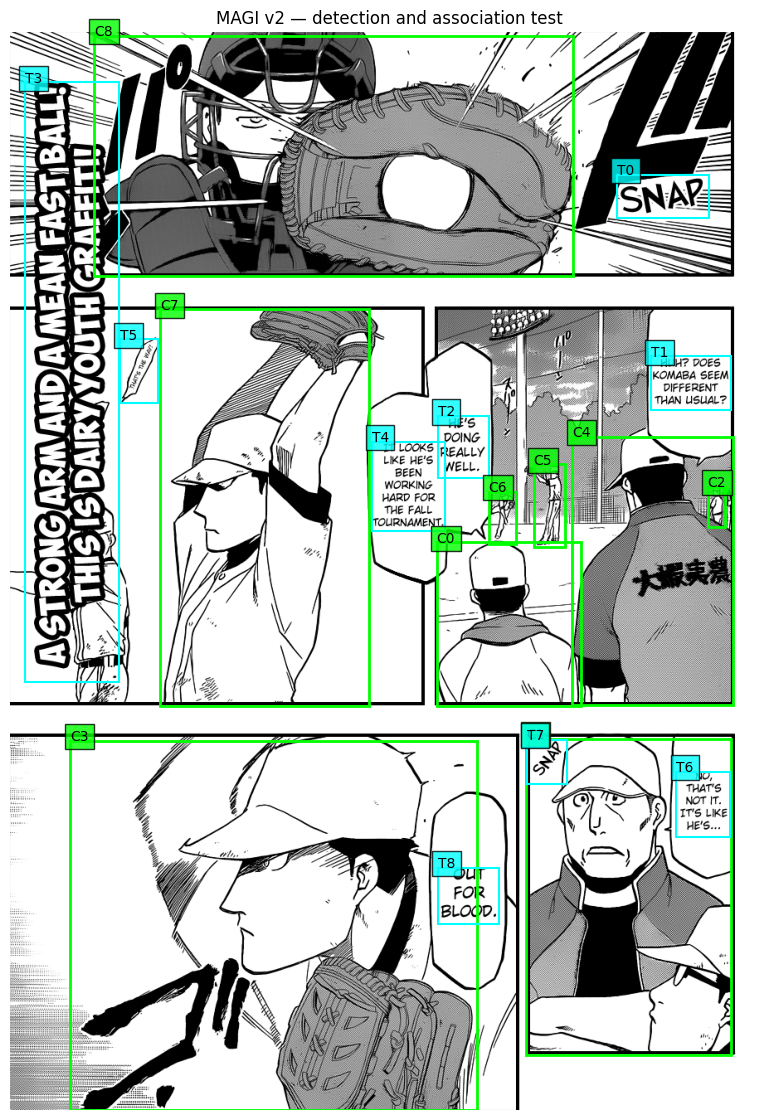

In [28]:
import numpy as np
import torch
import matplotlib.pyplot as plt
import matplotlib.patches as patches
from PIL import Image
from pathlib import Path

DATA = Path(
    "/kaggle/input/datasets/kavyabatra32/mangaset/"
    "manga_folder/BYTE ML Task Data"
)

seq_id = "seq_2032620aa4e4ac7f"
image_path = DATA / "development" / "images" / seq_id / "01.png"

# MAGI expects images as NumPy arrays in RGB format.
image = np.array(Image.open(image_path).convert("RGB"))

print("Image shape:", image.shape)
print("Model device:", next(magi.parameters()).device)
print("Internal OCR disabled:", magi.config.disable_ocr)

# Run MAGI's learned detection and association models.
with torch.inference_mode():
    outputs = magi.predict_detections_and_associations([image])

assert len(outputs) == 1
page = outputs[0]

print("\n=== MAGI results ===")
print("Panels:", len(page["panels"]))
print("Text regions:", len(page["texts"]))
print("Character detections:", len(page["characters"]))
print("Speech tails:", len(page["tails"]))
print("Text-character associations:", len(page["text_character_associations"]))
print("Text-tail associations:", len(page["text_tail_associations"]))
print("Character clusters:", page["character_cluster_labels"])
print("Dialogue flags:", page["is_essential_text"])

print("\nText region -> character association:")
for text_idx, char_idx in page["text_character_associations"]:
    print(
        f"Text {text_idx}: box={page['texts'][text_idx]} "
        f"-> Character {char_idx}: box={page['characters'][char_idx]}"
    )

# Visualise MAGI's boxes on the page.
fig, ax = plt.subplots(figsize=(10, 14))
ax.imshow(image)
ax.axis("off")
ax.set_title("MAGI v2 — detection and association test")

for i, bbox in enumerate(page["characters"]):
    x1, y1, x2, y2 = bbox
    ax.add_patch(
        patches.Rectangle(
            (x1, y1), x2 - x1, y2 - y1,
            linewidth=2, edgecolor="lime", facecolor="none"
        )
    )
    ax.text(x1, y1, f"C{i}", color="black",
            bbox=dict(facecolor="lime", alpha=0.8))

for i, bbox in enumerate(page["texts"]):
    x1, y1, x2, y2 = bbox
    ax.add_patch(
        patches.Rectangle(
            (x1, y1), x2 - x1, y2 - y1,
            linewidth=1.5, edgecolor="cyan", facecolor="none"
        )
    )
    ax.text(x1, y1, f"T{i}", color="black",
            bbox=dict(facecolor="cyan", alpha=0.8))

plt.show()

In [29]:
print("Text boxes:", len(page["texts"]))
print("Character boxes:", len(page["characters"]))

print("\nText -> character associations:")
for association in page["text_character_associations"]:
    print(association)

print("\nText -> speech-tail associations:")
for association in page["text_tail_associations"]:
    print(association)

print("\nCharacter cluster labels:")
print(page["character_cluster_labels"])

print("\nEssential-text flags:")
print(page["is_essential_text"])

print("\nFirst few text boxes:")
for i, box in enumerate(page["texts"][:10]):
    print(f"T{i}: {box}")

Text boxes: 9
Character boxes: 9

Text -> character associations:
[0, 8]
[1, 4]
[2, 0]
[3, 7]
[4, 0]
[5, 7]
[6, 1]
[7, 1]
[8, 3]

Text -> speech-tail associations:
[1, 0]
[2, 1]
[4, 1]
[6, 2]
[8, 3]

Character cluster labels:
[0, 1, 2, 0, 3, 4, 5, 0, 0]

Essential-text flags:
[False, True, True, False, True, False, True, False, True]

First few text boxes:
T0: [731.3944091796875, 171.41085815429688, 842.7608642578125, 223.9112091064453]
T1: [772.316650390625, 390.62835693359375, 869.1219482421875, 455.7733459472656]
T2: [515.0610961914062, 462.5460205078125, 576.7001953125, 536.9521484375]
T3: [17.299072265625, 60.31071472167969, 131.40817260742188, 783.3953857421875]
T4: [435.446533203125, 493.7414855957031, 524.6486206054688, 601.3778686523438]
T5: [132.16497802734375, 370.0383605957031, 178.38137817382812, 446.8619079589844]
T6: [803.23193359375, 891.4429931640625, 867.975830078125, 970.2380981445312]
T7: [622.4010620117188, 852.9501342773438, 671.294921875, 905.9039306640625]
T8: [

In [30]:
import json
import time
from pathlib import Path

import numpy as np
import torch
from PIL import Image

DATA = Path(
    "/kaggle/input/datasets/kavyabatra32/mangaset/"
    "manga_folder/BYTE ML Task Data"
)
WORK = Path("/kaggle/working")
OUT = WORK / "visual_speaker_data" / "magi_validation"
OUT.mkdir(parents=True, exist_ok=True)

with (WORK / "split_info.json").open(encoding="utf-8") as f:
    split = json.load(f)

with (DATA / "sequences.json").open(encoding="utf-8") as f:
    metadata = json.load(f)

metadata_by_id = {
    row["sequence_id"]: row
    for row in metadata
}

val_ids = sorted(split["val_ids"])

assert len(val_ids) == 16
assert next(magi.parameters()).device.type in {"cuda", "cpu"}

def make_json_safe(value):
    if isinstance(value, dict):
        return {str(k): make_json_safe(v) for k, v in value.items()}
    if isinstance(value, (list, tuple)):
        return [make_json_safe(v) for v in value]
    if isinstance(value, np.ndarray):
        return make_json_safe(value.tolist())
    if isinstance(value, np.generic):
        return value.item()
    if isinstance(value, torch.Tensor):
        return make_json_safe(value.detach().cpu().tolist())
    return value

start = time.time()
total_texts = 0
total_characters = 0
total_associations = 0
reused = 0
processed = 0

for i, sid in enumerate(val_ids, start=1):
    output_path = OUT / f"{sid}.json"

    # Reuse only outputs that contain all three pages.
    if output_path.exists():
        try:
            saved = json.loads(output_path.read_text(encoding="utf-8"))
            if (
                saved.get("sequence_id") == sid
                and len(saved.get("pages", [])) == 3
            ):
                reused += 1
                total_texts += sum(
                    len(p["texts"]) for p in saved["pages"]
                )
                total_characters += sum(
                    len(p["characters"]) for p in saved["pages"]
                )
                total_associations += sum(
                    len(p["text_character_associations"])
                    for p in saved["pages"]
                )
                print(f"{i}/16 — reused {sid}")
                continue
        except (OSError, ValueError, TypeError):
            pass

    meta = metadata_by_id[sid]
    image_paths = [DATA / rel for rel in meta["images"]]

    if len(image_paths) != 3 or not all(p.exists() for p in image_paths):
        raise FileNotFoundError(f"Missing one or more pages for {sid}")

    images = [
        np.array(Image.open(p).convert("RGB"))
        for p in image_paths
    ]

    # One MAGI batch per three-page sequence; internal OCR remains disabled.
    with torch.inference_mode():
        results = magi.predict_detections_and_associations(images)

    if len(results) != 3:
        raise RuntimeError(
            f"{sid}: expected 3 page results, got {len(results)}"
        )

    page_records = []
    for rel, result in zip(meta["images"], results):
        result = make_json_safe(result)
        page_records.append({
            "image_path": rel,
            **result,
        })

    saved = {
        "sequence_id": sid,
        "pages": page_records,
        "model": "ragavsachdeva/magiv2",
        "internal_ocr_disabled": True,
    }

    tmp = output_path.with_suffix(".tmp")
    tmp.write_text(
        json.dumps(saved, ensure_ascii=False),
        encoding="utf-8",
    )
    tmp.replace(output_path)

    total_texts += sum(len(p["texts"]) for p in page_records)
    total_characters += sum(len(p["characters"]) for p in page_records)
    total_associations += sum(
        len(p["text_character_associations"]) for p in page_records
    )
    processed += 1

    print(
        f"{i}/16 — processed {sid} | "
        f"texts={sum(len(p['texts']) for p in page_records)}, "
        f"characters={sum(len(p['characters']) for p in page_records)}"
    )

print("\n--- MAGI validation summary ---")
print("Validation sequences:", len(val_ids))
print("Newly processed:", processed)
print("Reused:", reused)
print("Text regions:", total_texts)
print("Character detections:", total_characters)
print("Text-character associations:", total_associations)
print(f"Elapsed: {(time.time() - start) / 60:.1f} minutes")
print("Outputs:", OUT)

1/16 — processed seq_2032620aa4e4ac7f | texts=18, characters=34
2/16 — processed seq_45c9871f52e99417 | texts=25, characters=25
3/16 — processed seq_5f9ee35846b7e635 | texts=16, characters=23
4/16 — processed seq_84541a1f4b159018 | texts=44, characters=28
5/16 — processed seq_952f154fb1505883 | texts=37, characters=43
6/16 — processed seq_96839890d69d7698 | texts=12, characters=21
7/16 — processed seq_a3bd36201a0cd61b | texts=40, characters=30
8/16 — processed seq_b136f32c2233b97c | texts=17, characters=9
9/16 — processed seq_b8b5563330fdc89d | texts=32, characters=42
10/16 — processed seq_b9b5a9ad9a64ced9 | texts=31, characters=28
11/16 — processed seq_d749b853cf795b6a | texts=26, characters=26
12/16 — processed seq_d8afceb0e8f9122d | texts=20, characters=16
13/16 — processed seq_da71f7a842c91090 | texts=47, characters=27
14/16 — processed seq_de542b63e6b19bc2 | texts=18, characters=13
15/16 — processed seq_e8b4f75454f9491f | texts=18, characters=28
16/16 — processed seq_f7f9d9dbf5b05

In [31]:
import json
import inspect
from pathlib import Path

WORK = Path("/kaggle/working")
MAGI_OUT = WORK / "visual_speaker_data" / "magi_validation"

sid = "seq_2032620aa4e4ac7f"
path = MAGI_OUT / f"{sid}.json"

record = json.loads(path.read_text(encoding="utf-8"))

print("Sequence:", record["sequence_id"])
print("Saved pages:", len(record["pages"]))

page0 = record["pages"][0]

print("\nPage-level fields:")
print(list(page0.keys()))

for key in [
    "texts",
    "characters",
    "tails",
    "text_character_associations",
    "text_tail_associations",
    "character_cluster_labels",
    "is_essential_text",
]:
    value = page0.get(key)
    print(f"\n{key}:")
    if isinstance(value, list):
        print("Count:", len(value))
        print("First 3:", value[:3])
    else:
        print(value)

print("\n=== Relevant MAGI model methods ===")
for name in dir(magi):
    if any(term in name.lower() for term in [
        "predict", "cluster", "chapter", "character", "association", "bank"
    ]):
        method = getattr(magi, name, None)
        if callable(method):
            try:
                print(name, inspect.signature(method))
            except (TypeError, ValueError):
                print(name, "(signature unavailable)")

print("\n=== Cached OCR row example ===")
ocr_path = WORK / "visual_speaker_data" / "validation_bubble_ocr.jsonl"

with ocr_path.open(encoding="utf-8") as f:
    ocr_row = json.loads(next(line for line in f if line.strip()))

print("OCR fields:", list(ocr_row.keys()))
print("Text:", repr(ocr_row.get("text")))
print("YOLO box:", ocr_row.get("bbox_xyxy"))
print("MAGI sample page:", page0.get("image_path"))

Sequence: seq_2032620aa4e4ac7f
Saved pages: 3

Page-level fields:
['image_path', 'panels', 'texts', 'characters', 'tails', 'text_character_associations', 'text_tail_associations', 'character_cluster_labels', 'is_essential_text']

texts:
Count: 9
First 3: [[731.474609375, 171.1085205078125, 842.8521728515625, 223.68873596191406], [772.3875732421875, 390.1160583496094, 869.118408203125, 455.2357177734375], [515.1262817382812, 461.8316955566406, 576.7526245117188, 536.22607421875]]

characters:
Count: 9
First 3: [[513.9364624023438, 614.2447509765625, 688.3681030273438, 811.7070922851562], [622.2086181640625, 850.7453002929688, 869.2652587890625, 1232.5882568359375], [840.8655395507812, 547.374755859375, 862.498779296875, 596.000244140625]]

tails:
Count: 4
First 3: [[820.60595703125, 501.56982421875, 845.3997192382812, 530.7734985351562], [547.527587890625, 585.960205078125, 574.7301635742188, 617.275146484375], [780.9159545898438, 944.771484375, 807.5355224609375, 973.1773681640625]]

t

In [32]:
import inspect

model_class = type(magi)

for method_name in [
    "do_chapter_wide_prediction",
    "assign_names_to_characters",
    "predict_crop_embeddings",
]:
    method = getattr(model_class, method_name)

    print(f"\n{'=' * 20} {method_name} {'=' * 20}")
    print("Signature:", inspect.signature(method))

    source = inspect.getsource(method)
    print(source[:14000])

    if len(source) > 14000:
        print("\n... source truncated for readability ...")


==================== do_chapter_wide_prediction ====================
Signature: (self, pages_in_order, character_bank, eta=0.75, batch_size=8, use_tqdm=False, do_ocr=True)
    @torch.no_grad()
    def do_chapter_wide_prediction(self, pages_in_order, character_bank, eta=0.75, batch_size=8, use_tqdm=False, do_ocr=True):
        texts = []
        characters = []
        character_clusters = []
        if use_tqdm:
            from tqdm import tqdm
            iterator = tqdm(range(0, len(pages_in_order), batch_size))
        else:
            iterator = range(0, len(pages_in_order), batch_size)
        per_page_results = []
        for i in iterator:
            pages = pages_in_order[i:i+batch_size]
            results = self.predict_detections_and_associations(pages)
            per_page_results.extend([result for result in results])

        texts = [result["texts"] for result in per_page_results]
        characters = [result["characters"] for result in per_page_results]
        char

In [33]:
import json
from pathlib import Path

import numpy as np
import torch
from PIL import Image

DATA = Path(
    "/kaggle/input/datasets/kavyabatra32/mangaset/"
    "manga_folder/BYTE ML Task Data"
)
WORK = Path("/kaggle/working")

seq_id = "seq_2032620aa4e4ac7f"
cached_path = (
    WORK / "visual_speaker_data" / "magi_validation" / f"{seq_id}.json"
)

with cached_path.open(encoding="utf-8") as f:
    cached = json.load(f)

image_paths = [
    DATA / page["image_path"]
    for page in cached["pages"]
]
images = [
    np.array(Image.open(path).convert("RGB"))
    for path in image_paths
]

# Build a prototype bank from the first page's character detections.
first_page = cached["pages"][0]
prototypes = []
prototype_names = []

img_h, img_w = images[0].shape[:2]

for i, bbox in enumerate(first_page["characters"]):
    x1, y1, x2, y2 = bbox

    x1 = max(0, int(np.floor(x1)))
    y1 = max(0, int(np.floor(y1)))
    x2 = min(img_w, int(np.ceil(x2)))
    y2 = min(img_h, int(np.ceil(y2)))

    if x2 <= x1 or y2 <= y1:
        continue

    crop = images[0][y1:y2, x1:x2]

    if crop.size == 0:
        continue

    prototypes.append(crop.copy())
    prototype_names.append(f"ref_char_{i}")

assert prototypes, "No usable character prototypes found on page 1."

character_bank = {
    "images": prototypes,
    "names": prototype_names,
}

print("Sequence:", seq_id)
print("Pages:", len(images))
print("Prototype characters:", len(prototypes))
print("Internal OCR disabled:", magi.config.disable_ocr)
print("Running chapter-wide identity assignment...")

with torch.inference_mode():
    chapter_results = magi.do_chapter_wide_prediction(
        pages_in_order=images,
        character_bank=character_bank,
        eta=0.75,
        batch_size=3,
        use_tqdm=False,
        do_ocr=False,
    )

assert len(chapter_results) == 3

print("\n=== Chapter-wide identities ===")

for page_idx, result in enumerate(chapter_results, start=1):
    names = result["character_names"]
    associations = result["text_character_associations"]
    essential = result["is_essential_text"]

    print(f"\nPage {page_idx}")
    print("Character detections:", len(result["characters"]))
    print("Assigned identities:", names)

    print("Essential text -> identity:")
    for text_idx, char_idx in associations:
        if (
            text_idx < len(essential)
            and essential[text_idx]
            and char_idx < len(names)
        ):
            print(f"  Text {text_idx} -> {names[char_idx]}")

print("\nChapter-wide test completed.")

Sequence: seq_2032620aa4e4ac7f
Pages: 3
Prototype characters: 9
Internal OCR disabled: True
Running chapter-wide identity assignment...
Welcome to the CBC MILP Solver 
Version: 2.10.3 
Build Date: Dec 15 2019 

command line - /usr/local/lib/python3.13/dist-packages/pulp/apis/../solverdir/cbc/linux/i64/cbc /tmp/ade9e8d4c4db4da09fbe6e5158a60657-pulp.mps -timeMode elapsed -solve -printingOptions all -solution /tmp/ade9e8d4c4db4da09fbe6e5158a60657-pulp.sol (default strategy 1)
At line 2 NAME          MODEL
At line 3 ROWS
At line 1791 COLUMNS
At line 6656 RHS
At line 8443 BOUNDS
At line 8784 ENDATA
Problem MODEL has 1786 rows, 340 columns and 3844 elements
Coin0008I MODEL read with 0 errors
Option for timeMode changed from cpu to elapsed
Continuous objective value is 21.9489 - 0.00 seconds
Cgl0003I 0 fixed, 0 tightened bounds, 822 strengthened rows, 0 substitutions
Cgl0003I 0 fixed, 0 tightened bounds, 738 strengthened rows, 0 substitutions
Cgl0003I 0 fixed, 0 tightened bounds, 679 strength

In [34]:
import json
import time
from pathlib import Path

import numpy as np
import torch
from PIL import Image

DATA = Path(
    "/kaggle/input/datasets/kavyabatra32/mangaset/"
    "manga_folder/BYTE ML Task Data"
)
WORK = Path("/kaggle/working")
OUT = WORK / "visual_speaker_data" / "magi_training"
OUT.mkdir(parents=True, exist_ok=True)

with (WORK / "split_info.json").open(encoding="utf-8") as f:
    split = json.load(f)

with (DATA / "sequences.json").open(encoding="utf-8") as f:
    metadata = json.load(f)

metadata_by_id = {row["sequence_id"]: row for row in metadata}
train_ids = sorted(split["train_ids"])

assert len(train_ids) == 64
assert "magi" in globals(), "MAGI is not loaded in this kernel."

def json_safe(value):
    if isinstance(value, dict):
        return {str(k): json_safe(v) for k, v in value.items()}
    if isinstance(value, (list, tuple)):
        return [json_safe(v) for v in value]
    if isinstance(value, np.ndarray):
        return json_safe(value.tolist())
    if isinstance(value, np.generic):
        return value.item()
    if isinstance(value, torch.Tensor):
        return json_safe(value.detach().cpu().tolist())
    return value

start = time.time()
processed = 0
reused = 0

for i, sid in enumerate(train_ids, start=1):
    output_path = OUT / f"{sid}.json"

    if output_path.exists():
        try:
            saved = json.loads(output_path.read_text(encoding="utf-8"))
            if (
                saved.get("sequence_id") == sid
                and len(saved.get("pages", [])) == 3
            ):
                reused += 1
                print(f"{i}/64 — reused {sid}")
                continue
        except (OSError, ValueError, TypeError):
            pass

    meta = metadata_by_id[sid]
    image_paths = [DATA / rel for rel in meta["images"]]

    if len(image_paths) != 3 or not all(p.exists() for p in image_paths):
        raise FileNotFoundError(f"Missing page image for {sid}")

    images = [
        np.array(Image.open(path).convert("RGB"))
        for path in image_paths
    ]

    # No hosted API and no internal MAGI OCR.
    with torch.inference_mode():
        results = magi.predict_detections_and_associations(images)

    if len(results) != 3:
        raise RuntimeError(f"{sid}: expected 3 page results, got {len(results)}")

    pages = []
    for page_index, (relative_path, result) in enumerate(
        zip(meta["images"], results), start=1
    ):
        pages.append({
            "page_index": page_index,
            "image_path": relative_path,
            **json_safe(result),
        })

    record = {
        "sequence_id": sid,
        "pages": pages,
        "model": "ragavsachdeva/magiv2",
        "internal_ocr_disabled": True,
    }

    tmp_path = output_path.with_suffix(".tmp")
    tmp_path.write_text(
        json.dumps(record, ensure_ascii=False),
        encoding="utf-8",
    )
    tmp_path.replace(output_path)
    processed += 1

    if i % 8 == 0 or i == len(train_ids):
        print(
            f"{i}/64 training sequences | "
            f"processed={processed}, reused={reused} | "
            f"{(time.time() - start) / 60:.1f} min"
        )

print("\n--- Training feature generation complete ---")
print("Training sequences:", len(train_ids))
print("Newly processed:", processed)
print("Reused:", reused)
print("Output directory:", OUT)

8/64 training sequences | processed=8, reused=0 | 0.1 min
16/64 training sequences | processed=16, reused=0 | 0.2 min
24/64 training sequences | processed=24, reused=0 | 0.3 min
32/64 training sequences | processed=32, reused=0 | 0.4 min
40/64 training sequences | processed=40, reused=0 | 0.5 min
48/64 training sequences | processed=48, reused=0 | 0.6 min
56/64 training sequences | processed=56, reused=0 | 0.7 min
64/64 training sequences | processed=64, reused=0 | 0.8 min

--- Training feature generation complete ---
Training sequences: 64
Newly processed: 64
Reused: 0
Output directory: /kaggle/working/visual_speaker_data/magi_training


In [36]:
import json
from pathlib import Path
from collections import defaultdict

WORK = Path("/kaggle/working")
VIS = WORK / "visual_speaker_data"

with (WORK / "split_info.json").open(encoding="utf-8") as f:
    split = json.load(f)

# Index PaddleOCR fragments by sequence and page.
ocr_by_page = defaultdict(list)

for filename in [
    "training_bubble_ocr.jsonl",
    "validation_bubble_ocr.jsonl",
]:
    path = VIS / filename
    assert path.exists(), f"Missing OCR export: {path}"

    with path.open(encoding="utf-8") as f:
        for line in f:
            if not line.strip():
                continue

            row = json.loads(line)
            key = (row["sequence_id"], int(row["page_index"]))

            # Use individual full-page OCR regions, not the larger
            # YOLO bubble boxes, for text-to-text matching.
            for part in row.get("ocr_parts", []):
                if part.get("text") and part.get("bbox_xyxy"):
                    ocr_by_page[key].append({
                        "text": part["text"],
                        "score": float(part.get("score", 0.0)),
                        "bbox": part["bbox_xyxy"],
                    })

train_ids = set(split["train_ids"])
val_ids = set(split["val_ids"])

sources = [
    ("train", train_ids, VIS / "magi_training"),
    ("validation", val_ids, VIS / "magi_validation"),
]

output_path = VIS / "integrated_train_val.jsonl"

stats = defaultdict(lambda: {
    "sequences": 0,
    "magi_text_boxes": 0,
    "boxes_with_ocr": 0,
    "ocr_fragments_matched": 0,
    "ocr_fragments_unmatched": 0,
    "essential_text_boxes": 0,
})

def area(box):
    return max(0.0, box[2] - box[0]) * max(0.0, box[3] - box[1])

def overlap_fraction(inner, outer):
    """Fraction of the OCR fragment lying inside a MAGI text box."""
    ix1 = max(float(inner[0]), float(outer[0]))
    iy1 = max(float(inner[1]), float(outer[1]))
    ix2 = min(float(inner[2]), float(outer[2]))
    iy2 = min(float(inner[3]), float(outer[3]))

    intersection = max(0.0, ix2 - ix1) * max(0.0, iy2 - iy1)
    return intersection / max(area(inner), 1.0)

def center_inside(inner, outer):
    cx = (float(inner[0]) + float(inner[2])) / 2
    cy = (float(inner[1]) + float(inner[3])) / 2
    return (
        float(outer[0]) <= cx <= float(outer[2])
        and float(outer[1]) <= cy <= float(outer[3])
    )

written = 0

with output_path.open("w", encoding="utf-8") as out:
    for fold, sequence_ids, folder in sources:
        for sid in sorted(sequence_ids):
            magi_path = folder / f"{sid}.json"
            assert magi_path.exists(), f"Missing MAGI result: {magi_path}"

            record = json.loads(magi_path.read_text(encoding="utf-8"))
            assert len(record.get("pages", [])) == 3, (
                f"Expected 3 pages for {sid}"
            )

            stats[fold]["sequences"] += 1

            for page_index, page in enumerate(record["pages"], start=1):
                text_boxes = page.get("texts", [])
                characters = page.get("characters", [])
                clusters = page.get("character_cluster_labels", [])
                essential_flags = page.get("is_essential_text", [])

                # One text box can have a character association and/or
                # a speech-tail association.
                chars_for_text = defaultdict(list)
                for text_idx, char_idx in page.get(
                    "text_character_associations", []
                ):
                    chars_for_text[int(text_idx)].append(int(char_idx))

                tails_for_text = defaultdict(list)
                for text_idx, tail_idx in page.get(
                    "text_tail_associations", []
                ):
                    tails_for_text[int(text_idx)].append(int(tail_idx))

                parts = ocr_by_page[(sid, page_index)]
                parts_by_text = [[] for _ in text_boxes]
                unmatched_parts = 0

                # Assign every OCR fragment to at most one MAGI text box.
                for part in parts:
                    candidates = []

                    for text_idx, text_box in enumerate(text_boxes):
                        overlap = overlap_fraction(part["bbox"], text_box)
                        inside = center_inside(part["bbox"], text_box)

                        if inside or overlap >= 0.15:
                            # Prefer a box containing the OCR centre,
                            # then greater overlap, then the smaller box.
                            candidates.append((
                                int(inside),
                                overlap,
                                -area(text_box),
                                text_idx,
                            ))

                    if candidates:
                        best_text_idx = max(candidates)[3]
                        parts_by_text[best_text_idx].append(part)
                    else:
                        unmatched_parts += 1

                stats[fold]["ocr_fragments_matched"] += (
                    len(parts) - unmatched_parts
                )
                stats[fold]["ocr_fragments_unmatched"] += unmatched_parts

                for text_idx, text_box in enumerate(text_boxes):
                    matched_parts = sorted(
                        parts_by_text[text_idx],
                        key=lambda p: (
                            (p["bbox"][1] + p["bbox"][3]) / 2,
                            (p["bbox"][0] + p["bbox"][2]) / 2,
                        ),
                    )

                    recognised_text = " ".join(
                        part["text"].strip()
                        for part in matched_parts
                        if part["text"].strip()
                    ).strip()

                    recognised_text = " ".join(recognised_text.split())

                    character_indices = sorted(set(
                        chars_for_text.get(text_idx, [])
                    ))

                    associated_characters = [
                        {
                            "character_index": char_idx,
                            "bbox_xyxy": (
                                characters[char_idx]
                                if char_idx < len(characters)
                                else None
                            ),
                            "page_cluster": (
                                clusters[char_idx]
                                if char_idx < len(clusters)
                                else None
                            ),
                        }
                        for char_idx in character_indices
                    ]

                    essential = (
                        bool(essential_flags[text_idx])
                        if text_idx < len(essential_flags)
                        else None
                    )

                    row = {
                        "sequence_id": sid,
                        "split": fold,
                        "page_index": page_index,
                        "image_path": page["image_path"],
                        "text_region_index": text_idx,
                        "magi_text_bbox_xyxy": text_box,
                        "ocr_text": recognised_text,
                        "ocr_fragment_count": len(matched_parts),
                        "ocr_confidence_mean": (
                            sum(p["score"] for p in matched_parts)
                            / len(matched_parts)
                            if matched_parts else None
                        ),
                        "magi_character_indices": character_indices,
                        "magi_character_associations": associated_characters,
                        "magi_tail_indices": tails_for_text.get(text_idx, []),
                        "magi_is_essential_text": essential,
                    }

                    out.write(json.dumps(row, ensure_ascii=False) + "\n")
                    written += 1

                    stats[fold]["magi_text_boxes"] += 1
                    stats[fold]["boxes_with_ocr"] += bool(recognised_text)
                    stats[fold]["essential_text_boxes"] += bool(essential)

print("Saved integrated records:", written)
print("Output:", output_path)

for fold in ["train", "validation"]:
    print(f"\n--- {fold.upper()} ---")
    for key, value in stats[fold].items():
        print(f"{key}: {value}")

Saved integrated records: 2182
Output: /kaggle/working/visual_speaker_data/integrated_train_val.jsonl

--- TRAIN ---
sequences: 64
magi_text_boxes: 1750
boxes_with_ocr: 1432
ocr_fragments_matched: 5310
ocr_fragments_unmatched: 20
essential_text_boxes: 1497

--- VALIDATION ---
sequences: 16
magi_text_boxes: 432
boxes_with_ocr: 346
ocr_fragments_matched: 1299
ocr_fragments_unmatched: 14
essential_text_boxes: 354


In [37]:
import json
from pathlib import Path
from collections import defaultdict

WORK = Path("/kaggle/working")
DATA = Path(
    "/kaggle/input/datasets/kavyabatra32/mangaset/"
    "manga_folder/BYTE ML Task Data"
)

with (WORK / "split_info.json").open(encoding="utf-8") as f:
    split = json.load(f)

train_ids = set(split["train_ids"])

# Load the human annotations.
labels = {}
with (DATA / "development" / "labels.jsonl").open(encoding="utf-8") as f:
    for line in f:
        if line.strip():
            record = json.loads(line)
            labels[record["sequence_id"]] = record

# Load integrated PaddleOCR + MAGI records.
integrated = defaultdict(list)
path = WORK / "visual_speaker_data" / "integrated_train_val.jsonl"

with path.open(encoding="utf-8") as f:
    for line in f:
        if line.strip():
            row = json.loads(line)
            integrated[row["sequence_id"]].append(row)

# Choose a training sequence with many annotated utterances.
candidates = [
    sid for sid in train_ids
    if sid in labels and sid in integrated
]
sid = max(
    candidates,
    key=lambda s: sum(len(page) for page in labels[s]["pages"])
)

print("Training sequence:", sid)
print("Ground-truth utterances:", sum(len(p) for p in labels[sid]["pages"]))

for page_index in range(1, 4):
    print(f"\n{'=' * 24} PAGE {page_index} {'=' * 24}")

    gold = labels[sid]["pages"][page_index - 1]
    rows = [
        r for r in integrated[sid]
        if int(r["page_index"]) == page_index
    ]
    rows.sort(key=lambda r: (
        (r["magi_text_bbox_xyxy"][1] + r["magi_text_bbox_xyxy"][3]) / 2,
        r["magi_text_bbox_xyxy"][0],
    ))

    print("\nGROUND TRUTH:")
    for item in gold:
        print(f"  [{item['speaker']}] {item['text']}")

    print("\nINTEGRATED TEXT REGIONS (top-to-bottom):")
    for row in rows[:25]:
        associations = row["magi_character_associations"]
        char_ids = [x["character_index"] for x in associations]

        print(
            f"  T{row['text_region_index']:02d} | "
            f"essential={str(row['magi_is_essential_text']):5s} | "
            f"chars={char_ids!s:10s} | "
            f"OCR={row['ocr_text']!r}"
        )

    if len(rows) > 25:
        print(f"  ... {len(rows) - 25} more regions omitted")
        

Training sequence: seq_71033fec4de494fc
Ground-truth utterances: 47

======================== PAGE 1 ========================

GROUND TRUTH:
  [character1] WOAHH!! ...THE SNAKE!!?
  [character1] TAKE IT OFF! TAKE IT OFF!!
  [character1] THIS IS BAD! IT'S GOING TO BITE ME!
  [character1] WAAAAAHHH
  [character2] NANKURU-NAISA.
  [character3] HAHA, YOU SURE SCARE EASY KID~ BUT THAT'S A GOOD THING.
  [character3] REAL VIPERS ARE ACTUALLY VERY DANGEROUS.
  [character3] IF YOU SEE A VIPER OUTSIDE, YOU SHOULD GET OUT OF THERE RIGHT AWAY!
  [character3] IF YOU GET BITTEN, YOU MIGHT END UP LOSING YOUR LIFE.
  [character3] DO YOU KNOW WHERE SNAKES TEND TO BITE THE MOST?
  [character1] UH...? THE LEGS?
  [character3] YES! THEY GO FOR THE FEET!
  [character3] A BITE TO THE FEET WILL PUT YOU TO SLEEP, AND THEN YOU MIGHT NEVER SNAKE UP AGAIN!
  [character3] ...GET IT?

INTEGRATED TEXT REGIONS (top-to-bottom):
  T06 | essential=False | chars=[7]        | OCR=''
  T05 | essential=True  | chars=[0]   

In [38]:
import json
import re
from pathlib import Path
from collections import Counter, defaultdict

WORK = Path("/kaggle/working")
DATA = Path(
    "/kaggle/input/datasets/kavyabatra32/mangaset/"
    "manga_folder/BYTE ML Task Data"
)
VIS = WORK / "visual_speaker_data"

with (WORK / "split_info.json").open(encoding="utf-8") as f:
    split = json.load(f)

train_ids = set(split["train_ids"])
val_ids = set(split["val_ids"])

# Load ground-truth utterances.
labels = {}
with (DATA / "development" / "labels.jsonl").open(
    encoding="utf-8"
) as f:
    for line in f:
        if line.strip():
            row = json.loads(line)
            labels[row["sequence_id"]] = row

# Load our integrated PaddleOCR + MAGI records.
integrated = defaultdict(list)
with (VIS / "integrated_train_val.jsonl").open(
    encoding="utf-8"
) as f:
    for line in f:
        if line.strip():
            row = json.loads(line)
            integrated[row["sequence_id"]].append(row)


def normalise(text):
    text = str(text).upper()
    # Join OCR line-break hyphenation, e.g. "DAN- GEROUS".
    text = re.sub(r"(?<=[A-Z])-\s+(?=[A-Z])", "", text)
    return re.findall(r"[A-Z0-9]+", text)


def score_text(predicted, gold):
    p = Counter(normalise(predicted))
    g = Counter(normalise(gold))

    if not p or not g:
        return 0.0, 0.0, 0.0, 0

    common = sum((p & g).values())
    precision = common / sum(p.values())
    recall = common / sum(g.values())

    f1 = (
        2 * precision * recall / (precision + recall)
        if precision + recall else 0.0
    )
    return f1, precision, recall, common


THRESHOLD_F1 = 0.35
MIN_COMMON_TOKENS = 2
MIN_PRECISION = 0.60

summary = {
    "train": defaultdict(int),
    "validation": defaultdict(int),
}
matched_examples = []
unmatched_examples = []
per_sequence = {}

for sid in sorted(train_ids | val_ids):
    if sid not in labels or sid not in integrated:
        continue

    fold = "train" if sid in train_ids else "validation"
    ref_pages = labels[sid]["pages"]

    rows_by_page = defaultdict(list)
    for row in integrated[sid]:
        rows_by_page[int(row["page_index"]) - 1].append(row)

    sequence_matches = 0
    sequence_rows = 0

    for page_idx, gold_rows in enumerate(ref_pages):
        predicted_rows = rows_by_page[page_idx]
        summary[fold]["gold_utterances"] += len(gold_rows)
        summary[fold]["integrated_regions"] += len(predicted_rows)

        # Allow multiple OCR regions to match the same gold utterance.
        best_gold_region = defaultdict(float)
        best_region_text = defaultdict(str)

        for row in predicted_rows:
            pred_text = row["ocr_text"].strip()
            if not pred_text:
                continue

            candidates = []
            for gold_idx, gold_row in enumerate(gold_rows):
                f1, precision, recall, common = score_text(
                    pred_text, gold_row["text"]
                )
                candidates.append((
                    f1, precision, recall, common, gold_idx
                ))

            if not candidates:
                continue

            best = max(candidates)
            f1, precision, recall, common, gold_idx = best

            accepted = (
                common >= MIN_COMMON_TOKENS
                and precision >= MIN_PRECISION
                and f1 >= THRESHOLD_F1
            )

            if accepted:
                gold_row = gold_rows[gold_idx]
                sequence_matches += 1
                sequence_rows += 1

                summary[fold]["matched_regions"] += 1
                best_gold_region[gold_idx] = max(
                    best_gold_region[gold_idx], f1
                )
                best_region_text[gold_idx] = pred_text

                if len(matched_examples) < 15:
                    matched_examples.append({
                        "sequence_id": sid,
                        "page": page_idx + 1,
                        "ocr": pred_text,
                        "gold": gold_row["text"],
                        "speaker": gold_row["speaker"],
                        "f1": round(f1, 3),
                        "precision": round(precision, 3),
                        "recall": round(recall, 3),
                    })
            else:
                summary[fold]["unmatched_nonempty_regions"] += 1
                if (
                    row.get("magi_is_essential_text")
                    and len(unmatched_examples) < 15
                ):
                    unmatched_examples.append({
                        "sequence_id": sid,
                        "page": page_idx + 1,
                        "ocr": pred_text,
                        "best_candidate": gold_rows[gold_idx]["text"],
                        "f1": round(f1, 3),
                    })

        # Count gold utterances with at least one sufficiently close region.
        summary[fold]["gold_utterances_with_match"] += sum(
            1 for gold_idx in best_gold_region
            if best_gold_region[gold_idx] >= THRESHOLD_F1
        )

    per_sequence[sid] = sequence_matches


print("=== ALIGNMENT SUMMARY ===")
for fold in ["train", "validation"]:
    s = summary[fold]
    print(f"\n{fold.upper()}")
    for key, value in s.items():
        print(f"{key}: {value}")

    total = s["gold_utterances"]
    covered = s["gold_utterances_with_match"]
    print(
        "Gold utterances with at least one match:",
        f"{covered}/{total} ({covered / total:.1%})" if total else "n/a"
    )

print("\n=== ACCEPTED MATCH EXAMPLES ===")
for row in matched_examples:
    print(
        f"\n{row['sequence_id']} p{row['page']}"
        f" | speaker={row['speaker']}"
        f" | F1={row['f1']}"
    )
    print("  OCR: ", row["ocr"])
    print("  GOLD:", row["gold"])

print("\n=== UNMATCHED ESSENTIAL-TEXT EXAMPLES ===")
for row in unmatched_examples:
    print(
        f"\n{row['sequence_id']} p{row['page']}"
        f" | F1={row['f1']}"
    )
    print("  OCR:  ", row["ocr"])
    print("  CLOSEST GOLD:", row["best_candidate"])

=== ALIGNMENT SUMMARY ===

TRAIN
gold_utterances: 1425
integrated_regions: 1750
matched_regions: 1125
unmatched_nonempty_regions: 307
gold_utterances_with_match: 1096
Gold utterances with at least one match: 1096/1425 (76.9%)

VALIDATION
gold_utterances: 328
integrated_regions: 432
unmatched_nonempty_regions: 59
matched_regions: 287
gold_utterances_with_match: 270
Gold utterances with at least one match: 270/328 (82.3%)

=== ACCEPTED MATCH EXAMPLES ===

seq_032cbb4dc8686963 p1 | speaker=character1 | F1=1.0
  OCR:  I MEAN..
  GOLD: I MEAN...

seq_032cbb4dc8686963 p1 | speaker=character1 | F1=0.571
  OCR:  YOU'RE
  GOLD: YOU'RE THE ONLY ONE

seq_032cbb4dc8686963 p1 | speaker=character1 | F1=0.769
  OCR:  WHO'S EVER SEEN MELIKE THIS.
  GOLD: WHO'S EVER SEEN ME LIKE THIS.

seq_032cbb4dc8686963 p1 | speaker=character2 | F1=0.667
  OCR:  THE TY ONE...?
  GOLD: THE ONLY ONE...?

seq_032cbb4dc8686963 p1 | speaker=character1 | F1=0.769
  OCR:  SOI CAN'T ASK ANYONE ELSE.
  GOLD: SO I CAN'T ASK A

In [39]:
import json
import time
from pathlib import Path

import numpy as np
import torch
from PIL import Image
import torch.nn.functional as F

DATA = Path(
    "/kaggle/input/datasets/kavyabatra32/mangaset/"
    "manga_folder/BYTE ML Task Data"
)
WORK = Path("/kaggle/working")

with (WORK / "split_info.json").open(encoding="utf-8") as f:
    split = json.load(f)

with (DATA / "sequences.json").open(encoding="utf-8") as f:
    metadata = json.load(f)

metadata_by_id = {r["sequence_id"]: r for r in metadata}

OUT = WORK / "visual_speaker_data" / "magi_character_embeddings"
OUT.mkdir(parents=True, exist_ok=True)

# Only the labelled training and validation sequences for now.
sequence_ids = sorted(set(split["train_ids"]) | set(split["val_ids"]))

start = time.time()
new_count = 0
reused_count = 0

for i, sid in enumerate(sequence_ids, start=1):
    output_path = OUT / f"{sid}.json"

    if output_path.exists():
        try:
            saved = json.loads(output_path.read_text(encoding="utf-8"))
            if (
                saved.get("sequence_id") == sid
                and len(saved.get("pages", [])) == 3
                and all("embeddings" in p for p in saved["pages"])
            ):
                reused_count += 1
                if i % 8 == 0 or i == len(sequence_ids):
                    print(f"{i}/{len(sequence_ids)} | reused={reused_count}")
                continue
        except (OSError, ValueError, TypeError):
            pass

    fold = "train" if sid in set(split["train_ids"]) else "validation"
    magi_dir = (
        WORK / "visual_speaker_data"
        / ("magi_training" if fold == "train" else "magi_validation")
    )
    magi_path = magi_dir / f"{sid}.json"

    record = json.loads(magi_path.read_text(encoding="utf-8"))
    meta = metadata_by_id[sid]

    if len(record["pages"]) != 3 or len(meta["images"]) != 3:
        raise ValueError(f"{sid}: expected exactly three pages")

    images = [
        np.array(Image.open(DATA / rel).convert("RGB"))
        for rel in meta["images"]
    ]

    # Bounding boxes are ordered exactly as the saved MAGI character detections.
    boxes_per_page = [
        page.get("characters", []) for page in record["pages"]
    ]

    with torch.inference_mode():
        embeddings_per_page = magi.predict_crop_embeddings(
            images,
            boxes_per_page,
            batch_size=64,
        )

    pages_out = []

    for page_idx, (page, boxes, embeddings) in enumerate(
        zip(record["pages"], boxes_per_page, embeddings_per_page),
        start=1,
    ):
        embeddings = F.normalize(embeddings.detach().float(), p=2, dim=1)
        vectors = embeddings.cpu().numpy().tolist()

        if len(vectors) != len(boxes):
            raise RuntimeError(
                f"{sid}, page {page_idx}: "
                f"{len(vectors)} embeddings for {len(boxes)} character boxes"
            )

        pages_out.append({
            "page_index": page_idx,
            "image_path": page["image_path"],
            "character_boxes": boxes,
            "embeddings": vectors,
        })

    output = {
        "sequence_id": sid,
        "split": fold,
        "embedding_source": "MAGI crop_embedding_model",
        "pages": pages_out,
    }

    tmp = output_path.with_suffix(".tmp")
    tmp.write_text(
        json.dumps(output, ensure_ascii=False),
        encoding="utf-8",
    )
    tmp.replace(output_path)
    new_count += 1

    if i % 8 == 0 or i == len(sequence_ids):
        print(
            f"{i}/{len(sequence_ids)} | "
            f"new={new_count}, reused={reused_count} | "
            f"{(time.time() - start) / 60:.1f} min"
        )

print("\n--- Character embedding summary ---")
print("Sequences:", len(sequence_ids))
print("Newly processed:", new_count)
print("Reused:", reused_count)
print("Output:", OUT)

8/80 | new=8, reused=0 | 0.0 min
16/80 | new=16, reused=0 | 0.1 min
24/80 | new=24, reused=0 | 0.1 min
32/80 | new=32, reused=0 | 0.2 min
40/80 | new=40, reused=0 | 0.2 min
48/80 | new=48, reused=0 | 0.3 min
56/80 | new=56, reused=0 | 0.3 min
64/80 | new=64, reused=0 | 0.4 min
72/80 | new=72, reused=0 | 0.4 min
80/80 | new=80, reused=0 | 0.5 min

--- Character embedding summary ---
Sequences: 80
Newly processed: 80
Reused: 0
Output: /kaggle/working/visual_speaker_data/magi_character_embeddings


In [43]:
import json
import re
from pathlib import Path
from collections import Counter, defaultdict

import numpy as np
from scipy.optimize import linear_sum_assignment

DATA = Path(
    "/kaggle/input/datasets/kavyabatra32/mangaset/"
    "manga_folder/BYTE ML Task Data"
)
WORK = Path("/kaggle/working")
VIS = WORK / "visual_speaker_data"

with (WORK / "split_info.json").open(encoding="utf-8") as f:
    split = json.load(f)

train_ids = set(split["train_ids"])
val_ids = set(split["val_ids"])

# Human annotations
gold_by_id = {}
with (DATA / "development" / "labels.jsonl").open(
    encoding="utf-8"
) as f:
    for line in f:
        if line.strip():
            record = json.loads(line)
            gold_by_id[record["sequence_id"]] = record

# PaddleOCR + MAGI text regions
regions_by_page = defaultdict(list)
with (VIS / "integrated_train_val.jsonl").open(
    encoding="utf-8"
) as f:
    for line in f:
        if line.strip():
            row = json.loads(line)
            regions_by_page[
                (row["sequence_id"], int(row["page_index"]))
            ].append(row)


def tokens(text):
    text = str(text).upper()
    # Undo common OCR line-break hyphenation.
    text = re.sub(r"(?<=[A-Z])-\s+(?=[A-Z])", "", text)
    return re.findall(r"[A-Z0-9]+", text)


def lexical_match(predicted, gold):
    p = tokens(predicted)
    g = tokens(gold)

    if not p or not g:
        return 0.0, 0.0, 0.0, 0

    common = sum((Counter(p) & Counter(g)).values())
    precision = common / len(p)
    recall = common / len(g)
    f1 = (
        2 * precision * recall / (precision + recall)
        if precision + recall else 0.0
    )

    # Exact short utterances such as "WOW!" are valid matches.
    exact = p == g

    acceptable = exact or (
        common >= 2
        and precision >= 0.65
        and f1 >= 0.35
    )

    return f1, precision, recall, int(acceptable)


outputs = {
    "train": VIS / "aligned_utterances_train.jsonl",
    "validation": VIS / "aligned_utterances_validation.jsonl",
}

stats = {
    "train": Counter(),
    "validation": Counter(),
}
examples = []

for fold, sequence_ids in [
    ("train", sorted(train_ids)),
    ("validation", sorted(val_ids)),
]:
    with outputs[fold].open("w", encoding="utf-8") as out:
        for sid in sequence_ids:
            if sid not in gold_by_id:
                raise ValueError(f"Missing annotations for {sid}")

            gold_pages = gold_by_id[sid]["pages"]

            for page_idx, gold_lines in enumerate(gold_pages, start=1):
                regions = regions_by_page[(sid, page_idx)]

                # Only regions with recognisable text are alignment candidates.
                candidates = [
                    row for row in regions
                    if tokens(row.get("ocr_text", ""))
                ]

                stats[fold]["gold_utterances"] += len(gold_lines)
                stats[fold]["ocr_candidates"] += len(candidates)

                if not gold_lines or not candidates:
                    stats[fold]["unmatched_gold"] += len(gold_lines)
                    continue

                # Each candidate gets one matching score per gold utterance.
                weights = np.zeros(
                    (len(candidates), len(gold_lines)),
                    dtype=np.float64,
                )
                details = {}

                for ri, region in enumerate(candidates):
                    for gi, gold in enumerate(gold_lines):
                        f1, precision, recall, acceptable = lexical_match(
                            region["ocr_text"], gold["text"]
                        )
                        if acceptable:
                            # Prefer better lexical matches globally.
                            weights[ri, gi] = (
                                0.70 * f1 + 0.30 * precision + 1e-8
                            )
                            details[(ri, gi)] = (
                                f1, precision, recall
                            )

                # Find the best one-to-one assignment for this page.
                region_indices, gold_indices = linear_sum_assignment(
                    weights, maximize=True
                )

                matched_gold = set()

                for ri, gi in zip(region_indices, gold_indices):
                    if weights[ri, gi] <= 0:
                        continue

                    region = candidates[ri]
                    gold = gold_lines[gi]
                    f1, precision, recall = details[(ri, gi)]

                    # Unknown speakers cannot form reliable supervised pairs.
                    speaker = gold["speaker"]
                    row = {
                        "sequence_id": sid,
                        "split": fold,
                        "page_index": page_idx,
                        "gold_utterance_index": int(gi),
                        "gold_speaker": speaker,
                        "gold_text": gold["text"],
                        "ocr_text": region["ocr_text"],
                        "alignment_f1": round(f1, 4),
                        "alignment_precision": round(precision, 4),
                        "alignment_recall": round(recall, 4),
                        "text_region_index": region["text_region_index"],
                        "magi_text_bbox_xyxy": region["magi_text_bbox_xyxy"],
                        "magi_character_associations": region[
                            "magi_character_associations"
                        ],
                        "magi_tail_indices": region["magi_tail_indices"],
                        "magi_is_essential_text": region[
                            "magi_is_essential_text"
                        ],
                        "ocr_confidence_mean": region["ocr_confidence_mean"],
                    }

                    out.write(json.dumps(row, ensure_ascii=False, default=lambda obj: obj.item() if hasattr(obj, "item") else str(obj)) + "\n")
                    matched_gold.add(gi)

                    stats[fold]["matched_utterances"] += 1
                    if speaker == "UNKNOWN":
                        stats[fold]["unknown_speaker_matches"] += 1
                    else:
                        stats[fold]["known_speaker_matches"] += 1

                    if len(examples) < 12:
                        examples.append(row)

                stats[fold]["unmatched_gold"] += (
                    len(gold_lines) - len(matched_gold)
                )

print("=== Alignment summary ===")
for fold in ["train", "validation"]:
    s = stats[fold]
    print(f"\n{fold.upper()}")
    for key, value in s.items():
        print(f"{key}: {value}")

    total = s["gold_utterances"]
    matched = s["matched_utterances"]
    print(
        f"Utterance coverage: {matched}/{total} "
        f"({matched / total:.1%})" if total else "Utterance coverage: n/a"
    )

print("\n=== Sample aligned utterances ===")
for row in examples:
    print(
        f"\n{row['sequence_id']} p{row['page_index']} "
        f"| {row['gold_speaker']} "
        f"| F1={row['alignment_f1']}"
    )
    print("  OCR: ", row["ocr_text"])
    print("  GOLD:", row["gold_text"])

print("\nSaved:")
for path in outputs.values():
    print(path)

=== Alignment summary ===

TRAIN
gold_utterances: 1425
ocr_candidates: 1409
matched_utterances: 1273
known_speaker_matches: 1256
unmatched_gold: 152
unknown_speaker_matches: 17
Utterance coverage: 1273/1425 (89.3%)

VALIDATION
gold_utterances: 328
ocr_candidates: 346
matched_utterances: 311
known_speaker_matches: 299
unmatched_gold: 17
unknown_speaker_matches: 12
Utterance coverage: 311/328 (94.8%)

=== Sample aligned utterances ===

seq_032cbb4dc8686963 p1 | character1 | F1=1.0
  OCR:  I MEAN..
  GOLD: I MEAN...

seq_032cbb4dc8686963 p1 | character1 | F1=0.5714
  OCR:  YOU'RE
  GOLD: YOU'RE THE ONLY ONE

seq_032cbb4dc8686963 p1 | character1 | F1=0.7692
  OCR:  WHO'S EVER SEEN MELIKE THIS.
  GOLD: WHO'S EVER SEEN ME LIKE THIS.

seq_032cbb4dc8686963 p1 | character2 | F1=1.0
  OCR:  TH...
  GOLD: TH...

seq_032cbb4dc8686963 p1 | character2 | F1=0.6667
  OCR:  THE TY ONE...?
  GOLD: THE ONLY ONE...?

seq_032cbb4dc8686963 p1 | character1 | F1=0.7692
  OCR:  SOI CAN'T ASK ANYONE ELSE.
  GOL

In [44]:
import json
import re
from pathlib import Path
from itertools import combinations
from collections import Counter, defaultdict
from difflib import SequenceMatcher

import numpy as np

WORK = Path("/kaggle/working")
VIS = WORK / "visual_speaker_data"
EMBED_DIR = VIS / "magi_character_embeddings"

with (WORK / "split_info.json").open(encoding="utf-8") as f:
    split = json.load(f)

train_ids = set(split["train_ids"])
val_ids = set(split["val_ids"])


def text_tokens(text):
    text = str(text).upper()
    text = re.sub(r"(?<=[A-Z])-\s+(?=[A-Z])", "", text)
    return re.findall(r"[A-Z0-9]+", text)


def reliable_alignment(row):
    """Conservative filtering; never treats UNKNOWN as a training identity."""
    if row.get("gold_speaker") in (None, "UNKNOWN"):
        return False

    ocr = text_tokens(row.get("ocr_text", ""))
    gold = text_tokens(row.get("gold_text", ""))

    if not ocr or not gold:
        return False

    f1 = float(row.get("alignment_f1", 0.0))
    precision = float(row.get("alignment_precision", 0.0))
    recall = float(row.get("alignment_recall", 0.0))

    # Short lines must match exactly to avoid trusting accidental overlaps.
    if len(gold) <= 2:
        return ocr == gold

    return f1 >= 0.65 and precision >= 0.65 and recall >= 0.45


def load_embeddings(sequence_id):
    path = EMBED_DIR / f"{sequence_id}.json"
    record = json.loads(path.read_text(encoding="utf-8"))
    return {
        int(page["page_index"]): page["embeddings"]
        for page in record["pages"]
    }


def get_character_data(row, embeddings_by_page):
    page_idx = int(row["page_index"])
    page_embeddings = embeddings_by_page.get(page_idx, [])

    associations = row.get("magi_character_associations", [])
    indices = sorted({
        int(item["character_index"])
        for item in associations
        if item.get("character_index") is not None
    })

    vectors = []
    valid_indices = []

    for idx in indices:
        if 0 <= idx < len(page_embeddings):
            vector = np.asarray(page_embeddings[idx], dtype=np.float32)
            norm = np.linalg.norm(vector)
            if norm > 1e-8:
                vectors.append(vector / norm)
                valid_indices.append(idx)

    # Store cluster labels from MAGI's page-level character detections.
    clusters = {
        int(item["character_index"]): item.get("page_cluster")
        for item in associations
        if item.get("character_index") is not None
    }

    return vectors, valid_indices, clusters


FEATURE_NAMES = [
    "same_page",
    "page_distance",
    "text_jaccard",
    "text_sequence_ratio",
    "text_length_ratio",
    "has_character_a",
    "has_character_b",
    "visual_available",
    "visual_max_cosine",
    "visual_mean_cosine",
    "same_character_detection",
    "same_page_cluster",
    "essential_a",
    "essential_b",
    "ocr_confidence_a",
    "ocr_confidence_b",
    "ocr_confidence_difference",
]


def build_features(a, b):
    page_a, page_b = int(a["page_index"]), int(b["page_index"])
    same_page = page_a == page_b

    tokens_a = text_tokens(a["ocr_text"])
    tokens_b = text_tokens(b["ocr_text"])

    set_a, set_b = set(tokens_a), set(tokens_b)
    union = set_a | set_b
    jaccard = len(set_a & set_b) / len(union) if union else 0.0

    string_a = " ".join(tokens_a)
    string_b = " ".join(tokens_b)
    sequence_ratio = SequenceMatcher(
        None, string_a, string_b
    ).ratio()

    length_ratio = (
        min(len(tokens_a), len(tokens_b))
        / max(len(tokens_a), len(tokens_b))
        if tokens_a and tokens_b else 0.0
    )

    vectors_a, indices_a, clusters_a = (
        a["_character_data"]
    )
    vectors_b, indices_b, clusters_b = (
        b["_character_data"]
    )

    cosines = [
        float(np.clip(np.dot(va, vb), -1.0, 1.0))
        for va in vectors_a
        for vb in vectors_b
    ]

    visual_available = bool(cosines)
    max_cosine = max(cosines) if cosines else 0.0
    mean_cosine = float(np.mean(cosines)) if cosines else 0.0

    same_character = (
        1.0
        if same_page and set(indices_a) & set(indices_b)
        else 0.0
    )

    cluster_comparisons = [
        (clusters_a[i], clusters_b[j])
        for i in indices_a
        for j in indices_b
        if (
            same_page
            and clusters_a.get(i) is not None
            and clusters_b.get(j) is not None
        )
    ]

    if cluster_comparisons:
        same_cluster = (
            1.0 if any(x == y for x, y in cluster_comparisons) else -1.0
        )
    else:
        same_cluster = 0.0

    essential_a = a.get("magi_is_essential_text")
    essential_b = b.get("magi_is_essential_text")
    essential_a = -1.0 if essential_a is None else float(essential_a)
    essential_b = -1.0 if essential_b is None else float(essential_b)

    conf_a = a.get("ocr_confidence_mean")
    conf_b = b.get("ocr_confidence_mean")
    conf_a = 0.0 if conf_a is None else float(conf_a)
    conf_b = 0.0 if conf_b is None else float(conf_b)

    return [
        float(same_page),
        float(abs(page_a - page_b)),
        float(jaccard),
        float(sequence_ratio),
        float(length_ratio),
        float(bool(indices_a)),
        float(bool(indices_b)),
        float(visual_available),
        float(max_cosine),
        float(mean_cosine),
        float(same_character),
        float(same_cluster),
        essential_a,
        essential_b,
        conf_a,
        conf_b,
        float(abs(conf_a - conf_b)),
    ]


aligned_files = {
    "train": VIS / "aligned_utterances_train.jsonl",
    "validation": VIS / "aligned_utterances_validation.jsonl",
}

pair_paths = {
    "train": VIS / "speaker_pairs_train.jsonl",
    "validation": VIS / "speaker_pairs_validation.jsonl",
}

stats = {}
sequence_embeddings = {}

for fold, path in aligned_files.items():
    assert path.exists(), f"Missing aligned utterances: {path}"

    rows_by_sequence = defaultdict(list)
    with path.open(encoding="utf-8") as f:
        for line in f:
            if not line.strip():
                continue
            row = json.loads(line)

            if not reliable_alignment(row):
                continue

            sid = row["sequence_id"]
            expected_ids = train_ids if fold == "train" else val_ids
            if sid not in expected_ids:
                raise ValueError(f"Split leakage: {sid} in {fold}")

            rows_by_sequence[sid].append(row)

    stats[fold] = Counter()
    with pair_paths[fold].open("w", encoding="utf-8") as out:
        for sid, rows in rows_by_sequence.items():
            if sid not in sequence_embeddings:
                sequence_embeddings[sid] = load_embeddings(sid)

            for row in rows:
                row["_character_data"] = get_character_data(
                    row, sequence_embeddings[sid]
                )

            # Create pairs only within the same sequence.
            for a, b in combinations(rows, 2):
                speaker_a = a["gold_speaker"]
                speaker_b = b["gold_speaker"]

                # A line is paired with another line in the same sequence;
                # speaker strings are sequence-local identities.
                label = int(speaker_a == speaker_b)

                features = build_features(a, b)

                pair = {
                    "sequence_id": sid,
                    "split": fold,
                    "text_region_a": int(a["text_region_index"]),
                    "text_region_b": int(b["text_region_index"]),
                    "speaker_same": label,
                    "features": features,
                }

                out.write(
                    json.dumps(pair, ensure_ascii=False) + "\n"
                )

                stats[fold]["pairs"] += 1
                stats[fold]["positive" if label else "negative"] += 1

            stats[fold]["eligible_utterances"] += len(rows)

        # The aligned file is separate and remains unchanged.

print("Feature count:", len(FEATURE_NAMES))
print("Feature names:", FEATURE_NAMES)

for fold in ["train", "validation"]:
    print(f"\n--- {fold.upper()} PAIRS ---")
    for key, value in stats[fold].items():
        print(f"{key}: {value}")

    path = pair_paths[fold]
    print("Saved:", path)

Feature count: 17
Feature names: ['same_page', 'page_distance', 'text_jaccard', 'text_sequence_ratio', 'text_length_ratio', 'has_character_a', 'has_character_b', 'visual_available', 'visual_max_cosine', 'visual_mean_cosine', 'same_character_detection', 'same_page_cluster', 'essential_a', 'essential_b', 'ocr_confidence_a', 'ocr_confidence_b', 'ocr_confidence_difference']

--- TRAIN PAIRS ---
pairs: 14204
positive: 5687
negative: 8517
eligible_utterances: 1236
Saved: /kaggle/working/visual_speaker_data/speaker_pairs_train.jsonl

--- VALIDATION PAIRS ---
pairs: 3133
negative: 1842
positive: 1291
eligible_utterances: 295
Saved: /kaggle/working/visual_speaker_data/speaker_pairs_validation.jsonl


In [45]:
import json
from pathlib import Path

import joblib
import numpy as np

from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score,
    average_precision_score,
    balanced_accuracy_score,
    classification_report,
    f1_score,
    precision_score,
    recall_score,
    roc_auc_score,
)

WORK = Path("/kaggle/working")
VIS = WORK / "visual_speaker_data"
MODELS = WORK / "models"
MODELS.mkdir(parents=True, exist_ok=True)

FEATURE_NAMES = [
    "same_page",
    "page_distance",
    "text_jaccard",
    "text_sequence_ratio",
    "text_length_ratio",
    "has_character_a",
    "has_character_b",
    "visual_available",
    "visual_max_cosine",
    "visual_mean_cosine",
    "same_character_detection",
    "same_page_cluster",
    "essential_a",
    "essential_b",
    "ocr_confidence_a",
    "ocr_confidence_b",
    "ocr_confidence_difference",
]


def load_pairs(path):
    rows = []
    with path.open(encoding="utf-8") as f:
        for line in f:
            if line.strip():
                rows.append(json.loads(line))

    X = np.asarray([r["features"] for r in rows], dtype=np.float32)
    y = np.asarray([r["speaker_same"] for r in rows], dtype=np.int32)
    groups = np.asarray([r["sequence_id"] for r in rows])

    assert X.ndim == 2 and X.shape[1] == len(FEATURE_NAMES)
    assert set(np.unique(y)) == {0, 1}

    return X, y, groups


train_path = VIS / "speaker_pairs_train.jsonl"
val_path = VIS / "speaker_pairs_validation.jsonl"

X_train, y_train, groups_train = load_pairs(train_path)
X_val, y_val, groups_val = load_pairs(val_path)

# Verify sequence-level separation.
assert set(groups_train).isdisjoint(set(groups_val)), (
    "Data leakage: a sequence appears in both splits."
)

print("Training pairs:", len(y_train))
print("Validation pairs:", len(y_val))
print("Training sequences:", len(set(groups_train)))
print("Validation sequences:", len(set(groups_val)))
print("Training positive rate:", round(float(y_train.mean()), 3))
print("Validation positive rate:", round(float(y_val.mean()), 3))

# Baseline: visual similarity alone.
visual_score = X_val[:, FEATURE_NAMES.index("visual_max_cosine")]

print("\n=== Baseline: visual similarity only ===")
print("ROC-AUC:", round(roc_auc_score(y_val, visual_score), 4))
print("Average precision:", round(average_precision_score(y_val, visual_score), 4))

# Train only on the training sequences.
model = RandomForestClassifier(
    n_estimators=400,
    max_features="sqrt",
    min_samples_leaf=3,
    class_weight="balanced_subsample",
    random_state=42,
    n_jobs=-1,
)

print("\nTraining Random Forest...")
model.fit(X_train, y_train)

# Validation is used only for evaluation, not fitting.
val_prob = model.predict_proba(X_val)[:, 1]
val_pred = (val_prob >= 0.5).astype(np.int32)

print("\n=== Learned speaker-pair model: validation ===")
print("ROC-AUC:", round(roc_auc_score(y_val, val_prob), 4))
print("Average precision:", round(average_precision_score(y_val, val_prob), 4))
print("Accuracy:", round(accuracy_score(y_val, val_pred), 4))
print("Balanced accuracy:", round(balanced_accuracy_score(y_val, val_pred), 4))
print("Precision:", round(precision_score(y_val, val_pred, zero_division=0), 4))
print("Recall:", round(recall_score(y_val, val_pred, zero_division=0), 4))
print("F1:", round(f1_score(y_val, val_pred, zero_division=0), 4))

print("\nClassification report:")
print(classification_report(
    y_val,
    val_pred,
    target_names=["different speaker", "same speaker"],
    zero_division=0,
))

# Show what the model learned.
importance = sorted(
    zip(FEATURE_NAMES, model.feature_importances_),
    key=lambda item: item[1],
    reverse=True,
)

print("=== Top feature importances ===")
for name, value in importance[:10]:
    print(f"{name:30s} {value:.4f}")

# Save the trained model and feature schema.
model_path = MODELS / "speaker_pair_random_forest.joblib"
schema_path = MODELS / "speaker_pair_feature_names.json"

joblib.dump(model, model_path)

schema_path.write_text(
    json.dumps(FEATURE_NAMES, indent=2),
    encoding="utf-8",
)

print("\nSaved trained model:", model_path)
print("Saved feature schema:", schema_path)

Training pairs: 14204
Validation pairs: 3133
Training sequences: 63
Validation sequences: 16
Training positive rate: 0.4
Validation positive rate: 0.412

=== Baseline: visual similarity only ===
ROC-AUC: 0.6551
Average precision: 0.6003

Training Random Forest...

=== Learned speaker-pair model: validation ===
ROC-AUC: 0.684
Average precision: 0.6004
Accuracy: 0.6626
Balanced accuracy: 0.647
Precision: 0.5969
Recall: 0.5585
F1: 0.577

Classification report:
                   precision    recall  f1-score   support

different speaker       0.70      0.74      0.72      1842
     same speaker       0.60      0.56      0.58      1291

         accuracy                           0.66      3133
        macro avg       0.65      0.65      0.65      3133
     weighted avg       0.66      0.66      0.66      3133

=== Top feature importances ===
visual_max_cosine              0.1754
visual_mean_cosine             0.1739
ocr_confidence_b               0.1224
ocr_confidence_a               0.11

In [46]:
import json
import re
import sys
from pathlib import Path
from itertools import combinations
from collections import defaultdict
from difflib import SequenceMatcher

import joblib
import numpy as np

WORK = Path("/kaggle/working")
DATA = Path(
    "/kaggle/input/datasets/kavyabatra32/mangaset/"
    "manga_folder/BYTE ML Task Data"
)
VIS = WORK / "visual_speaker_data"
MODELS = WORK / "models"

# Load the official scorer.
sys.path.insert(0, str(DATA))
import score

model = joblib.load(MODELS / "speaker_pair_random_forest.joblib")

with (MODELS / "speaker_pair_feature_names.json").open(
    encoding="utf-8"
) as f:
    FEATURE_NAMES = json.load(f)

with (WORK / "split_info.json").open(encoding="utf-8") as f:
    split = json.load(f)

val_ids = sorted(split["val_ids"])
assert len(val_ids) == 16

# Read only the raw integrated output; don't use aligned validation utterances.
integrated = defaultdict(list)
with (VIS / "integrated_train_val.jsonl").open(encoding="utf-8") as f:
    for line in f:
        if line.strip():
            row = json.loads(line)
            if row["split"] == "validation":
                integrated[row["sequence_id"]].append(row)


def tokens(text):
    text = str(text).upper()
    text = re.sub(r"(?<=[A-Z])-\s+(?=[A-Z])", "", text)
    return re.findall(r"[A-Z0-9]+", text)


def attach_character_data(row, embeddings_by_page):
    page_idx = int(row["page_index"])
    page_embeddings = embeddings_by_page.get(page_idx, [])

    associations = row.get("magi_character_associations", [])
    indices = sorted({
        int(item["character_index"])
        for item in associations
        if item.get("character_index") is not None
    })

    vectors = []
    valid_indices = []

    for idx in indices:
        if 0 <= idx < len(page_embeddings):
            vector = np.asarray(page_embeddings[idx], dtype=np.float32)
            norm = np.linalg.norm(vector)
            if norm > 1e-8:
                vectors.append(vector / norm)
                valid_indices.append(idx)

    clusters = {
        int(item["character_index"]): item.get("page_cluster")
        for item in associations
        if item.get("character_index") is not None
    }

    row["_character_data"] = (vectors, valid_indices, clusters)


def pair_features(a, b):
    page_a = int(a["page_index"])
    page_b = int(b["page_index"])
    same_page = page_a == page_b

    ta, tb = tokens(a["ocr_text"]), tokens(b["ocr_text"])
    sa, sb = set(ta), set(tb)
    union = sa | sb
    jaccard = len(sa & sb) / len(union) if union else 0.0

    text_a, text_b = " ".join(ta), " ".join(tb)
    sequence_ratio = SequenceMatcher(None, text_a, text_b).ratio()

    length_ratio = (
        min(len(ta), len(tb)) / max(len(ta), len(tb))
        if ta and tb else 0.0
    )

    vectors_a, indices_a, clusters_a = a["_character_data"]
    vectors_b, indices_b, clusters_b = b["_character_data"]

    cosines = [
        float(np.clip(np.dot(va, vb), -1.0, 1.0))
        for va in vectors_a
        for vb in vectors_b
    ]

    same_detection = (
        1.0 if same_page and set(indices_a) & set(indices_b) else 0.0
    )

    cluster_pairs = [
        (clusters_a[i], clusters_b[j])
        for i in indices_a
        for j in indices_b
        if (
            same_page
            and clusters_a.get(i) is not None
            and clusters_b.get(j) is not None
        )
    ]

    same_cluster = (
        (1.0 if any(x == y for x, y in cluster_pairs) else -1.0)
        if cluster_pairs else 0.0
    )

    essential_a = a.get("magi_is_essential_text")
    essential_b = b.get("magi_is_essential_text")

    conf_a = a.get("ocr_confidence_mean")
    conf_b = b.get("ocr_confidence_mean")
    conf_a = 0.0 if conf_a is None else float(conf_a)
    conf_b = 0.0 if conf_b is None else float(conf_b)

    return [
        float(same_page),
        float(abs(page_a - page_b)),
        float(jaccard),
        float(sequence_ratio),
        float(length_ratio),
        float(bool(indices_a)),
        float(bool(indices_b)),
        float(bool(cosines)),
        max(cosines) if cosines else 0.0,
        float(np.mean(cosines)) if cosines else 0.0,
        float(same_detection),
        float(same_cluster),
        -1.0 if essential_a is None else float(essential_a),
        -1.0 if essential_b is None else float(essential_b),
        conf_a,
        conf_b,
        abs(conf_a - conf_b),
    ]


def cluster_by_pair_probability(pair_probabilities, n, threshold=0.60):
    """Average-linkage merging using model-predicted pair probabilities."""
    clusters = [{i} for i in range(n)]

    while len(clusters) > 1:
        best_score = -1.0
        best_pair = None

        for i in range(len(clusters)):
            for j in range(i + 1, len(clusters)):
                scores = [
                    pair_probabilities[(a, b)]
                    for a in clusters[i]
                    for b in clusters[j]
                    if (a, b) in pair_probabilities
                ]

                if not scores:
                    continue

                average_score = float(np.mean(scores))
                if average_score > best_score:
                    best_score = average_score
                    best_pair = (i, j)

        if best_pair is None or best_score < threshold:
            break

        i, j = best_pair
        clusters[i] |= clusters[j]
        del clusters[j]

    # Deterministic naming by the first region in each cluster.
    clusters.sort(key=lambda cluster: min(cluster))
    labels = [None] * n

    for cluster_id, cluster in enumerate(clusters):
        for member in cluster:
            labels[member] = f"character_{cluster_id + 1}"

    return labels, len(clusters)


predictions = {}
total_candidates = 0
total_kept = 0
cluster_counts = []

for sid in val_ids:
    rows = integrated[sid]

    # Inference-only filter: no validation annotations are used.
    candidates = [
        row.copy()
        for row in rows
        if row.get("ocr_text", "").strip()
        and row.get("magi_is_essential_text") is True
    ]

    total_candidates += len(candidates)

    embedding_path = (
        VIS / "magi_character_embeddings" / f"{sid}.json"
    )
    emb_record = json.loads(embedding_path.read_text(encoding="utf-8"))
    embeddings_by_page = {
        int(page["page_index"]): page["embeddings"]
        for page in emb_record["pages"]
    }

    for row in candidates:
        attach_character_data(row, embeddings_by_page)

    n = len(candidates)
    probability_map = {}

    if n >= 2:
        pair_rows = []
        pair_keys = []

        for i, j in combinations(range(n), 2):
            pair_rows.append(pair_features(candidates[i], candidates[j]))
            pair_keys.append((i, j))

        probabilities = model.predict_proba(
            np.asarray(pair_rows, dtype=np.float32)
        )[:, 1]

        probability_map = {
            pair: float(probability)
            for pair, probability in zip(pair_keys, probabilities)
        }

    labels, number_of_clusters = cluster_by_pair_probability(
        probability_map, n, threshold=0.60
    )

    # A text region without either a character or a speech-tail link is
    # provisionally treated as narration. This is a heuristic, not a fact.
    for i, row in enumerate(candidates):
        has_char = bool(row.get("magi_character_associations"))
        has_tail = bool(row.get("magi_tail_indices"))

        if not has_char and not has_tail:
            labels[i] = "NARRATION"

    cluster_counts.append(number_of_clusters)
    total_kept += n

    pages = [[], [], []]

    # Preserve English reading order approximately: top-to-bottom,
    # then left-to-right for regions at similar vertical positions.
    node_order = sorted(
        range(n),
        key=lambda i: (
            int(candidates[i]["page_index"]),
            (
                candidates[i]["magi_text_bbox_xyxy"][1]
                + candidates[i]["magi_text_bbox_xyxy"][3]
            ) / 2,
            candidates[i]["magi_text_bbox_xyxy"][0],
        ),
    )

    for idx in node_order:
        row = candidates[idx]
        page_idx = int(row["page_index"]) - 1

        pages[page_idx].append({
            "speaker": labels[idx],
            "text": row["ocr_text"].strip(),
        })

    predictions[sid] = pages

# Write a submission-compatible JSONL file.
prediction_path = WORK / "magi_paddle_validation_predictions.jsonl"

with prediction_path.open("w", encoding="utf-8") as f:
    for sid in val_ids:
        f.write(json.dumps({
            "sequence_id": sid,
            "pages": predictions[sid],
        }, ensure_ascii=False) + "\n")

# Evaluate with the official scorer.
references = score.load_jsonl(
    WORK / "val_references.jsonl",
    reference=True,
)
prediction_map = score.load_jsonl(prediction_path, reference=False)

result = score.evaluate(references, prediction_map)

print("=== End-to-end validation summary ===")
print("Sequences:", len(predictions))
print("Nonempty OCR + essential-text candidates:", total_candidates)
print("Predicted lines:", total_kept)
print("Mean clusters per sequence:", round(float(np.mean(cluster_counts)), 2))
print("Prediction file:", prediction_path)

print("\nOfficial scorer macro metrics:")
for metric, value in result["macro"].items():
    print(f"{metric}: {value}")

score_path = WORK / "magi_paddle_validation_scores.json"
score_path.write_text(json.dumps(result, indent=2), encoding="utf-8")
print("\nSaved scores:", score_path)

=== End-to-end validation summary ===
Sequences: 16
Nonempty OCR + essential-text candidates: 337
Predicted lines: 337
Mean clusters per sequence: 6.38
Prediction file: /kaggle/working/magi_paddle_validation_predictions.jsonl

Official scorer macro metrics:
text_order_score: 0.7691843464926523
balanced_joint_f1: 0.27163700237494476
speaker_accuracy_on_matched: 0.5616078563763661
joint_f1: 0.4672243246271295
matched_token_coverage: 0.8146795417702807

Saved scores: /kaggle/working/magi_paddle_validation_scores.json


In [47]:
import json
import re
import sys
from pathlib import Path
from itertools import combinations
from collections import defaultdict
from difflib import SequenceMatcher

import joblib
import numpy as np

WORK = Path("/kaggle/working")
DATA = Path(
    "/kaggle/input/datasets/kavyabatra32/mangaset/"
    "manga_folder/BYTE ML Task Data"
)
VIS = WORK / "visual_speaker_data"
MODELS = WORK / "models"

sys.path.insert(0, str(DATA))
import score

model = joblib.load(MODELS / "speaker_pair_random_forest.joblib")

with (WORK / "split_info.json").open(encoding="utf-8") as f:
    split = json.load(f)

val_ids = sorted(split["val_ids"])

with (MODELS / "speaker_pair_feature_names.json").open(
    encoding="utf-8"
) as f:
    FEATURE_NAMES = json.load(f)

# Load the raw, integrated validation regions.
integrated = defaultdict(list)
with (VIS / "integrated_train_val.jsonl").open(encoding="utf-8") as f:
    for line in f:
        if line.strip():
            row = json.loads(line)
            if row["split"] == "validation":
                integrated[row["sequence_id"]].append(row)

references = score.load_jsonl(
    WORK / "val_references.jsonl",
    reference=True,
)


def tokens(text):
    text = str(text).upper()
    text = re.sub(r"(?<=[A-Z])-\s+(?=[A-Z])", "", text)
    return re.findall(r"[A-Z0-9]+", text)


def attach_character_data(row, embeddings_by_page):
    embeddings = embeddings_by_page.get(int(row["page_index"]), [])
    associations = row.get("magi_character_associations", [])

    indices = sorted({
        int(item["character_index"])
        for item in associations
        if item.get("character_index") is not None
    })

    vectors, valid_indices = [], []
    for idx in indices:
        if 0 <= idx < len(embeddings):
            v = np.asarray(embeddings[idx], dtype=np.float32)
            norm = np.linalg.norm(v)
            if norm > 1e-8:
                vectors.append(v / norm)
                valid_indices.append(idx)

    clusters = {
        int(item["character_index"]): item.get("page_cluster")
        for item in associations
        if item.get("character_index") is not None
    }

    row["_character_data"] = (vectors, valid_indices, clusters)


def pair_features(a, b):
    page_a, page_b = int(a["page_index"]), int(b["page_index"])
    same_page = page_a == page_b

    ta, tb = tokens(a["ocr_text"]), tokens(b["ocr_text"])
    sa, sb = set(ta), set(tb)
    union = sa | sb
    jaccard = len(sa & sb) / len(union) if union else 0.0

    seq_ratio = SequenceMatcher(
        None, " ".join(ta), " ".join(tb)
    ).ratio()

    length_ratio = (
        min(len(ta), len(tb)) / max(len(ta), len(tb))
        if ta and tb else 0.0
    )

    va, ia, ca = a["_character_data"]
    vb, ib, cb = b["_character_data"]

    cosines = [
        float(np.clip(np.dot(x, y), -1.0, 1.0))
        for x in va for y in vb
    ]

    same_detection = float(
        same_page and bool(set(ia) & set(ib))
    )

    cluster_pairs = [
        (ca[i], cb[j])
        for i in ia for j in ib
        if same_page and ca.get(i) is not None and cb.get(j) is not None
    ]
    same_cluster = (
        1.0 if any(x == y for x, y in cluster_pairs)
        else -1.0 if cluster_pairs
        else 0.0
    )

    ea, eb = a.get("magi_is_essential_text"), b.get("magi_is_essential_text")
    qa, qb = a.get("ocr_confidence_mean"), b.get("ocr_confidence_mean")
    qa = 0.0 if qa is None else float(qa)
    qb = 0.0 if qb is None else float(qb)

    return [
        float(same_page),
        float(abs(page_a - page_b)),
        float(jaccard),
        float(seq_ratio),
        float(length_ratio),
        float(bool(ia)),
        float(bool(ib)),
        float(bool(cosines)),
        max(cosines) if cosines else 0.0,
        float(np.mean(cosines)) if cosines else 0.0,
        same_detection,
        float(same_cluster),
        -1.0 if ea is None else float(ea),
        -1.0 if eb is None else float(eb),
        qa,
        qb,
        abs(qa - qb),
    ]


def cluster_by_probability(probabilities, n, threshold):
    clusters = [{i} for i in range(n)]

    while len(clusters) > 1:
        best_score, best_pair = -1.0, None

        for i in range(len(clusters)):
            for j in range(i + 1, len(clusters)):
                values = [
                    probabilities[(a, b)]
                    for a in clusters[i]
                    for b in clusters[j]
                    if (a, b) in probabilities
                ]
                if not values:
                    continue

                value = float(np.mean(values))
                if value > best_score:
                    best_score, best_pair = value, (i, j)

        if best_pair is None or best_score < threshold:
            break

        i, j = best_pair
        clusters[i] |= clusters[j]
        del clusters[j]

    clusters.sort(key=min)
    names = [None] * n
    for cluster_idx, cluster in enumerate(clusters):
        for idx in cluster:
            names[idx] = f"character_{cluster_idx + 1}"

    return names, len(clusters)


# Prepare predictions and all pair probabilities once.
prepared = {}
cluster_counts = {}

for sid in val_ids:
    candidates = [
        row.copy()
        for row in integrated[sid]
        if row.get("ocr_text", "").strip()
        and row.get("magi_is_essential_text") is True
    ]

    emb_path = VIS / "magi_character_embeddings" / f"{sid}.json"
    emb_record = json.loads(emb_path.read_text(encoding="utf-8"))
    embeddings_by_page = {
        int(p["page_index"]): p["embeddings"]
        for p in emb_record["pages"]
    }

    for row in candidates:
        attach_character_data(row, embeddings_by_page)

    pair_probabilities = {}
    if len(candidates) >= 2:
        pair_features_matrix = []
        pair_keys = []

        for i, j in combinations(range(len(candidates)), 2):
            pair_features_matrix.append(
                pair_features(candidates[i], candidates[j])
            )
            pair_keys.append((i, j))

        probs = model.predict_proba(
            np.asarray(pair_features_matrix, dtype=np.float32)
        )[:, 1]

        pair_probabilities = {
            key: float(prob)
            for key, prob in zip(pair_keys, probs)
        }

    prepared[sid] = (candidates, pair_probabilities)


def make_predictions(threshold):
    predictions = {}
    counts = []

    for sid in val_ids:
        candidates, pair_probabilities = prepared[sid]

        labels, n_clusters = cluster_by_probability(
            pair_probabilities,
            len(candidates),
            threshold,
        )
        counts.append(n_clusters)

        pages = [[], [], []]

        for i, row in enumerate(candidates):
            has_char = bool(row.get("magi_character_associations"))
            has_tail = bool(row.get("magi_tail_indices"))

            speaker = labels[i]
            if not has_char and not has_tail:
                speaker = "NARRATION"

            pages[int(row["page_index"]) - 1].append({
                "_bbox": row["magi_text_bbox_xyxy"],
                "speaker": speaker,
                "text": row["ocr_text"].strip(),
            })

        # Sort in approximate reading order and remove internal fields.
        clean_pages = []
        for page in pages:
            page.sort(key=lambda r: (
                (r["_bbox"][1] + r["_bbox"][3]) / 2,
                r["_bbox"][0],
            ))
            clean_pages.append([
                {"speaker": r["speaker"], "text": r["text"]}
                for r in page
            ])

        predictions[sid] = clean_pages

    return predictions, float(np.mean(counts))


thresholds = [0.35, 0.45, 0.50, 0.55, 0.60, 0.65, 0.70, 0.75, 0.80]
rows = []

for threshold in thresholds:
    predictions, mean_clusters = make_predictions(threshold)
    result = score.evaluate(references, predictions)
    macro = result["macro"]

    rows.append({
        "threshold": threshold,
        "mean_clusters": mean_clusters,
        "text_order_score": macro["text_order_score"],
        "matched_token_coverage": macro["matched_token_coverage"],
        "speaker_accuracy_on_matched": macro["speaker_accuracy_on_matched"],
        "joint_f1": macro["joint_f1"],
        "balanced_joint_f1": macro["balanced_joint_f1"],
    })

print("=== Validation threshold sweep ===")
for row in rows:
    print(
        f"threshold={row['threshold']:.2f} | "
        f"clusters={row['mean_clusters']:.2f} | "
        f"coverage={row['matched_token_coverage']:.4f} | "
        f"speaker_acc={row['speaker_accuracy_on_matched']:.4f} | "
        f"joint_f1={row['joint_f1']:.4f} | "
        f"balanced_joint_f1={row['balanced_joint_f1']:.4f}"
    )

best = max(rows, key=lambda row: row["balanced_joint_f1"])
print("\nBest threshold by balanced joint F1:", best["threshold"])
print("Best balanced joint F1:", best["balanced_joint_f1"])

sweep_path = WORK / "speaker_threshold_sweep.json"
sweep_path.write_text(json.dumps(rows, indent=2), encoding="utf-8")
print("Saved:", sweep_path)

=== Validation threshold sweep ===
threshold=0.35 | clusters=2.25 | coverage=0.8147 | speaker_acc=0.6603 | joint_f1=0.5421 | balanced_joint_f1=0.3439
threshold=0.45 | clusters=3.69 | coverage=0.8147 | speaker_acc=0.6782 | joint_f1=0.5620 | balanced_joint_f1=0.3771
threshold=0.50 | clusters=4.50 | coverage=0.8147 | speaker_acc=0.6702 | joint_f1=0.5561 | balanced_joint_f1=0.3678
threshold=0.55 | clusters=5.50 | coverage=0.8147 | speaker_acc=0.6283 | joint_f1=0.5194 | balanced_joint_f1=0.3131
threshold=0.60 | clusters=6.38 | coverage=0.8147 | speaker_acc=0.5616 | joint_f1=0.4672 | balanced_joint_f1=0.2716
threshold=0.65 | clusters=8.12 | coverage=0.8147 | speaker_acc=0.5088 | joint_f1=0.4220 | balanced_joint_f1=0.2374
threshold=0.70 | clusters=10.69 | coverage=0.8147 | speaker_acc=0.4622 | joint_f1=0.3834 | balanced_joint_f1=0.1830
threshold=0.75 | clusters=13.81 | coverage=0.8147 | speaker_acc=0.4367 | joint_f1=0.3601 | balanced_joint_f1=0.1531
threshold=0.80 | clusters=16.88 | coverage=

In [48]:
import json
import time
from pathlib import Path

import numpy as np
import torch
from PIL import Image

DATA = Path(
    "/kaggle/input/datasets/kavyabatra32/mangaset/"
    "manga_folder/BYTE ML Task Data"
)
WORK = Path("/kaggle/working")
OUT = WORK / "visual_speaker_data" / "magi_test"
OUT.mkdir(parents=True, exist_ok=True)

with (WORK / "split_info.json").open(encoding="utf-8") as f:
    split = json.load(f)

with (DATA / "sequences.json").open(encoding="utf-8") as f:
    metadata = json.load(f)

metadata_by_id = {r["sequence_id"]: r for r in metadata}
test_ids = sorted(split["test_ids"])

assert len(test_ids) == 15
assert "magi" in globals(), "MAGI is not loaded in this kernel."


def json_safe(value):
    if isinstance(value, dict):
        return {str(k): json_safe(v) for k, v in value.items()}
    if isinstance(value, (list, tuple)):
        return [json_safe(v) for v in value]
    if isinstance(value, np.ndarray):
        return json_safe(value.tolist())
    if isinstance(value, np.generic):
        return value.item()
    if isinstance(value, torch.Tensor):
        return json_safe(value.detach().cpu().tolist())
    return value


start = time.time()
processed = 0
reused = 0

for i, sid in enumerate(test_ids, start=1):
    output_path = OUT / f"{sid}.json"

    if output_path.exists():
        try:
            saved = json.loads(output_path.read_text(encoding="utf-8"))
            if (
                saved.get("sequence_id") == sid
                and len(saved.get("pages", [])) == 3
            ):
                reused += 1
                print(f"{i}/15 — reused {sid}")
                continue
        except (OSError, ValueError, TypeError):
            pass

    meta = metadata_by_id[sid]
    image_paths = [DATA / rel for rel in meta["images"]]

    if len(image_paths) != 3 or not all(p.exists() for p in image_paths):
        raise FileNotFoundError(f"Missing page image for {sid}")

    images = [
        np.array(Image.open(path).convert("RGB"))
        for path in image_paths
    ]

    with torch.inference_mode():
        results = magi.predict_detections_and_associations(images)

    if len(results) != 3:
        raise RuntimeError(
            f"{sid}: expected 3 page results, got {len(results)}"
        )

    pages = []
    for page_idx, (relative_path, result) in enumerate(
        zip(meta["images"], results), start=1
    ):
        pages.append({
            "page_index": page_idx,
            "image_path": relative_path,
            **json_safe(result),
        })

    record = {
        "sequence_id": sid,
        "pages": pages,
        "model": "ragavsachdeva/magiv2",
        "internal_ocr_disabled": True,
    }

    tmp = output_path.with_suffix(".tmp")
    tmp.write_text(
        json.dumps(record, ensure_ascii=False),
        encoding="utf-8",
    )
    tmp.replace(output_path)
    processed += 1

    print(
        f"{i}/15 — processed {sid} | "
        f"text regions={sum(len(p['texts']) for p in pages)}, "
        f"characters={sum(len(p['characters']) for p in pages)}"
    )

print("\n--- Test MAGI summary ---")
print("Test sequences:", len(test_ids))
print("Newly processed:", processed)
print("Reused:", reused)
print("Output directory:", OUT)
print(f"Elapsed: {(time.time() - start) / 60:.2f} minutes")

1/15 — processed seq_14469aeb38963085 | text regions=41, characters=67
2/15 — processed seq_316bc7bd43ed6996 | text regions=53, characters=55
3/15 — processed seq_32c47ca11b40ca8a | text regions=13, characters=20
4/15 — processed seq_5303b549f62e9d3f | text regions=20, characters=26
5/15 — processed seq_6aa313a0c0fa1c39 | text regions=12, characters=16
6/15 — processed seq_6b18300406fa878f | text regions=39, characters=20
7/15 — processed seq_75aeca6c7131544b | text regions=13, characters=27
8/15 — processed seq_81b1782990ab7950 | text regions=61, characters=49
9/15 — processed seq_c5622aca7487a661 | text regions=14, characters=15
10/15 — processed seq_c780ac6d1dbd1242 | text regions=26, characters=29
11/15 — processed seq_cf7df70d4bba5da5 | text regions=34, characters=19
12/15 — processed seq_d455cfd18edfb0ba | text regions=27, characters=26
13/15 — processed seq_e04ef3d20fd0baa8 | text regions=9, characters=13
14/15 — processed seq_e456a0394af99570 | text regions=12, characters=12
15

In [49]:
import json
import time
from pathlib import Path

import numpy as np
import torch
import torch.nn.functional as F
from PIL import Image

DATA = Path(
    "/kaggle/input/datasets/kavyabatra32/mangaset/"
    "manga_folder/BYTE ML Task Data"
)
WORK = Path("/kaggle/working")
OUT = WORK / "visual_speaker_data" / "magi_character_embeddings"
OUT.mkdir(parents=True, exist_ok=True)

with (WORK / "split_info.json").open(encoding="utf-8") as f:
    split = json.load(f)

with (DATA / "sequences.json").open(encoding="utf-8") as f:
    metadata = json.load(f)

metadata_by_id = {r["sequence_id"]: r for r in metadata}
test_ids = sorted(split["test_ids"])

start = time.time()
processed = 0
reused = 0

for i, sid in enumerate(test_ids, start=1):
    output_path = OUT / f"{sid}.json"

    if output_path.exists():
        try:
            saved = json.loads(output_path.read_text(encoding="utf-8"))
            if (
                saved.get("sequence_id") == sid
                and saved.get("split") == "test"
                and len(saved.get("pages", [])) == 3
                and all("embeddings" in p for p in saved["pages"])
            ):
                reused += 1
                print(f"{i}/15 — reused {sid}")
                continue
        except (OSError, ValueError, TypeError):
            pass

    meta = metadata_by_id[sid]
    magi_path = WORK / "visual_speaker_data" / "magi_test" / f"{sid}.json"
    record = json.loads(magi_path.read_text(encoding="utf-8"))

    images = [
        np.array(Image.open(DATA / rel).convert("RGB"))
        for rel in meta["images"]
    ]
    boxes_per_page = [page["characters"] for page in record["pages"]]

    with torch.inference_mode():
        embeddings_per_page = magi.predict_crop_embeddings(
            images,
            boxes_per_page,
            batch_size=64,
        )

    pages_out = []

    for page_idx, (page, boxes, embeddings) in enumerate(
        zip(record["pages"], boxes_per_page, embeddings_per_page),
        start=1,
    ):
        embeddings = F.normalize(
            embeddings.detach().float(), p=2, dim=1
        ).cpu().numpy().tolist()

        assert len(embeddings) == len(boxes), (
            f"{sid}, page {page_idx}: embedding/box count mismatch"
        )

        pages_out.append({
            "page_index": page_idx,
            "image_path": page["image_path"],
            "character_boxes": boxes,
            "embeddings": embeddings,
        })

    saved = {
        "sequence_id": sid,
        "split": "test",
        "embedding_source": "MAGI crop_embedding_model",
        "pages": pages_out,
    }

    tmp = output_path.with_suffix(".tmp")
    tmp.write_text(json.dumps(saved, ensure_ascii=False), encoding="utf-8")
    tmp.replace(output_path)
    processed += 1

    if i % 5 == 0 or i == len(test_ids):
        print(
            f"{i}/15 test sequences | new={processed}, reused={reused} | "
            f"{(time.time() - start) / 60:.2f} min"
        )

print("\nTest character embedding generation complete.")
print("Newly processed:", processed)
print("Reused:", reused)
print("Output:", OUT)

5/15 test sequences | new=5, reused=0 | 0.04 min
10/15 test sequences | new=10, reused=0 | 0.07 min
15/15 test sequences | new=15, reused=0 | 0.10 min

Test character embedding generation complete.
Newly processed: 15
Reused: 0
Output: /kaggle/working/visual_speaker_data/magi_character_embeddings


In [50]:
import json
from pathlib import Path
from collections import defaultdict

WORK = Path("/kaggle/working")
VIS = WORK / "visual_speaker_data"

with (WORK / "split_info.json").open(encoding="utf-8") as f:
    split = json.load(f)

test_ids = set(split["test_ids"])
test_magi_dir = VIS / "magi_test"
output_path = VIS / "integrated_test.jsonl"

# Index OCR text fragments by sequence and page.
ocr_by_page = defaultdict(list)

ocr_path = VIS / "test_bubble_ocr.jsonl"
with ocr_path.open(encoding="utf-8") as f:
    for line in f:
        if not line.strip():
            continue

        row = json.loads(line)
        if row["sequence_id"] not in test_ids:
            continue

        key = (row["sequence_id"], int(row["page_index"]))

        for part in row.get("ocr_parts", []):
            if part.get("text") and part.get("bbox_xyxy"):
                ocr_by_page[key].append({
                    "text": part["text"],
                    "score": float(part.get("score", 0.0)),
                    "bbox": part["bbox_xyxy"],
                })


def box_area(box):
    return max(0.0, float(box[2]) - float(box[0])) * max(
        0.0, float(box[3]) - float(box[1])
    )


def overlap_fraction(inner, outer):
    ix1 = max(float(inner[0]), float(outer[0]))
    iy1 = max(float(inner[1]), float(outer[1]))
    ix2 = min(float(inner[2]), float(outer[2]))
    iy2 = min(float(inner[3]), float(outer[3]))

    intersection = max(0.0, ix2 - ix1) * max(0.0, iy2 - iy1)
    return intersection / max(box_area(inner), 1.0)


def center_inside(inner, outer):
    cx = (float(inner[0]) + float(inner[2])) / 2
    cy = (float(inner[1]) + float(inner[3])) / 2
    return (
        float(outer[0]) <= cx <= float(outer[2])
        and float(outer[1]) <= cy <= float(outer[3])
    )


def order_ocr_parts(parts):
    return sorted(
        parts,
        key=lambda p: (
            (p["bbox"][1] + p["bbox"][3]) / 2,
            (p["bbox"][0] + p["bbox"][2]) / 2,
        ),
    )


total_records = 0
matched_fragments = 0
unmatched_fragments = 0
boxes_with_ocr = 0
essential_count = 0

with output_path.open("w", encoding="utf-8") as out:
    for sid in sorted(test_ids):
        magi_path = test_magi_dir / f"{sid}.json"
        assert magi_path.exists(), f"Missing MAGI output: {magi_path}"

        record = json.loads(magi_path.read_text(encoding="utf-8"))
        assert len(record.get("pages", [])) == 3, (
            f"{sid}: expected three MAGI pages"
        )

        for page_index, page in enumerate(record["pages"], start=1):
            text_boxes = page.get("texts", [])
            characters = page.get("characters", [])
            clusters = page.get("character_cluster_labels", [])
            essential_flags = page.get("is_essential_text", [])

            char_for_text = defaultdict(list)
            for text_idx, char_idx in page.get(
                "text_character_associations", []
            ):
                char_for_text[int(text_idx)].append(int(char_idx))

            tails_for_text = defaultdict(list)
            for text_idx, tail_idx in page.get(
                "text_tail_associations", []
            ):
                tails_for_text[int(text_idx)].append(int(tail_idx))

            parts = ocr_by_page[(sid, page_index)]
            assigned = [[] for _ in text_boxes]
            unmatched = 0

            # Assign every OCR fragment to at most one MAGI text box.
            for part in parts:
                options = []

                for text_idx, text_box in enumerate(text_boxes):
                    overlap = overlap_fraction(part["bbox"], text_box)
                    inside = center_inside(part["bbox"], text_box)

                    if inside or overlap >= 0.15:
                        options.append((
                            int(inside),
                            overlap,
                            -box_area(text_box),
                            text_idx,
                        ))

                if options:
                    best_idx = max(options)[3]
                    assigned[best_idx].append(part)
                    matched_fragments += 1
                else:
                    unmatched += 1

            unmatched_fragments += unmatched

            for text_idx, bbox in enumerate(text_boxes):
                box_parts = order_ocr_parts(assigned[text_idx])

                text = " ".join(
                    part["text"].strip()
                    for part in box_parts
                    if part["text"].strip()
                ).strip()
                text = " ".join(text.split())

                if text:
                    boxes_with_ocr += 1

                indices = sorted(set(char_for_text.get(text_idx, [])))

                character_associations = []
                for char_idx in indices:
                    character_associations.append({
                        "character_index": char_idx,
                        "bbox_xyxy": (
                            characters[char_idx]
                            if char_idx < len(characters) else None
                        ),
                        "page_cluster": (
                            clusters[char_idx]
                            if char_idx < len(clusters) else None
                        ),
                    })

                essential = (
                    bool(essential_flags[text_idx])
                    if text_idx < len(essential_flags)
                    else None
                )
                essential_count += int(essential is True)

                row = {
                    "sequence_id": sid,
                    "split": "test",
                    "page_index": page_index,
                    "image_path": page["image_path"],
                    "text_region_index": text_idx,
                    "magi_text_bbox_xyxy": bbox,
                    "ocr_text": text,
                    "ocr_fragment_count": len(box_parts),
                    "ocr_confidence_mean": (
                        sum(p["score"] for p in box_parts) / len(box_parts)
                        if box_parts else None
                    ),
                    "magi_character_indices": indices,
                    "magi_character_associations": character_associations,
                    "magi_tail_indices": tails_for_text.get(text_idx, []),
                    "magi_is_essential_text": essential,
                }

                out.write(json.dumps(row, ensure_ascii=False) + "\n")
                total_records += 1

print("Test sequences:", len(test_ids))
print("Integrated MAGI text regions:", total_records)
print("Regions with OCR text:", boxes_with_ocr)
print("Essential-text regions:", essential_count)
print("OCR fragments matched:", matched_fragments)
print("OCR fragments unmatched:", unmatched_fragments)
print("Saved:", output_path)

Test sequences: 15
Integrated MAGI text regions: 414
Regions with OCR text: 345
Essential-text regions: 360
OCR fragments matched: 1220
OCR fragments unmatched: 4
Saved: /kaggle/working/visual_speaker_data/integrated_test.jsonl


In [51]:
import json
import shutil
from pathlib import Path
from collections import Counter, defaultdict

import torch

WORK = Path("/kaggle/working")
DATA = Path(
    "/kaggle/input/datasets/kavyabatra32/mangaset/"
    "manga_folder/BYTE ML Task Data"
)
VIS = WORK / "visual_speaker_data"
MODELS = WORK / "models"
BACKUP = MODELS / "pre_finetune_backup"

BACKUP.mkdir(parents=True, exist_ok=True)

# --------------------------------------------------
# 1. Preserve the original YOLO weights.
# --------------------------------------------------
yolo_source = MODELS / "comic-speech-bubble-detector.pt"
yolo_backup = BACKUP / "comic-speech-bubble-detector_original.pt"

assert yolo_source.exists(), f"Missing YOLO checkpoint: {yolo_source}"

if not yolo_backup.exists():
    shutil.copy2(yolo_source, yolo_backup)

print("Original YOLO weights preserved:", yolo_backup)

# --------------------------------------------------
# 2. Preserve MAGI's character-crop embedding weights.
#    We will fine-tune this submodule, not MAGI's
#    entire 130M-parameter architecture at once.
# --------------------------------------------------
assert "magi" in globals(), (
    "MAGI is not loaded in this kernel. Load the patched "
    "MAGI model before backing up its weights."
)
assert hasattr(magi, "crop_embedding_model"), (
    "MAGI's crop-embedding model is unavailable."
)

magi_backup = BACKUP / "magi_crop_embedding_original.pt"

if not magi_backup.exists():
    original_state = {
        key: value.detach().cpu().clone()
        for key, value in magi.crop_embedding_model.state_dict().items()
    }
    torch.save(original_state, magi_backup)
    del original_state

print("Original MAGI crop-embedding weights preserved:", magi_backup)

# --------------------------------------------------
# 3. Audit reliable training examples.
# --------------------------------------------------
alignment_path = VIS / "aligned_utterances_train.jsonl"
assert alignment_path.exists(), f"Missing {alignment_path}"

speaker_votes = defaultdict(Counter)

audit = Counter()
ocr_examples = []

with alignment_path.open(encoding="utf-8") as f:
    for line in f:
        if not line.strip():
            continue

        row = json.loads(line)
        audit["aligned_rows"] += 1

        text = str(row.get("gold_text", "")).strip()
        recognised = str(row.get("ocr_text", "")).strip()
        speaker = row.get("gold_speaker")

        f1 = float(row.get("alignment_f1", 0.0))
        precision = float(row.get("alignment_precision", 0.0))
        recall = float(row.get("alignment_recall", 0.0))

        # Conservative filter for text-recognition supervision.
        if (
            text
            and recognised
            and f1 >= 0.80
            and precision >= 0.80
            and recall >= 0.70
        ):
            audit["high_confidence_ocr_pairs"] += 1
            ocr_examples.append(row)

        # Conservative filter for supervised character-embedding training.
        # UNKNOWN and narration aren't visual character identities.
        if (
            speaker not in (None, "UNKNOWN", "NARRATION")
            and row.get("magi_is_essential_text") is True
            and f1 >= 0.70
            and precision >= 0.70
            and recall >= 0.60
        ):
            associations = row.get("magi_character_associations", [])

            for association in associations:
                char_idx = association.get("character_index")
                bbox = association.get("bbox_xyxy")

                if char_idx is None or bbox is None or len(bbox) != 4:
                    continue

                key = (
                    row["sequence_id"],
                    int(row["page_index"]),
                    int(char_idx),
                )
                speaker_votes[key][speaker] += 1

# Keep only detections with a clear majority speaker assignment.
usable_characters = 0
conflicted_characters = 0
speaker_classes = set()

for key, votes in speaker_votes.items():
    total = sum(votes.values())
    speaker, count = votes.most_common(1)[0]

    if count / total < 0.75:
        conflicted_characters += 1
        continue

    usable_characters += 1
    speaker_classes.add((key[0], speaker))

audit["character_detections_with_votes"] = len(speaker_votes)
audit["usable_character_detections"] = usable_characters
audit["ambiguous_character_detections"] = conflicted_characters
audit["sequence_local_speaker_classes"] = len(speaker_classes)

# --------------------------------------------------
# 4. Confirm what annotation supervision is available.
# --------------------------------------------------
with (DATA / "development" / "labels.jsonl").open(
    encoding="utf-8"
) as f:
    example_label = json.loads(next(line for line in f if line.strip()))

print("\n=== Annotation schema ===")
print("Top-level keys:", list(example_label.keys()))
print("Page structure: lists of speaker/text annotations")
print(
    "Bounding-box labels present:",
    any(
        ("bbox" in str(k).lower() or "box" in str(k).lower())
        for page in example_label["pages"]
        for item in page
        for k in item.keys()
    )
)

print("\n=== Fine-tuning data audit ===")
for key, value in audit.items():
    print(f"{key}: {value}")

print("\nHigh-confidence OCR crop/text examples:", len(ocr_examples))
print("Usable character detections:", usable_characters)
print("Sequence-local speaker classes:", len(speaker_classes))

print("\n=== Backup sizes ===")
for path in [yolo_backup, magi_backup]:
    print(f"{path.name}: {path.stat().st_size / (1024**2):.1f} MB")

print("\nBackups are saved. Original YOLO and MAGI weights remain unchanged.")

Original YOLO weights preserved: /kaggle/working/models/pre_finetune_backup/comic-speech-bubble-detector_original.pt
Original MAGI crop-embedding weights preserved: /kaggle/working/models/pre_finetune_backup/magi_crop_embedding_original.pt

=== Annotation schema ===
Top-level keys: ['sequence_id', 'pages']
Page structure: lists of speaker/text annotations
Bounding-box labels present: False

=== Fine-tuning data audit ===
aligned_rows: 1273
high_confidence_ocr_pairs: 1198
character_detections_with_votes: 729
usable_character_detections: 650
ambiguous_character_detections: 79
sequence_local_speaker_classes: 186

High-confidence OCR crop/text examples: 1198
Usable character detections: 650
Sequence-local speaker classes: 186

=== Backup sizes ===
comic-speech-bubble-detector_original.pt: 49.7 MB
magi_crop_embedding_original.pt: 327.4 MB

Backups are saved. Original YOLO and MAGI weights remain unchanged.


In [52]:
import json
from pathlib import Path
from collections import Counter, defaultdict

WORK = Path("/kaggle/working")
VIS = WORK / "visual_speaker_data"
DATA = Path(
    "/kaggle/input/datasets/kavyabatra32/mangaset/"
    "manga_folder/BYTE ML Task Data"
)

with (WORK / "split_info.json").open(encoding="utf-8") as f:
    split = json.load(f)

train_ids = set(split["train_ids"])

aligned_path = VIS / "aligned_utterances_train.jsonl"
assert aligned_path.exists(), f"Missing aligned training file: {aligned_path}"

# Collect speaker votes for each MAGI character detection.
votes = defaultdict(Counter)
metadata = {}

with aligned_path.open(encoding="utf-8") as f:
    for line in f:
        if not line.strip():
            continue

        row = json.loads(line)
        sid = row["sequence_id"]

        # Strictly prohibit validation/test data from fine-tuning.
        if sid not in train_ids:
            raise ValueError(f"Non-training sequence found: {sid}")

        speaker = row.get("gold_speaker")

        if speaker in (None, "UNKNOWN", "NARRATION"):
            continue

        if row.get("magi_is_essential_text") is not True:
            continue

        f1 = float(row.get("alignment_f1", 0.0))
        precision = float(row.get("alignment_precision", 0.0))
        recall = float(row.get("alignment_recall", 0.0))

        # Require a reasonably reliable text-to-annotation alignment.
        if f1 < 0.70 or precision < 0.70 or recall < 0.60:
            continue

        page_idx = int(row["page_index"])
        image_path = row["image_path"]

        for association in row.get("magi_character_associations", []):
            char_idx = association.get("character_index")
            bbox = association.get("bbox_xyxy")

            if char_idx is None or bbox is None or len(bbox) != 4:
                continue

            x1, y1, x2, y2 = map(float, bbox)

            if not all(map(lambda x: x == x and abs(x) < 1e8, bbox)):
                continue
            if x2 - x1 < 16 or y2 - y1 < 16:
                continue

            key = (sid, page_idx, int(char_idx))
            votes[key][speaker] += 1

            metadata[key] = {
                "sequence_id": sid,
                "page_index": page_idx,
                "character_index": int(char_idx),
                "image_path": image_path,
                "bbox_xyxy": [x1, y1, x2, y2],
            }

# Only retain detections with a clear majority annotation.
manifest = []
ambiguous = 0

for key, counter in votes.items():
    total_votes = sum(counter.values())
    speaker, winning_votes = counter.most_common(1)[0]
    agreement = winning_votes / total_votes

    if agreement < 0.75:
        ambiguous += 1
        continue

    row = metadata[key]
    sid = row["sequence_id"]

    manifest.append({
        **row,
        "speaker_id": f"{sid}::{speaker}",
        "speaker_name": speaker,
        "label_votes": total_votes,
        "label_agreement": round(agreement, 4),
    })

manifest.sort(
    key=lambda r: (
        r["sequence_id"],
        r["page_index"],
        r["character_index"],
    )
)

manifest_path = VIS / "magi_character_crop_manifest_train.jsonl"

with manifest_path.open("w", encoding="utf-8") as f:
    for row in manifest:
        f.write(json.dumps(row, ensure_ascii=False) + "\n")

# Summarise instances per sequence-local identity.
identity_counts = Counter(row["speaker_id"] for row in manifest)

positive_pairs = sum(
    count * (count - 1) // 2
    for count in identity_counts.values()
)

multi_example_identities = sum(
    count >= 2 for count in identity_counts.values()
)
three_plus_identities = sum(
    count >= 3 for count in identity_counts.values()
)

print("=== MAGI fine-tuning manifest ===")
print("Training sequences:", len(train_ids))
print("Usable character crops:", len(manifest))
print("Sequence-local identities:", len(identity_counts))
print("Ambiguous detections excluded:", ambiguous)
print("Identities with 2+ crops:", multi_example_identities)
print("Identities with 3+ crops:", three_plus_identities)
print("Potential same-identity pairs:", positive_pairs)

print("\nCrop-count distribution:")
for count, n_identities in sorted(Counter(identity_counts.values()).items()):
    print(f"{count} crops: {n_identities} identities")

print("\nSaved manifest:", manifest_path)
print("Validation labels were not used.")

KeyError: 'image_path'

In [53]:
import json
import math
from pathlib import Path
from collections import Counter, defaultdict

WORK = Path("/kaggle/working")
DATA = Path(
    "/kaggle/input/datasets/kavyabatra32/mangaset/"
    "manga_folder/BYTE ML Task Data"
)
VIS = WORK / "visual_speaker_data"
OUT = VIS / "magi_character_crop_manifest_train.jsonl"

# --------------------------------------------------
# 1. Load the fixed split and sequence metadata.
# --------------------------------------------------
with (WORK / "split_info.json").open(encoding="utf-8") as f:
    split = json.load(f)

train_ids = set(split["train_ids"])
val_ids = set(split["val_ids"])

assert len(train_ids) == 64
assert len(val_ids) == 16
assert train_ids.isdisjoint(val_ids)

with (DATA / "sequences.json").open(encoding="utf-8") as f:
    sequence_metadata = json.load(f)

metadata_by_id = {
    item["sequence_id"]: item
    for item in sequence_metadata
}

assert train_ids.issubset(metadata_by_id.keys())

# --------------------------------------------------
# 2. Collect speaker votes for each MAGI character.
# --------------------------------------------------
aligned_path = VIS / "aligned_utterances_train.jsonl"
assert aligned_path.exists(), f"Missing file: {aligned_path}"

speaker_votes = defaultdict(C

_IncompleteInputError: incomplete input (2971060102.py, line 43)

In [54]:
import json
from pathlib import Path
from collections import Counter, defaultdict

WORK = Path("/kaggle/working")
DATA = Path(
    "/kaggle/input/datasets/kavyabatra32/mangaset/"
    "manga_folder/BYTE ML Task Data"
)
VIS = WORK / "visual_speaker_data"

with (WORK / "split_info.json").open(encoding="utf-8") as f:
    split = json.load(f)

train_ids = set(split["train_ids"])

with (DATA / "sequences.json").open(encoding="utf-8") as f:
    sequence_metadata = json.load(f)

metadata_by_id = {
    row["sequence_id"]: row for row in sequence_metadata
}

votes = defaultdict(Counter)
character_info = {}

aligned_path = VIS / "aligned_utterances_train.jsonl"

with aligned_path.open(encoding="utf-8") as f:
    for line in f:
        if not line.strip():
            continue

        row = json.loads(line)
        sid = row["sequence_id"]

        if sid not in train_ids:
            raise ValueError(f"Non-training sequence found: {sid}")

        speaker = row.get("gold_speaker")
        if speaker in (None, "UNKNOWN", "NARRATION"):
            continue

        f1 = float(row.get("alignment_f1", 0))
        precision = float(row.get("alignment_precision", 0))
        recall = float(row.get("alignment_recall", 0))

        if (
            f1 < 0.70
            or precision < 0.70
            or recall < 0.60
            or row.get("magi_is_essential_text") is not True
        ):
            continue

        page_idx = int(row["page_index"])
        image_path = metadata_by_id[sid]["images"][page_idx - 1]

        for association in row.get("magi_character_associations", []):
            char_idx = association.get("character_index")
            bbox = association.get("bbox_xyxy")

            if char_idx is None or bbox is None or len(bbox) != 4:
                continue

            bbox = [float(v) for v in bbox]
            x1, y1, x2, y2 = bbox

            if not all(v == v and abs(v) < 1e8 for v in bbox):
                continue
            if x2 - x1 < 16 or y2 - y1 < 16:
                continue

            key = (sid, page_idx, int(char_idx))
            votes[key][speaker] += 1

            character_info[key] = {
                "sequence_id": sid,
                "page_index": page_idx,
                "character_index": int(char_idx),
                "image_path": image_path,
                "bbox_xyxy": bbox,
            }

# Save intermediate data so this work can be reused.
vote_path = VIS / "magi_character_votes_train.jsonl"

with vote_path.open("w", encoding="utf-8") as f:
    for key, counter in votes.items():
        row = {
            **character_info[key],
            "speaker_votes": dict(counter),
        }
        f.write(json.dumps(row, ensure_ascii=False) + "\n")

print("Training sequences:", len(train_ids))
print("Character detections with speaker votes:", len(votes))
print("Saved intermediate data:", vote_path)

Training sequences: 64
Character detections with speaker votes: 729
Saved intermediate data: /kaggle/working/visual_speaker_data/magi_character_votes_train.jsonl


In [55]:
import json
from pathlib import Path
from collections import Counter

WORK = Path("/kaggle/working")
DATA = Path(
    "/kaggle/input/datasets/kavyabatra32/mangaset/"
    "manga_folder/BYTE ML Task Data"
)
VIS = WORK / "visual_speaker_data"

vote_path = VIS / "magi_character_votes_train.jsonl"
manifest_path = VIS / "magi_character_crop_manifest_train.jsonl"

manifest = []
ambiguous = 0
missing_images = 0

with vote_path.open(encoding="utf-8") as f:
    for line in f:
        if not line.strip():
            continue

        row = json.loads(line)
        votes = Counter(row["speaker_votes"])

        total = sum(votes.values())
        speaker, winning_votes = votes.most_common(1)[0]
        agreement = winning_votes / total

        if agreement < 0.75:
            ambiguous += 1
            continue

        image_path = DATA / row["image_path"]
        if not image_path.is_file():
            missing_images += 1
            continue

        row.pop("speaker_votes", None)
        row["speaker_id"] = f"{row['sequence_id']}::{speaker}"
        row["speaker_name"] = speaker
        row["label_votes"] = int(total)
        row["label_agreement"] = round(agreement, 4)
        manifest.append(row)

manifest.sort(
    key=lambda r: (
        r["sequence_id"],
        r["page_index"],
        r["character_index"],
    )
)

with manifest_path.open("w", encoding="utf-8") as f:
    for row in manifest:
        f.write(json.dumps(row, ensure_ascii=False) + "\n")

identity_counts = Counter(r["speaker_id"] for r in manifest)

print("=== MAGI training manifest ===")
print("Usable character crops:", len(manifest))
print("Sequence-local identities:", len(identity_counts))
print("Ambiguous detections excluded:", ambiguous)
print("Missing image files:", missing_images)
print("Identities with 2+ crops:", sum(v >= 2 for v in identity_counts.values()))
print("Identities with 3+ crops:", sum(v >= 3 for v in identity_counts.values()))
print("Saved:", manifest_path)
print("Validation labels were not used.")

=== MAGI training manifest ===
Usable character crops: 650
Sequence-local identities: 186
Ambiguous detections excluded: 79
Missing image files: 0
Identities with 2+ crops: 137
Identities with 3+ crops: 97
Saved: /kaggle/working/visual_speaker_data/magi_character_crop_manifest_train.jsonl
Validation labels were not used.


In [56]:
import json
import inspect
import numpy as np
import torch
from pathlib import Path
from PIL import Image

WORK = Path("/kaggle/working")
DATA = Path(
    "/kaggle/input/datasets/kavyabatra32/mangaset/"
    "manga_folder/BYTE ML Task Data"
)
VIS = WORK / "visual_speaker_data"

manifest_path = VIS / "magi_character_crop_manifest_train.jsonl"
assert manifest_path.exists()
assert "magi" in globals(), "MAGI must be loaded first."

with manifest_path.open(encoding="utf-8") as f:
    sample = json.loads(next(line for line in f if line.strip()))

image_path = DATA / sample["image_path"]
image = np.array(Image.open(image_path).convert("RGB"))

print("Sample sequence:", sample["sequence_id"])
print("Speaker label:", sample["speaker_id"])
print("Image shape:", image.shape)
print("Character box:", sample["bbox_xyxy"])

# Use MAGI's own crop extraction and preprocessing.
crops = magi.processor.crop_image(
    image,
    [sample["bbox_xyxy"]],
)

print("\nExtracted crop count:", len(crops))
print("Crop type:", type(crops[0]).__name__)

processed = magi.processor.preprocess_inputs_for_crop_embeddings(crops)

print("Processed input type:", type(processed).__name__)
print("Processed input shape:", tuple(processed.shape))
print("Processed input dtype:", processed.dtype)

device = next(magi.crop_embedding_model.parameters()).device
processed = processed.to(device)

# Confirm the output embedding shape without calculating gradients.
magi.crop_embedding_model.eval()
with torch.inference_mode():
    output = magi.crop_embedding_model(processed)
    embedding = output.last_hidden_state[:, 0]

print("\nCrop embedding shape:", tuple(embedding.shape))
print("Embedding device:", embedding.device)
print("Embedding finite:", bool(torch.isfinite(embedding).all()))

print(
    "\nCrop embedding model parameters:",
    sum(p.numel() for p in magi.crop_embedding_model.parameters())
)
print("Device:", device)
print("\nCrop-embedding input test passed.")

Sample sequence: seq_032cbb4dc8686963
Speaker label: seq_032cbb4dc8686963::character2
Image shape: (1250, 835, 3)
Character box: [265.1081237792969, 422.6411437988281, 623.7681884765625, 782.3748779296875]

Extracted crop count: 1
Crop type: ndarray
Processed input type: Tensor
Processed input shape: (1, 3, 224, 224)
Processed input dtype: torch.float32

Crop embedding shape: (1, 768)
Embedding device: cuda:0
Embedding finite: True

Crop embedding model parameters: 85798656
Device: cuda:0

Crop-embedding input test passed.


In [57]:
import json
import math
import random
import time
from pathlib import Path
from collections import Counter, defaultdict
from itertools import combinations

import numpy as np
import torch
import torch.nn.functional as F
from PIL import Image
from sklearn.metrics import roc_auc_score, average_precision_score

WORK = Path("/kaggle/working")
DATA = Path(
    "/kaggle/input/datasets/kavyabatra32/mangaset/"
    "manga_folder/BYTE ML Task Data"
)
VIS = WORK / "visual_speaker_data"
MODELS = WORK / "models"
BACKUP = MODELS / "pre_finetune_backup"
MODELS.mkdir(parents=True, exist_ok=True)

TRAIN_MANIFEST = VIS / "magi_character_crop_manifest_train.jsonl"
VAL_MANIFEST = VIS / "magi_character_crop_manifest_validation.jsonl"
ORIGINAL_WEIGHTS = BACKUP / "magi_crop_embedding_original.pt"
CANDIDATE_WEIGHTS = MODELS / "magi_crop_embedding_finetuned_candidate.pt"
SELECTED_WEIGHTS = MODELS / "magi_crop_embedding_selected.pt"
RESULT_PATH = WORK / "magi_finetuning_comparison.json"

assert "magi" in globals(), "MAGI must be loaded in this kernel."
assert TRAIN_MANIFEST.exists(), f"Missing manifest: {TRAIN_MANIFEST}"
assert ORIGINAL_WEIGHTS.exists(), f"Missing original backup: {ORIGINAL_WEIGHTS}"

with (WORK / "split_info.json").open(encoding="utf-8") as f:
    split = json.load(f)

train_ids = set(split["train_ids"])
val_ids = set(split["val_ids"])
assert len(train_ids) == 64 and len(val_ids) == 16
assert train_ids.isdisjoint(val_ids)

with (DATA / "sequences.json").open(encoding="utf-8") as f:
    sequence_metadata = json.load(f)

metadata_by_id = {r["sequence_id"]: r for r in sequence_metadata}

# ------------------------------------------------------------
# 1. Construct the held-out validation manifest.
#    Validation labels are used only for evaluation.
# ------------------------------------------------------------
votes = defaultdict(Counter)
char_info = {}

aligned_val = VIS / "aligned_utterances_validation.jsonl"
assert aligned_val.exists()

with aligned_val.open(encoding="utf-8") as f:
    for line in f:
        if not line.strip():
            continue

        row = json.loads(line)
        sid = row["sequence_id"]

        if sid not in val_ids:
            raise ValueError(f"Unexpected non-validation ID: {sid}")

        speaker = row.get("gold_speaker")
        if speaker in (None, "UNKNOWN", "NARRATION"):
            continue

        f1 = float(row.get("alignment_f1", 0))
        precision = float(row.get("alignment_precision", 0))
        recall = float(row.get("alignment_recall", 0))

        if (
            f1 < 0.70 or precision < 0.70 or recall < 0.60
            or row.get("magi_is_essential_text") is not True
        ):
            continue

        page_idx = int(row["page_index"])
        image_path = metadata_by_id[sid]["images"][page_idx - 1]

        for association in row.get("magi_character_associations", []):
            char_idx = association.get("character_index")
            bbox = association.get("bbox_xyxy")

            if char_idx is None or bbox is None or len(bbox) != 4:
                continue

            bbox = [float(v) for v in bbox]
            if not all(math.isfinite(v) for v in bbox):
                continue

            x1, y1, x2, y2 = bbox
            if x2 - x1 < 16 or y2 - y1 < 16:
                continue

            key = (sid, page_idx, int(char_idx))
            votes[key][speaker] += 1
            char_info[key] = {
                "sequence_id": sid,
                "page_index": page_idx,
                "character_index": int(char_idx),
                "image_path": image_path,
                "bbox_xyxy": bbox,
            }

val_rows = []
ambiguous_val = 0

for key, counter in votes.items():
    total = sum(counter.values())
    speaker, winning_votes = counter.most_common(1)[0]

    if winning_votes / total < 0.75:
        ambiguous_val += 1
        continue

    row = char_info[key]
    if not (DATA / row["image_path"]).is_file():
        continue

    val_rows.append({
        **row,
        "speaker_id": f'{row["sequence_id"]}::{speaker}',
        "speaker_name": speaker,
        "label_agreement": round(winning_votes / total, 4),
    })

val_rows.sort(
    key=lambda r: (r["sequence_id"], r["page_index"], r["character_index"])
)

with VAL_MANIFEST.open("w", encoding="utf-8") as f:
    for row in val_rows:
        f.write(json.dumps(row, ensure_ascii=False) + "\n")

with TRAIN_MANIFEST.open(encoding="utf-8") as f:
    train_rows = [json.loads(line) for line in f if line.strip()]

assert train_rows, "Training manifest is empty."
assert val_rows, "Validation manifest is empty."
assert all(r["sequence_id"] in train_ids for r in train_rows)
assert all(r["sequence_id"] in val_ids for r in val_rows)

# ------------------------------------------------------------
# 2. Prepare character crops through MAGI's own processor.
#    Each full page is loaded only once per crop manifest.
# ------------------------------------------------------------
def prepare_crops(rows):
    crop_slots = [None] * len(rows)
    indices_by_image = defaultdict(list)

    for idx, row in enumerate(rows):
        indices_by_image[row["image_path"]].append(idx)

    for image_path, indices in indices_by_image.items():
        image = np.array(Image.open(DATA / image_path).convert("RGB"))
        boxes = [rows[idx]["bbox_xyxy"] for idx in indices]
        crops = magi.processor.crop_image(image, boxes)

        if len(crops) != len(indices):
            raise RuntimeError(f"Crop count mismatch for {image_path}")

        for idx, crop in zip(indices, crops):
            crop_slots[idx] = np.asarray(crop)

    if any(crop is None or crop.size == 0 for crop in crop_slots):
        raise RuntimeError("At least one character crop is missing or empty.")

    return crop_slots


print("Preparing training crops...")
train_crops = prepare_crops(train_rows)

print("Preparing validation crops...")
val_crops = prepare_crops(val_rows)

print("Training character crops:", len(train_crops))
print("Validation character crops:", len(val_crops))
print("Ambiguous validation detections excluded:", ambiguous_val)

# ------------------------------------------------------------
# 3. Restore the original crop-embedding model and calculate
#    the validation baseline before any gradient updates.
# ------------------------------------------------------------
crop_model = magi.crop_embedding_model
original_state = torch.load(
    ORIGINAL_WEIGHTS,
    map_location="cpu",
    weights_only=True,
)
crop_model.load_state_dict(original_state, strict=True)
del original_state

device = next(crop_model.parameters()).device
crop_model.embeddings.config.mask_ratio = 0.0


def embed_crops(crops, batch_size=16):
    crop_model.eval()
    outputs = []

    with torch.inference_mode():
        for start in range(0, len(crops), batch_size):
            batch_crops = crops[start:start + batch_size]
            pixels = magi.processor.preprocess_inputs_for_crop_embeddings(
                batch_crops
            ).to(device)

            embeddings = crop_model(pixels).last_hidden_state[:, 0]
            embeddings = F.normalize(embeddings.float(), p=2, dim=1)
            outputs.append(embeddings.cpu().numpy())

    return np.concatenate(outputs, axis=0)


def evaluate_pair_similarity(rows, embeddings):
    pairs_y = []
    pairs_score = []

    # Compare only crops within the same sequence.
    groups = defaultdict(list)
    for idx, row in enumerate(rows):
        groups[row["sequence_id"]].append(idx)

    for sid, indices in groups.items():
        for i, j in combinations(indices, 2):
            same_speaker = int(
                rows[i]["speaker_id"] == rows[j]["speaker_id"]
            )
            similarity = float(np.dot(embeddings[i], embeddings[j]))
            pairs_y.append(same_speaker)
            pairs_score.append(similarity)

    if len(set(pairs_y)) != 2:
        raise ValueError("Validation pairs need both positive and negative labels.")

    return {
        "pair_count": len(pairs_y),
        "positive_pairs": int(sum(pairs_y)),
        "negative_pairs": int(len(pairs_y) - sum(pairs_y)),
        "roc_auc": float(roc_auc_score(pairs_y, pairs_score)),
        "average_precision": float(
            average_precision_score(pairs_y, pairs_score)
        ),
    }


print("\nCalculating original validation embeddings...")
original_val_embeddings = embed_crops(val_crops, batch_size=16)
original_metrics = evaluate_pair_similarity(
    val_rows, original_val_embeddings
)

print("Original MAGI metrics:", original_metrics)

# ------------------------------------------------------------
# 4. Fine-tune MAGI's final transformer block + layer norm.
# ------------------------------------------------------------
for param in crop_model.parameters():
    param.requires_grad = False

encoder = getattr(crop_model, "encoder", None)
layers = getattr(encoder, "layer", None) if encoder is not None else None

if layers is None or len(layers) == 0:
    raise RuntimeError(
        "Could not locate crop_model.encoder.layer. "
        "Stop here and inspect the actual model architecture; "
        "no weights have been fine-tuned yet."
    )

for param in layers[-1].parameters():
    param.requires_grad = True

layernorm = getattr(crop_model, "layernorm", None)
if layernorm is not None:
    for param in layernorm.parameters():
        param.requires_grad = True

trainable_params = [
    p for p in crop_model.parameters() if p.requires_grad
]

trainable_count = sum(p.numel() for p in trainable_params)
total_count = sum(p.numel() for p in crop_model.parameters())

print("\nTrainable parameters:", trainable_count)
print("Total crop-model parameters:", total_count)
print(f"Trainable proportion: {trainable_count / total_count:.1%}")

if trainable_count == 0:
    raise RuntimeError("No trainable parameters were enabled.")

# Keep only identities with at least two distinct training crops.
class_to_indices = defaultdict(list)
for idx, row in enumerate(train_rows):
    class_to_indices[row["speaker_id"]].append(idx)

eligible_classes = [
    speaker for speaker, indices in class_to_indices.items()
    if len(indices) >= 2
]

if len(eligible_classes) < 8:
    raise RuntimeError(
        f"Only {len(eligible_classes)} identities have multiple crops; "
        "cannot construct the planned supervised batches."
    )

# Freeze the original model configuration except for the chosen block.
optimizer = torch.optim.AdamW(
    trainable_params,
    lr=1e-5,
    weight_decay=0.01,
)

temperature = 0.07
classes_per_batch = 8
crops_per_class = 2
epochs = 5

rng = random.Random(42)
history = []

# Save the candidate checkpoint after each epoch, without overwriting original.
print("\nStarting supervised contrastive fine-tuning...")

for epoch in range(1, epochs + 1):
    crop_model.train()
    epoch_losses = []

    class_order = eligible_classes.copy()
    rng.shuffle(class_order)

    class_batches = [
        class_order[i:i + classes_per_batch]
        for i in range(0, len(class_order), classes_per_batch)
    ]

    # Fill the final batch so every batch contains enough identities.
    for batch_classes in class_batches:
        if len(batch_classes) < classes_per_batch:
            pool = [s for s in eligible_classes if s not in batch_classes]
            batch_classes.extend(
                rng.sample(pool, classes_per_batch - len(batch_classes))
            )

        batch_indices = []
        batch_speakers = []

        for speaker in batch_classes:
            selected = rng.sample(class_to_indices[speaker], crops_per_class)
            batch_indices.extend(selected)
            batch_speakers.extend([speaker] * crops_per_class)

        batch_crops = [train_crops[idx] for idx in batch_indices]
        pixels = magi.processor.preprocess_inputs_for_crop_embeddings(
            batch_crops
        ).to(device)

        label_map = {
            speaker: label
            for label, speaker in enumerate(batch_classes)
        }
        labels = torch.tensor(
            [label_map[speaker] for speaker in batch_speakers],
            device=device,
            dtype=torch.long,
        )

        optimizer.zero_grad(set_to_none=True)

        features = crop_model(pixels).last_hidden_state[:, 0]
        features = F.normalize(features.float(), p=2, dim=1)

        logits = torch.matmul(features, features.T) / temperature

        batch_size = logits.shape[0]
        self_mask = torch.eye(
            batch_size, dtype=torch.bool, device=device
        )

        logits = logits.masked_fill(self_mask, -1e9)
        log_prob = logits - torch.logsumexp(
            logits, dim=1, keepdim=True
        )

        positive_mask = (
            labels.unsqueeze(0) == labels.unsqueeze(1)
        ) & ~self_mask

        positive_count = positive_mask.sum(dim=1).clamp_min(1)
        loss = -(
            (log_prob * positive_mask.float()).sum(dim=1)
            / positive_count
        ).mean()

        if not torch.isfinite(loss):
            raise RuntimeError("Non-finite contrastive loss; stopping safely.")

        loss.backward()
        torch.nn.utils.clip_grad_norm_(trainable_params, max_norm=1.0)
        optimizer.step()

        epoch_losses.append(float(loss.detach().cpu()))

    mean_loss = float(np.mean(epoch_losses))
    history.append({
        "epoch": epoch,
        "mean_contrastive_loss": mean_loss,
        "steps": len(epoch_losses),
    })

    print(
        f"Epoch {epoch}/{epochs} | "
        f"contrastive loss={mean_loss:.4f} | "
        f"steps={len(epoch_losses)}"
    )

    # Resumable candidate checkpoint. The original backup remains untouched.
    tmp = CANDIDATE_WEIGHTS.with_suffix(".tmp")
    torch.save(
        {
            key: value.detach().cpu()
            for key, value in crop_model.state_dict().items()
        },
        tmp,
    )
    tmp.replace(CANDIDATE_WEIGHTS)

# ------------------------------------------------------------
# 5. Compare fine-tuned embeddings on held-out validation crops.
# ------------------------------------------------------------
print("\nCalculating fine-tuned validation embeddings...")
finetuned_val_embeddings = embed_crops(val_crops, batch_size=16)
finetuned_metrics = evaluate_pair_similarity(
    val_rows, finetuned_val_embeddings
)

print("\n=== Original vs fine-tuned MAGI ===")
print("Original:", original_metrics)
print("Fine-tuned:", finetuned_metrics)

improved = (
    finetuned_metrics["average_precision"]
    > original_metrics["average_precision"] + 1e-4
)

# Save the selected submodule checkpoint. If the experiment fails to
# improve average precision, restore the original weights for downstream use.
if improved:
    selected_state = {
        key: value.detach().cpu()
        for key, value in crop_model.state_dict().items()
    }
    selection = "fine_tuned"
    print("\nFine-tuned embeddings improve validation average precision.")
else:
    selected_state = torch.load(
        ORIGINAL_WEIGHTS,
        map_location="cpu",
        weights_only=True,
    )
    crop_model.load_state_dict(selected_state, strict=True)
    selection = "original"
    print("\nNo validation AP improvement; keeping the original MAGI weights.")

tmp = SELECTED_WEIGHTS.with_suffix(".tmp")
torch.save(selected_state, tmp)
tmp.replace(SELECTED_WEIGHTS)

result = {
    "epochs": epochs,
    "learning_rate": 1e-5,
    "temperature": temperature,
    "trainable_parameters": trainable_count,
    "training_crop_count": len(train_rows),
    "validation_crop_count": len(val_rows),
    "training_identities_with_multiple_crops": len(eligible_classes),
    "original_validation": original_metrics,
    "finetuned_validation": finetuned_metrics,
    "selected_weights": selection,
    "training_history": history,
    "candidate_checkpoint": str(CANDIDATE_WEIGHTS),
    "selected_checkpoint": str(SELECTED_WEIGHTS),
}

RESULT_PATH.write_text(json.dumps(result, indent=2), encoding="utf-8")

print("\nSelected checkpoint:", SELECTED_WEIGHTS)
print("Experiment summary:", RESULT_PATH)
print("Selected weights:", selection)
print("Original MAGI checkpoint remains preserved.")

Preparing training crops...
Preparing validation crops...
Training character crops: 650
Validation character crops: 171
Ambiguous validation detections excluded: 13

Calculating original validation embeddings...
Original MAGI metrics: {'pair_count': 1044, 'positive_pairs': 368, 'negative_pairs': 676, 'roc_auc': 0.7937918060200669, 'average_precision': 0.6714131895049922}


RuntimeError: Could not locate crop_model.encoder.layer. Stop here and inspect the actual model architecture; no weights have been fine-tuned yet.

In [58]:
import torch

crop_model = magi.crop_embedding_model

print("=== Crop embedding model ===")
print("Class:", type(crop_model).__name__)
print("Module:", type(crop_model).__module__)
print("Device:", next(crop_model.parameters()).device)

total_params = 0
trainable_params = 0

for name, param in crop_model.named_parameters():
    total_params += param.numel()
    if param.requires_grad:
        trainable_params += param.numel()

print("Total parameters:", total_params)
print("Currently trainable:", trainable_params)

print("\n=== Top-level child modules ===")
for name, module in crop_model.named_children():
    params = sum(p.numel() for p in module.parameters())
    print(f"{name:35s} {type(module).__name__:30s} {params:,} parameters")

print("\n=== Encoder, block and normalization modules ===")
for name, module in crop_model.named_modules():
    if any(term in name.lower() for term in [
        "encoder", "layer", "block", "norm", "transformer"
    ]):
        # Avoid printing every small submodule.
        if name.count(".") <= 3:
            params = sum(p.numel() for p in module.parameters())
            print(f"{name or '<root>':40s} {type(module).__name__:30s} {params:,}")

print("\n=== Initial state-dictionary keys ===")
for key in list(crop_model.state_dict().keys())[:35]:
    print(key)

print("\n=== Relevant configuration ===")
for attr in ["config", "embeddings", "encoder", "layernorm", "vit"]:
    value = getattr(crop_model, attr, None)
    if value is None:
        print(f"{attr}: not present")
    elif attr == "config":
        print("config type:", type(value).__name__)
    else:
        print(f"{attr}: {type(value).__name__}")

=== Crop embedding model ===
Class: ViTMAEModel
Module: transformers.models.vit_mae.modeling_vit_mae
Device: cuda:0
Total parameters: 85798656
Currently trainable: 0

=== Top-level child modules ===
embeddings                          ViTMAEEmbeddings               742,656 parameters
layers                              ModuleList                     85,054,464 parameters
layernorm                           LayerNorm                      1,536 parameters

=== Encoder, block and normalization modules ===
layers                                   ModuleList                     85,054,464
layers.0                                 ViTMAELayer                    7,087,872
layers.0.attention                       ViTMAEAttention                2,362,368
layers.0.attention.q_proj                Linear                         590,592
layers.0.attention.k_proj                Linear                         590,592
layers.0.attention.v_proj                Linear                         590,592
layer

In [59]:
import json
import random
import time
from pathlib import Path
from collections import Counter, defaultdict
from itertools import combinations

import numpy as np
import torch
import torch.nn.functional as F
from PIL import Image
from sklearn.metrics import roc_auc_score, average_precision_score

WORK = Path("/kaggle/working")
DATA = Path(
    "/kaggle/input/datasets/kavyabatra32/mangaset/"
    "manga_folder/BYTE ML Task Data"
)
VIS = WORK / "visual_speaker_data"
MODELS = WORK / "models"
BACKUP = MODELS / "pre_finetune_backup"
BACKUP.mkdir(parents=True, exist_ok=True)

TRAIN_MANIFEST = VIS / "magi_character_crop_manifest_train.jsonl"
VAL_MANIFEST = VIS / "magi_character_crop_manifest_validation.jsonl"
ORIGINAL_WEIGHTS = BACKUP / "magi_crop_embedding_original.pt"
CANDIDATE_WEIGHTS = MODELS / "magi_crop_embedding_finetuned_candidate.pt"
SELECTED_WEIGHTS = MODELS / "magi_crop_embedding_selected.pt"
RESULT_PATH = WORK / "magi_finetuning_comparison.json"

assert "magi" in globals(), "MAGI must be loaded first."
assert TRAIN_MANIFEST.exists(), f"Missing {TRAIN_MANIFEST}"
assert ORIGINAL_WEIGHTS.exists(), f"Missing {ORIGINAL_WEIGHTS}"

with (WORK / "split_info.json").open(encoding="utf-8") as f:
    split = json.load(f)

train_ids = set(split["train_ids"])
val_ids = set(split["val_ids"])
assert len(train_ids) == 64 and len(val_ids) == 16
assert train_ids.isdisjoint(val_ids)

with (DATA / "sequences.json").open(encoding="utf-8") as f:
    sequence_metadata = json.load(f)

metadata_by_id = {r["sequence_id"]: r for r in sequence_metadata}


def build_validation_manifest():
    votes = defaultdict(Counter)
    char_info = {}

    path = VIS / "aligned_utterances_validation.jsonl"
    with path.open(encoding="utf-8") as f:
        for line in f:
            if not line.strip():
                continue

            row = json.loads(line)
            sid = row["sequence_id"]

            if sid not in val_ids:
                raise ValueError(f"Unexpected validation ID: {sid}")

            speaker = row.get("gold_speaker")
            if speaker in (None, "UNKNOWN", "NARRATION"):
                continue

            f1 = float(row.get("alignment_f1", 0))
            precision = float(row.get("alignment_precision", 0))
            recall = float(row.get("alignment_recall", 0))

            if (
                f1 < 0.70
                or precision < 0.70
                or recall < 0.60
                or row.get("magi_is_essential_text") is not True
            ):
                continue

            page_idx = int(row["page_index"])
            image_path = metadata_by_id[sid]["images"][page_idx - 1]

            for assoc in row.get("magi_character_associations", []):
                char_idx = assoc.get("character_index")
                bbox = assoc.get("bbox_xyxy")

                if char_idx is None or bbox is None or len(bbox) != 4:
                    continue

                bbox = [float(v) for v in bbox]
                if not np.isfinite(bbox).all():
                    continue

                x1, y1, x2, y2 = bbox
                if x2 - x1 < 16 or y2 - y1 < 16:
                    continue

                key = (sid, page_idx, int(char_idx))
                votes[key][speaker] += 1
                char_info[key] = {
                    "sequence_id": sid,
                    "page_index": page_idx,
                    "character_index": int(char_idx),
                    "image_path": image_path,
                    "bbox_xyxy": bbox,
                }

    result = []
    for key, counter in votes.items():
        total = sum(counter.values())
        speaker, winning_votes = counter.most_common(1)[0]

        if winning_votes / total < 0.75:
            continue

        row = char_info[key]
        if not (DATA / row["image_path"]).is_file():
            continue

        result.append({
            **row,
            "speaker_id": f'{row["sequence_id"]}::{speaker}',
            "speaker_name": speaker,
        })

    result.sort(
        key=lambda r: (r["sequence_id"], r["page_index"], r["character_index"])
    )

    with VAL_MANIFEST.open("w", encoding="utf-8") as f:
        for row in result:
            f.write(json.dumps(row, ensure_ascii=False) + "\n")

    return result


def read_manifest(path):
    with path.open(encoding="utf-8") as f:
        return [json.loads(line) for line in f if line.strip()]


train_rows = read_manifest(TRAIN_MANIFEST)
val_rows = build_validation_manifest()

assert train_rows and val_rows
assert all(r["sequence_id"] in train_ids for r in train_rows)
assert all(r["sequence_id"] in val_ids for r in val_rows)

print("Training crops:", len(train_rows))
print("Validation crops:", len(val_rows))


def prepare_crops(rows):
    crops = [None] * len(rows)
    grouped = defaultdict(list)

    for idx, row in enumerate(rows):
        grouped[row["image_path"]].append(idx)

    for image_path, indices in grouped.items():
        image = np.array(Image.open(DATA / image_path).convert("RGB"))
        boxes = [rows[idx]["bbox_xyxy"] for idx in indices]
        image_crops = magi.processor.crop_image(image, boxes)

        if len(image_crops) != len(indices):
            raise RuntimeError(f"Crop-count mismatch: {image_path}")

        for idx, crop in zip(indices, image_crops):
            crops[idx] = np.asarray(crop)

    if any(c is None or c.size == 0 for c in crops):
        raise RuntimeError("A crop is empty or missing.")

    return crops


print("Preparing crops...")
train_crops = prepare_crops(train_rows)
val_crops = prepare_crops(val_rows)

crop_model = magi.crop_embedding_model
device = next(crop_model.parameters()).device

# Restore a clean pretrained starting point.
state = torch.load(
    ORIGINAL_WEIGHTS,
    map_location="cpu",
    weights_only=True,
)
crop_model.load_state_dict(state, strict=True)
del state

crop_model.embeddings.config.mask_ratio = 0.0


def embed_crops(crops, batch_size=16):
    crop_model.eval()
    output_vectors = []

    with torch.inference_mode():
        for start in range(0, len(crops), batch_size):
            pixels = magi.processor.preprocess_inputs_for_crop_embeddings(
                crops[start:start + batch_size]
            ).to(device)

            features = crop_model(pixels).last_hidden_state[:, 0]
            features = F.normalize(features.float(), p=2, dim=1)
            output_vectors.append(features.cpu().numpy())

    return np.concatenate(output_vectors, axis=0)


def evaluate_embeddings(rows, vectors):
    pairs_y = []
    pairs_similarity = []
    groups = defaultdict(list)

    for idx, row in enumerate(rows):
        groups[row["sequence_id"]].append(idx)

    for sid, indices in groups.items():
        for i, j in combinations(indices, 2):
            pairs_y.append(int(rows[i]["speaker_id"] == rows[j]["speaker_id"]))
            pairs_similarity.append(float(np.dot(vectors[i], vectors[j])))

    if len(set(pairs_y)) < 2:
        raise ValueError("Validation requires positive and negative speaker pairs.")

    return {
        "pairs": len(pairs_y),
        "roc_auc": float(roc_auc_score(pairs_y, pairs_similarity)),
        "average_precision": float(
            average_precision_score(pairs_y, pairs_similarity)
        ),
    }


print("Evaluating original embeddings...")
original_val_embeddings = embed_crops(val_crops)
original_metrics = evaluate_embeddings(val_rows, original_val_embeddings)
print("Original validation metrics:", original_metrics)

# Correct architecture: ViTMAEModel exposes `layers` directly.
assert hasattr(crop_model, "layers"), "Expected crop_model.layers"
assert len(crop_model.layers) == 12, f"Unexpected layer count: {len(crop_model.layers)}"

for param in crop_model.parameters():
    param.requires_grad = False

for param in crop_model.layers[-1].parameters():
    param.requires_grad = True

for param in crop_model.layernorm.parameters():
    param.requires_grad = True

trainable = [p for p in crop_model.parameters() if p.requires_grad]
print("Trainable parameters:", sum(p.numel() for p in trainable))

# Speaker classes are sequence-local; do not merge labels across sequences.
class_to_indices = defaultdict(list)
for idx, row in enumerate(train_rows):
    class_to_indices[row["speaker_id"]].append(idx)

eligible_classes = [
    name for name, indices in class_to_indices.items()
    if len(indices) >= 2
]
assert len(eligible_classes) >= 8, "Insufficient classes for contrastive training."

optimizer = torch.optim.AdamW(
    trainable, lr=1e-5, weight_decay=0.01
)

rng = random.Random(42)
temperature = 0.07
classes_per_batch = 8
epochs = 5
history = []

print("\nStarting MAGI contrastive fine-tuning...")
start_time = time.time()

for epoch in range(1, epochs + 1):
    crop_model.train()
    losses = []

    class_order = eligible_classes.copy()
    rng.shuffle(class_order)

    batches = [
        class_order[i:i + classes_per_batch]
        for i in range(0, len(class_order), classes_per_batch)
    ]

    for batch_classes in batches:
        if len(batch_classes) < classes_per_batch:
            pool = [c for c in eligible_classes if c not in batch_classes]
            batch_classes = batch_classes + rng.sample(
                pool, classes_per_batch - len(batch_classes)
            )

        indices = []
        batch_speakers = []

        for speaker in batch_classes:
            chosen = rng.sample(class_to_indices[speaker], 2)
            indices.extend(chosen)
            batch_speakers.extend([speaker, speaker])

        pixels = magi.processor.preprocess_inputs_for_crop_embeddings(
            [train_crops[i] for i in indices]
        ).to(device)

        label_map = {speaker: idx for idx, speaker in enumerate(batch_classes)}
        labels = torch.tensor(
            [label_map[s] for s in batch_speakers],
            dtype=torch.long,
            device=device,
        )

        optimizer.zero_grad(set_to_none=True)
        features = crop_model(pixels).last_hidden_state[:, 0]
        features = F.normalize(features.float(), p=2, dim=1)

        logits = features @ features.T / temperature
        size = logits.shape[0]
        diagonal = torch.eye(size, dtype=torch.bool, device=device)
        logits = logits.masked_fill(diagonal, -1e9)

        log_prob = logits - torch.logsumexp(logits, dim=1, keepdim=True)
        positive = (labels[:, None] == labels[None, :]) & ~diagonal
        positive_count = positive.sum(dim=1).clamp_min(1)

        loss = -(
            (log_prob * positive.float()).sum(dim=1) / positive_count
        ).mean()

        if not torch.isfinite(loss):
            raise RuntimeError("Non-finite loss; stopping training.")

        loss.backward()
        torch.nn.utils.clip_grad_norm_(trainable, 1.0)
        optimizer.step()
        losses.append(float(loss.detach().cpu()))

    epoch_loss = float(np.mean(losses))
    history.append({
        "epoch": epoch,
        "mean_loss": epoch_loss,
        "steps": len(losses),
    })

    # Save the candidate after every epoch; keep the original checkpoint intact.
    temporary = CANDIDATE_WEIGHTS.with_suffix(".tmp")
    torch.save(
        {k: v.detach().cpu() for k, v in crop_model.state_dict().items()},
        temporary,
    )
    temporary.replace(CANDIDATE_WEIGHTS)

    print(f"Epoch {epoch}/{epochs} | loss={epoch_loss:.4f}")

print(f"Training elapsed: {(time.time() - start_time) / 60:.2f} minutes")

print("\nEvaluating fine-tuned embeddings...")
finetuned_val_embeddings = embed_crops(val_crops)
finetuned_metrics = evaluate_embeddings(val_rows, finetuned_val_embeddings)

print("\n=== Original vs fine-tuned ===")
print("Original:", original_metrics)
print("Fine-tuned:", finetuned_metrics)

ap_improved = (
    finetuned_metrics["average_precision"]
    > original_metrics["average_precision"] + 1e-4
)
auc_acceptable = (
    finetuned_metrics["roc_auc"]
    >= original_metrics["roc_auc"] - 0.01
)
keep_finetuned = ap_improved and auc_acceptable

if keep_finetuned:
    selected_state = {
        k: v.detach().cpu()
        for k, v in crop_model.state_dict().items()
    }
    selection = "fine_tuned"
    print("Fine-tuned embeddings pass the validation comparison.")
else:
    selected_state = torch.load(
        ORIGINAL_WEIGHTS,
        map_location="cpu",
        weights_only=True,
    )
    crop_model.load_state_dict(selected_state, strict=True)
    selection = "original"
    print("No sufficient validation improvement; retaining original weights.")

temporary = SELECTED_WEIGHTS.with_suffix(".tmp")
torch.save(selected_state, temporary)
temporary.replace(SELECTED_WEIGHTS)

comparison = {
    "training_crops": len(train_rows),
    "validation_crops": len(val_rows),
    "trainable_parameters": sum(p.numel() for p in trainable),
    "epochs": epochs,
    "learning_rate": 1e-5,
    "temperature": temperature,
    "original_validation": original_metrics,
    "finetuned_validation": finetuned_metrics,
    "selection": selection,
    "history": history,
}

RESULT_PATH.write_text(
    json.dumps(comparison, indent=2),
    encoding="utf-8",
)

print("\nSelected weights:", selection)
print("Selected checkpoint:", SELECTED_WEIGHTS)
print("Comparison saved:", RESULT_PATH)
print("Original backup remains intact.")

Training crops: 650
Validation crops: 171
Preparing crops...
Evaluating original embeddings...
Original validation metrics: {'pairs': 1044, 'roc_auc': 0.7937918060200669, 'average_precision': 0.6714131895049922}
Trainable parameters: 7089408

Starting MAGI contrastive fine-tuning...
Epoch 1/5 | loss=1.2763
Epoch 2/5 | loss=1.4543
Epoch 3/5 | loss=1.4132
Epoch 4/5 | loss=1.3293
Epoch 5/5 | loss=1.3707
Training elapsed: 0.37 minutes

Evaluating fine-tuned embeddings...

=== Original vs fine-tuned ===
Original: {'pairs': 1044, 'roc_auc': 0.7937918060200669, 'average_precision': 0.6714131895049922}
Fine-tuned: {'pairs': 1044, 'roc_auc': 0.7942339850784667, 'average_precision': 0.6723070894451649}
Fine-tuned embeddings pass the validation comparison.

Selected weights: fine_tuned
Selected checkpoint: /kaggle/working/models/magi_crop_embedding_selected.pt
Comparison saved: /kaggle/working/magi_finetuning_comparison.json
Original backup remains intact.


In [60]:
import json
import random
import re
from pathlib import Path
from collections import Counter, defaultdict

import numpy as np
from PIL import Image

WORK = Path("/kaggle/working")
DATA = Path(
    "/kaggle/input/datasets/kavyabatra32/mangaset/"
    "manga_folder/BYTE ML Task Data"
)
VIS = WORK / "visual_speaker_data"
OUT = WORK / "paddleocr_finetune_data"
CROPS = OUT / "images"

CROPS.mkdir(parents=True, exist_ok=True)

with (WORK / "split_info.json").open(encoding="utf-8") as f:
    split = json.load(f)

train_ids = set(split["train_ids"])
assert len(train_ids) == 64

with (DATA / "sequences.json").open(encoding="utf-8") as f:
    sequence_metadata = json.load(f)

metadata_by_id = {
    row["sequence_id"]: row for row in sequence_metadata
}

aligned_path = VIS / "aligned_utterances_train.jsonl"
assert aligned_path.exists(), f"Missing: {aligned_path}"

with aligned_path.open(encoding="utf-8") as f:
    aligned = [json.loads(line) for line in f if line.strip()]

# Hold out entire sequences from the training split to avoid
# having crops from the same sequence on both sides.
rng = random.Random(73)
inner_val_ids = set(rng.sample(sorted(train_ids), 10))
inner_train_ids = train_ids - inner_val_ids

assert inner_train_ids.isdisjoint(inner_val_ids)
assert len(inner_train_ids) == 54
assert len(inner_val_ids) == 10

stats = Counter()
eligible = []
image_cache = {}

for row in aligned:
    sid = row["sequence_id"]
    assert sid in train_ids, f"Unexpected non-training sequence: {sid}"

    text = re.sub(r"\s+", " ", str(row.get("gold_text", "")).strip())
    ocr_text = str(row.get("ocr_text", "")).strip()

    # Require a high-confidence alignment before treating the
    # annotated utterance as supervision for the OCR recognizer.
    if (
        float(row.get("alignment_f1", 0)) < 0.80
        or float(row.get("alignment_precision", 0)) < 0.80
        or float(row.get("alignment_recall", 0)) < 0.70
    ):
        stats["alignment_rejected"] += 1
        continue

    if not text or not ocr_text:
        stats["empty_text_rejected"] += 1
        continue

    if len(text) > 25:
        stats["too_long_rejected"] += 1
        continue

    # Resolve page paths from sequences.json.
    page_idx = int(row["page_index"])
    relative_path = metadata_by_id[sid]["images"][page_idx - 1]
    image_path = DATA / relative_path

    if not image_path.is_file():
        stats["missing_image_rejected"] += 1
        continue

    bbox = row.get("magi_text_bbox_xyxy")
    if not bbox or len(bbox) != 4:
        stats["missing_box_rejected"] += 1
        continue

    try:
        x1, y1, x2, y2 = map(float, bbox)
    except (TypeError, ValueError):
        stats["invalid_box_rejected"] += 1
        continue

    if not np.isfinite([x1, y1, x2, y2]).all():
        stats["invalid_box_rejected"] += 1
        continue

    if image_path not in image_cache:
        image_cache[image_path] = Image.open(image_path).convert("RGB")

    image = image_cache[image_path]
    width, height = image.size

    # Add a small margin around the recognised text region.
    pad_x = max(3, int((x2 - x1) * 0.04))
    pad_y = max(3, int((y2 - y1) * 0.04))

    x1 = max(0, int(x1) - pad_x)
    y1 = max(0, int(y1) - pad_y)
    x2 = min(width, int(np.ceil(x2)) + pad_x)
    y2 = min(height, int(np.ceil(y2)) + pad_y)

    if x2 <= x1 or y2 <= y1:
        stats["invalid_box_rejected"] += 1
        continue

    crop = image.crop((x1, y1, x2, y2))

    # Stable filename: avoids duplicates when rerunning the cell.
    filename = (
        f"{sid}_p{page_idx}_t{int(row['text_region_index'])}.png"
    )
    crop.save(CROPS / filename)

    fold = "val" if sid in inner_val_ids else "train"

    eligible.append({
        "sequence_id": sid,
        "fold": fold,
        "filename": filename,
        "text": text,
        "ocr_text": ocr_text,
        "alignment_f1": float(row["alignment_f1"]),
        "width": crop.width,
        "height": crop.height,
    })

    stats[f"{fold}_examples"] += 1
    stats["accepted"] += 1

# Write the label lists expected by PaddleOCR's recognition trainer.
for fold in ["train", "val"]:
    list_path = OUT / f"{fold}_list.txt"
    with list_path.open("w", encoding="utf-8") as f:
        for row in eligible:
            if row["fold"] == fold:
                safe_text = row["text"].replace("\t", " ").replace("\n", " ")
                f.write(f"{row['filename']}\t{safe_text}\n")

manifest_path = OUT / "manifest.jsonl"
with manifest_path.open("w", encoding="utf-8") as f:
    for row in eligible:
        f.write(json.dumps(row, ensure_ascii=False) + "\n")

print("=== PaddleOCR fine-tuning data ===")
print("Training sequences:", len(inner_train_ids))
print("Internal validation sequences:", len(inner_val_ids))
print("Accepted crops:", stats["accepted"])
print("Training crops:", stats["train_examples"])
print("Internal validation crops:", stats["val_examples"])

print("\nRejected examples:")
for key, value in sorted(stats.items()):
    if key.endswith("_rejected"):
        print(f"{key}: {value}")

print("\nTraining list:", OUT / "train_list.txt")
print("Validation list:", OUT / "val_list.txt")
print("Crop directory:", CROPS)
print("Manifest:", manifest_path)

=== PaddleOCR fine-tuning data ===
Training sequences: 54
Internal validation sequences: 10
Accepted crops: 507
Training crops: 434
Internal validation crops: 73

Rejected examples:
alignment_rejected: 75
too_long_rejected: 691

Training list: /kaggle/working/paddleocr_finetune_data/train_list.txt
Validation list: /kaggle/working/paddleocr_finetune_data/val_list.txt
Crop directory: /kaggle/working/paddleocr_finetune_data/images
Manifest: /kaggle/working/paddleocr_finetune_data/manifest.jsonl


In [61]:
import subprocess
from pathlib import Path

WORK = Path("/kaggle/working")
REPO = WORK / "PaddleOCR"
MODELS = WORK / "models"

MODELS.mkdir(parents=True, exist_ok=True)

CONFIG = REPO / "configs" / "rec" / "PP-OCRv6" / "PP-OCRv6_medium_rec.yml"

CHECKPOINT = MODELS / "PP-OCRv6_medium_rec_pretrained.pdparams"

CHECKPOINT_URL = (
    "https://paddle-model-ecology.bj.bcebos.com/"
    "paddlex/official_pretrained_model/"
    "PP-OCRv6_medium_rec_pretrained.pdparams"
)

# Clone the training repository without changing the installed packages.
if not REPO.exists():
    print("Downloading PaddleOCR training source...")
    subprocess.run(
        [
            "git", "clone", "--depth", "1",
            "https://github.com/PaddlePaddle/PaddleOCR.git",
            str(REPO),
        ],
        check=True,
    )
else:
    print("PaddleOCR repository already exists; reusing it.")

assert CONFIG.is_file(), f"Expected training config not found: {CONFIG}"

# Download the official pretrained training checkpoint.
if not CHECKPOINT.exists() or CHECKPOINT.stat().st_size < 10_000_000:
    print("\nDownloading PP-OCRv6 medium recognition training weights...")
    subprocess.run(
        [
            "wget", "-c", "--show-progress",
            CHECKPOINT_URL,
            "-O", str(CHECKPOINT),
        ],
        check=True,
    )
else:
    print("\nExisting pretrained training checkpoint found; reusing it.")

assert CHECKPOINT.stat().st_size > 10_000_000, (
    "Checkpoint appears incomplete."
)

print("\n=== Download verification ===")
print("Training repository:", REPO)
print("Training config:", CONFIG)
print("Checkpoint:", CHECKPOINT)
print(f"Checkpoint size: {CHECKPOINT.stat().st_size / (1024**2):.1f} MB")

print("\n=== Recognition configuration ===")
with CONFIG.open(encoding="utf-8") as f:
    lines = f.readlines()

for i, line in enumerate(lines):
    if any(key in line for key in [
        "model_name:",
        "epoch_num:",
        "pretrained_model:",
        "character_dict_path:",
        "max_text_length:",
        "learning_rate:",
        "save_model_dir:",
    ]):
        print(f"{i + 1}: {line.rstrip()}")

print("\nTraining tools downloaded. No training has started yet.")

Cloning into '/kaggle/working/PaddleOCR'...


--2026-10-13 23:54:45--  https://paddle-model-ecology.bj.bcebos.com/paddlex/official_pretrained_model/PP-OCRv6_medium_rec_pretrained.pdparams
Resolving paddle-model-ecology.bj.bcebos.com (paddle-model-ecology.bj.bcebos.com)... 103.235.47.176, 2402:2b40:7000:913:0:ff:b0a4:a156
Connecting to paddle-model-ecology.bj.bcebos.com (paddle-model-ecology.bj.bcebos.com)|103.235.47.176|:443... connected.
HTTP request sent, awaiting response... 200 OK
Length: 232651336 (222M) [application/octet-stream]
Saving to: ‘/kaggle/working/models/PP-OCRv6_medium_rec_pretrained.pdparams’

     0K .......... .......... .......... .......... ..........  0%  135K 28m8s
    50K .......... .......... .......... .......... ..........  0% 83.9K 36m37s
   100K .......... .......... .......... .......... ..........  0% 61.4K 44m57s
   150K .......... .......... .......... .......... ..........  0% 63.4K 48m37s
   200K .......... .......... .......... .......... ..........  0% 58.4K 51m51s
   250K .......... .........


=== Download verification ===
Training repository: /kaggle/working/PaddleOCR
Training config: /kaggle/working/PaddleOCR/configs/rec/PP-OCRv6/PP-OCRv6_medium_rec.yml
Checkpoint: /kaggle/working/models/PP-OCRv6_medium_rec_pretrained.pdparams
Checkpoint size: 221.9 MB

=== Recognition configuration ===
2:   model_name: PP-OCRv6_medium_rec
5:   epoch_num: 100
8:   save_model_dir: ./output/PP-OCRv6_medium_rec
12:   pretrained_model:
17:   character_dict_path: ppocr/utils/dict/ppocrv6_dict.txt
18:   max_text_length: &max_text_length 25
32:     learning_rate: 0.0005
61:           max_text_length: *max_text_length
94:         max_text_length: *max_text_length

Training tools downloaded. No training has started yet.


 .......... .......... 99% 39.1M 0s
226950K .......... .......... .......... .......... .......... 99% 24.3M 0s
227000K .......... .......... .......... .......... .......... 99% 37.0M 0s
227050K .......... .......... .......... .......... .......... 99% 25.2M 0s
227100K .......... .......... .......... .......... .......... 99% 42.9M 0s
227150K .......... .......... .......... .......... ........  100% 24.4M=30s

2026-10-13 23:55:17 (7.28 MB/s) - ‘/kaggle/working/models/PP-OCRv6_medium_rec_pretrained.pdparams’ saved [232651336/232651336]



In [62]:
from pathlib import Path
import yaml

WORK = Path("/kaggle/working")
REPO = WORK / "PaddleOCR"
CONFIG = REPO / "configs/rec/PP-OCRv6/PP-OCRv6_medium_rec.yml"
CHECKPOINT = WORK / "models/PP-OCRv6_medium_rec_pretrained.pdparams"
DATA_DIR = WORK / "paddleocr_finetune_data"

print("Repository exists:", REPO.is_dir())
print("Training config exists:", CONFIG.is_file())
print("Pretrained checkpoint exists:", CHECKPOINT.is_file())

if CHECKPOINT.is_file():
    print(f"Checkpoint size: {CHECKPOINT.stat().st_size / (1024**2):.2f} MB")

print("\nPrepared data:")
for name in ["train_list.txt", "val_list.txt"]:
    path = DATA_DIR / name
    if path.is_file():
        print(f"{name}: {sum(1 for line in path.open(encoding='utf-8') if line.strip())} entries")
    else:
        print(f"{name}: MISSING")

assert CONFIG.is_file(), "Training config is missing."
assert CHECKPOINT.is_file() and CHECKPOINT.stat().st_size > 10 * 1024**2, (
    "Pretrained checkpoint is missing or suspiciously small."
)

with CONFIG.open(encoding="utf-8") as f:
    cfg = yaml.safe_load(f)

print("\nConfig settings:")
for key in ["model_name", "epoch_num", "pretrained_model",
            "character_dict_path", "max_text_length", "save_model_dir"]:
    print(f"{key}: {cfg.get('Global', {}).get(key)}")

print("\nTraining dataset config:")
print(cfg.get("Train", {}).get("dataset", {}))
print("\nValidation dataset config:")
print(cfg.get("Eval", {}).get("dataset", {}))

Repository exists: True
Training config exists: True
Pretrained checkpoint exists: True
Checkpoint size: 221.87 MB

Prepared data:
train_list.txt: 434 entries
val_list.txt: 73 entries

Config settings:
model_name: PP-OCRv6_medium_rec
epoch_num: 100
pretrained_model: None
character_dict_path: ppocr/utils/dict/ppocrv6_dict.txt
max_text_length: 25
save_model_dir: ./output/PP-OCRv6_medium_rec

Training dataset config:
{'name': 'MultiScaleDataSet', 'ds_width': False, 'data_dir': './train_data/', 'ext_op_transform_idx': 1, 'label_file_list': ['./train_data/train_list.txt'], 'ratio_list': [0.5], 'transforms': [{'DecodeImage': {'img_mode': 'BGR', 'channel_first': False}}, {'RecConAug': {'prob': 0.5, 'ext_data_num': 2, 'image_shape': [48, 320, 3], 'max_text_length': 25}}, {'RecAug': None}, {'MultiLabelEncode': {'gtc_encode': 'NRTRLabelEncode'}}, {'KeepKeys': {'keep_keys': ['image', 'label_ctc', 'label_gtc', 'length', 'valid_ratio']}}]}

Validation dataset config:
{'name': 'SimpleDataSet', 'data

In [68]:
from pathlib import Path

WORK = Path("/kaggle/working")
REPO = WORK / "PaddleOCR"
DATA_DIR = WORK / "paddleocr_finetune_data"

# 1. Inspect the label-file format and verify crop paths.
for split in ["train", "val"]:
    label_file = DATA_DIR / f"{split}_list.txt"
    lines = [line.strip() for line in label_file.read_text(encoding="utf-8").splitlines()
             if line.strip()]

    print(f"\n{split.upper()} — {len(lines)} entries")
    for line in lines[:2]:
        print("Example:", repr(line[:220]))

    missing = []
    for line in lines:
        parts = line.split("\t", 1)
        if len(parts) != 2:
            missing.append(f"Malformed line: {line[:100]}")
            continue

        image_name = parts[0]
        candidates = [
            Path(image_name),
            DATA_DIR / image_name,
            DATA_DIR / "images" / image_name,
        ]

        if not any(p.is_file() for p in candidates):
            missing.append(image_name)

    print("Missing or malformed entries:", len(missing))
    if missing:
        print("First examples:", missing[:5])

# 2. Inspect how this repository loads pretrained checkpoints.
print("\n--- Checkpoint loading references ---")
search_roots = [REPO / "tools", REPO / "ppocr"]

matches = 0
for root in search_roots:
    if not root.exists():
        continue
    for file in root.rglob("*.py"):
        try:
            source = file.read_text(encoding="utf-8", errors="ignore")
        except Exception:
            continue

        if "pretrained_model" in source and (
            "load_model" in source or "load_pretrained" in source
            or "init_model" in source
        ):
            lines = source.splitlines()
            hit_lines = [
                i for i, line in enumerate(lines)
                if "pretrained_model" in line or "load_pretrained" in line
            ]
            if hit_lines:
                print(f"\nFile: {file.relative_to(REPO)}")
                for i in hit_lines[:3]:
                    lo, hi = max(0, i - 2), min(len(lines), i + 4)
                    print("\n".join(f"{j+1}: {lines[j]}" for j in range(lo, hi)))
                matches += 1
                if matches >= 5:
                    break
    if matches >= 5:
        break

print("\nInspection complete. No training was started.")


TRAIN — 434 entries
Example: 'seq_032cbb4dc8686963_p1_t0.png\tI MEAN...'
Example: 'seq_032cbb4dc8686963_p1_t3.png\tTH...'
Missing or malformed entries: 0

VAL — 73 entries
Example: "seq_0dc2e3d874c804fc_p1_t5.png\tISN'T THAT RIGHT, ARTHUR?"
Example: "seq_0dc2e3d874c804fc_p2_t0.png\tHEY, YOU'RE THE BOSS."
Missing or malformed entries: 0

--- Checkpoint loading references ---

File: ppocr/utils/save_load.py
66: def load_model(config, model, optimizer=None, model_type="det", ema=None):
67:     """
68:     load model from checkpoint or pretrained_model
69:     """
70:     logger = get_logger()
71:     global_config = config["Global"]
71:     global_config = config["Global"]
72:     checkpoints = global_config.get("checkpoints")
73:     pretrained_model = global_config.get("pretrained_model")
74:     best_model_dict = {}
75:     is_float16 = False
76:     is_nlp_model = model_type == "kie" and config["Architecture"]["algorithm"] not in [
189:                     )
190: 
191:     elif pretr

In [69]:
from pathlib import Path
import yaml

WORK = Path("/kaggle/working")
REPO = WORK / "PaddleOCR"
CONFIG = REPO / "configs/rec/PP-OCRv6/PP-OCRv6_medium_rec.yml"
SOURCE = REPO / "ppocr/utils/save_load.py"

# Show the actual pretrained checkpoint-loading implementation.
lines = SOURCE.read_text(encoding="utf-8").splitlines()

for start, end in [(55, 100), (140, 198)]:
    print(f"\n--- save_load.py lines {start}-{end} ---")
    for i in range(start - 1, min(end, len(lines))):
        print(f"{i+1}: {lines[i]}")

# Inspect important global and loader settings in the recognition config.
cfg = yaml.safe_load(CONFIG.read_text(encoding="utf-8"))

print("\n--- Global settings ---")
for key, value in cfg.get("Global", {}).items():
    if key in [
        "use_gpu", "epoch_num", "save_model_dir", "pretrained_model",
        "checkpoints", "character_dict_path", "max_text_length",
        "save_epoch_step", "eval_batch_step", "print_batch_step",
        "cal_metric_during_train",
    ]:
        print(f"{key}: {value}")

print("\n--- Train loader ---")
print(cfg.get("Train", {}).get("loader", {}))

print("\n--- Eval loader ---")
print(cfg.get("Eval", {}).get("loader", {}))

print("\nInspection only — no training started.")


--- save_load.py lines 55-100 ---
55:         try:
56:             os.makedirs(path)
57:         except OSError as e:
58:             if e.errno == errno.EEXIST and os.path.isdir(path):
59:                 logger.warning(
60:                     "be happy if some process has already created {}".format(path)
61:                 )
62:             else:
63:                 raise OSError("Failed to mkdir {}".format(path))
64: 
65: 
66: def load_model(config, model, optimizer=None, model_type="det", ema=None):
67:     """
68:     load model from checkpoint or pretrained_model
69:     """
70:     logger = get_logger()
71:     global_config = config["Global"]
72:     checkpoints = global_config.get("checkpoints")
73:     pretrained_model = global_config.get("pretrained_model")
74:     best_model_dict = {}
75:     is_float16 = False
76:     is_nlp_model = model_type == "kie" and config["Architecture"]["algorithm"] not in [
77:         "SDMGR"
78:     ]
79: 
80:     if is_nlp_model is True:
81

In [70]:
from pathlib import Path
import inspect
import sys

REPO = Path("/kaggle/working/PaddleOCR")
sys.path.insert(0, str(REPO))

source_file = REPO / "ppocr" / "utils" / "save_load.py"
source = source_file.read_text(encoding="utf-8").splitlines()

# Print the complete pretrained-parameter loader.
matches = [
    i for i, line in enumerate(source)
    if line.startswith("def load_pretrained_params")
]

if not matches:
    print("Could not find load_pretrained_params definition.")
else:
    start = matches[0]
    end = min(start + 55, len(source))
    print("--- load_pretrained_params implementation ---")
    for i in range(start, end):
        print(f"{i + 1}: {source[i]}")

print("\n--- Current files ---")
for path in [
    Path("/kaggle/working/models/PP-OCRv6_medium_rec_pretrained.pdparams"),
    Path("/kaggle/working/paddleocr_finetune_data/images"),
    Path("/kaggle/working/paddleocr_finetune_data/train_list.txt"),
    Path("/kaggle/working/paddleocr_finetune_data/val_list.txt"),
]:
    print(f"{path}: {'exists' if path.exists() else 'MISSING'}")

print("\nInspection only — no training started.")

--- load_pretrained_params implementation ---
199: def load_pretrained_params(model, path):
200:     logger = get_logger()
201:     path = maybe_download_params(path)
202:     if path.endswith(".pdparams"):
203:         path = path.replace(".pdparams", "")
204:     assert os.path.exists(
205:         path + ".pdparams"
206:     ), "The {}.pdparams does not exists!".format(path)
207: 
208:     params = paddle.load(path + ".pdparams")
209: 
210:     state_dict = model.state_dict()
211: 
212:     new_state_dict = {}
213:     is_float16 = False
214: 
215:     for k1 in params.keys():
216:         if k1 not in state_dict.keys():
217:             logger.warning("The pretrained params {} not in model".format(k1))
218:         else:
219:             if params[k1].dtype == paddle.float16:
220:                 is_float16 = True
221:             if params[k1].dtype != state_dict[k1].dtype:
222:                 params[k1] = params[k1].astype(state_dict[k1].dtype)
223:             if list(state_dic

In [71]:
from pathlib import Path
import subprocess
import sys
import yaml

WORK = Path("/kaggle/working")
REPO = WORK / "PaddleOCR"
DATA_DIR = WORK / "paddleocr_finetune_data"
CHECKPOINT = WORK / "models/PP-OCRv6_medium_rec_pretrained.pdparams"

assert CHECKPOINT.is_file(), "Pretrained checkpoint not found."
assert (DATA_DIR / "val_list.txt").is_file(), "Validation list not found."

# Create a separate evaluation config; leave the downloaded config untouched.
CONFIG = REPO / "configs/rec/PP-OCRv6/PP-OCRv6_medium_rec.yml"
EVAL_CONFIG = DATA_DIR / "baseline_eval.yml"

with CONFIG.open(encoding="utf-8") as f:
    cfg = yaml.safe_load(f)

cfg["Global"]["pretrained_model"] = None
cfg["Global"]["checkpoints"] = str(CHECKPOINT.with_suffix(""))
cfg["Global"]["save_model_dir"] = str(WORK / "models/paddleocr_baseline_eval")

cfg["Eval"]["dataset"]["data_dir"] = str(DATA_DIR / "images")
cfg["Eval"]["dataset"]["label_file_list"] = [str(DATA_DIR / "val_list.txt")]
cfg["Eval"]["loader"]["batch_size_per_card"] = 8
cfg["Eval"]["loader"]["num_workers"] = 2

with EVAL_CONFIG.open("w", encoding="utf-8") as f:
    yaml.safe_dump(cfg, f, sort_keys=False)

print("Evaluating original pretrained weights on held-out validation crops...")
print("Checkpoint:", CHECKPOINT)
print("Validation crops:", sum(
    1 for line in (DATA_DIR / "val_list.txt").read_text(encoding="utf-8").splitlines()
    if line.strip()
))

result = subprocess.run(
    [sys.executable, "tools/eval.py", "-c", str(EVAL_CONFIG)],
    cwd=REPO,
    text=True,
)

print("\nBaseline evaluation exit code:", result.returncode)
if result.returncode != 0:
    print("Evaluation failed. Send me the error output before proceeding.")

Evaluating original pretrained weights on held-out validation crops...
Checkpoint: /kaggle/working/models/PP-OCRv6_medium_rec_pretrained.pdparams
Validation crops: 73


/usr/local/lib/python3.13/dist-packages/paddle/utils/cpp_extension/extension_utils.py:712: UserWarning: No ccache found. Please be aware that recompiling all source files may be required. You can download and install ccache from: https://github.com/ccache/ccache/blob/master/doc/INSTALL.md
  warnings.warn(warning_message)
Traceback (most recent call last):
  File "/kaggle/working/PaddleOCR/tools/eval.py", line 27, in <module>
    from ppocr.data import build_dataloader, set_signal_handlers
  File "/kaggle/working/PaddleOCR/ppocr/data/__init__.py", line 37, in <module>
    from ppocr.data.lmdb_dataset import LMDBDataSet, LMDBDataSetSR, LMDBDataSetTableMaster
  File "/kaggle/working/PaddleOCR/ppocr/data/lmdb_dataset.py", line 18, in <module>
    import lmdb
ModuleNotFoundError: No module named 'lmdb'



Baseline evaluation exit code: 1
Evaluation failed. Send me the error output before proceeding.


In [72]:
import subprocess
import sys

result = subprocess.run(
    [sys.executable, "-m", "pip", "install", "lmdb"],
    text=True,
)

if result.returncode != 0:
    raise RuntimeError("lmdb installation failed. Send me the error output.")

import lmdb
print("lmdb installed successfully:", lmdb.__version__)

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 572.1/572.1 kB 4.1 MB/s eta 0:00:00
lmdb installed successfully: 3.0.0


In [73]:
from pathlib import Path
import subprocess
import sys

WORK = Path("/kaggle/working")
REPO = WORK / "PaddleOCR"
EVAL_CONFIG = WORK / "paddleocr_finetune_data/baseline_eval.yml"

assert EVAL_CONFIG.is_file(), "Baseline evaluation config is missing."

result = subprocess.run(
    [sys.executable, "tools/eval.py", "-c", str(EVAL_CONFIG)],
    cwd=REPO,
    text=True,
)

print("\nBaseline evaluation exit code:", result.returncode)

if result.returncode != 0:
    print("Evaluation did not finish. Send me the complete error output.")

/usr/local/lib/python3.13/dist-packages/paddle/utils/cpp_extension/extension_utils.py:712: UserWarning: No ccache found. Please be aware that recompiling all source files may be required. You can download and install ccache from: https://github.com/ccache/ccache/blob/master/doc/INSTALL.md
  warnings.warn(warning_message)


Skipping import of the encryption module.


Traceback (most recent call last):
  File "/kaggle/working/PaddleOCR/tools/eval.py", line 30, in <module>
    from ppocr.metrics import build_metric
  File "/kaggle/working/PaddleOCR/ppocr/metrics/__init__.py", line 25, in <module>
    from .rec_metric import RecMetric, CNTMetric, CANMetric, LaTeXOCRMetric
  File "/kaggle/working/PaddleOCR/ppocr/metrics/rec_metric.py", line 15, in <module>
    from rapidfuzz.distance import Levenshtein
ModuleNotFoundError: No module named 'rapidfuzz'



Baseline evaluation exit code: 1
Evaluation did not finish. Send me the complete error output.


In [74]:
import subprocess
import sys
from pathlib import Path

# Install the missing recognition-metric dependency.
install = subprocess.run(
    [sys.executable, "-m", "pip", "install", "rapidfuzz"],
    text=True,
)

if install.returncode != 0:
    raise RuntimeError("rapidfuzz installation failed.")

import rapidfuzz
print("rapidfuzz version:", rapidfuzz.__version__)

# Retry evaluation using the original pretrained checkpoint.
WORK = Path("/kaggle/working")
REPO = WORK / "PaddleOCR"
EVAL_CONFIG = WORK / "paddleocr_finetune_data/baseline_eval.yml"

result = subprocess.run(
    [sys.executable, "tools/eval.py", "-c", str(EVAL_CONFIG)],
    cwd=REPO,
    text=True,
)

print("\nBaseline evaluation exit code:", result.returncode)

if result.returncode != 0:
    print("Evaluation stopped. Share the new error output.")

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.2/3.2 MB 29.3 MB/s eta 0:00:00
rapidfuzz version: 3.14.6


/usr/local/lib/python3.13/dist-packages/paddle/utils/cpp_extension/extension_utils.py:712: UserWarning: No ccache found. Please be aware that recompiling all source files may be required. You can download and install ccache from: https://github.com/ccache/ccache/blob/master/doc/INSTALL.md
  warnings.warn(warning_message)


Skipping import of the encryption module.


Traceback (most recent call last):
  File "/kaggle/working/PaddleOCR/tools/eval.py", line 180, in <module>
    config, device, logger, vdl_writer = program.preprocess()
                                         ~~~~~~~~~~~~~~~~~~^^
  File "/kaggle/working/PaddleOCR/tools/program.py", line 971, in preprocess
    device = "gpu:{}".format(dist.ParallelEnv().dev_id) if use_gpu else "cpu"
                             ^^^^^^^^^^^^^^^^^^^^^^^^^
  File "/usr/local/lib/python3.13/dist-packages/paddle/distributed/parallel.py", line 838, in device_id
    return self._device_id
           ^^^^^^^^^^^^^^^
AttributeError: 'ParallelEnv' object has no attribute '_device_id'. Did you mean: 'device_id'?



Baseline evaluation exit code: 1
Evaluation stopped. Share the new error output.


In [75]:
import os
import paddle
import subprocess
from paddle.distributed import ParallelEnv

print("Paddle version:", paddle.__version__)
print("Compiled with CUDA:", paddle.device.is_compiled_with_cuda())
print("Current Paddle device:", paddle.device.get_device())

try:
    print("Paddle CUDA device count:", paddle.device.cuda.device_count())
except Exception as e:
    print("Paddle CUDA check failed:", repr(e))

try:
    env = ParallelEnv()
    print("ParallelEnv attributes:", vars(env))
    print("ParallelEnv device ID:", env.dev_id)
except Exception as e:
    print("ParallelEnv failed:", repr(e))

print("\nCUDA_VISIBLE_DEVICES:", os.environ.get("CUDA_VISIBLE_DEVICES"))

gpu = subprocess.run(
    ["nvidia-smi"],
    capture_output=True,
    text=True,
)
print("\nnvidia-smi available:", gpu.returncode == 0)
if gpu.returncode == 0:
    print("\n".join(gpu.stdout.splitlines()[:8]))

print("\nDiagnostics complete — no training started.")

Paddle version: 3.3.1
Compiled with CUDA: False
Current Paddle device: cpu
Paddle CUDA device count: 0
ParallelEnv attributes: {'_rank': 0, '_world_size': 1, '_device_type': '', '_pg_timeout': 1800000, '_trainer_endpoints': [''], '_current_endpoint': '', '_nrings': 1}
ParallelEnv failed: AttributeError("'ParallelEnv' object has no attribute '_device_id'")

CUDA_VISIBLE_DEVICES: None

nvidia-smi available: True
Wed Oct 14 00:09:25 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.178.04             Driver Version: 580.178.04     CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=

In [76]:
import subprocess
import sys

PYTHON = sys.executable
GPU_INDEX = "https://www.paddlepaddle.org.cn/packages/stable/cu130/"

# Remove the CPU-only distribution first.
remove = subprocess.run(
    [PYTHON, "-m", "pip", "uninstall", "-y", "paddlepaddle"],
    text=True,
)

if remove.returncode != 0:
    raise RuntimeError("Could not remove the CPU PaddlePaddle package.")

# Install the matching CUDA 13.0 GPU distribution.
install = subprocess.run(
    [
        PYTHON, "-m", "pip", "install", "--no-cache-dir",
        "paddlepaddle-gpu==3.3.1",
        "-i", GPU_INDEX,
    ],
    text=True,
)

if install.returncode != 0:
    raise RuntimeError(
        "GPU PaddlePaddle installation failed. Send me the installation output."
    )

# Verify in a fresh Python process to avoid the already-imported CPU module.
check = subprocess.run(
    [
        PYTHON, "-c",
        "import paddle; "
        "print('Version:', paddle.__version__); "
        "print('CUDA compiled:', paddle.device.is_compiled_with_cuda()); "
        "print('Device:', paddle.device.get_device()); "
        "print('GPU count:', paddle.device.cuda.device_count()); "
        "paddle.utils.run_check()"
    ],
    text=True,
)

if check.returncode != 0:
    raise RuntimeError("GPU verification failed. Send me the full output.")

print("\nGPU PaddlePaddle installation and verification completed.")

Found existing installation: paddlepaddle 3.3.1
Uninstalling paddlepaddle-3.3.1:
  Successfully uninstalled paddlepaddle-3.3.1
Looking in indexes: https://www.paddlepaddle.org.cn/packages/stable/cu130/
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.0/2.0 GB 11.8 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 90.2/90.2 MB 11.8 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.2/2.2 MB 42.1 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 10.7/10.7 MB 15.4 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 348.6/348.6 MB 11.8 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 420.9/420.9 MB 11.8 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 214.1/214.1 MB 11.8 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 59.5/59.5 MB 11.8 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 200.9/200.9 MB 11.8 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 145.9/145.9 MB 15.3 MB/s eta 

ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
pylibcudf-cu12 26.2.1 requires cuda-python<13.0,>=12.9.2, but you have cuda-python 13.0.3 which is incompatible.
rmm-cu12 26.2.0 requires cuda-python<13.0,>=12.9.2, but you have cuda-python 13.0.3 which is incompatible.
cuml-cu12 26.2.0 requires cuda-python<13.0,>=12.9.2, but you have cuda-python 13.0.3 which is incompatible.
pylibraft-cu12 26.2.0 requires cuda-python<13.0,>=12.9.2, but you have cuda-python 13.0.3 which is incompatible.
cuvs-cu12 26.2.0 requires cuda-python<13.0,>=12.9.2, but you have cuda-python 13.0.3 which is incompatible.
torch 2.11.0+cu128 requires cuda-bindings<13,>=12.9.4; platform_system == "Linux", but you have cuda-bindings 13.0.3 which is incompatible.
cudf-cu12 26.2.1 requires cuda-python<13.0,>=12.9.2, but you have cuda-python 13.0.3 which is incompatible.


/usr/local/lib/python3.13/dist-packages/paddle/utils/cpp_extension/extension_utils.py:712: UserWarning: No ccache found. Please be aware that recompiling all source files may be required. You can download and install ccache from: https://github.com/ccache/ccache/blob/master/doc/INSTALL.md
  warnings.warn(warning_message)
/usr/local/lib/python3.13/dist-packages/paddle/pir/math_op_patch.py:241: UserWarning: Tensor do not have 'place' interface for pir graph mode, try not to use it. None will be returned.
  warnings.warn(
I1014 00:18:08.346527 10820 pir_interpreter.cc:1529] New Executor is Running ...
W1014 00:18:08.346625 10820 gpu_resources.cc:116] Please NOTE: device: 0, GPU Compute Capability: 7.5, Driver API Version: 13.0, Runtime API Version: 13.0
I1014 00:18:08.347440 10820 pir_interpreter.cc:1552] pir interpreter is running by multi-thread mode ...
[2026-10-14 00:18:08,458] [    INFO] cloud_utils.py:135 - get cluster from args:job_server:None pods:['rank:0 id:None addr:127.0.0.1 p

Version: 3.3.1
CUDA compiled: True
Device: gpu:0
GPU count: 2
Running verify PaddlePaddle program ... 
PaddlePaddle works well on 1 GPU.


/usr/local/lib/python3.13/dist-packages/paddle/utils/cpp_extension/extension_utils.py:712: UserWarning: No ccache found. Please be aware that recompiling all source files may be required. You can download and install ccache from: https://github.com/ccache/ccache/blob/master/doc/INSTALL.md
  warnings.warn(warning_message)
/usr/local/lib/python3.13/dist-packages/paddle/utils/cpp_extension/extension_utils.py:712: UserWarning: No ccache found. Please be aware that recompiling all source files may be required. You can download and install ccache from: https://github.com/ccache/ccache/blob/master/doc/INSTALL.md
  warnings.warn(warning_message)
======================= Modified FLAGS detected =======================
FLAGS(name='FLAGS_curand_dir', current_value='/usr/local/lib/python3.13/dist-packages/paddle/../nvidia/curand/lib', default_value='')
FLAGS(name='FLAGS_cupti_dir', current_value='/usr/local/lib/python3.13/dist-packages/paddle/../nvidia/cuda_cupti/lib', default_value='')
FLAGS(name=

PaddlePaddle works well on 2 GPUs.
PaddlePaddle is installed successfully! Let's start deep learning with PaddlePaddle now.

GPU PaddlePaddle installation and verification completed.


In [79]:
from pathlib import Path
import subprocess
import sys
import yaml
import paddle

WORK = Path("/kaggle/working")
REPO = WORK / "PaddleOCR"
DATA_DIR = WORK / "paddleocr_finetune_data"
BASE_CONFIG = DATA_DIR / "baseline_eval.yml"
GPU_CONFIG = DATA_DIR / "baseline_eval_gpu.yml"

print("PaddlePaddle:", paddle.__version__)
print("CUDA-enabled build:", paddle.device.is_compiled_with_cuda())
print("Paddle device:", paddle.device.get_device())

if not paddle.device.is_compiled_with_cuda():
    raise RuntimeError(
        "This kernel still sees CPU-only PaddlePaddle. "
        "Restart the Kaggle session and rerun this cell."
    )

print("Paddle GPU count:", paddle.device.cuda.device_count())

assert BASE_CONFIG.is_file(), "Baseline config missing."
assert (WORK / "models/PP-OCRv6_medium_rec_pretrained.pdparams").is_file(), (
    "Original pretrained checkpoint missing."
)

# Create a separate GPU evaluation config.
with BASE_CONFIG.open(encoding="utf-8") as f:
    cfg = yaml.safe_load(f)

cfg["Global"]["use_gpu"] = True
cfg["Eval"]["loader"]["batch_size_per_card"] = 4
cfg["Eval"]["loader"]["num_workers"] = 0

with GPU_CONFIG.open("w", encoding="utf-8") as f:
    yaml.safe_dump(cfg, f, sort_keys=False)

# Run evaluation only—no training.
result = subprocess.run(
    [sys.executable, "tools/eval.py", "-c", str(GPU_CONFIG)],
    cwd=REPO,
    text=True,
)

print("\nBaseline evaluation exit code:", result.returncode)
if result.returncode != 0:
    print("Evaluation failed. Send me the full error output.")

PaddlePaddle: 3.3.1
CUDA-enabled build: False
Paddle device: cpu


RuntimeError: This kernel still sees CPU-only PaddlePaddle. Restart the Kaggle session and rerun this cell.

In [78]:
import sys
import subprocess
import importlib.metadata as metadata
import paddle

print("Python executable:", sys.executable)
print("Imported Paddle version:", paddle.__version__)
print("Imported Paddle path:", paddle.__file__)
print("CUDA enabled:", paddle.device.is_compiled_with_cuda())

print("\n--- Installed Paddle distributions ---")
for name in ["paddlepaddle", "paddlepaddle-gpu"]:
    try:
        dist = metadata.distribution(name)
        print(f"{name}: version={dist.version}")
        print(f"  location={dist.locate_file('')}")
    except metadata.PackageNotFoundError:
        print(f"{name}: NOT INSTALLED")

print("\n--- pip package details ---")
subprocess.run(
    [
        sys.executable, "-m", "pip", "show",
        "paddlepaddle", "paddlepaddle-gpu"
    ],
    text=True,
)

print("\n--- GPU visibility ---")
subprocess.run(["nvidia-smi", "-L"], text=True)

print("\nDiagnostics complete. No packages changed.")

Python executable: /usr/bin/python3
Imported Paddle version: 3.3.1
Imported Paddle path: /usr/local/lib/python3.13/dist-packages/paddle/__init__.py
CUDA enabled: False

--- Installed Paddle distributions ---
paddlepaddle: NOT INSTALLED
paddlepaddle-gpu: version=3.3.1
  location=/usr/local/lib/python3.13/dist-packages

--- pip package details ---


Name: paddlepaddle-gpu
Version: 3.3.1
Summary: Parallel Distributed Deep Learning
Home-page: https://www.paddlepaddle.org.cn/
Author: 
Author-email: Paddle-better@baidu.com
License: Apache Software License
Location: /usr/local/lib/python3.13/dist-packages
Requires: cuda-python, httpx, networkx, numpy, nvidia-cublas, nvidia-cuda-cccl, nvidia-cuda-cupti, nvidia-cuda-nvrtc, nvidia-cuda-runtime, nvidia-cudnn-cu13, nvidia-cufft, nvidia-cufile, nvidia-curand, nvidia-cusolver, nvidia-cusparse, nvidia-cusparselt-cu13, nvidia-nccl-cu13, nvidia-nvjitlink, nvidia-nvtx, opt_einsum, Pillow, protobuf, safetensors, setuptools, typing_extensions
Required-by: 

--- GPU visibility ---
GPU 0: Tesla T4 (UUID: GPU-4193efcb-086f-1065-e8f9-7c4b675fc2e3)
GPU 1: Tesla T4 (UUID: GPU-13f145c9-9075-47ea-ad11-8aa408ff6a4d)

Diagnostics complete. No packages changed.


In [80]:
from pathlib import Path
import subprocess
import sys
import yaml

WORK = Path("/kaggle/working")
REPO = WORK / "PaddleOCR"
DATA_DIR = WORK / "paddleocr_finetune_data"
MODELS = WORK / "models"

CHECKPOINT = MODELS / "PP-OCRv6_medium_rec_pretrained.pdparams"
SOURCE_CONFIG = REPO / "configs/rec/PP-OCRv6/PP-OCRv6_medium_rec.yml"
TRAIN_CONFIG = DATA_DIR / "finetune_rec.yml"
SAVE_DIR = MODELS / "paddleocr_finetuned_v1"

assert CHECKPOINT.is_file(), "Pretrained checkpoint is missing."
assert SOURCE_CONFIG.is_file(), "PaddleOCR training config is missing."
assert (DATA_DIR / "train_list.txt").is_file(), "Training labels are missing."
assert (DATA_DIR / "val_list.txt").is_file(), "Validation labels are missing."

# -----------------------------------------------------------
# 1. Install the official CUDA 12.6 PaddlePaddle GPU package.
#    Use a fresh subprocess for all subsequent Paddle imports.
# -----------------------------------------------------------
print("Installing the CUDA 12.6 PaddlePaddle build...")

subprocess.run(
    [sys.executable, "-m", "pip", "uninstall", "-y", "paddlepaddle-gpu"],
    check=True,
)

subprocess.run(
    [
        sys.executable, "-m", "pip", "install", "--no-cache-dir",
        "--no-deps", "paddlepaddle-gpu==3.3.0",
        "-i", "https://www.paddlepaddle.org.cn/packages/stable/cu126/",
    ],
    check=True,
)

# Verify GPU support in a fresh Python process before training.
gpu_check = subprocess.run(
    [
        sys.executable, "-c",
        "import paddle; "
        "print('Paddle:', paddle.__version__); "
        "print('CUDA enabled:', paddle.device.is_compiled_with_cuda()); "
        "print('GPU count:', paddle.device.cuda.device_count()); "
        "assert paddle.device.is_compiled_with_cuda(), "
        "'Paddle still has no CUDA support'; "
        "assert paddle.device.cuda.device_count() > 0, "
        "'No Paddle-visible GPU found'"
    ],
    text=True,
)

if gpu_check.returncode != 0:
    raise RuntimeError(
        "Paddle GPU initialization failed. Training was not started; "
        "send me the complete output."
    )

# -----------------------------------------------------------
# 2. Prepare an independent fine-tuning configuration.
# -----------------------------------------------------------
with SOURCE_CONFIG.open(encoding="utf-8") as f:
    cfg = yaml.safe_load(f)

cfg["Global"]["use_gpu"] = True
cfg["Global"]["pretrained_model"] = str(CHECKPOINT)
cfg["Global"]["checkpoints"] = None
cfg["Global"]["save_model_dir"] = str(SAVE_DIR)
cfg["Global"]["epoch_num"] = 10
cfg["Global"]["save_epoch_step"] = 1
cfg["Global"]["print_batch_step"] = 10
cfg["Global"]["eval_batch_step"] = [0, 50]
cfg["Global"]["cal_metric_during_train"] = True

# Conservative learning rate for fine-tuning on a small dataset.
optimizer = cfg["Optimizer"]
lr_config = optimizer.get("lr")

if isinstance(lr_config, dict) and "learning_rate" in lr_config:
    lr_config["learning_rate"] = 0.00003
else:
    raise RuntimeError(
        "Unexpected optimizer learning-rate structure; "
        "training was not started."
    )

# Training crop paths are relative to this image directory.
cfg["Train"]["dataset"]["data_dir"] = str(DATA_DIR / "images")
cfg["Train"]["dataset"]["label_file_list"] = [
    str(DATA_DIR / "train_list.txt")
]
cfg["Train"]["loader"]["batch_size_per_card"] = 8
cfg["Train"]["loader"]["drop_last"] = False
cfg["Train"]["loader"]["num_workers"] = 2

# Held-out validation crops.
cfg["Eval"]["dataset"]["data_dir"] = str(DATA_DIR / "images")
cfg["Eval"]["dataset"]["label_file_list"] = [
    str(DATA_DIR / "val_list.txt")
]
cfg["Eval"]["loader"]["batch_size_per_card"] = 8
cfg["Eval"]["loader"]["num_workers"] = 0

# Adapt the multiscale sampler's initial batch size if configured.
sampler = cfg["Train"].get("sampler", {})
if isinstance(sampler, dict) and "first_bs" in sampler:
    sampler["first_bs"] = 8

SAVE_DIR.mkdir(parents=True, exist_ok=True)

with TRAIN_CONFIG.open("w", encoding="utf-8") as f:
    yaml.safe_dump(cfg, f, sort_keys=False)

print("\nFine-tuning configuration ready.")
print("Initial weights:", CHECKPOINT)
print("Train crops:", sum(
    1 for line in (DATA_DIR / "train_list.txt").read_text(
        encoding="utf-8"
    ).splitlines() if line.strip()
))
print("Validation crops:", sum(
    1 for line in (DATA_DIR / "val_list.txt").read_text(
        encoding="utf-8"
    ).splitlines() if line.strip()
))
print("Epochs:", cfg["Global"]["epoch_num"])
print("Learning rate:", lr_config["learning_rate"])
print("Checkpoint output:", SAVE_DIR)

# -----------------------------------------------------------
# 3. Start actual fine-tuning.
# -----------------------------------------------------------
print("\nStarting PaddleOCR fine-tuning now...\n")

result = subprocess.run(
    [sys.executable, "tools/train.py", "-c", str(TRAIN_CONFIG)],
    cwd=REPO,
    text=True,
)

print("\nTraining process exit code:", result.returncode)

if result.returncode != 0:
    print(
        "Training stopped with an error. The original pretrained "
        "checkpoint remains separate from the fine-tuning output."
    )
else:
    print("Training finished. Fine-tuning checkpoints are in:", SAVE_DIR)

Installing the CUDA 12.6 PaddlePaddle build...
Found existing installation: paddlepaddle-gpu 3.3.1
Uninstalling paddlepaddle-gpu-3.3.1:
  Successfully uninstalled paddlepaddle-gpu-3.3.1
Looking in indexes: https://www.paddlepaddle.org.cn/packages/stable/cu126/


     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.9/1.9 GB 17.3 MB/s eta 0:00:00


/usr/local/lib/python3.13/dist-packages/paddle/utils/cpp_extension/extension_utils.py:712: UserWarning: No ccache found. Please be aware that recompiling all source files may be required. You can download and install ccache from: https://github.com/ccache/ccache/blob/master/doc/INSTALL.md
  warnings.warn(warning_message)


Paddle: 3.3.0
CUDA enabled: True
GPU count: 2

Fine-tuning configuration ready.
Initial weights: /kaggle/working/models/PP-OCRv6_medium_rec_pretrained.pdparams
Train crops: 434
Validation crops: 73
Epochs: 10
Learning rate: 3e-05
Checkpoint output: /kaggle/working/models/paddleocr_finetuned_v1

Starting PaddleOCR fine-tuning now...



/usr/local/lib/python3.13/dist-packages/paddle/utils/cpp_extension/extension_utils.py:712: UserWarning: No ccache found. Please be aware that recompiling all source files may be required. You can download and install ccache from: https://github.com/ccache/ccache/blob/master/doc/INSTALL.md
  warnings.warn(warning_message)


Skipping import of the encryption module.
[2026/10/14 00:30:45] ppocr INFO: Architecture : 
[2026/10/14 00:30:45] ppocr INFO:     Backbone : 
[2026/10/14 00:30:45] ppocr INFO:         model_size : medium
[2026/10/14 00:30:45] ppocr INFO:         name : PPLCNetV4
[2026/10/14 00:30:45] ppocr INFO:     Head : 
[2026/10/14 00:30:45] ppocr INFO:         head_list : 
[2026/10/14 00:30:45] ppocr INFO:             CTCHead : 
[2026/10/14 00:30:45] ppocr INFO:                 Head : 
[2026/10/14 00:30:45] ppocr INFO:                     fc_decay : 1e-05
[2026/10/14 00:30:45] ppocr INFO:                 Neck : 
[2026/10/14 00:30:45] ppocr INFO:                     depth : 2
[2026/10/14 00:30:45] ppocr INFO:                     dims : 192
[2026/10/14 00:30:45] ppocr INFO:                     local_kernel : 7
[2026/10/14 00:30:45] ppocr INFO:                     mlp_ratio : 4.0
[2026/10/14 00:30:45] ppocr INFO:                     name : lightsvtr
[2026/10/14 00:30:45] ppocr INFO:                  

W1014 00:30:46.176308 10933 gpu_resources.cc:116] Please NOTE: device: 0, GPU Compute Capability: 7.5, Driver API Version: 13.0, Runtime API Version: 12.8
[2026-10-14 00:30:47,305] [    INFO] optimizer.py:254 - If regularizer of a Parameter has been set by 'paddle.ParamAttr' or 'static.WeightNormParamAttr' already. The weight_decay[3e-05] in Optimizer will not take effect, and it will only be applied to other Parameters!


[2026/10/14 00:30:47] ppocr INFO: train dataloader has 39 iters
[2026/10/14 00:30:47] ppocr INFO: valid dataloader has 10 iters
[2026/10/14 00:30:49] ppocr INFO: load pretrain successful from /kaggle/working/models/PP-OCRv6_medium_rec_pretrained
[2026/10/14 00:30:49] ppocr INFO: During the training process, after the 0th iteration, an evaluation is run every 50 iterations


Invalid handle. Cannot load symbol cublasLtCreate




--------------------------------------
C++ Traceback (most recent call last):
--------------------------------------
0   paddle::pybind::eager_api_conv2d(_object*, _object*, _object*)
1   conv2d_ad_func(paddle::Tensor const&, paddle::Tensor const&, std::vector<int, std::allocator<int> >, std::vector<int, std::allocator<int> >, std::string, std::vector<int, std::allocator<int> >, int, std::string, paddle::optional<paddle::Tensor*>)
2   paddle::experimental::conv2d(paddle::Tensor const&, paddle::Tensor const&, std::vector<int, std::allocator<int> > const&, std::vector<int, std::allocator<int> > const&, std::string const&, std::vector<int, std::allocator<int> > const&, int, std::string const&, paddle::optional<paddle::Tensor*>)
3   void phi::ConvCudnnKernel<float, phi::GPUContext>(phi::GPUContext const&, phi::DenseTensor const&, phi::DenseTensor const&, std::vector<int, std::allocator<int> > const&, std::vector<int, std::allocator<int> > const&, std::string const&, std::vector<int, std:

In [81]:
from pathlib import Path
import importlib.metadata as metadata
import subprocess
import sys
import textwrap
import yaml

WORK = Path("/kaggle/working")
REPO = WORK / "PaddleOCR"
DATA_DIR = WORK / "paddleocr_finetune_data"
MODELS = WORK / "models"

ORIGINAL = MODELS / "PP-OCRv6_medium_rec_pretrained.pdparams"
CONFIG_PATH = DATA_DIR / "finetune_rec.yml"
SAVE_DIR = MODELS / "paddleocr_finetuned_v2"

assert ORIGINAL.is_file(), "Original pretrained checkpoint is missing."
assert CONFIG_PATH.is_file(), "Fine-tuning config is missing."
assert (DATA_DIR / "train_list.txt").is_file()
assert (DATA_DIR / "val_list.txt").is_file()

# 1. Remove Paddle's current wheel and stale CUDA 13 NVIDIA packages.
cuda13_packages = sorted({
    dist.metadata.get("Name")
    for dist in metadata.distributions()
    if dist.metadata.get("Name")
    and dist.metadata.get("Name").lower().startswith("nvidia-")
    and dist.metadata.get("Name").lower().endswith("-cu13")
})

remove = subprocess.run(
    [
        sys.executable, "-m", "pip", "uninstall", "-y",
        "paddlepaddle-gpu", *cuda13_packages
    ],
    text=True,
)
if remove.returncode != 0:
    raise RuntimeError("Could not remove the conflicting Paddle/CUDA packages.")

# 2. Reinstall the CUDA 12.6 wheel WITH its matching dependencies.
print("\nInstalling PaddlePaddle GPU 3.3.0 with matching dependencies...")
install = subprocess.run(
    [
        sys.executable, "-m", "pip", "install", "--no-cache-dir",
        "paddlepaddle-gpu==3.3.0",
        "-i", "https://www.paddlepaddle.org.cn/packages/stable/cu126/",
    ],
    text=True,
)
if install.returncode != 0:
    raise RuntimeError("GPU Paddle installation failed. Training was not started.")

# 3. Verify real forward + backward convolution in a fresh process.
smoke_code = textwrap.dedent("""
    import paddle

    print("Paddle version:", paddle.__version__)
    print("CUDA enabled:", paddle.device.is_compiled_with_cuda())
    print("GPU count:", paddle.device.cuda.device_count())

    assert paddle.device.is_compiled_with_cuda()
    assert paddle.device.cuda.device_count() > 0

    paddle.set_device("gpu:0")
    conv = paddle.nn.Conv2D(3, 8, kernel_size=3, padding=1)
    x = paddle.randn([4, 3, 48, 320])
    y = conv(x)
    loss = y.mean()
    loss.backward()
    paddle.device.cuda.synchronize()

    print("GPU convolution forward/backward passed.")
""")
smoke = subprocess.run(
    [sys.executable, "-c", smoke_code],
    text=True,
)
if smoke.returncode != 0:
    raise RuntimeError(
        "GPU convolution still fails. Fine-tuning was NOT launched; "
        "send me the full output."
    )

# 4. Prepare a separate fine-tuning output directory and config.
with CONFIG_PATH.open(encoding="utf-8") as f:
    cfg = yaml.safe_load(f)

cfg["Global"]["use_gpu"] = True
cfg["Global"]["pretrained_model"] = str(ORIGINAL)
cfg["Global"]["checkpoints"] = None
cfg["Global"]["save_model_dir"] = str(SAVE_DIR)
cfg["Global"]["epoch_num"] = 10
cfg["Global"]["save_epoch_step"] = 1
cfg["Global"]["print_batch_step"] = 10
cfg["Global"]["eval_batch_step"] = [0, 50]
cfg["Global"]["cal_metric_during_train"] = True

lr_cfg = cfg["Optimizer"].get("lr")
if not isinstance(lr_cfg, dict) or "learning_rate" not in lr_cfg:
    raise RuntimeError("Unexpected LR config. Training was not launched.")
lr_cfg["learning_rate"] = 0.00003

cfg["Train"]["dataset"]["data_dir"] = str(DATA_DIR / "images")
cfg["Train"]["dataset"]["label_file_list"] = [
    str(DATA_DIR / "train_list.txt")
]
cfg["Train"]["loader"]["batch_size_per_card"] = 4
cfg["Train"]["loader"]["drop_last"] = False
cfg["Train"]["loader"]["num_workers"] = 2

sampler = cfg["Train"].get("sampler", {})
if isinstance(sampler, dict) and "first_bs" in sampler:
    sampler["first_bs"] = 4

cfg["Eval"]["dataset"]["data_dir"] = str(DATA_DIR / "images")
cfg["Eval"]["dataset"]["label_file_list"] = [
    str(DATA_DIR / "val_list.txt")
]
cfg["Eval"]["loader"]["batch_size_per_card"] = 4
cfg["Eval"]["loader"]["num_workers"] = 0

SAVE_DIR.mkdir(parents=True, exist_ok=True)
with CONFIG_PATH.open("w", encoding="utf-8") as f:
    yaml.safe_dump(cfg, f, sort_keys=False)

print("\nGPU convolution passed. Starting actual fine-tuning.")
print("Pretrained weights:", ORIGINAL)
print("Epochs:", cfg["Global"]["epoch_num"])
print("Batch size:", cfg["Train"]["loader"]["batch_size_per_card"])
print("Learning rate:", lr_cfg["learning_rate"])
print("Separate output directory:", SAVE_DIR)

# 5. Start training from the pretrained checkpoint.
result = subprocess.run(
    [sys.executable, "tools/train.py", "-c", str(CONFIG_PATH)],
    cwd=REPO,
    text=True,
)

print("\nTraining exit code:", result.returncode)
if result.returncode == 0:
    print("Training completed. Checkpoints saved under:", SAVE_DIR)
else:
    print("Training stopped with an error. Send the final error output.")

Found existing installation: paddlepaddle-gpu 3.3.0
Uninstalling paddlepaddle-gpu-3.3.0:
  Successfully uninstalled paddlepaddle-gpu-3.3.0
Found existing installation: nvidia-cudnn-cu13 9.13.0.50
Uninstalling nvidia-cudnn-cu13-9.13.0.50:
  Successfully uninstalled nvidia-cudnn-cu13-9.13.0.50
Found existing installation: nvidia-cusparselt-cu13 0.8.1
Uninstalling nvidia-cusparselt-cu13-0.8.1:
  Successfully uninstalled nvidia-cusparselt-cu13-0.8.1
Found existing installation: nvidia-nccl-cu13 2.28.3
Uninstalling nvidia-nccl-cu13-2.28.3:
  Successfully uninstalled nvidia-nccl-cu13-2.28.3

Installing PaddlePaddle GPU 3.3.0 with matching dependencies...
Looking in indexes: https://www.paddlepaddle.org.cn/packages/stable/cu126/
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.9/1.9 GB 12.5 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 23.7/23.7 MB 12.5 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 897.7/897.7 kB 50.3 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━

ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
torch 2.11.0+cu128 requires cuda-bindings<13,>=12.9.4; platform_system == "Linux", but you have cuda-bindings 13.0.3 which is incompatible.
torch 2.11.0+cu128 requires nvidia-cudnn-cu12==9.19.0.56; platform_system == "Linux", but you have nvidia-cudnn-cu12 9.5.1.17 which is incompatible.
torch 2.11.0+cu128 requires nvidia-cusparselt-cu12==0.7.1; platform_system == "Linux", but you have nvidia-cusparselt-cu12 0.6.3 which is incompatible.
torch 2.11.0+cu128 requires nvidia-nccl-cu12==2.28.9; platform_system == "Linux", but you have nvidia-nccl-cu12 2.25.1 which is incompatible.


/usr/local/lib/python3.13/dist-packages/paddle/utils/cpp_extension/extension_utils.py:712: UserWarning: No ccache found. Please be aware that recompiling all source files may be required. You can download and install ccache from: https://github.com/ccache/ccache/blob/master/doc/INSTALL.md
  warnings.warn(warning_message)
W1014 00:40:13.628669 11007 gpu_resources.cc:116] Please NOTE: device: 0, GPU Compute Capability: 7.5, Driver API Version: 13.0, Runtime API Version: 12.8
<string>:17: VisibleDeprecationWarning: 
API "paddle.device.cuda.synchronize" is deprecated since 2.5.0, and will be removed in future versions. Please use "paddle.device.synchronize" instead.
    Reason: synchronize in paddle.device.cuda will be removed in future 


Paddle version: 3.3.0
CUDA enabled: True
GPU count: 2
GPU convolution forward/backward passed.

GPU convolution passed. Starting actual fine-tuning.
Pretrained weights: /kaggle/working/models/PP-OCRv6_medium_rec_pretrained.pdparams
Epochs: 10
Batch size: 4
Learning rate: 3e-05
Separate output directory: /kaggle/working/models/paddleocr_finetuned_v2


/usr/local/lib/python3.13/dist-packages/paddle/utils/cpp_extension/extension_utils.py:712: UserWarning: No ccache found. Please be aware that recompiling all source files may be required. You can download and install ccache from: https://github.com/ccache/ccache/blob/master/doc/INSTALL.md
  warnings.warn(warning_message)


...

[2026/10/14 00:42:34] ppocr INFO: cur metric, acc: 0.2191780521673901, norm_edit_dis: 0.5023931130925126, fps: 144.32983190504473
[2026/10/14 00:42:34] ppocr INFO: best metric, acc: 0.27397256520923763, is_float16: False, norm_edit_dis: 0.5067307741321911, fps: 138.55842561987959, best_epoch: 8
[2026/10/14 00:42:35] ppocr INFO: epoch: [9/10], global_step: 710, lr: 0.000023, acc: 0.000000, norm_edit_dis: 0.508928, CTCLoss: 35.595276, NRTRLoss: 3.419622, loss: 39.264360, avg_reader_cost: 0.00217 s, avg_batch_cost: 0.11080 s, avg_samples: 2.4, ips: 21.65998 samples/s, eta: 0:00:15, max_mem_reserved: 1527 MB, max_mem_allocated: 1307 MB
[2026/10/14 00:42:36] ppocr INFO: epoch: [9/10], global_step: 720, lr: 0.000022, acc: 0.000000, norm_edit_dis: 0.611832, CTCLoss: 23.501957, NRTRLoss: 3.084993, loss: 26.604991, avg_reader_cost: 0.00216 s, avg_batch_cost: 0.11139 s, avg_samples: 2.6, ips: 23.34054 samples/s, eta: 0:00:14, max_mem_reserved: 1527 MB, max_mem_allocated: 1307 MB
[2026/10/14 00:4

eval model:: 100%|██████████| 19/19 [00:00<00:00, 30.17it/s]


[2026/10/14 00:42:40] ppocr INFO: cur metric, acc: 0.19178079564646633, norm_edit_dis: 0.4970852733077782, fps: 142.6136307848952
[2026/10/14 00:42:40] ppocr INFO: best metric, acc: 0.27397256520923763, is_float16: False, norm_edit_dis: 0.5067307741321911, fps: 138.55842561987959, best_epoch: 8
[2026/10/14 00:42:41] ppocr INFO: epoch: [9/10], global_step: 756, lr: 0.000020, acc: 0.000000, norm_edit_dis: 0.432124, CTCLoss: 33.760408, NRTRLoss: 3.389923, loss: 37.212761, avg_reader_cost: 0.00125 s, avg_batch_cost: 0.06648 s, avg_samples: 2.0, ips: 30.08600 samples/s, eta: 0:00:09, max_mem_reserved: 1527 MB, max_mem_allocated: 1307 MB
[2026/10/14 00:42:42] ppocr INFO: save model in /kaggle/working/models/paddleocr_finetuned_v2/latest
[2026/10/14 00:42:43] ppocr INFO: save model in /kaggle/working/models/paddleocr_finetuned_v2/iter_epoch_9
[2026/10/14 00:42:44] ppocr INFO: epoch: [10/10], global_step: 760, lr: 0.000020, acc: 0.000000, norm_edit_dis: 0.430682, CTCLoss: 34.276482, NRTRLoss: 

eval model:: 100%|██████████| 19/19 [00:00<00:00, 30.79it/s]


[2026/10/14 00:42:49] ppocr INFO: cur metric, acc: 0.27397256520923763, norm_edit_dis: 0.5462429179474606, fps: 145.29312431934818
[2026/10/14 00:42:52] ppocr INFO: save best model is to /kaggle/working/models/paddleocr_finetuned_v2/best_accuracy
[2026/10/14 00:42:52] ppocr INFO: best metric, acc: 0.27397256520923763, is_float16: False, norm_edit_dis: 0.5462429179474606, fps: 145.29312431934818, best_epoch: 10
[2026/10/14 00:42:53] ppocr INFO: epoch: [10/10], global_step: 810, lr: 0.000017, acc: 0.000000, norm_edit_dis: 0.478128, CTCLoss: 36.806467, NRTRLoss: 3.440328, loss: 40.411806, avg_reader_cost: 0.00239 s, avg_batch_cost: 0.11762 s, avg_samples: 3.0, ips: 25.50690 samples/s, eta: 0:00:03, max_mem_reserved: 1527 MB, max_mem_allocated: 1307 MB
[2026/10/14 00:42:54] ppocr INFO: epoch: [10/10], global_step: 820, lr: 0.000017, acc: 0.000000, norm_edit_dis: 0.543417, CTCLoss: 31.693272, NRTRLoss: 3.405242, loss: 35.177544, avg_reader_cost: 0.00245 s, avg_batch_cost: 0.11465 s, avg_sam

In [82]:
from pathlib import Path
import pickle

SAVE_DIR = Path("/kaggle/working/models/paddleocr_finetuned_v2")

assert SAVE_DIR.is_dir(), f"Checkpoint directory not found: {SAVE_DIR}"

print("=== SAVED TRAINING OUTPUTS ===")
for path in sorted(SAVE_DIR.rglob("*")):
    if path.is_file():
        print(f"{path.relative_to(SAVE_DIR)}  |  {path.stat().st_size / (1024**2):.2f} MB")

print("\n=== SAVED TRAINING METRICS ===")
state_files = list(SAVE_DIR.rglob("*.states"))

if not state_files:
    print("No .states files found.")
else:
    for path in sorted(state_files):
        print(f"\nState file: {path.relative_to(SAVE_DIR)}")
        try:
            with path.open("rb") as f:
                state = pickle.load(f, encoding="latin1")

            if isinstance(state, dict):
                print("Saved epoch:", state.get("epoch", "not recorded"))
                print("Best-model metrics:", state.get("best_model_dict", "not recorded"))
                print("Available keys:", list(state.keys()))
            else:
                print("State object type:", type(state).__name__)
        except Exception as exc:
            print("Could not decode state file:", repr(exc))

print("\nInspection complete. Model weights were not changed.")

=== SAVED TRAINING OUTPUTS ===
best_accuracy.pdopt  |  423.77 MB
best_accuracy.pdparams  |  221.87 MB
best_accuracy.states  |  0.00 MB
best_model/model.pdopt  |  423.77 MB
best_model/model.pdparams  |  221.87 MB
config.yml  |  0.00 MB
iter_epoch_1.pdopt  |  423.77 MB
iter_epoch_1.pdparams  |  221.87 MB
iter_epoch_1.states  |  0.00 MB
iter_epoch_10.pdopt  |  423.77 MB
iter_epoch_10.pdparams  |  221.87 MB
iter_epoch_10.states  |  0.00 MB
iter_epoch_2.pdopt  |  423.77 MB
iter_epoch_2.pdparams  |  221.87 MB
iter_epoch_2.states  |  0.00 MB
iter_epoch_3.pdopt  |  423.77 MB
iter_epoch_3.pdparams  |  221.87 MB
iter_epoch_3.states  |  0.00 MB
iter_epoch_4.pdopt  |  423.77 MB
iter_epoch_4.pdparams  |  221.87 MB
iter_epoch_4.states  |  0.00 MB
iter_epoch_5.pdopt  |  423.77 MB
iter_epoch_5.pdparams  |  221.87 MB
iter_epoch_5.states  |  0.00 MB
iter_epoch_6.pdopt  |  423.77 MB
iter_epoch_6.pdparams  |  221.87 MB
iter_epoch_6.states  |  0.00 MB
iter_epoch_7.pdopt  |  423.77 MB
iter_epoch_7.pdparams 

In [83]:
from pathlib import Path
import subprocess
import sys
import yaml

WORK = Path("/kaggle/working")
REPO = WORK / "PaddleOCR"
SAVE_DIR = WORK / "models/paddleocr_finetuned_v2"

CHECKPOINT = SAVE_DIR / "best_accuracy.pdparams"
SOURCE_CONFIG = REPO / "configs/rec/PP-OCRv6/PP-OCRv6_medium_rec.yml"
EXPORT_CONFIG = WORK / "paddleocr_finetune_data/export_finetuned_rec.yml"
EXPORT_DIR = SAVE_DIR / "inference_model"

assert CHECKPOINT.is_file(), f"Best checkpoint missing: {CHECKPOINT}"
assert SOURCE_CONFIG.is_file(), f"Model config missing: {SOURCE_CONFIG}"

# Reuse the exact PP-OCRv6 medium recognition architecture.
with SOURCE_CONFIG.open(encoding="utf-8") as f:
    cfg = yaml.safe_load(f)

cfg["Global"]["use_gpu"] = True
cfg["Global"]["pretrained_model"] = str(CHECKPOINT)
cfg["Global"]["checkpoints"] = None
cfg["Global"]["save_inference_dir"] = str(EXPORT_DIR)
cfg["Global"]["distributed"] = False

with EXPORT_CONFIG.open("w", encoding="utf-8") as f:
    yaml.safe_dump(cfg, f, sort_keys=False)

print("Exporting selected checkpoint:", CHECKPOINT)
print("Inference output:", EXPORT_DIR)

result = subprocess.run(
    [
        sys.executable,
        "tools/export_model.py",
        "-c", str(EXPORT_CONFIG),
    ],
    cwd=REPO,
    text=True,
)

print("\nExport exit code:", result.returncode)

if result.returncode != 0:
    print("Export failed. Send me the full error output.")
else:
    print("\nExported files:")
    for path in sorted(EXPORT_DIR.rglob("*")):
        if path.is_file():
            print(
                f"{path.relative_to(EXPORT_DIR)} — "
                f"{path.stat().st_size / (1024**2):.2f} MB"
            )

Exporting selected checkpoint: /kaggle/working/models/paddleocr_finetuned_v2/best_accuracy.pdparams
Inference output: /kaggle/working/models/paddleocr_finetuned_v2/inference_model


/usr/local/lib/python3.13/dist-packages/paddle/utils/cpp_extension/extension_utils.py:712: UserWarning: No ccache found. Please be aware that recompiling all source files may be required. You can download and install ccache from: https://github.com/ccache/ccache/blob/master/doc/INSTALL.md
  warnings.warn(warning_message)
W1014 00:49:32.496487 11085 gpu_resources.cc:116] Please NOTE: device: 0, GPU Compute Capability: 7.5, Driver API Version: 13.0, Runtime API Version: 12.8


Skipping import of the encryption module.
[2026/10/14 00:49:33] ppocr INFO: load pretrain successful from /kaggle/working/models/paddleocr_finetuned_v2/best_accuracy
[2026/10/14 00:49:34] ppocr INFO: Export inference config file to /kaggle/working/models/paddleocr_finetuned_v2/inference_model/inference.yml


W1014 00:49:35.229059 11085 eager_utils.cc:3584] Paddle static graph(PIR) not support input out tensor for now!!!!!


Skipping import of the encryption module
[2026/10/14 00:49:37] ppocr INFO: inference model is saved to /kaggle/working/models/paddleocr_finetuned_v2/inference_model/inference

Export exit code: 0

Exported files:
inference.json — 0.21 MB
inference.pdiparams — 72.92 MB
inference.yml — 0.14 MB


In [84]:
from pathlib import Path
import json
import numpy as np
from paddleocr import PaddleOCR

WORK = Path("/kaggle/working")
DATA = Path(
    "/kaggle/input/datasets/kavyabatra32/mangaset/"
    "manga_folder/BYTE ML Task Data"
)

MODEL_DIR = WORK / "models/paddleocr_finetuned_v2/inference_model"
OUTPUT_DIR = WORK / "cache/bubbles_finetuned"

assert MODEL_DIR.joinpath("inference.json").is_file(), "Exported model missing."
assert (DATA / "sequences.json").is_file(), "Sequence manifest missing."

OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

# Load the fine-tuned recognizer with the existing OCR detector.
ocr = PaddleOCR(
    lang="en",
    ocr_version="PP-OCRv6",
    device="gpu:0",
    text_recognition_model_name="PP-OCRv6_medium_rec",
    text_recognition_model_dir=str(MODEL_DIR),
    use_doc_orientation_classify=False,
    use_doc_unwarping=False,
    use_textline_orientation=False,
)

print("Fine-tuned recognizer loaded.")

manifest = json.loads((DATA / "sequences.json").read_text(encoding="utf-8"))

if isinstance(manifest, dict):
    sequences = manifest.get("sequences")
    if sequences is None:
        sequences = list(manifest.values())
else:
    sequences = manifest

def resolve_image(seq, image_item, page_index):
    sid = seq["sequence_id"]
    split = seq["split"]
    filename = Path(str(image_item)).name

    candidates = [
        Path(str(image_item)),
        DATA / str(image_item),
        DATA / split / "images" / sid / filename,
        DATA / "development" / "images" / sid / filename,
        DATA / "test" / "images" / sid / filename,
        DATA / split / "images" / sid / f"{page_index + 1:02d}.png",
    ]

    for candidate in candidates:
        if candidate.is_file():
            return candidate

    raise FileNotFoundError(
        f"Could not resolve page {page_index + 1} for {sid}: {image_item}"
    )

def as_list(value):
    if value is None:
        return []
    if hasattr(value, "tolist"):
        value = value.tolist()
    return value

def extract_ocr_parts(result):
    payload = getattr(result, "json", result)

    if callable(payload):
        payload = payload()

    if isinstance(payload, str):
        payload = json.loads(payload)

    if isinstance(payload, dict) and "res" in payload:
        payload = payload["res"]

    texts = as_list(payload.get("rec_texts", []))
    scores = as_list(payload.get("rec_scores", []))

    polygons = as_list(payload.get("rec_polys"))
    if len(polygons) != len(texts):
        polygons = as_list(payload.get("dt_polys", []))

    parts = []
    for i, text in enumerate(texts):
        text = str(text).strip()
        if not text or i >= len(scores) or i >= len(polygons):
            continue

        poly = np.asarray(polygons[i], dtype=float).reshape(-1, 2)
        if len(poly) < 3:
            continue

        parts.append({
            "text": text,
            "score": float(scores[i]),
            "bbox_xyxy": [
                float(poly[:, 0].min()),
                float(poly[:, 1].min()),
                float(poly[:, 0].max()),
                float(poly[:, 1].max()),
            ],
        })

    return parts

total_pages = 0
total_parts = 0
errors = []

for seq_index, seq in enumerate(sequences, start=1):
    sid = seq["sequence_id"]
    cache_path = OUTPUT_DIR / f"{sid}.json"

    # Reuse results if this sequence was already completed.
    if cache_path.exists():
        try:
            cached = json.loads(cache_path.read_text(encoding="utf-8"))
            if cached.get("complete") and len(cached.get("pages", [])) == 3:
                total_pages += 3
                total_parts += sum(
                    len(page.get("ocr_parts", []))
                    for page in cached["pages"]
                )
                continue
        except Exception:
            pass

    pages = []
    try:
        for page_index, image_item in enumerate(seq["images"]):
            image_path = resolve_image(seq, image_item, page_index)
            prediction = ocr.predict(input=str(image_path))
            if not prediction:
                parts = []
            else:
                parts = extract_ocr_parts(prediction[0])

            pages.append({"ocr_parts": parts})
            total_parts += len(parts)
            total_pages += 1

        if len(pages) != 3:
            raise ValueError(f"{sid}: expected 3 pages, got {len(pages)}")

        payload = {
            "ocr_mode": "full_page_v1",
            "complete": True,
            "source_model": "PP-OCRv6_medium_rec_finetuned",
            "pages": pages,
        }
        cache_path.write_text(
            json.dumps(payload, ensure_ascii=False),
            encoding="utf-8",
        )

    except Exception as exc:
        errors.append((sid, repr(exc)))
        print(f"ERROR {sid}: {exc}")

    if seq_index % 10 == 0 or seq_index == len(sequences):
        print(
            f"Processed {seq_index}/{len(sequences)} sequences | "
            f"pages processed: {total_pages} | "
            f"text regions: {total_parts}"
        )

print("\n=== FINETUNED OCR PASS COMPLETE ===")
print("Sequences in manifest:", len(sequences))
print("Pages processed or reused:", total_pages)
print("Text regions extracted:", total_parts)
print("Errors:", len(errors))
print("Output cache:", OUTPUT_DIR)

if errors:
    print("First errors:", errors[:5])

/tmp/ipykernel_48/474322868.py:21: UserWarning: `lang` and `ocr_version` will be ignored when model names or model directories are not `None`.
  ocr = PaddleOCR(
Creating model: ('PP-OCRv6_medium_det', None, None)
Model files already exist. Using cached files. To redownload, please delete the directory manually: `/root/.paddlex/official_models/PP-OCRv6_medium_det`.
The specified device (GPU) is not available! Switching to CPU instead.
Creating model: ('PP-OCRv6_medium_rec', '/kaggle/working/models/paddleocr_finetuned_v2/inference_model', None)
The specified device (GPU) is not available! Switching to CPU instead.


Fine-tuned recognizer loaded.
ERROR seq_2032620aa4e4ac7f: (Unimplemented) ConvertPirAttribute2RuntimeAttribute not support [pir::ArrayAttribute<pir::DoubleAttribute>]  (at /paddle/paddle/fluid/framework/new_executor/instruction/onednn/onednn_instruction.cc:116)

ERROR seq_952f154fb1505883: (Unimplemented) ConvertPirAttribute2RuntimeAttribute not support [pir::ArrayAttribute<pir::DoubleAttribute>]  (at /paddle/paddle/fluid/framework/new_executor/instruction/onednn/onednn_instruction.cc:116)

ERROR seq_7db7a000adeceacf: (Unimplemented) ConvertPirAttribute2RuntimeAttribute not support [pir::ArrayAttribute<pir::DoubleAttribute>]  (at /paddle/paddle/fluid/framework/new_executor/instruction/onednn/onednn_instruction.cc:116)

ERROR seq_9032e5551cf1a9d2: (Unimplemented) ConvertPirAttribute2RuntimeAttribute not support [pir::ArrayAttribute<pir::DoubleAttribute>]  (at /paddle/paddle/fluid/framework/new_executor/instruction/onednn/onednn_instruction.cc:116)

ERROR seq_2022b8c0e1f2d3c0: (Unimpleme

In [85]:
from pathlib import Path
import json

WORK = Path("/kaggle/working")
OCR_DIR = WORK / "cache/bubbles_finetuned"
VIS = WORK / "visual_speaker_data"

# Summarize the newly generated OCR cache.
cache_files = sorted(OCR_DIR.glob("*.json"))
complete = 0
total_pages = 0
total_parts = 0

for path in cache_files:
    try:
        data = json.loads(path.read_text(encoding="utf-8"))
        pages = data.get("pages", [])
        if data.get("complete") and len(pages) == 3:
            complete += 1
            total_pages += len(pages)
            total_parts += sum(
                len(page.get("ocr_parts", []))
                for page in pages
            )
    except Exception:
        pass

print("=== FINE-TUNED OCR CACHE ===")
print("Cache files:", len(cache_files))
print("Complete sequences:", complete)
print("Pages:", total_pages)
print("Recognized text regions:", total_parts)

# Inspect existing integration structure without modifying anything.
files_to_inspect = [
    VIS / "integrated_train_val.jsonl",
    VIS / "integrated_test.jsonl",
    VIS / "aligned_utterances_train.jsonl",
    VIS / "speaker_pairs_train.jsonl",
]

for path in files_to_inspect:
    print(f"\n=== {path.name} ===")
    if not path.exists():
        print("Not found")
        continue

    with path.open(encoding="utf-8") as f:
        first_line = next((line for line in f if line.strip()), None)

    if first_line is None:
        print("File is empty")
        continue

    try:
        example = json.loads(first_line)
        print("Keys:", list(example.keys()))
        print("Example:", json.dumps(example, ensure_ascii=False)[:1400])
    except Exception as exc:
        print("Could not inspect first record:", repr(exc))

# Inspect the MAGI detection structure for one validation sequence.
magi_dir = VIS / "magi_validation"
magi_files = sorted(magi_dir.glob("*.json"))

print("\n=== MAGI DETECTION EXAMPLE ===")
if magi_files:
    magi = json.loads(magi_files[0].read_text(encoding="utf-8"))
    print("File:", magi_files[0].name)
    print("Top-level type:", type(magi).__name__)

    if isinstance(magi, dict):
        print("Top-level keys:", list(magi.keys()))
        pages = magi.get("pages", [])
        if pages:
            print("First page keys:", list(pages[0].keys()))
            print(
                "First page example:",
                json.dumps(pages[0], ensure_ascii=False)[:1000]
            )
else:
    print("No MAGI validation files found")

print("\nInspection complete — existing data has not been changed.")

=== FINE-TUNED OCR CACHE ===
Cache files: 0
Complete sequences: 0
Pages: 0
Recognized text regions: 0

=== integrated_train_val.jsonl ===
Keys: ['sequence_id', 'split', 'page_index', 'image_path', 'text_region_index', 'magi_text_bbox_xyxy', 'ocr_text', 'ocr_fragment_count', 'ocr_confidence_mean', 'magi_character_indices', 'magi_character_associations', 'magi_tail_indices', 'magi_is_essential_text']
Example: {"sequence_id": "seq_032cbb4dc8686963", "split": "train", "page_index": 1, "image_path": "development/images/seq_032cbb4dc8686963/01.png", "text_region_index": 0, "magi_text_bbox_xyxy": [683.8416137695312, 158.35675048828125, 728.85009765625, 214.3559112548828], "ocr_text": "I MEAN..", "ocr_fragment_count": 2, "ocr_confidence_mean": 0.8425, "magi_character_indices": [3], "magi_character_associations": [{"character_index": 3, "bbox_xyxy": [364.93157958984375, -2.5480427742004395, 786.4796142578125, 420.1473388671875], "page_cluster": 1}], "magi_tail_indices": [], "magi_is_essential_t

In [88]:
from pathlib import Path
import json

WORK = Path("/kaggle/working")
DATA = Path(
    "/kaggle/input/datasets/kavyabatra32/mangaset/"
    "manga_folder/BYTE ML Task Data"
)

print("=== OCR OUTPUT DIRECTORIES ===")
for path in [
    WORK / "cache/bubbles",
    WORK / "cache/bubbles_finetuned",
    WORK / "models/paddleocr_finetuned_v2/inference_model",
]:
    print(f"\n{path}")
    print("Exists:", path.exists())
    if path.is_dir():
        files = list(path.glob("*.json"))
        print("JSON files:", len(files))
        print("Examples:", [p.name for p in files[:4]])

print("\n=== SEQUENCE MANIFEST STRUCTURE ===")
manifest_path = DATA / "sequences.json"
print("Manifest exists:", manifest_path.is_file())

manifest = json.loads(manifest_path.read_text(encoding="utf-8"))

print("Top-level type:", type(manifest).__name__)

if isinstance(manifest, dict):
    print("Top-level keys:", list(manifest.keys())[:20])

    if "sequences" in manifest:
        sequences = manifest["sequences"]
        print("sequences field type:", type(sequences).__name__)
        print("sequences count:", len(sequences))
        if sequences:
            print("First entry:", str(sequences[0])[:800])
    else:
        for key, value in list(manifest.items())[:3]:
            print(f"\nEntry {key!r}: type={type(value).__name__}")
            print(str(value)[:500])
elif isinstance(manifest, list):
    print("Sequence count:", len(manifest))
    if manifest:
        print("First entry:", str(manifest[0])[:800])

print("\n=== INSPECTION COMPLETE ===")

=== OCR OUTPUT DIRECTORIES ===

/kaggle/working/cache/bubbles
Exists: True
JSON files: 95
Examples: ['seq_535e0754d805105b.json', 'seq_cf7df70d4bba5da5.json', 'seq_14469aeb38963085.json', 'seq_91119fd54cd62066.json']

/kaggle/working/cache/bubbles_finetuned
Exists: True
JSON files: 0
Examples: []

/kaggle/working/models/paddleocr_finetuned_v2/inference_model
Exists: True
JSON files: 1
Examples: ['inference.json']

=== SEQUENCE MANIFEST STRUCTURE ===
Manifest exists: True
Top-level type: list
Sequence count: 95
First entry: {'sequence_id': 'seq_2032620aa4e4ac7f', 'split': 'development', 'images': ['development/images/seq_2032620aa4e4ac7f/01.png', 'development/images/seq_2032620aa4e4ac7f/02.png', 'development/images/seq_2032620aa4e4ac7f/03.png']}

=== INSPECTION COMPLETE ===


In [89]:
from pathlib import Path
import copy
import json
import cv2
import numpy as np
from paddleocr import TextRecognition

WORK = Path("/kaggle/working")
DATA = Path(
    "/kaggle/input/datasets/kavyabatra32/mangaset/"
    "manga_folder/BYTE ML Task Data"
)

ORIGINAL_DIR = WORK / "cache/bubbles"
OUTPUT_DIR = WORK / "cache/bubbles_finetuned"
MODEL_DIR = WORK / "models/paddleocr_finetuned_v2/inference_model"

MANIFEST = DATA / "sequences.json"

assert ORIGINAL_DIR.is_dir()
assert MODEL_DIR.joinpath("inference.json").is_file()
assert MANIFEST.is_file()

manifest = json.loads(MANIFEST.read_text(encoding="utf-8"))
assert isinstance(manifest, list), "Unexpected sequence manifest format."

sequence_map = {s["sequence_id"]: s for s in manifest}
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

# Load the exported fine-tuned recognition model.
print("Loading fine-tuned PP-OCRv6 recognizer...")
recognizer = TextRecognition(
    model_name="PP-OCRv6_medium_rec",
    model_dir=str(MODEL_DIR),
    device="gpu:0",
)
print("Recognizer loaded.")

def get_result_payload(result):
    payload = result.json
    if callable(payload):
        payload = payload()
    if isinstance(payload, str):
        payload = json.loads(payload)
    if isinstance(payload, dict):
        return payload.get("res", payload)
    return {}

def crop_text_region(image, bbox):
    """Crop an existing OCR box, adding a small amount of context."""
    x1, y1, x2, y2 = map(float, bbox)

    if x2 <= x1 or y2 <= y1:
        return None

    h, w = image.shape[:2]
    padx = max(2, int((x2 - x1) * 0.04))
    pady = max(2, int((y2 - y1) * 0.08))

    x1 = max(0, int(np.floor(x1)) - padx)
    y1 = max(0, int(np.floor(y1)) - pady)
    x2 = min(w, int(np.ceil(x2)) + padx)
    y2 = min(h, int(np.ceil(y2)) + pady)

    if x2 <= x1 or y2 <= y1:
        return None

    crop = image[y1:y2, x1:x2]
    if crop.size == 0 or crop.shape[0] < 2 or crop.shape[1] < 2:
        return None

    return crop.copy()

# Build a usable worklist and validate all paths before doing the full pass.
worklist = []
missing = []

for sid, seq in sequence_map.items():
    src_cache = ORIGINAL_DIR / f"{sid}.json"
    if not src_cache.is_file():
        missing.append(f"{sid}: original OCR cache missing")
        continue

    for page_index, image_rel in enumerate(seq["images"]):
        image_path = Path(image_rel)
        if not image_path.is_absolute():
            image_path = DATA / image_path

        if not image_path.is_file():
            missing.append(f"{sid} page {page_index + 1}: image missing")
        else:
            worklist.append((sid, page_index, image_path, src_cache))

print("Sequences in manifest:", len(sequence_map))
print("Pages available:", len(worklist))
print("Missing inputs:", len(missing))
if missing:
    print("First missing inputs:", missing[:5])

assert not missing, "Fix missing inputs before processing."
assert len(worklist) == len(sequence_map) * 3, "Expected 3 pages per sequence."

# Preflight on a real crop, then reuse its result for that region.
preflight_crop = None
preflight_key = None

for sid, page_index, image_path, src_cache in worklist:
    cache = json.loads(src_cache.read_text(encoding="utf-8"))
    parts = cache["pages"][page_index].get("ocr_parts", [])

    for part_index, part in enumerate(parts):
        bbox = part.get("bbox_xyxy")
        if bbox is None:
            continue
        image = cv2.imread(str(image_path))
        if image is None:
            continue
        preflight_crop = crop_text_region(image, bbox)
        if preflight_crop is not None:
            preflight_key = (sid, page_index, part_index)
            break

    if preflight_crop is not None:
        break

assert preflight_crop is not None, "No valid original OCR crop found."

preflight = recognizer.predict(input=[preflight_crop], batch_size=1)
assert len(preflight) == 1, "Recognizer returned an unexpected result count."
preflight_payload = get_result_payload(preflight[0])

print("Preflight recognition:", {
    "text": preflight_payload.get("rec_text"),
    "score": preflight_payload.get("rec_score"),
})

assert preflight_payload.get("rec_text") is not None, (
    "Fine-tuned recognizer did not return recognized text."
)

preflight_result = {
    "text": str(preflight_payload["rec_text"]).strip(),
    "score": float(preflight_payload.get("rec_score", 0.0)),
}

# Run recognition over existing OCR detection boxes.
total_regions = 0
updated_regions = 0
saved_sequences = 0
errors = []

for seq_num, (sid, _, _, src_cache) in enumerate(
    worklist[::3], start=1
):
    try:
        # Each sequence has three pages in manifest order.
        seq = sequence_map[sid]
        src = json.loads(src_cache.read_text(encoding="utf-8"))
        updated = copy.deepcopy(src)

        for page_index, image_rel in enumerate(seq["images"]):
            image_path = Path(image_rel)
            if not image_path.is_absolute():
                image_path = DATA / image_path

            image = cv2.imread(str(image_path))
            if image is None:
                raise FileNotFoundError(image_path)

            parts = updated["pages"][page_index].get("ocr_parts", [])
            crops = []
            part_indices = []

            for part_index, part in enumerate(parts):
                bbox = part.get("bbox_xyxy")
                if bbox is None:
                    continue

                crop = crop_text_region(image, bbox)
                if crop is None:
                    continue

                crops.append(crop)
                part_indices.append(part_index)

            # Reuse the preflight output for the exact region already processed.
            pending_crops = []
            pending_indices = []
            for crop, part_index in zip(crops, part_indices):
                key = (sid, page_index, part_index)
                if key == preflight_key:
                    prediction_payload = preflight_result
                else:
                    pending_crops.append(crop)
                    pending_indices.append(part_index)
                    continue

                part = parts[part_index]
                part.setdefault("original_text", part.get("text", ""))
                part.setdefault("original_score", part.get("score", 0.0))
                part["text"] = prediction_payload["text"]
                part["score"] = prediction_payload["score"]
                part["recognizer"] = "PP-OCRv6_medium_rec_finetuned"
                updated_regions += 1

            # Use small batches to keep inference memory bounded.
            for start in range(0, len(pending_crops), 16):
                batch_crops = pending_crops[start:start + 16]
                batch_indices = pending_indices[start:start + 16]

                outputs = recognizer.predict(
                    input=batch_crops,
                    batch_size=min(16, len(batch_crops)),
                )

                if len(outputs) != len(batch_indices):
                    raise RuntimeError(
                        f"Prediction count mismatch in {sid}, "
                        f"page {page_index + 1}"
                    )

                for part_index, output in zip(batch_indices, outputs):
                    result = get_result_payload(output)
                    text = result.get("rec_text")
                    if text is None:
                        continue

                    part = parts[part_index]
                    part.setdefault("original_text", part.get("text", ""))
                    part.setdefault("original_score", part.get("score", 0.0))
                    part["text"] = str(text).strip()
                    part["score"] = float(result.get("rec_score", 0.0))
                    part["recognizer"] = "PP-OCRv6_medium_rec_finetuned"
                    updated_regions += 1

            total_regions += len(parts)

        updated["source_recognizer"] = "PP-OCRv6_medium_rec_finetuned"
        updated["original_cache_preserved"] = True

        target = OUTPUT_DIR / f"{sid}.json"
        temporary = target.with_suffix(".tmp")
        temporary.write_text(
            json.dumps(updated, ensure_ascii=False),
            encoding="utf-8",
        )
        temporary.replace(target)
        saved_sequences += 1

    except Exception as exc:
        errors.append((sid, repr(exc)))
        print(f"ERROR {sid}: {exc}")

    if seq_num % 10 == 0 or seq_num == len(sequence_map):
        print(
            f"Sequences saved: {saved_sequences}/{len(sequence_map)} | "
            f"Regions updated: {updated_regions}"
        )

print("\n=== FINE-TUNED RECOGNITION PASS ===")
print("Sequences saved:", saved_sequences)
print("Existing regions seen:", total_regions)
print("Regions recognized:", updated_regions)
print("Errors:", len(errors))
print("Output directory:", OUTPUT_DIR)

if errors:
    print("First errors:", errors[:5])

assert saved_sequences > 0, "No new OCR cache files were saved."

Loading fine-tuned PP-OCRv6 recognizer...


The specified device (GPU) is not available! Switching to CPU instead.


Recognizer loaded.
Sequences in manifest: 95
Pages available: 285
Missing inputs: 0


AssertionError: No valid original OCR crop found.

In [90]:
from pathlib import Path
import json

CACHE_DIR = Path("/kaggle/working/cache/bubbles")

files = sorted(CACHE_DIR.glob("*.json"))
print("Cache files found:", len(files))

for path in files[:3]:
    print(f"\n=== {path.name} ===")
    data = json.loads(path.read_text(encoding="utf-8"))

    print("Top-level keys:", list(data.keys()))
    pages = data.get("pages", [])
    print("Page count:", len(pages))

    for i, page in enumerate(pages[:3]):
        print(f"\nPage {i} keys:", list(page.keys()))

        parts = page.get("ocr_parts", [])
        print("OCR parts:", len(parts))

        if parts:
            print("First OCR part:", json.dumps(
                parts[0], ensure_ascii=False
            )[:1000])
            break

print("\nCache inspection complete.")

Cache files found: 95

=== seq_032cbb4dc8686963.json ===
Top-level keys: ['sequence_id', 'source_split', 'ocr_mode', 'complete', 'pages']
Page count: 3

Page 0 keys: ['page_index', 'image_path', 'image_width', 'image_height', 'ocr_region_count', 'detections']
OCR parts: 0

Page 1 keys: ['page_index', 'image_path', 'image_width', 'image_height', 'ocr_region_count', 'detections']
OCR parts: 0

Page 2 keys: ['page_index', 'image_path', 'image_width', 'image_height', 'ocr_region_count', 'detections']
OCR parts: 0

=== seq_06ec0acde37dffa4.json ===
Top-level keys: ['sequence_id', 'source_split', 'ocr_mode', 'complete', 'pages']
Page count: 3

Page 0 keys: ['page_index', 'image_path', 'image_width', 'image_height', 'ocr_region_count', 'detections']
OCR parts: 0

Page 1 keys: ['page_index', 'image_path', 'image_width', 'image_height', 'ocr_region_count', 'detections']
OCR parts: 0

Page 2 keys: ['page_index', 'image_path', 'image_width', 'image_height', 'ocr_region_count', 'detections']
OCR p

In [92]:
from pathlib import Path
import json

CACHE_DIR = Path("/kaggle/working/cache/bubbles")
path = CACHE_DIR / "seq_032cbb4dc8686963.json"

data = json.loads(path.read_text(encoding="utf-8"))

for page in data["pages"]:
    print(f"\nPage {page['page_index']}")
    detections = page.get("detections", [])
    print("Detection count:", len(detections))

    if detections:
        print("First detection:")
        print(json.dumps(detections[0], ensure_ascii=False, indent=2)[:1800])
        break

print("\nInspection only — no files modified.")



Page 1
Detection count: 12
First detection:
{
  "bbox_xyxy": [
    263,
    82,
    379,
    332
  ],
  "detector_class": "text_bubble",
  "detector_confidence": 0.9304,
  "text": "YOU'RE",
  "ocr_scores": [
    0.9982
  ],
  "ocr_parts": [
    {
      "text": "YOU'RE",
      "score": 0.9982,
      "bbox_xyxy": [
        283.0,
        162.0,
        357.0,
        199.0
      ]
    }
  ]
}

Inspection only — no files modified.


In [93]:
from pathlib import Path
import copy
import json
import cv2
import numpy as np
from paddleocr import TextRecognition

WORK = Path("/kaggle/working")
DATA = Path(
    "/kaggle/input/datasets/kavyabatra32/mangaset/"
    "manga_folder/BYTE ML Task Data"
)

SOURCE_DIR = WORK / "cache/bubbles"
OUTPUT_DIR = WORK / "cache/bubbles_finetuned"
MODEL_DIR = WORK / "models/paddleocr_finetuned_v2/inference_model"

manifest = json.loads(
    (DATA / "sequences.json").read_text(encoding="utf-8")
)

assert isinstance(manifest, list)
assert len(manifest) == 95
assert (MODEL_DIR / "inference.json").is_file()

OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

# Load the already fine-tuned recognizer.
# CPU fallback is acceptable for this pass; it does not change the weights.
recognizer = TextRecognition(
    model_name="PP-OCRv6_medium_rec",
    model_dir=str(MODEL_DIR),
    device="cpu",
)

print("Fine-tuned recognizer loaded.")

def get_payload(result):
    payload = getattr(result, "json", result)
    if callable(payload):
        payload = payload()
    if isinstance(payload, str):
        payload = json.loads(payload)
    if isinstance(payload, dict):
        return payload.get("res", payload)
    return {}

def crop_region(image, bbox):
    x1, y1, x2, y2 = map(float, bbox)

    if x2 <= x1 or y2 <= y1:
        return None

    h, w = image.shape[:2]
    padx = max(2, round((x2 - x1) * 0.04))
    pady = max(2, round((y2 - y1) * 0.08))

    x1 = max(0, int(np.floor(x1)) - padx)
    y1 = max(0, int(np.floor(y1)) - pady)
    x2 = min(w, int(np.ceil(x2)) + padx)
    y2 = min(h, int(np.ceil(y2)) + pady)

    crop = image[y1:y2, x1:x2]
    if crop.size == 0 or crop.shape[0] < 2 or crop.shape[1] < 2:
        return None
    return crop.copy()

# Verify the real cache structure and the recognizer on one actual text crop.
preflight_crop = None
preflight_original = ""

for seq in manifest:
    sid = seq["sequence_id"]
    cache_path = SOURCE_DIR / f"{sid}.json"
    if not cache_path.is_file():
        continue

    cache = json.loads(cache_path.read_text(encoding="utf-8"))

    for page_index, image_rel in enumerate(seq["images"]):
        image_path = DATA / image_rel
        image = cv2.imread(str(image_path))
        if image is None:
            continue

        page = cache["pages"][page_index]
        for det in page.get("detections", []):
            for part in det.get("ocr_parts", []):
                crop = crop_region(image, part.get("bbox_xyxy", []))
                if crop is not None:
                    preflight_crop = crop
                    preflight_original = part.get("text", "")
                    break
            if preflight_crop is not None:
                break
        if preflight_crop is not None:
            break
    if preflight_crop is not None:
        break

assert preflight_crop is not None, (
    "No usable text-line crop found in detections[].ocr_parts."
)

preflight_result = recognizer.predict(
    input=[preflight_crop],
    batch_size=1,
)
assert preflight_result, "Recognizer returned no result."

preflight_payload = get_payload(preflight_result[0])
assert preflight_payload.get("rec_text") is not None, (
    f"Unexpected recognizer output: {preflight_payload}"
)

print("Preflight passed.")
print("Previous text:", repr(preflight_original))
print("Fine-tuned text:", repr(preflight_payload["rec_text"]))

# Apply fine-tuned recognition to the original detected text boxes.
total_parts = 0
updated_parts = 0
saved_sequences = 0
errors = []

for sequence_number, seq in enumerate(manifest, start=1):
    sid = seq["sequence_id"]
    source_path = SOURCE_DIR / f"{sid}.json"
    target_path = OUTPUT_DIR / f"{sid}.json"

    try:
        original = json.loads(source_path.read_text(encoding="utf-8"))
        updated = copy.deepcopy(original)

        for page_index, image_rel in enumerate(seq["images"]):
            image_path = DATA / image_rel
            image = cv2.imread(str(image_path))
            if image is None:
                raise FileNotFoundError(f"Could not read {image_path}")

            page = updated["pages"][page_index]

            # Correct schema: pages[].detections[].ocr_parts[]
            for detection in page.get("detections", []):
                parts = detection.get("ocr_parts", [])
                if not parts:
                    continue

                crops = []
                valid_indices = []

                for part_index, part in enumerate(parts):
                    crop = crop_region(
                        image, part.get("bbox_xyxy", [])
                    )
                    if crop is not None:
                        crops.append(crop)
                        valid_indices.append(part_index)

                total_parts += len(parts)

                # Small batches help keep inference memory bounded.
                for start in range(0, len(crops), 16):
                    batch_crops = crops[start:start + 16]
                    batch_indices = valid_indices[start:start + 16]

                    predictions = recognizer.predict(
                        input=batch_crops,
                        batch_size=len(batch_crops),
                    )

                    if len(predictions) != len(batch_indices):
                        raise RuntimeError(
                            f"Prediction count mismatch for {sid}, "
                            f"page {page_index + 1}"
                        )

                    for part_index, prediction in zip(
                        batch_indices, predictions
                    ):
                        payload = get_payload(prediction)
                        new_text = payload.get("rec_text")

                        if new_text is None:
                            continue

                        part = parts[part_index]
                        part.setdefault("original_text", part.get("text", ""))
                        part.setdefault("original_score", part.get("score", 0.0))

                        part["text"] = str(new_text).strip()
                        part["score"] = float(
                            payload.get("rec_score", 0.0)
                        )
                        part["recognizer"] = "PP-OCRv6_medium_rec_finetuned"
                        updated_parts += 1

                # Keep the detection object structure intact.
                if parts:
                    detection.setdefault(
                        "original_text", detection.get("text", "")
                    )
                    detection.setdefault(
                        "original_ocr_scores",
                        detection.get("ocr_scores", []),
                    )
                    texts = [
                        str(part.get("text", "")).strip()
                        for part in parts
                        if str(part.get("text", "")).strip()
                    ]
                    detection["text"] = " ".join(texts)
                    detection["ocr_scores"] = [
                        part.get("score", 0.0) for part in parts
                    ]

        updated["source_recognizer"] = "PP-OCRv6_medium_rec_finetuned"
        updated["original_cache_preserved"] = True

        # Atomic write so interrupted processing won't leave partial JSON.
        temp_path = target_path.with_suffix(".tmp")
        temp_path.write_text(
            json.dumps(updated, ensure_ascii=False),
            encoding="utf-8",
        )
        temp_path.replace(target_path)
        saved_sequences += 1

    except Exception as exc:
        errors.append((sid, repr(exc)))
        print(f"ERROR {sid}: {exc}")

    if sequence_number % 10 == 0 or sequence_number == len(manifest):
        print(
            f"{sequence_number}/{len(manifest)} sequences | "
            f"saved={saved_sequences} | "
            f"text crops updated={updated_parts}"
        )

print("\n=== FINE-TUNED OCR PASS COMPLETE ===")
print("Sequences saved:", saved_sequences)
print("Text crops found:", total_parts)
print("Text crops updated:", updated_parts)
print("Errors:", len(errors))
print("Output:", OUTPUT_DIR)

if errors:
    print("First errors:", errors[:5])

assert saved_sequences > 0, "No fine-tuned OCR results were saved."

Fine-tuned recognizer loaded.
ReduceMeanCheckIfOneDNNSupport
ReduceMeanCheckIfOneDNNSupport
ReduceMeanCheckIfOneDNNSupport
ReduceMeanCheckIfOneDNNSupport
ReduceMeanCheckIfOneDNNSupport
ReduceMeanCheckIfOneDNNSupport
Preflight passed.
Previous text: 'OUT'
Fine-tuned text: 'OUTO'
10/95 sequences | saved=10 | text crops updated=1110
20/95 sequences | saved=20 | text crops updated=2187
30/95 sequences | saved=30 | text crops updated=2599
40/95 sequences | saved=40 | text crops updated=3285
50/95 sequences | saved=50 | text crops updated=4350
70/95 sequences | saved=70 | text crops updated=5851
80/95 sequences | saved=80 | text crops updated=6728
90/95 sequences | saved=90 | text crops updated=7677
95/95 sequences | saved=95 | text crops updated=7867

=== FINE-TUNED OCR PASS COMPLETE ===
Sequences saved: 95
Text crops found: 7867
Text crops updated: 7867
Errors: 0
Output: /kaggle/working/cache/bubbles_finetuned


In [94]:
from pathlib import Path
from collections import defaultdict
import json
import numpy as np

WORK = Path("/kaggle/working")
VIS = WORK / "visual_speaker_data"
OCR_DIR = WORK / "cache/bubbles_finetuned"

JOBS = [
    (
        VIS / "integrated_train_val.jsonl",
        VIS / "integrated_train_val_finetuned.jsonl",
    ),
    (
        VIS / "integrated_test.jsonl",
        VIS / "integrated_test_finetuned.jsonl",
    ),
]

def read_jsonl(path):
    with path.open(encoding="utf-8") as f:
        return [json.loads(line) for line in f if line.strip()]

def write_jsonl(path, rows):
    with path.open("w", encoding="utf-8") as f:
        for row in rows:
            f.write(json.dumps(row, ensure_ascii=False) + "\n")

def bbox_metrics(a, b):
    """Return intersection-over-OCR-part-area and center containment."""
    ax1, ay1, ax2, ay2 = map(float, a)
    bx1, by1, bx2, by2 = map(float, b)

    area_a = max(0, ax2 - ax1) * max(0, ay2 - ay1)
    if area_a <= 0 or bx2 <= bx1 or by2 <= by1:
        return 0.0, False

    ix1, iy1 = max(ax1, bx1), max(ay1, by1)
    ix2, iy2 = min(ax2, bx2), min(ay2, by2)
    intersection = max(0, ix2 - ix1) * max(0, iy2 - iy1)

    overlap_part = intersection / area_a
    cx, cy = (ax1 + ax2) / 2, (ay1 + ay2) / 2
    center_inside = bx1 <= cx <= bx2 and by1 <= cy <= by2

    return overlap_part, center_inside

# Cache OCR parts by sequence and page.
ocr_pages = {}
ocr_parts_total = 0

for path in OCR_DIR.glob("*.json"):
    try:
        cache = json.loads(path.read_text(encoding="utf-8"))
        sid = cache["sequence_id"]

        for index, page in enumerate(cache.get("pages", [])):
            page_number = int(page.get("page_index", index + 1))
            parts = []

            for detection in page.get("detections", []):
                for part in detection.get("ocr_parts", []):
                    text = str(part.get("text", "")).strip()
                    bbox = part.get("bbox_xyxy")

                    if not text or not bbox or len(bbox) != 4:
                        continue

                    parts.append({
                        "text": text,
                        "score": float(part.get("score", 0.0)),
                        "bbox_xyxy": bbox,
                    })

            ocr_pages[(sid, page_number)] = parts
            ocr_parts_total += len(parts)

    except Exception as exc:
        print(f"Skipping unreadable cache {path.name}: {exc}")

print("Fine-tuned OCR sequences:", len(list(OCR_DIR.glob("*.json"))))
print("Usable OCR text fragments:", ocr_parts_total)

for source_path, output_path in JOBS:
    assert source_path.is_file(), f"Missing integration file: {source_path}"

    rows = read_jsonl(source_path)
    page_groups = defaultdict(list)

    for idx, row in enumerate(rows):
        key = (
            row["sequence_id"],
            int(row["page_index"]),
        )
        page_groups[key].append(idx)

    assigned_parts = defaultdict(list)
    page_parts_assigned = 0
    pages_without_magi_regions = 0

    # Assign every OCR fragment to at most one MAGI text region.
    for page_key, row_indices in page_groups.items():
        parts = ocr_pages.get(page_key, [])

        if not row_indices:
            continue

        if not parts:
            continue

        valid_regions = []
        for idx in row_indices:
            bbox = rows[idx].get("magi_text_bbox_xyxy")
            if bbox and len(bbox) == 4:
                valid_regions.append((idx, bbox))

        if not valid_regions:
            pages_without_magi_regions += 1
            continue

        for part in parts:
            best_idx = None
            best_score = -1.0

            for idx, region_bbox in valid_regions:
                overlap, center_inside = bbox_metrics(
                    part["bbox_xyxy"], region_bbox
                )

                # Accept meaningful overlap or a fragment whose center
                # is inside the MAGI text region.
                if overlap < 0.20 and not center_inside:
                    continue

                score = overlap + (0.001 if center_inside else 0.0)

                if score > best_score:
                    best_idx = idx
                    best_score = score

            if best_idx is not None:
                assigned_parts[best_idx].append(part)
                page_parts_assigned += 1

    matched_rows = 0
    changed_rows = 0
    preserved_rows = 0

    for idx, row in enumerate(rows):
        fragments = assigned_parts.get(idx, [])
        row["fine_tuned_ocr_matched"] = bool(fragments)

        if not fragments:
            preserved_rows += 1
            continue

        # Arrange fragments in approximate English reading order.
        fragments.sort(
            key=lambda p: (
                (p["bbox_xyxy"][1] + p["bbox_xyxy"][3]) / 2,
                p["bbox_xyxy"][0],
            )
        )

        new_text = " ".join(p["text"] for p in fragments).strip()
        old_text = str(row.get("ocr_text", "")).strip()

        row["original_ocr_text"] = row.get("original_ocr_text", old_text)
        row["ocr_text"] = new_text
        row["ocr_fragment_count"] = len(fragments)
        row["ocr_confidence_mean"] = float(
            np.mean([p["score"] for p in fragments])
        )
        row["ocr_source_model"] = "PP-OCRv6_medium_rec_finetuned"

        matched_rows += 1
        if new_text != old_text:
            changed_rows += 1

    write_jsonl(output_path, rows)

    print(f"\n=== {output_path.name} ===")
    print("Integration rows:", len(rows))
    print("Rows receiving fine-tuned OCR:", matched_rows)
    print("Rows where text changed:", changed_rows)
    print("Rows preserving original OCR:", preserved_rows)
    print("OCR fragments assigned:", page_parts_assigned)
    print("Pages without valid MAGI regions:", pages_without_magi_regions)
    print("Saved:", output_path)

print("\nIntegration rebuild complete.")
print("Original integration files remain unchanged.")

Fine-tuned OCR sequences: 95
Usable OCR text fragments: 7852

=== integrated_train_val_finetuned.jsonl ===
Integration rows: 2182
Rows receiving fine-tuned OCR: 1773
Rows where text changed: 879
Rows preserving original OCR: 409
OCR fragments assigned: 6601
Pages without valid MAGI regions: 0
Saved: /kaggle/working/visual_speaker_data/integrated_train_val_finetuned.jsonl

=== integrated_test_finetuned.jsonl ===
Integration rows: 414
Rows receiving fine-tuned OCR: 344
Rows where text changed: 178
Rows preserving original OCR: 70
OCR fragments assigned: 1218
Pages without valid MAGI regions: 0
Saved: /kaggle/working/visual_speaker_data/integrated_test_finetuned.jsonl

Integration rebuild complete.
Original integration files remain unchanged.


In [96]:
from pathlib import Path
from collections import defaultdict
from difflib import SequenceMatcher
import json
import re
import numpy as np
import joblib

from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score,
    average_precision_score,
    balanced_accuracy_score,
    f1_score,
    precision_score,
    recall_score,
    roc_auc_score,
)

WORK = Path("/kaggle/working")
VIS = WORK / "visual_speaker_data"
MODELS = WORK / "models"

OLD_INTEGRATED = VIS / "integrated_train_val.jsonl"
NEW_INTEGRATED = VIS / "integrated_train_val_finetuned.jsonl"
TRAIN_PAIRS = VIS / "speaker_pairs_train.jsonl"
VAL_PAIRS = VIS / "speaker_pairs_validation.jsonl"
OLD_MODEL_PATH = MODELS / "speaker_pair_random_forest.joblib"

NEW_TRAIN_PAIRS = VIS / "speaker_pairs_train_finetuned_ocr.jsonl"
NEW_VAL_PAIRS = VIS / "speaker_pairs_validation_finetuned_ocr.jsonl"
NEW_MODEL_PATH = MODELS / "speaker_pair_random_forest_finetuned_ocr.joblib"
METRICS_PATH = WORK / "speaker_pair_finetuned_ocr_metrics.json"

for path in [OLD_INTEGRATED, NEW_INTEGRATED, TRAIN_PAIRS, VAL_PAIRS]:
    assert path.is_file(), f"Required file missing: {path}"

def read_jsonl(path):
    with path.open(encoding="utf-8") as f:
        return [json.loads(line) for line in f if line.strip()]

def write_jsonl(path, rows):
    with path.open("w", encoding="utf-8") as f:
        for row in rows:
            f.write(json.dumps(row, ensure_ascii=False) + "\n")

old_rows = read_jsonl(OLD_INTEGRATED)
new_rows = read_jsonl(NEW_INTEGRATED)
train_pairs = read_jsonl(TRAIN_PAIRS)
val_pairs = read_jsonl(VAL_PAIRS)

print("Original integrated rows:", len(old_rows))
print("Fine-tuned integrated rows:", len(new_rows))
print("Training pairs:", len(train_pairs))
print("Validation pairs:", len(val_pairs))

assert len(old_rows) == len(new_rows), (
    "Integration row counts differ; refusing to silently remap labels."
)

def row_key(row):
    return (
        row["sequence_id"],
        int(row["page_index"]),
        int(row["text_region_index"]),
    )

old_by_key = {row_key(r): r for r in old_rows}
new_by_key = {row_key(r): r for r in new_rows}

assert len(old_by_key) == len(old_rows), "Original integration keys aren't unique."
assert len(new_by_key) == len(new_rows), "Updated integration keys aren't unique."
assert old_by_key.keys() == new_by_key.keys(), (
    "Region identities changed; pair labels cannot safely be reused."
)

# Candidate index spaces: determine whether pair indices refer to all
# regions or a filtered set of eligible regions.
def group_rows(rows):
    grouped = defaultdict(list)
    for row in rows:
        grouped[row["sequence_id"]].append(row)

    for sid in grouped:
        grouped[sid].sort(
            key=lambda r: (
                int(r["page_index"]),
                int(r["text_region_index"]),
            )
        )
    return grouped

old_groups = group_rows(old_rows)

def has_text(r):
    return bool(str(r.get("ocr_text", "")).strip())

def essential(r):
    return bool(r.get("magi_is_essential_text", False))

def has_character(r):
    return bool(r.get("magi_character_associations", []))

filters = {
    "all_regions": lambda r: True,
    "nonempty_text": has_text,
    "essential_regions": essential,
    "essential_and_text": lambda r: essential(r) and has_text(r),
    "character_regions": has_character,
    "text_and_character": lambda r: has_text(r) and has_character(r),
    "essential_text_character": lambda r: (
        essential(r) and has_text(r) and has_character(r)
    ),
}

all_pairs = train_pairs + val_pairs

def get_candidate_groups(predicate):
    out = {}
    for sid, seq_rows in old_groups.items():
        out[sid] = [r for r in seq_rows if predicate(r)]
    return out

# Score mappings using existing features whose meanings are known:
# same page, page distance, character-association availability, and
# essential-text indicators.
def mapping_score(groups):
    errors = []
    matched = 0

    for pair in all_pairs:
        sid = pair["sequence_id"]
        rows = groups.get(sid, [])
        a = int(pair["text_region_a"])
        b = int(pair["text_region_b"])

        if a < 0 or b < 0 or a >= len(rows) or b >= len(rows):
            continue

        ra, rb = rows[a], rows[b]
        feats = pair["features"]

        expected = [
            float(int(ra["page_index"]) == int(rb["page_index"])),
            float(abs(int(ra["page_index"]) - int(rb["page_index"]))),
            float(has_character(ra)),
            float(has_character(rb)),
            float(essential(ra)),
            float(essential(rb)),
        ]
        indices = [0, 1, 5, 6, 12, 13]

        errors.extend(
            abs(float(feats[i]) - val)
            for i, val in zip(indices, expected)
        )
        matched += 1

    coverage = matched / max(1, len(all_pairs))
    mae = float(np.mean(errors)) if errors else float("inf")
    return coverage, mae, matched

mapping_results = []
for name, predicate in filters.items():
    groups = get_candidate_groups(predicate)
    coverage, mae, matched = mapping_score(groups)
    mapping_results.append((coverage, mae, matched, name, groups))

mapping_results.sort(key=lambda x: (x[1], -x[0]))
print("\nIndex mapping candidates (best first):")
for coverage, mae, matched, name, _ in mapping_results:
    print(
        f"{name:27s} coverage={coverage:.3f} "
        f"feature_MAE={mae:.4f} valid_pairs={matched}"
    )

valid_mappings = [
    r

_IncompleteInputError: incomplete input (2288428041.py, line 178)

In [97]:
from pathlib import Path
from collections import defaultdict
import json
import numpy as np

VIS = Path("/kaggle/working/visual_speaker_data")

def read_jsonl(path):
    with path.open(encoding="utf-8") as f:
        return [json.loads(line) for line in f if line.strip()]

old_rows = read_jsonl(VIS / "integrated_train_val.jsonl")
train_pairs = read_jsonl(VIS / "speaker_pairs_train.jsonl")
val_pairs = read_jsonl(VIS / "speaker_pairs_validation.jsonl")
pairs = train_pairs + val_pairs

groups = defaultdict(list)
for row in old_rows:
    groups[row["sequence_id"]].append(row)

for sid in groups:
    groups[sid].sort(
        key=lambda r: (int(r["page_index"]), int(r["text_region_index"]))
    )

def has_text(r):
    return bool(str(r.get("ocr_text", "")).strip())

def has_character(r):
    return bool(r.get("magi_character_associations", []))

def essential(r):
    return bool(r.get("magi_is_essential_text", False))

filters = {
    "all_regions": lambda r: True,
    "nonempty_text": has_text,
    "essential_regions": essential,
    "essential_and_text": lambda r: essential(r) and has_text(r),
    "character_regions": has_character,
    "text_and_character": lambda r: has_text(r) and has_character(r),
    "essential_text_character": lambda r: (
        essential(r) and has_text(r) and has_character(r)
    ),
}

results = []

for name, predicate in filters.items():
    candidate_groups = {
        sid: [r for r in rows if predicate(r)]
        for sid, rows in groups.items()
    }

    errors = []
    matched = 0

    for pair in pairs:
        rows = candidate_groups.get(pair["sequence_id"], [])
        a = int(pair["text_region_a"])
        b = int(pair["text_region_b"])

        if not (0 <= a < len(rows) and 0 <= b < len(rows)):
            continue

        ra, rb = rows[a], rows[b]
        f = pair["features"]

        expected = [
            float(int(ra["page_index"]) == int(rb["page_index"])),
            float(abs(int(ra["page_index"]) - int(rb["page_index"]))),
            float(has_character(ra)),
            float(has_character(rb)),
            float(essential(ra)),
            float(essential(rb)),
        ]

        for i, value in zip([0, 1, 5, 6, 12, 13], expected):
            errors.append(abs(float(f[i]) - value))

        matched += 1

    coverage = matched / max(1, len(pairs))
    mae = float(np.mean(errors)) if errors else float("inf")
    results.append((mae, -coverage, name, matched))

print("Integrated rows:", len(old_rows))
print("Training pairs:", len(train_pairs))
print("Validation pairs:", len(val_pairs))
print("\nCandidate mappings (lower feature error is better):")

for mae, neg_coverage, name, matched in sorted(results):
    print(
        f"{name:27s} | "
        f"matched pairs={matched}/{len(pairs)} | "
        f"coverage={-neg_coverage:.3f} | "
        f"feature MAE={mae:.5f}"
    )

print("\nDiagnostic complete — no files modified.")

Integrated rows: 2182
Training pairs: 14204
Validation pairs: 3133

Candidate mappings (lower feature error is better):
essential_text_character    | matched pairs=17295/17337 | coverage=0.998 | feature MAE=0.23860
text_and_character          | matched pairs=17308/17337 | coverage=0.998 | feature MAE=0.24437
essential_and_text          | matched pairs=17295/17337 | coverage=0.998 | feature MAE=0.24966
essential_regions           | matched pairs=17308/17337 | coverage=0.998 | feature MAE=0.24997
nonempty_text               | matched pairs=17308/17337 | coverage=0.998 | feature MAE=0.25554
character_regions           | matched pairs=17337/17337 | coverage=1.000 | feature MAE=0.28178
all_regions                 | matched pairs=17337/17337 | coverage=1.000 | feature MAE=0.29910

Diagnostic complete — no files modified.


In [98]:
from pathlib import Path

WORK = Path("/kaggle/working")

needles = [
    "speaker_pairs_train.jsonl",
    "text_region_a",
    "visual_max_cosine",
    "speaker_pair_random_forest",
]

roots = [
    WORK,
    Path("/kaggle/input/datasets/kavyabatra32/mangaset"),
]

found = set()

for root in roots:
    if not root.exists():
        continue

    for path in root.rglob("*.py"):
        # Avoid wasting time searching the full PaddleOCR source tree.
        if "PaddleOCR" in path.parts:
            continue

        try:
            source = path.read_text(encoding="utf-8", errors="ignore")
        except Exception:
            continue

        matches = [needle for needle in needles if needle in source]
        if matches:
            found.add(path)
            print(f"\nSCRIPT: {path}")
            print("Matches:", matches)

print("\n=== POSSIBLE GENERATION SCRIPTS ===")
if not found:
    print(
        "No matching Python scripts found. "
        "We'll inspect the pair-file structure to recover the indexing logic."
    )
else:
    for path in sorted(found):
        print(path)


=== POSSIBLE GENERATION SCRIPTS ===
No matching Python scripts found. We'll inspect the pair-file structure to recover the indexing logic.


In [99]:
from pathlib import Path
from collections import defaultdict
import json
import numpy as np

VIS = Path("/kaggle/working/visual_speaker_data")

def read_jsonl(path):
    with path.open(encoding="utf-8") as f:
        return [json.loads(line) for line in f if line.strip()]

train_align = read_jsonl(VIS / "aligned_utterances_train.jsonl")
val_align = read_jsonl(VIS / "aligned_utterances_validation.jsonl")
train_pairs = read_jsonl(VIS / "speaker_pairs_train.jsonl")
val_pairs = read_jsonl(VIS / "speaker_pairs_validation.jsonl")

def known_speaker(r):
    s = str(r.get("gold_speaker", "")).strip().upper()
    return bool(s) and s not in {"UNKNOWN", "NONE", "NULL"}

def has_character(r):
    return bool(r.get("magi_character_associations", []))

def essential(r):
    return bool(r.get("magi_is_essential_text", False))

filters = {
    "all_aligned": lambda r: True,
    "known_speaker": known_speaker,
    "known_and_essential": lambda r: known_speaker(r) and essential(r),
    "known_and_character": lambda r: known_speaker(r) and has_character(r),
    "known_essential_character": lambda r: (
        known_speaker(r) and essential(r) and has_character(r)
    ),
}

sorts = {
    "file_order": lambda rows: rows,
    "page_gold_index": lambda rows: sorted(
        rows,
        key=lambda r: (
            int(r["page_index"]),
            int(r.get("gold_utterance_index", 0)),
        ),
    ),
    "page_region_index": lambda rows: sorted(
        rows,
        key=lambda r: (
            int(r["page_index"]),
            int(r.get("text_region_index", -1)),
        ),
    ),
}

def grouped(rows):
    result = defaultdict(list)
    for r in rows:
        result[r["sequence_id"]].append(r)
    return result

def score_mapping(alignments, pairs, predicate, sort_fn):
    raw_groups = grouped(alignments)
    groups = {
        sid: sort_fn([r for r in rows if predicate(r)])
        for sid, rows in raw_groups.items()
    }

    errors = []
    matched = 0

    for pair in pairs:
        rows = groups.get(pair["sequence_id"], [])
        a = int(pair["text_region_a"])
        b = int(pair["text_region_b"])

        if not (0 <= a < len(rows) and 0 <= b < len(rows)):
            continue

        ra, rb = rows[a], rows[b]
        f = pair["features"]

        expected = [
            float(int(ra["page_index"]) == int(rb["page_index"])),
            float(abs(int(ra["page_index"]) - int(rb["page_index"]))),
            float(has_character(ra)),
            float(has_character(rb)),
            float(essential(ra)),
            float(essential(rb)),
        ]

        errors.extend(
            abs(float(f[i]) - value)
            for i, value in zip([0, 1, 5, 6, 12, 13], expected)
        )
        matched += 1

    coverage = matched / max(1, len(pairs))
    mae = float(np.mean(errors)) if errors else float("inf")
    return coverage, mae, matched

results = []

for filter_name, predicate in filters.items():
    for sort_name, sort_fn in sorts.items():
        tr = score_mapping(train_align, train_pairs, predicate, sort_fn)
        va = score_mapping(val_align, val_pairs, predicate, sort_fn)

        # Prefer mappings that explain both train and validation records.
        avg_coverage = (tr[0] + va[0]) / 2
        avg_error = (tr[1] + va[1]) / 2

        results.append((
            avg_error, -avg_coverage,
            filter_name, sort_name, tr, va,
        ))

print("Train aligned rows:", len(train_align))
print("Validation aligned rows:", len(val_align))
print("\nBest candidate mappings:")

for error, neg_coverage, filt, sort, tr, va in sorted(results)[:8]:
    print(
        f"{filt:25s} {sort:20s} "
        f"coverage={-neg_coverage:.3f} "
        f"feature_MAE={error:.5f} "
        f"train={tr[2]}/{len(train_pairs)} "
        f"val={va[2]}/{len(val_pairs)}"
    )

print("\nDiagnostic complete — no files modified.")

Train aligned rows: 1273
Validation aligned rows: 311

Best candidate mappings:
known_essential_character file_order           coverage=0.990 feature_MAE=0.23959 train=14165/14204 val=3080/3133
known_essential_character page_gold_index      coverage=0.990 feature_MAE=0.23959 train=14165/14204 val=3080/3133
known_essential_character page_region_index    coverage=0.990 feature_MAE=0.23959 train=14165/14204 val=3080/3133
known_and_character       file_order           coverage=0.991 feature_MAE=0.24190 train=14177/14204 val=3080/3133
known_and_character       page_gold_index      coverage=0.991 feature_MAE=0.24190 train=14177/14204 val=3080/3133
known_and_character       page_region_index    coverage=0.991 feature_MAE=0.24190 train=14177/14204 val=3080/3133
known_and_essential       page_gold_index      coverage=0.993 feature_MAE=0.25134 train=14165/14204 val=3100/3133
known_and_essential       file_order           coverage=0.993 feature_MAE=0.25164 train=14165/14204 val=3100/3133

Diagnos

In [100]:
from pathlib import Path
from collections import defaultdict
import json

VIS = Path("/kaggle/working/visual_speaker_data")

def read_jsonl(path):
    with path.open(encoding="utf-8") as f:
        return [json.loads(line) for line in f if line.strip()]

train_pairs = read_jsonl(VIS / "speaker_pairs_train.jsonl")
aligned = read_jsonl(VIS / "aligned_utterances_train.jsonl")
integrated = read_jsonl(VIS / "integrated_train_val.jsonl")

feature_path = Path("/kaggle/working/models/speaker_pair_feature_names.json")
feature_names = json.loads(feature_path.read_text(encoding="utf-8"))

print("Feature names:", feature_names)

aligned_by_seq = defaultdict(list)
integrated_by_seq = defaultdict(list)

for r in aligned:
    aligned_by_seq[r["sequence_id"]].append(r)

for r in integrated:
    integrated_by_seq[r["sequence_id"]].append(r)

# Preserve the stored order and also inspect alternative orderings.
for sid in aligned_by_seq:
    aligned_by_seq[sid].sort(
        key=lambda r: (
            int(r["page_index"]),
            int(r.get("gold_utterance_index", 0))
        )
    )

for sid in integrated_by_seq:
    integrated_by_seq[sid].sort(
        key=lambda r: (
            int(r["page_index"]),
            int(r["text_region_index"])
        )
    )

# Examine a few pairs from the first sequence.
sample_sid = train_pairs[0]["sequence_id"]
sample_pairs = [p for p in train_pairs if p["sequence_id"] == sample_sid][:4]

print("\n=== SEQUENCE ===")
print(sample_sid)
print("Pairs sampled:", len(sample_pairs))

print("\n=== ALIGNED UTTERANCES ===")
for i, r in enumerate(aligned_by_seq[sample_sid]):
    print(
        f"idx={i:2d} page={r['page_index']} "
        f"gold_idx={r.get('gold_utterance_index')} "
        f"region={r.get('text_region_index')} "
        f"speaker={r.get('gold_speaker')} "
        f"text={r.get('gold_text')!r} "
        f"ocr={r.get('ocr_text')!r} "
        f"character={bool(r.get('magi_character_associations'))} "
        f"essential={r.get('magi_is_essential_text')} "
        f"conf={r.get('ocr_confidence_mean')}"
    )

print("\n=== INTEGRATED REGIONS ===")
for i, r in enumerate(integrated_by_seq[sample_sid][:12]):
    print(
        f"idx={i:2d} page={r['page_index']} "
        f"region={r['text_region_index']} "
        f"ocr={r.get('ocr_text')!r} "
        f"character={bool(r.get('magi_character_associations'))} "
        f"essential={r.get('magi_is_essential_text')} "
        f"conf={r.get('ocr_confidence_mean')}"
    )

print("\n=== SAVED PAIR FEATURES ===")
for p in sample_pairs:
    print(
        json.dumps({
            "a": p["text_region_a"],
            "b": p["text_region_b"],
            "same_speaker": p["speaker_same"],
            "features": dict(zip(feature_names, p["features"])),
        }, ensure_ascii=False, indent=2)
    )

print("\nInspection complete — no files modified.")

Feature names: ['same_page', 'page_distance', 'text_jaccard', 'text_sequence_ratio', 'text_length_ratio', 'has_character_a', 'has_character_b', 'visual_available', 'visual_max_cosine', 'visual_mean_cosine', 'same_character_detection', 'same_page_cluster', 'essential_a', 'essential_b', 'ocr_confidence_a', 'ocr_confidence_b', 'ocr_confidence_difference']

=== SEQUENCE ===
seq_032cbb4dc8686963
Pairs sampled: 4

=== ALIGNED UTTERANCES ===
idx= 0 page=1 gold_idx=0 region=0 speaker=character1 text='I MEAN...' ocr='I MEAN..' character=True essential=True conf=0.8425
idx= 1 page=1 gold_idx=1 region=1 speaker=character1 text="YOU'RE THE ONLY ONE" ocr="YOU'RE" character=True essential=True conf=0.9982
idx= 2 page=1 gold_idx=2 region=2 speaker=character1 text="WHO'S EVER SEEN ME LIKE THIS." ocr="WHO'S EVER SEEN MELIKE THIS." character=True essential=True conf=0.99746
idx= 3 page=1 gold_idx=3 region=3 speaker=character2 text='TH...' ocr='TH...' character=True essential=True conf=0.9968
idx= 4 page

In [101]:
from pathlib import Path
from collections import defaultdict
import json
import numpy as np

VIS = Path("/kaggle/working/visual_speaker_data")

def read_jsonl(path):
    with path.open(encoding="utf-8") as f:
        return [json.loads(line) for line in f if line.strip()]

aligned = (
    read_jsonl(VIS / "aligned_utterances_train.jsonl")
    + read_jsonl(VIS / "aligned_utterances_validation.jsonl")
)
pairs = (
    read_jsonl(VIS / "speaker_pairs_train.jsonl")
    + read_jsonl(VIS / "speaker_pairs_validation.jsonl")
)

feature_names = json.loads(
    Path("/kaggle/working/models/speaker_pair_feature_names.json")
    .read_text(encoding="utf-8")
)

def known_speaker(row):
    speaker = str(row.get("gold_speaker", "")).strip().upper()
    return speaker not in {"", "UNKNOWN", "NONE", "NULL"}

def has_character(row):
    return bool(row.get("magi_character_associations", []))

def is_essential(row):
    return bool(row.get("magi_is_essential_text", False))

groups = defaultdict(list)
for row in aligned:
    if known_speaker(row) and has_character(row) and is_essential(row):
        groups[row["sequence_id"]].append(row)

for sid in groups:
    groups[sid].sort(
        key=lambda row: (
            int(row["page_index"]),
            int(row.get("gold_utterance_index", 0)),
        )
    )

expected_functions = {
    "same_page": lambda a, b: float(int(a["page_index"]) == int(b["page_index"])),
    "page_distance": lambda a, b: float(abs(int(a["page_index"]) - int(b["page_index"]))),
    "has_character_a": lambda a, b: float(has_character(a)),
    "has_character_b": lambda a, b: float(has_character(b)),
    "essential_a": lambda a, b: float(is_essential(a)),
    "essential_b": lambda a, b: float(is_essential(b)),
}

errors = defaultdict(list)
examples = defaultdict(list)
matched = 0
out_of_range = 0

for pair in pairs:
    rows = groups.get(pair["sequence_id"], [])
    a_idx = int(pair["text_region_a"])
    b_idx = int(pair["text_region_b"])

    if not (0 <= a_idx < len(rows) and 0 <= b_idx < len(rows)):
        out_of_range += 1
        continue

    a, b = rows[a_idx], rows[b_idx]
    features = pair["features"]
    matched += 1

    for name, fn in expected_functions.items():
        idx = feature_names.index(name)
        actual = float(features[idx])
        expected = fn(a, b)
        err = abs(actual - expected)
        errors[name].append(err)

        if err > 1e-6 and len(examples[name]) < 3:
            examples[name].append({
                "sequence_id": pair["sequence_id"],
                "pair_indices": [a_idx, b_idx],
                "actual": actual,
                "expected": expected,
                "page_a": a["page_index"],
                "page_b": b["page_index"],
                "region_a": a.get("text_region_index"),
                "region_b": b.get("text_region_index"),
            })

print("Eligible utterances:", sum(len(rows) for rows in groups.values()))
print("Pairs mapped:", matched, "/", len(pairs))
print("Out-of-range pairs:", out_of_range)

print("\nPer-feature error:")
for name in expected_functions:
    values = errors[name]
    mae = float(np.mean(values)) if values else float("nan")
    failures = sum(v > 1e-6 for v in values)
    print(f"{name:22s} MAE={mae:.5f} | mismatches={failures}/{len(values)}")
    for example in examples[name]:
        print("   ", example)

print("\nDiagnostic only — no files modified.")

Eligible utterances: 1491
Pairs mapped: 17245 / 17337
Out-of-range pairs: 92

Per-feature error:
same_page              MAE=0.54880 | mismatches=9464/17245
    {'sequence_id': 'seq_032cbb4dc8686963', 'pair_indices': [0, 11], 'actual': 1.0, 'expected': 0.0, 'page_a': 1, 'page_b': 2, 'region_a': 0, 'region_b': 0}
    {'sequence_id': 'seq_032cbb4dc8686963', 'pair_indices': [0, 0], 'actual': 0.0, 'expected': 1.0, 'page_a': 1, 'page_b': 1, 'region_a': 0, 'region_b': 0}
    {'sequence_id': 'seq_032cbb4dc8686963', 'pair_indices': [0, 1], 'actual': 0.0, 'expected': 1.0, 'page_a': 1, 'page_b': 1, 'region_a': 0, 'region_b': 1}
page_distance          MAE=0.76961 | mismatches=10804/17245
    {'sequence_id': 'seq_032cbb4dc8686963', 'pair_indices': [0, 11], 'actual': 0.0, 'expected': 1.0, 'page_a': 1, 'page_b': 2, 'region_a': 0, 'region_b': 0}
    {'sequence_id': 'seq_032cbb4dc8686963', 'pair_indices': [0, 0], 'actual': 1.0, 'expected': 0.0, 'page_a': 1, 'page_b': 1, 'region_a': 0, 'region_b': 0}
  

In [102]:
from pathlib import Path
from collections import defaultdict
import json
import numpy as np

VIS = Path("/kaggle/working/visual_speaker_data")

def read_jsonl(path):
    with path.open(encoding="utf-8") as f:
        return [json.loads(line) for line in f if line.strip()]

rows = read_jsonl(VIS / "integrated_train_val.jsonl")
pairs = (
    read_jsonl(VIS / "speaker_pairs_train.jsonl")
    + read_jsonl(VIS / "speaker_pairs_validation.jsonl")
)

groups = defaultdict(list)
for row in rows:
    groups[row["sequence_id"]].append(row)

for sid in groups:
    groups[sid].sort(
        key=lambda r: (
            int(r["page_index"]),
            int(r["text_region_index"]),
        )
    )

def has_character(r):
    return bool(r.get("magi_character_associations", []))

def essential(r):
    return bool(r.get("magi_is_essential_text", False))

def nonempty_text(r):
    return bool(str(r.get("ocr_text", "")).strip())

filters = {
    "all_regions": lambda r: True,
    "nonempty_text": nonempty_text,
    "essential": essential,
    "character": has_character,
    "essential_and_character": lambda r: essential(r) and has_character(r),
    "essential_text_character": lambda r: (
        essential(r) and has_character(r) and nonempty_text(r)
    ),
}

feature_names = [
    "same_page", "page_distance",
    "has_character_a", "has_character_b",
    "essential_a", "essential_b",
]
feature_indices = [0, 1, 5, 6, 12, 13]

print("Pairs to analyse:", len(pairs))

for name, predicate in filters.items():
    candidate_groups = {
        sid: [r for r in seq_rows if predicate(r)]
        for sid, seq_rows in groups.items()
    }

    errors = defaultdict(list)
    matched = 0

    for pair in pairs:
        seq_rows = candidate_groups.get(pair["sequence_id"], [])
        a = int(pair["text_region_a"])
        b = int(pair["text_region_b"])

        if not (0 <= a < len(seq_rows) and 0 <= b < len(seq_rows)):
            continue

        ra, rb = seq_rows[a], seq_rows[b]
        expected = [
            float(int(ra["page_index"]) == int(rb["page_index"])),
            float(abs(int(ra["page_index"]) - int(rb["page_index"]))),
            float(has_character(ra)),
            float(has_character(rb)),
            float(essential(ra)),
            float(essential(rb)),
        ]

        matched += 1
        for fname, fidx, target in zip(
            feature_names, feature_indices, expected
        ):
            errors[fname].append(
                abs(float(pair["features"][fidx]) - target)
            )

    print(f"\n{name}: {matched}/{len(pairs)} pairs mapped")
    for fname in feature_names:
        values = errors[fname]
        mae = float(np.mean(values)) if values else float("nan")
        mismatches = sum(e > 1e-6 for e in values)
        print(f"  {fname:20s} MAE={mae:.4f} mismatches={mismatches}")

print("\nDiagnostic only — no files modified.")

Pairs to analyse: 17337

all_regions: 17337/17337 pairs mapped
  same_page            MAE=0.6196 mismatches=10742
  page_distance        MAE=0.8302 mismatches=11070
  has_character_a      MAE=0.0471 mismatches=816
  has_character_b      MAE=0.0885 mismatches=1535
  essential_a          MAE=0.0745 mismatches=1292
  essential_b          MAE=0.1347 mismatches=2335

nonempty_text: 17308/17337 pairs mapped
  same_page            MAE=0.5763 mismatches=9974
  page_distance        MAE=0.7906 mismatches=10924
  has_character_a      MAE=0.0567 mismatches=981
  has_character_b      MAE=0.0761 mismatches=1317
  essential_a          MAE=0.0155 mismatches=269
  essential_b          MAE=0.0181 mismatches=313

essential: 17308/17337 pairs mapped
  same_page            MAE=0.5833 mismatches=10096
  page_distance        MAE=0.7957 mismatches=10911
  has_character_a      MAE=0.0450 mismatches=779
  has_character_b      MAE=0.0689 mismatches=1192
  essential_a          MAE=0.0043 mismatches=75
  essential

In [103]:
from pathlib import Path
from collections import Counter
import json

VIS = Path("/kaggle/working/visual_speaker_data")

def read_jsonl(path):
    with path.open(encoding="utf-8") as f:
        return [json.loads(line) for line in f if line.strip()]

train_aligned = read_jsonl(VIS / "aligned_utterances_train.jsonl")
val_aligned = read_jsonl(VIS / "aligned_utterances_validation.jsonl")

updated_integrated = read_jsonl(
    VIS / "integrated_train_val_finetuned.jsonl"
)

def region_key(row):
    return (
        row["sequence_id"],
        int(row["page_index"]),
        int(row["text_region_index"]),
    )

updated_by_key = {}
duplicate_keys = []

for row in updated_integrated:
    key = region_key(row)
    if key in updated_by_key:
        duplicate_keys.append(key)
    else:
        updated_by_key[key] = row

def known_speaker(row):
    speaker = str(row.get("gold_speaker", "")).strip().upper()
    return speaker not in {"", "UNKNOWN", "NONE", "NULL"}

def check_alignment(name, rows):
    matched = []
    missing = []

    for row in rows:
        target = updated_by_key.get(region_key(row))
        if target is None:
            missing.append(row)
        else:
            matched.append((row, target))

    print(f"\n=== {name} ===")
    print("Aligned utterances:", len(rows))
    print("Matched to updated OCR:", len(matched))
    print("Missing exact region key:", len(missing))
    print("Known speaker labels:", sum(known_speaker(r) for r in rows))
    print(
        "Known-speaker rows matched:",
        sum(known_speaker(r) for r, _ in matched)
    )

    changed = [
        (a, b) for a, b in matched
        if str(a.get("ocr_text", "")).strip()
        != str(b.get("ocr_text", "")).strip()
    ]
    print("OCR text differs from original aligned record:", len(changed))

    if matched:
        a, b = matched[0]
        print("Example key:", region_key(a))
        print("Speaker label:", a.get("gold_speaker"))
        print("Old OCR:", repr(a.get("ocr_text", "")))
        print("Fine-tuned OCR:", repr(b.get("ocr_text", "")))

    return matched

print("Updated integrated rows:", len(updated_integrated))
print("Unique region keys:", len(updated_by_key))
print("Duplicate region keys:", len(duplicate_keys))

train_matched = check_alignment("TRAIN", train_aligned)
val_matched = check_alignment("VALIDATION", val_aligned)

print("\nNo files modified.")

Updated integrated rows: 2182
Unique region keys: 2182
Duplicate region keys: 0

=== TRAIN ===
Aligned utterances: 1273
Matched to updated OCR: 1273
Missing exact region key: 0
Known speaker labels: 1256
Known-speaker rows matched: 1256
OCR text differs from original aligned record: 635
Example key: ('seq_032cbb4dc8686963', 1, 0)
Speaker label: character1
Old OCR: 'I MEAN..'
Fine-tuned OCR: '1 MEA.'

=== VALIDATION ===
Aligned utterances: 311
Matched to updated OCR: 311
Missing exact region key: 0
Known speaker labels: 299
Known-speaker rows matched: 299
OCR text differs from original aligned record: 137
Example key: ('seq_2032620aa4e4ac7f', 1, 1)
Speaker label: character1
Old OCR: 'HUH? DOES KOMABA SEEM DIFFERENT THAN USUAL?'
Fine-tuned OCR: 'HUH? DOES KOMABA SEEM DIFFERENT THAN USUAL?'

No files modified.


In [104]:
from pathlib import Path
import json

VIS = Path("/kaggle/working/visual_speaker_data")

def read_jsonl(path):
    with path.open(encoding="utf-8") as f:
        return [json.loads(line) for line in f if line.strip()]

def write_jsonl(path, rows):
    with path.open("w", encoding="utf-8") as f:
        for row in rows:
            f.write(json.dumps(row, ensure_ascii=False) + "\n")

def region_key(row):
    return (
        row["sequence_id"],
        int(row["page_index"]),
        int(row["text_region_index"]),
    )

updated_rows = read_jsonl(VIS / "integrated_train_val_finetuned.jsonl")
updated_by_key = {region_key(row): row for row in updated_rows}

jobs = [
    (
        VIS / "aligned_utterances_train.jsonl",
        VIS / "aligned_utterances_train_finetuned_ocr.jsonl",
    ),
    (
        VIS / "aligned_utterances_validation.jsonl",
        VIS / "aligned_utterances_validation_finetuned_ocr.jsonl",
    ),
]

for source_path, output_path in jobs:
    original_rows = read_jsonl(source_path)
    result_rows = []
    changed = 0

    for original in original_rows:
        key = region_key(original)
        updated = updated_by_key.get(key)

        if updated is None:
            raise KeyError(f"Missing updated region: {key}")

        row = dict(original)
        old_text = str(original.get("ocr_text", "")).strip()
        new_text = str(updated.get("ocr_text", "")).strip()

        row["original_ocr_text"] = original.get("original_ocr_text", old_text)
        row["ocr_text"] = new_text
        row["ocr_confidence_mean"] = updated.get(
            "ocr_confidence_mean",
            original.get("ocr_confidence_mean", 0.0),
        )
        row["ocr_fragment_count"] = updated.get(
            "ocr_fragment_count",
            original.get("ocr_fragment_count", 0),
        )
        row["ocr_source_model"] = updated.get(
            "ocr_source_model",
            "original_fallback",
        )

        changed += new_text != old_text
        result_rows.append(row)

    write_jsonl(output_path, result_rows)

    print(f"\n{output_path.name}")
    print("Rows saved:", len(result_rows))
    print("OCR text changed:", changed)
    print("Known speaker labels:", sum(
        str(r.get("gold_speaker", "")).upper()
        not in {"", "UNKNOWN", "NONE", "NULL"}
        for r in result_rows
    ))

# Inspect the character embedding structure for rebuilding visual features.
embedding_path = VIS / "magi_character_embeddings" / "seq_032cbb4dc8686963.json"

print("\n=== CHARACTER EMBEDDING STRUCTURE ===")
if not embedding_path.is_file():
    print("Embedding file not found:", embedding_path)
else:
    data = json.loads(embedding_path.read_text(encoding="utf-8"))
    print("Top-level keys:", list(data.keys()))

    pages = data.get("pages", [])
    print("Pages:", len(pages))

    if pages:
        page = pages[0]
        print("First page keys:", list(page.keys()))
        print("Character boxes:", len(page.get("character_boxes", [])))
        print("Embeddings:", len(page.get("embeddings", [])))

        if page.get("embeddings"):
            print(
                "Embedding dimension:",
                len(page["embeddings"][0])
            )

print("\nUpdated aligned datasets saved separately.")


aligned_utterances_train_finetuned_ocr.jsonl
Rows saved: 1273
OCR text changed: 635
Known speaker labels: 1256

aligned_utterances_validation_finetuned_ocr.jsonl
Rows saved: 311
OCR text changed: 137
Known speaker labels: 299

=== CHARACTER EMBEDDING STRUCTURE ===
Top-level keys: ['sequence_id', 'split', 'embedding_source', 'pages']
Pages: 3
First page keys: ['page_index', 'image_path', 'character_boxes', 'embeddings']
Character boxes: 5
Embeddings: 5
Embedding dimension: 768

Updated aligned datasets saved separately.


In [106]:
from pathlib import Path
import json
import re
from rapidfuzz.distance import Levenshtein

VIS = Path("/kaggle/working/visual_speaker_data")
VAL_FILE = VIS / "aligned_utterances_validation_finetuned_ocr.jsonl"

assert VAL_FILE.is_file(), f"Missing validation file: {VAL_FILE}"

with VAL_FILE.open(encoding="utf-8") as f:
    rows = [json.loads(line) for line in f if line.strip()]

def normalize(text):
    # Ignore capitalization and repeated whitespace, but preserve punctuation.
    return re.sub(r"\s+", " ", str(text or "").upper()).strip()

def evaluate_text(rows, prediction_field):
    exact = 0
    total_edit_distance = 0
    total_gold_chars = 0
    total_word_edits = 0
    total_gold_words = 0
    similarities = []
    evaluated = 0
    examples = []

    for row in rows:
        gold = normalize(row.get("gold_text", ""))
        pred = normalize(row.get(prediction_field, ""))

        if not gold:
            continue

        char_edits = Levenshtein.distance(gold, pred)
        word_edits = Levenshtein.distance(gold.split(), pred.split())

        exact += int(gold == pred)
        total_edit_distance += char_edits
        total_gold_chars += len(gold)
        total_word_edits += word_edits
        total_gold_words += len(gold.split())
        similarities.append(
            1.0 - char_edits / max(len(gold), len(pred), 1)
        )
        evaluated += 1

        if gold != pred and len(examples) < 4:
            examples.append({
                "gold": gold,
                "prediction": pred,
                "char_edits": char_edits,
            })

    return {
        "evaluated": evaluated,
        "exact_matches": exact,
        "exact_match_rate": exact / max(evaluated, 1),
        "character_error_rate": total_edit_distance / max(total_gold_chars, 1),
        "word_error_rate": total_word_edits / max(total_gold_words, 1),
        "mean_normalized_edit_similarity": (
            sum(similarities) / max(len(similarities), 1)
        ),
        "examples": examples,
    }

original = evaluate_text(rows, "original_ocr_text")
finetuned = evaluate_text(rows, "ocr_text")

print("Validation utterances:", len(rows))
print("\n=== ORIGINAL OCR ===")
print(json.dumps(original, indent=2))

print("\n=== FINE-TUNED OCR ===")
print(json.dumps(finetuned, indent=2))

print("\n=== CHANGE ===")
print("Exact-match rate:", round(
    finetuned["exact_match_rate"] - original["exact_match_rate"], 4
))
print("Character error rate:", round(
    finetuned["character_error_rate"] - original["character_error_rate"], 4
), "(negative is better)")
print("Word error rate:", round(
    finetuned["word_error_rate"] - original["word_error_rate"], 4
), "(negative is better)")
print("Normalized edit similarity:", round(
    finetuned["mean_normalized_edit_similarity"]
    - original["mean_normalized_edit_similarity"], 4
), "(positive is better)")

Validation utterances: 311

=== ORIGINAL OCR ===
{
  "evaluated": 311,
  "exact_matches": 214,
  "exact_match_rate": 0.6881028938906752,
  "character_error_rate": 0.06680546754775052,
  "word_error_rate": 0.11822178798241328,
  "mean_normalized_edit_similarity": 0.9569085295905964,
  "examples": [
    {
      "gold": "HE'S DOING REALLY WELL. IT LOOKS LIKE HE'S BEEN WORKING HARD FOR THE FALL TOURNAMENT.",
      "prediction": "IT LOOKS LIKE HE'S BEEN WORKING HARD FOR THE FALL TOURNAMENT.",
      "char_edits": 24
    },
    {
      "gold": "OKAWA-SENPAI, YOU LOOK SO COOL!",
      "prediction": "OKAWA- SENPAI, YOU LOOK SO COOL!",
      "char_edits": 1
    },
    {
      "gold": "SO CLOSE!!",
      "prediction": "SO CLOSE !!",
      "char_edits": 1
    },
    {
      "gold": "DO YOU HAVE TO KEEP WATCHING THAT? IT'S EMBARRASSING.",
      "prediction": "DO YOU HAVE TO KEEP WATCHING THAT? IT'S EMBAR- RASSING.",
      "char_edits": 2
    }
  ]
}

=== FINE-TUNED OCR ===
{
  "evaluated": 311,
  "

In [107]:
from pathlib import Path
import json
import re

import cv2
import numpy as np
from rapidfuzz.distance import Levenshtein
from paddleocr import TextRecognition

WORK = Path("/kaggle/working")
DATA = Path(
    "/kaggle/input/datasets/kavyabatra32/mangaset/"
    "manga_folder/BYTE ML Task Data"
)
VIS = WORK / "visual_speaker_data"

VAL_FILE = VIS / "aligned_utterances_validation_finetuned_ocr.jsonl"
MODEL_DIR = WORK / "models/paddleocr_finetuned_v2/inference_model"
OUTPUT_FILE = VIS / "validation_magi_box_recognition.jsonl"

rows = [
    json.loads(line)
    for line in VAL_FILE.read_text(encoding="utf-8").splitlines()
    if line.strip()
]

def normalize(text):
    return re.sub(r"\s+", " ", str(text or "").upper()).strip()

# Crop the same MAGI text regions used to prepare the recognition dataset.
samples = []
skipped = []

for i, row in enumerate(rows):
    image_path = DATA / row["image_path"]
    bbox = row.get("magi_text_bbox_xyxy")

    if not image_path.is_file() or not bbox or len(bbox) != 4:
        skipped.append(i)
        continue

    image = cv2.imread(str(image_path))
    if image is None:
        skipped.append(i)
        continue

    x1, y1, x2, y2 = map(float, bbox)
    h, w = image.shape[:2]

    x1 = max(0, int(np.floor(x1)))
    y1 = max(0, int(np.floor(y1)))
    x2 = min(w, int(np.ceil(x2)))
    y2 = min(h, int(np.ceil(y2)))

    crop = image[y1:y2, x1:x2]
    if crop.size == 0 or crop.shape[0] < 2 or crop.shape[1] < 2:
        skipped.append(i)
        continue

    samples.append((i, crop))

assert samples, "No usable MAGI crops found."

print("Validation rows:", len(rows))
print("Usable MAGI crops:", len(samples))
print("Skipped rows:", len(skipped))

recognizer = TextRecognition(
    model_name="PP-OCRv6_medium_rec",
    model_dir=str(MODEL_DIR),
    device="cpu",
)

predictions = {}
for start in range(0, len(samples), 8):
    batch = samples[start:start + 8]
    outputs = recognizer.predict(
        input=[crop for _, crop in batch],
        batch_size=len(batch),
    )

    if len(outputs) != len(batch):
        raise RuntimeError("Recognizer output count did not match input.")

    for (row_index, _), output in zip(batch, outputs):
        payload = getattr(output, "json", output)
        if callable(payload):
            payload = payload()
        if isinstance(payload, str):
            payload = json.loads(payload)
        if isinstance(payload, dict):
            payload = payload.get("res", payload)

        predictions[row_index] = {
            "text": str(payload.get("rec_text", "") or "").strip(),
            "score": float(payload.get("rec_score", 0.0) or 0.0),
        }

    print(f"Recognized {min(start + len(batch), len(samples))}/{len(samples)}")

# Compare against the original OCR and ground-truth utterance text.
def evaluate(rows, prediction_by_index):
    exact = 0
    char_edits = 0
    gold_chars = 0
    word_edits = 0
    gold_words = 0
    similarities = []
    evaluated = 0
    examples = []

    for i, row in enumerate(rows):
        if i not in prediction_by_index:
            continue

        gold = normalize(row.get("gold_text", ""))
        pred = normalize(prediction_by_index[i].get("text", ""))
        old = normalize(row.get("original_ocr_text", ""))

        if not gold:
            continue

        cdist = Levenshtein.distance(gold, pred)
        wdist = Levenshtein.distance(gold.split(), pred.split())

        exact += int(gold == pred)
        char_edits += cdist
        gold_chars += len(gold)
        word_edits += wdist
        gold_words += len(gold.split())
        similarities.append(
            1 - cdist / max(len(gold), len(pred), 1)
        )
        evaluated += 1

        if pred != gold and len(examples) < 5:
            examples.append({
                "gold": gold,
                "original_ocr": old,
                "magi_crop_prediction": pred,
            })

    return {
        "evaluated": evaluated,
        "exact_match_rate": exact / max(evaluated, 1),
        "character_error_rate": char_edits / max(gold_chars, 1),
        "word_error_rate": word_edits / max(gold_words, 1),
        "mean_normalized_edit_similarity": (
            sum(similarities) / max(len(similarities), 1)
        ),
        "examples": examples,
    }

baseline_predictions = {
    i: {"text": row.get("original_ocr_text", "")}
    for i, row in enumerate(rows)
    if row.get("original_ocr_text") is not None
}

baseline = evaluate(rows, baseline_predictions)
magi_crop_results = evaluate(rows, predictions)

saved = []
for i, row in enumerate(rows):
    out = dict(row)
    out["magi_box_finetuned_prediction"] = predictions.get(i, {})
    saved.append(out)

OUTPUT_FILE.write_text(
    "".join(json.dumps(r, ensure_ascii=False) + "\n" for r in saved),
    encoding="utf-8",
)

print("\n=== ORIGINAL OCR BASELINE ===")
print(json.dumps(baseline, indent=2))

print("\n=== FINE-TUNED MODEL ON MAGI CROPS ===")
print(json.dumps(magi_crop_results, indent=2))

print("\nSaved crop-level results:", OUTPUT_FILE)

KeyError: 'image_path'

In [108]:
from pathlib import Path
from collections import defaultdict
from difflib import SequenceMatcher
import json
import re

import joblib
import numpy as np
from sklearn.cluster import AgglomerativeClustering

WORK = Path("/kaggle/working")
VIS = WORK / "visual_speaker_data"
MODELS = WORK / "models"

TEST_FILE = VIS / "integrated_test.jsonl"
MODEL_FILE = MODELS / "speaker_pair_random_forest.joblib"
EMBED_DIR = VIS / "magi_character_embeddings"
OUTPUT = WORK / "submission.jsonl"

assert TEST_FILE.is_file(), f"Missing test integration: {TEST_FILE}"
assert MODEL_FILE.is_file(), f"Missing speaker classifier: {MODEL_FILE}"

def read_jsonl(path):
    with path.open(encoding="utf-8") as f:
        return [json.loads(line) for line in f if line.strip()]

rows = read_jsonl(TEST_FILE)
model = joblib.load(MODEL_FILE)

feature_names = json.loads(
    (MODELS / "speaker_pair_feature_names.json").read_text(
        encoding="utf-8"
    )
)

assert len(feature_names) == 17
assert hasattr(model, "predict_proba")

grouped = defaultdict(list)
for row in rows:
    grouped[row["sequence_id"]].append(row)

for sid in grouped:
    grouped[sid].sort(
        key=lambda r: (
            int(r["page_index"]),
            int(r["text_region_index"]),
        )
    )

# Load original MAGI character embeddings, not the fine-tuned
# embedding experiment, because the classifier was trained with these.
embeddings_by_sequence = {}

def load_character_embeddings(sid):
    if sid in embeddings_by_sequence:
        return embeddings_by_sequence[sid]

    path = EMBED_DIR / f"{sid}.json"
    result = {}

    if path.is_file():
        data = json.loads(path.read_text(encoding="utf-8"))
        pages = data.get("pages", [])

        page_indices = [
            int(p.get("page_index", i + 1))
            for i, p in enumerate(pages)
        ]
        zero_based = bool(page_indices) and min(page_indices) == 0

        for i, page in enumerate(pages):
            page_index = int(page.get("page_index", i + 1))
            if zero_based:
                page_index += 1

            vectors = page.get("embeddings", [])
            result[page_index] = {}

            for character_index, vector in enumerate(vectors):
                vec = np.asarray(vector, dtype=np.float32)
                norm = float(np.linalg.norm(vec))
                if norm > 0:
                    result[page_index][character_index] = vec / norm

    embeddings_by_sequence[sid] = result
    return result

def normalize_text(s):
    return re.sub(r"\s+", " ", str(s or "").upper()).strip()

def tokens(s):
    return re.findall(r"\b\w+\b", normalize_text(s))

def text_jaccard(a, b):
    ta, tb = set(tokens(a)), set(tokens(b))
    if not ta and not tb:
        return 1.0
    if not ta or not tb:
        return 0.0
    return len(ta & tb) / len(ta | tb)

def text_sequence_ratio(a, b):
    return SequenceMatcher(
        None, normalize_text(a), normalize_text(b)
    ).ratio()

def text_length_ratio(a, b):
    na, nb = len(tokens(a)), len(tokens(b))
    return min(na, nb) / max(na, nb) if max(na, nb) else 1.0

def get_character_ids(row):
    return {
        int(a["character_index"])
        for a in row.get("magi_character_associations", [])
        if a.get("character_index") is not None
    }

def get_character_vectors(row, seq_embeddings):
    page = int(row["page_index"])
    page_embeddings = seq_embeddings.get(page, {})
    vectors = []

    for character_id in sorted(get_character_ids(row)):
        if character_id in page_embeddings:
            vectors.append(page_embeddings[character_id])

    return vectors

def pair_features(a, b, seq_embeddings):
    ta = str(a.get("ocr_text", "") or "")
    tb = str(b.get("ocr_text", "") or "")

    page_a = int(a["page_index"])
    page_b = int(b["page_index"])
    same_page = page_a == page_b

    char_a = get_character_ids(a)
    char_b = get_character_ids(b)

    vec_a = get_character_vectors(a, seq_embeddings)
    vec_b = get_character_vectors(b, seq_embeddings)

    cosine_values = []
    for va in vec_a:
        for vb in vec_b:
            cosine_values.append(float(np.dot(va, vb)))

    visual_available = bool(cosine_values)

    if same_page and char_a and char_b:
        same_character = float(bool(char_a & char_b))
    else:
        same_character = 0.0

    same_page_cluster = 0.0
    if same_page:
        clusters_a = {
            x.get("page_cluster")
            for x in a.get("magi_character_associations", [])
            if x.get("page_cluster") is not None
        }
        clusters_b = {
            x.get("page_cluster")
            for x in b.get("magi_character_associations", [])
            if x.get("page_cluster") is not None
        }
        if clusters_a and clusters_b:
            same_page_cluster = (
                1.0 if clusters_a & clusters_b else -1.0
            )

    conf_a = float(a.get("ocr_confidence_mean", 0.0) or 0.0)
    conf_b = float(b.get("ocr_confidence_mean", 0.0) or 0.0)

    return [
        float(same_page),
        float(abs(page_a - page_b)),
        float(text_jaccard(ta, tb)),
        float(text_sequence_ratio(ta, tb)),
        float(text_length_ratio(ta, tb)),
        float(bool(char_a)),
        float(bool(char_b)),
        float(visual_available),
        max(cosine_values) if cosine_values else 0.0,
        float(np.mean(cosine_values)) if cosine_values else 0.0,
        same_character,
        same_page_cluster,
        float(bool(a.get("magi_is_essential_text", False))),
        float(bool(b.get("magi_is_essential_text", False))),
        conf_a,
        conf_b,
        abs(conf_a - conf_b),
    ]

def cluster_speakers(candidates, sid):
    if not candidates:
        return {}

    seq_embeddings = load_character_embeddings(sid)

    # Text regions without a character association are treated as narration.
    attributed_indices = [
        i for i, r in enumerate(candidates)
        if get_character_ids(r)
    ]
    speakers = {
        i: "NARRATION"
        for i, r in enumerate(candidates)
        if not get_character_ids(r)
    }

    if not attributed_indices:
        return speakers

    attributed = [candidates[i] for i in attributed_indices]
    n = len(attributed)

    if n == 1:
        speakers[attributed_indices[0]] = "character1"
        return speakers

    pair_rows = []
    pair_positions = []

    for i in range(n):
        for j in range(i + 1, n):
            pair_rows.append(
                pair_features(attributed[i], attributed[j], seq_embeddings)
            )
            pair_positions.append((i, j))

    X = np.asarray(pair_rows, dtype=np.float32)
    probabilities = model.predict_proba(X)
    positive_index = list(model.classes_).index(1)
    positive = probabilities[:, positive_index]

    # Form a symmetric similarity matrix, then use average-linkage
    # clustering at the selected validation similarity threshold.
    similarity = np.eye(n, dtype=np.float32)

    for (i, j), probability in zip(pair_positions, positive):
        similarity[i, j] = float(probability)
        similarity[j, i] = float(probability)

    distance = np.clip(1.0 - similarity, 0.0, 1.0)
    np.fill_diagonal(distance, 0.0)

    labels = AgglomerativeClustering(
        n_clusters=None,
        metric="precomputed",
        linkage="average",
        distance_threshold=1.0 - 0.45,
    ).fit_predict(distance)

    cluster_first_order = {}
    for local_index, cluster in enumerate(labels):
        cluster_first_order.setdefault(int(cluster), local_index)

    ordered_clusters = sorted(
        cluster_first_order,
        key=lambda c: cluster_first_order[c],
    )
    cluster_to_speaker = {
        cluster: f"character{i + 1}"
        for i, cluster in enumerate(ordered_clusters)
    }

    for local_index, global_index in enumerate(attributed_indices):
        speakers[global_index] = cluster_to_speaker[int(labels[local_index])]

    return speakers

# Generate test predictions using original OCR integration.
test_ids = sorted(grouped)
submission = []

for sid in test_ids:
    all_rows = grouped[sid]

    candidates = [
        r for r in all_rows
        if str(r.get("ocr_text", "")).strip()
        and r.get("magi_is_essential_text") is True
    ]

    candidates.sort(
        key=lambda r: (
            int(r["page_index"]),
            int(r["text_region_index"]),
        )
    )

    speakers = cluster_speakers(candidates, sid)

    pages = [[], [], []]
    for i, row in enumerate(candidates):
        page_index = int(row["page_index"]) - 1
        if not 0 <= page_index < 3:
            raise ValueError(
                f"Unexpected page index {row['page_index']} in {sid}"
            )

        pages[page_index].append({
            "speaker": speakers.get(i, "NARRATION"),
            "text": str(row["ocr_text"]).strip(),
        })

    submission.append({
        "sequence_id": sid,
        "pages": pages,
    })

with OUTPUT.open("w", encoding="utf-8") as f:
    for item in submission:
        f.write(json.dumps(item, ensure_ascii=False) + "\n")

# Check the required output structure.
assert len(submission) == len(test_ids)
assert len(set(test_ids)) == len(test_ids)

for item in submission:
    assert set(item.keys()) == {"sequence_id", "pages"}
    assert len(item["pages"]) == 3

    for page in item["pages"]:
        for utterance in page:
            assert set(utterance.keys()) == {"speaker", "text"}
            assert utterance["speaker"]
            assert utterance["text"]

print("=== FINAL SUBMISSION GENERATED ===")
print("Sequences:", len(submission))
print("Total predicted utterances:", sum(
    len(page)
    for item in submission
    for page in item["pages"]
))
print("Output:", OUTPUT)
print("Format validation: PASSED")

print("\nFirst prediction example:")
print(json.dumps(submission[0], ensure_ascii=False, indent=2)[:2500])

=== FINAL SUBMISSION GENERATED ===
Sequences: 15
Total predicted utterances: 333
Output: /kaggle/working/submission.jsonl
Format validation: PASSED

First prediction example:
{
  "sequence_id": "seq_14469aeb38963085",
  "pages": [
    [
      {
        "speaker": "character1",
        "text": "THIS IS BAD."
      },
      {
        "speaker": "character1",
        "text": "IT LOOKS LIKE THAT PERSON IS GOING TO IF SHE FOLLOW"
      },
      {
        "speaker": "character1",
        "text": "SUCCEEDS HER. IN LURING OUT ONE PERSON IN THIS PLACE,"
      },
      {
        "speaker": "character1",
        "text": "THEN NUT WILL PROBABLY LEAVE."
      },
      {
        "speaker": "character2",
        "text": "SASSAN."
      },
      {
        "speaker": "NARRATION",
        "text": "HM?"
      },
      {
        "speaker": "character1",
        "text": "ABOUT SAIKO,"
      },
      {
        "speaker": "character1",
        "text": "I GET THE FEELING"
      },
      {
        "speaker": "

In [109]:
from pathlib import Path
from collections import defaultdict
import json
import importlib.util

WORK = Path("/kaggle/working")
VIS = WORK / "visual_speaker_data"
DATA = Path(
    "/kaggle/input/datasets/kavyabatra32/mangaset/"
    "manga_folder/BYTE ML Task Data"
)

VALIDATION_FILE = VIS / "integrated_train_val.jsonl"
REFERENCE_FILE = WORK / "val_references.jsonl"
PREDICTION_FILE = WORK / "validation_submission_candidate.jsonl"
SCORER_FILE = DATA / "score.py"

# Reuse the helper functions and trained classifier from the final
# submission-generation cell.
required = [
    "cluster_speakers",
    "load_character_embeddings",
    "model",
]
missing_helpers = [name for name in required if name not in globals()]
assert not missing_helpers, (
    f"Run the final submission-generation cell first. Missing: {missing_helpers}"
)

for path in [VALIDATION_FILE, REFERENCE_FILE, SCORER_FILE]:
    assert path.is_file(), f"Required file missing: {path}"

def read_jsonl(path):
    with path.open(encoding="utf-8") as f:
        return [json.loads(line) for line in f if line.strip()]

rows = read_jsonl(VALIDATION_FILE)
validation_rows = [
    row for row in rows
    if str(row.get("split", "")).lower() in {"validation", "val"}
]

assert validation_rows, (
    "No validation rows found. Inspect the split values in the integration file."
)

grouped_val = defaultdict(list)
for row in validation_rows:
    grouped_val[row["sequence_id"]].append(row)

validation_predictions = []

for sid, seq_rows in sorted(grouped_val.items()):
    candidates = [
        row for row in seq_rows
        if str(row.get("ocr_text", "")).strip()
        and row.get("magi_is_essential_text") is True
    ]

    candidates.sort(
        key=lambda row: (
            int(row["page_index"]),
            int(row["text_region_index"]),
        )
    )

    speakers = cluster_speakers(candidates, sid)
    pages = [[], [], []]

    for i, row in enumerate(candidates):
        page_index = int(row["page_index"]) - 1
        assert 0 <= page_index < 3, (
            f"Unexpected page index for {sid}: {row['page_index']}"
        )

        pages[page_index].append({
            "speaker": speakers.get(i, "NARRATION"),
            "text": str(row["ocr_text"]).strip(),
        })

    validation_predictions.append({
        "sequence_id": sid,
        "pages": pages,
    })

with PREDICTION_FILE.open("w", encoding="utf-8") as f:
    for item in validation_predictions:
        f.write(json.dumps(item, ensure_ascii=False) + "\n")

print("Validation sequences predicted:", len(validation_predictions))
print("Saved:", PREDICTION_FILE)

# Load and run the supplied evaluation harness.
spec = importlib.util.spec_from_file_location("manga_score", SCORER_FILE)
scorer = importlib.util.module_from_spec(spec)
spec.loader.exec_module(scorer)

references = scorer.load_jsonl(
    REFERENCE_FILE, reference=True, pages=3
)
predictions = scorer.load_jsonl(
    PREDICTION_FILE, reference=False, pages=3
)

scores = scorer.evaluate(references, predictions, pages=3)

print("\n=== HELD-OUT VALIDATION SCORES ===")
print(json.dumps(scores, indent=2, ensure_ascii=False))
print("\nTest submission was not changed.")

Validation sequences predicted: 16
Saved: /kaggle/working/validation_submission_candidate.jsonl

=== HELD-OUT VALIDATION SCORES ===
{
  "version": "2.1",
  "pages_per_sequence": 3,
  "macro": {
    "text_order_score": 0.9561017032364785,
    "balanced_joint_f1": 0.44862945964414525,
    "speaker_accuracy_on_matched": 0.6912551454025762,
    "joint_f1": 0.6583188710643066,
    "matched_token_coverage": 0.938559738565066
  },
  "missing_sequences": [],
  "sequences": {
    "seq_2032620aa4e4ac7f": {
      "text_order_score": 0.9526341061874057,
      "active_text_pages": 2,
      "balanced_joint_f1": 0.62,
      "balanced_speaker_mapping": {
        "NARRATION": "NARRATION",
        "character1": "character1",
        "character2": "character3",
        "character3": "character4",
        "character4": "character5"
      },
      "speaker_accuracy_on_matched": 0.7529411764705882,
      "joint_f1": 0.7191011235955056,
      "matched_token_coverage": 0.9387755102040817,
      "gold_tokens":

In [111]:
from pathlib import Path
import json

WORK = Path("/kaggle/working")
DATA = Path(
    "/kaggle/input/datasets/kavyabatra32/mangaset/"
    "manga_folder/BYTE ML Task Data"
)

SUBMISSION = WORK / "submission.jsonl"
MANIFEST = DATA / "sequences.json"

assert SUBMISSION.is_file(), f"Submission file missing: {SUBMISSION}"

manifest = json.loads(MANIFEST.read_text(encoding="utf-8"))
expected_ids = {
    s["sequence_id"]
    for s in manifest
    if str(s.get("split", "")).lower() == "test"
}

with SUBMISSION.open(encoding="utf-8") as f:
    predictions = [json.loads(line) for line in f if line.strip()]

actual_ids = [r.get("sequence_id") for r in predictions]

assert len(actual_ids) == len(set(actual_ids)), "Duplicate sequence IDs."
assert set(actual_ids) == expected_ids, (
    f"Test sequence mismatch. Missing: {expected_ids - set(actual_ids)}; "
    f"unexpected: {set(actual_ids) - expected_ids}"
)

utterance_count = 0
for record in predictions:
    assert set(record.keys()) == {"sequence_id", "pages"}
    assert len(record["pages"]) == 3

    for page in record["pages"]:
        assert isinstance(page, list)
        for item in page:
            assert set(item.keys()) == {"speaker", "text"}
            assert isinstance(item["speaker"], str) and item["speaker"].strip()
            assert isinstance(item["text"], str) and item["text"].strip()
            utterance_count += 1

print("✅ SUBMISSION FORMAT PASSED")
print("Sequences:", len(predictions))
print("Expected test sequences:", len(expected_ids))
print("Total predicted utterances:", utterance_count)
print("File:", SUBMISSION)
print(f"Size: {SUBMISSION.stat().st_size / 1024:.1f} KB")

✅ SUBMISSION FORMAT PASSED
Sequences: 15
Expected test sequences: 15
Total predicted utterances: 333
File: /kaggle/working/submission.jsonl
Size: 23.5 KB


In [112]:
from pathlib import Path
from IPython.display import FileLink, display

submission = Path("/kaggle/working/submission.jsonl")

if submission.exists():
    print(f"Found submission! Size: {submission.stat().st_size / 1024:.1f} KB")
    display(FileLink(str(submission)))
else:
    print("File not found in this session. We may need to regenerate it.")

Found submission! Size: 23.5 KB


/kaggle/working/submission.jsonl

In [113]:
import os
from pathlib import Path
from IPython.display import FileLink, display

os.chdir("/kaggle/working")

file = Path("submission.jsonl")
print("File exists:", file.is_file())

if file.is_file():
    print("Size:", round(file.stat().st_size / 1024, 1), "KB")
    display(FileLink("submission.jsonl"))
else:
    print("Check whether the Kaggle runtime still has the file.")

File exists: True
Size: 23.5 KB


/kaggle/working/submission.jsonl

In [114]:
from pathlib import Path
import json
import zipfile
import os
from IPython.display import FileLink, display

WORK = Path("/kaggle/working")
BUNDLE = WORK / "MangaTask_resume_bundle.zip"

# All important project artifacts.
DIRECTORIES = [
    WORK / "visual_speaker_data",
    WORK / "cache" / "bubbles",
    WORK / "cache" / "bubbles_finetuned",
    WORK / "paddleocr_finetune_data",
    WORK / "models",
]

TOP_FILES = [
    "submission.jsonl",
    "validation_submission_candidate.jsonl",
    "val_references.jsonl",
    "split_info.json",
    "baseline_scores.json",
    "speaker_threshold_sweep.json",
    "magi_finetuning_comparison.json",
    "magi_paddle_validation_scores.json",
    "speaker_pair_finetuned_ocr_metrics.json",
]

def should_exclude(path):
    # These can be regenerated; they're not required for inference.
    if path == BUNDLE:
        return True
    if path.suffix == ".pdopt":
        return True
    if any(part == "best_model" for part in path.parts):
        return True
    if any(part.startswith("iter_epoch_") for part in path.parts):
        return True
    if path.name.startswith("latest."):
        return True
    return False

files = set()

for directory in DIRECTORIES:
    if directory.is_dir():
        for path in directory.rglob("*"):
            if path.is_file() and not should_exclude(path):
                files.add(path)

for filename in TOP_FILES:
    path = WORK / filename
    if path.is_file() and not should_exclude(path):
        files.add(path)

assert files, "No project files found to back up."

# Give recovery instructions and record the archive's contents.
notes = """MANGA TASK — RESUME BUNDLE

Important:
1. Reattach the original BYTE ML Task Data dataset in Kaggle.
2. Open the saved Kaggle notebook and restore/re-run only cells
   needed to resume; do not blindly run the entire notebook.
3. The original OCR cache is under cache/bubbles/.
4. The experimental fine-tuned OCR cache is under cache/bubbles_finetuned/.
5. The exported fine-tuned OCR model is under
   models/paddleocr_finetuned_v2/inference_model/.
6. The best fine-tuned PaddleOCR training weights are
   models/paddleocr_finetuned_v2/best_accuracy.pdparams.
7. The original speaker classifier is
   models/speaker_pair_random_forest.joblib.
8. submission.jsonl is the generated submission candidate.

CURRENT STATUS
- Submission candidate passed the format audit: 15 test sequences,
  three pages per sequence, 333 predicted utterances.
- Held-out validation: text_order_score 0.9561,
  joint_f1 0.6583, balanced_joint_f1 0.4486,
  speaker_accuracy_on_matched 0.6913,
  matched_token_coverage 0.9386.
- Fine-tuned OCR performed worse in the initial 311-utterance comparison.
  Original OCR remains the safer final inference choice.
- YOLO remains pretrained.
- Validation is not the hidden-test score.
"""

inventory = []
total_source_bytes = 0

# Keep pre-compressed weight files uncompressed to save backup time.
stored_extensions = {
    ".pt", ".pth", ".pdparams", ".pdiparams", ".joblib"
}

with zipfile.ZipFile(
    BUNDLE,
    mode="w",
    allowZip64=True
) as archive:
    for path in sorted(files):
        relative = path.relative_to(WORK).as_posix()

        compression = (
            zipfile.ZIP_STORED
            if path.suffix.lower() in stored_extensions
            else zipfile.ZIP_DEFLATED
        )

        archive.write(
            path,
            arcname=relative,
            compress_type=compression,
            compresslevel=1,
        )

        size = path.stat().st_size
        total_source_bytes += size
        inventory.append({
            "path": relative,
            "bytes": size,
        })

    archive.writestr("RESUME_NOTES.txt", notes)
    archive.writestr(
        "FILE_MANIFEST.json",
        json.dumps(inventory, indent=2),
    )

assert BUNDLE.is_file() and BUNDLE.stat().st_size > 0

# Verify that the archive contains the essential files.
with zipfile.ZipFile(BUNDLE, "r") as archive:
    archived_names = set(archive.namelist())

essential_files = [
    "submission.jsonl",
    "models/speaker_pair_random_forest.joblib",
    "models/speaker_pair_feature_names.json",
    "models/paddleocr_finetuned_v2/best_accuracy.pdparams",
    "models/paddleocr_finetuned_v2/inference_model/inference.pdiparams",
    "RESUME_NOTES.txt",
]

print("=== MANGA TASK BACKUP COMPLETE ===")
print(f"Files archived: {len(inventory):,}")
print(f"Original file sizes: {total_source_bytes / 1024**3:.2f} GB")
print(f"ZIP size: {BUNDLE.stat().st_size / 1024**3:.2f} GB")
print(f"Archive path: {BUNDLE}")

print("\nEssential-file checks:")
for filename in essential_files:
    print(
        f"{'✅' if filename in archived_names else '⚠️'} "
        f"{filename}"
    )

# Offer a direct download link in the notebook.
os.chdir(WORK)
print("\nClick this link to download the ZIP to your computer:")
display(FileLink("MangaTask_resume_bundle.zip"))

=== MANGA TASK BACKUP COMPLETE ===
Files archived: 933
Original file sizes: 1.71 GB
ZIP size: 1.68 GB
Archive path: /kaggle/working/MangaTask_resume_bundle.zip

Essential-file checks:
✅ submission.jsonl
✅ models/speaker_pair_random_forest.joblib
✅ models/speaker_pair_feature_names.json
✅ models/paddleocr_finetuned_v2/best_accuracy.pdparams
✅ models/paddleocr_finetuned_v2/inference_model/inference.pdiparams
✅ RESUME_NOTES.txt

Click this link to download the ZIP to your computer:


/kaggle/working/MangaTask_resume_bundle.zip